# **NLP Notebook**

**Group Members:**

                   [Davis Crippa - davis.crippa@mail.polimi.it]

                   [Andrea Compagnoni - andrea.compagnoni@mail.polimi.it]

                   [Alice Berta - alice.berta@mail.polimi.it]

                   [Andri Salillari - andri.salillari@mail.polimi.it]

**Video link:** .....

**Coding assistants used:** GitHub Copilot and LLMs like Claude or Gemini were used to generate some pieces of code (for example the plotting or logging functions) and to help us to understand the architecture. We use them like tools, useful to give us info.

---

This notebook explores several techniques to evaluate and create an architecture fro the game. Each experiment is clearly structured in a key question, a code section, a plotting section, and a written discussion. This because every experiment told us something important and the considerations help us to choose the final model. Infact, the notebook is structured to allow progressive improvement from a simple baseline to a more strcuture model

**Experiments:**
1. **Baseline** - Qwen2.5-3B, zero-shot
2. **Model Comparison** - size scaling from 3B to 14B + 4-bit quantization
3. **Prompt Engineering** - zero-shot, few-shot (per-category), CoT, role-playing, formal, casual
4. **Category Analysis** - where does the model fail, and why?
5. **Difficulty & Overconfidence** - calibration, ECE, Brier Score
6. **RAG (Improved)** - Wikipedia with entity-based query + relevance filtering
7. **Adaptive Category-Specific Routing** - best strategy per category

In [ ]:
import os
import sys
import json
import time
import re
import math
from datetime import datetime
from pathlib import Path
from collections import defaultdict
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from transformers import pipeline
from huggingface_hub import utils

#settings for the plot
sns.set_theme(style="whitegrid", palette="husl", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 100, "savefig.bbox": "tight"})
LETTERS = ['A', 'B', 'C', 'D']

# **Infrastructure**


In this section we manage the connection with the game using api, we start the client and we define the utility functions that we will use to play the game or collect all the info (play_game_with_model, json creation and save...).

So we will create the logging function to collect all the info from each model run and save it in JSON format (in /runs folder)
We will also define all the plotting function we will use at the end of each experiment in order to extract relevant results.

## Connection

We define all the usefult variables and then connect to the game via API

In [ ]:

IN_COLAB = False
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    pass

if IN_COLAB:
    print("🌍 Detected environment: COLAB")
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = Path('/content/drive/MyDrive/NLP/NLP_project')
else:
    print("💻 Detected environment: LOCAL")
    BASE_DIR = Path('.')

OUTPUT_DIR = BASE_DIR
RUNS_DIR   = OUTPUT_DIR / 'runs'
PLOTS_DIR  = OUTPUT_DIR / 'plots'
RUNS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Runs directory: {RUNS_DIR}")
print(f"Plots directory: {PLOTS_DIR}")

🌍 Detected environment: COLAB
Mounted at /content/drive
Runs directory: /content/drive/MyDrive/NLP/NLP_project/runs
Plots directory: /content/drive/MyDrive/NLP/NLP_project/plots


In [ ]:
#manage the connection
package_parent_dir = os.path.abspath('./')
current_dir = str(Path.cwd().resolve()) + "/drive/MyDrive/NLP/NLP_project"
if current_dir not in sys.path:
    sys.path.insert(0, current_dir)

#import packages
from millionaire_client import MillionaireClient, AuthenticationError
import dotenv
dotenv.load_dotenv()

#credentials
username = 'YOUR_USERNAME'
pwd      = 'YOUR_PASSWORD'
mail     = os.getenv('MAIL')
API_URL  = "http://131.175.15.22:51111/"

client = MillionaireClient(API_URL)
try:
    user = client.login(username, pwd)
    print("Login successful :)")
    print(f"Welcome, {user.username} — role: {user.role}")
except AuthenticationError as e:
    print(f"Login failed: {e}")

print("\navailable competitions:")
competitions = client.competitions.list_all()
for comp in competitions:
    print(f"  {comp.id}: {comp.name} ({comp.max_levels} levels, {comp.question_count} questions)")
    print(f"           {comp.description}")

Login successful :)
Welcome, Dav — role: student

available competitions:
  0: Entertainment (15 levels, 840 questions)
           Music, Movies, Celebrities and more
  1: Ancient History and Politics (15 levels, 454 questions)
           The Roman Empire, The Greeks, and more
  2: Science and Nature (15 levels, 5347 questions)
           Chemistry, Biology, Physics and similar subjects
  3: Maths (15 levels, 390 questions)
           Mathematics and Statistics from High School and College
  4: Philosophy and Psychology (15 levels, 3248 questions)
           Great thinkers and the human psyche
  5: News (15 levels, 1860 questions)
           Staying current with global breaking news


## Model Loading
Here we will define the function to load the LLM model that will be used to make all experiments. we define a catalogue of all the models we are going to try and their path, so we can load the model by simply call their name

In [ ]:
MODEL_CATALOGUE = {
    #small models
    "Qwen2.5-3B":    "Qwen/Qwen2.5-3B-Instruct",
    "Phi3-mini":     "microsoft/Phi-3-mini-4k-instruct",
    "Phi4-mini":     "microsoft/Phi-4-mini-instruct",
    "DeepSeek-Small":"deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B",
    #medium models
    "Mistral-7B":    "mistralai/Mistral-7B-Instruct-v0.3",
    "Qwen2.5-7B":    "Qwen/Qwen2.5-7B-Instruct",
    "DeepSeek-medium":"deepseek-ai/DeepSeek-R1-Distill-Llama-8B",
    #bigger models
    "DeepSeek-big":  "deepseek-ai/DeepSeek-R1-Distill-Qwen-14B",
    "Mistral-12B":   "mistralai/Mistral-Nemo-Instruct-2407",
    "Qwen2.5-14B":   "Qwen/Qwen2.5-14B-Instruct",
    "Phi3-medium":   "microsoft/Phi-3-medium-4k-instruct",
}

#useful to log all the info
MODEL_SIZES = {
    "Qwen2.5-3B": "3B", "Phi3-mini": "3.8B", "Phi4-mini": "3.8B",
    "DeepSeek-Small": "1.5B", "Mistral-7B": "7B", "Qwen2.5-7B": "7B",
    "DeepSeek-medium": "8B", "DeepSeek-big": "14B", "Mistral-12B": "12B",
    "Qwen2.5-14B": "14B", "Phi3-medium": "14B",
}

In [ ]:
#it tooks the mododel name from tha catalogue and set a quantization True if needed
def load_model(model_name: str, device_map: str = "auto", quantization_4_bit: bool = False):
    hf_name    = MODEL_CATALOGUE.get(model_name)
    short_name = hf_name.split('/')[-1]
    hf_token   = os.getenv("HF_TOKEN")
    kwargs = dict(model=hf_name, device_map=device_map,torch_dtype=torch.float16, token=hf_token, trust_remote_code=False
    )

    if quantization_4_bit:
        from transformers import BitsAndBytesConfig
        kwargs['quantization_config'] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4",
            bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.bfloat16
        )
        kwargs.pop('torch_dtype', None)
        print("quantization")

    print(f"Loading {short_name} ...")
    llm = pipeline("text-generation", **kwargs)
    dev = next(llm.model.parameters()).device
    print(f"Loaded {short_name} on {dev}")
    return llm

## Prompt Building

Here we build all the different prompt we will give to the model in order to study its behaviour. We build both text prompt and different way we give it to the model (one-shot, few shot, chain of thoughts). We will build both system prompt (the rules) and user prompt (the specific task)

In [ ]:
#various system prompts
SYSTEM_PROMPTS = {
    "zero_shot":
        "You are a trivia expert. Answer with ONLY a single letter: A, B, C, or D.",
    "few_shot":
        "You are a trivia expert. Answer with ONLY a single letter: A, B, C, or D.",
    "chain_of_thought":
        "You are a trivia expert. Think step by step, then on the LAST LINE write "
        "only the answer letter: A, B, C, or D.",
    "role_playing":
        "You are a world-class professor and trivia champion. "
        "Answer with ONLY a single letter: A, B, C, or D.",
    "formal":
        "You are a highly educated academic assistant. "
        "Respond with only the letter of the correct answer: A, B, C, or D.",
    "casual":
        "Hey, you're a trivia genius! Just pick the right letter — A, B, C, or D.",
    "math":
        "You are a mathematics professor. Solve step by step, then on the LAST LINE "
        "write only the answer letter: A, B, C, or D.",
    "rag":
        "You are a trivia expert with access to reference material. "
        "Use the provided context and answer with ONLY a single letter: A, B, C, or D.",
}

#per category few shot examples
FEW_SHOT_BY_CATEGORY = {
    "math": [
        {"q": "What is 15% of 200?",
         "opts": ["A: 25", "B: 30", "C: 35", "D: 40"], "a": "B"},
        {"q": "If a train travels 120 km in 2 hours, what is its speed in km/h?",
         "opts": ["A: 40", "B: 50", "C: 60", "D: 70"], "a": "C"},
    ],
    "history": [
        {"q": "In which year did the French Revolution begin?",
         "opts": ["A: 1776", "B: 1789", "C: 1804", "D: 1815"], "a": "B"},
        {"q": "Who was the first Roman Emperor?",
         "opts": ["A: Julius Caesar", "B: Nero", "C: Augustus", "D: Caligula"], "a": "C"},
    ],
    "science": [
        {"q": "What is the atomic number of Carbon?",
         "opts": ["A: 4", "B: 6", "C: 8", "D: 12"], "a": "B"},
        {"q": "Which planet is closest to the Sun?",
         "opts": ["A: Venus", "B: Earth", "C: Mercury", "D: Mars"], "a": "C"},
    ],
    "default": [
        {"q": "What is the chemical symbol for Gold?",
         "opts": ["A: Ag", "B: Au", "C: Fe", "D: Pb"], "a": "B"},
        {"q": "In which year did World War II end?",
         "opts": ["A: 1943", "B: 1944", "C: 1945", "D: 1946"], "a": "C"},
    ],
}

def _get_few_shot_examples(category: str) -> list:
    cat_lower = category.lower() if category else ""
    for key in FEW_SHOT_BY_CATEGORY:
        if key != "default" and key in cat_lower:
            return FEW_SHOT_BY_CATEGORY[key]
    return FEW_SHOT_BY_CATEGORY["default"]

In [ ]:
#in this fuction we will build the prompt based on what we want to prove
def build_prompt(question: dict, opts: list, prompt_type: str = "zero_shot",
                 rag_context: str = None, tool_result: str = None,
                 level: int = 1) -> str:
    question_text = question.get('text')
    category      = question.get('category', '')

    #build a row for each answer with the correct letter (A,B,C;D)
    opts_str = "\n".join(f"{LETTERS[i]}: {o['text']}" for i, o in enumerate(opts[:4]))

    context_block = f"[Reference material]\n{rag_context}\n\n" if rag_context else ""
    tool_block    = f"[Calculator result]\n{tool_result}\n\n"  if tool_result else ""

    #include few shot examples
    few_shot_block = ""
    if prompt_type == "few_shot":
        examples = []
        for ex in _get_few_shot_examples(category):
            ex_opts = "\n".join(ex["opts"])
            examples.append(f"Question: {ex['q']}\nOptions:\n{ex_opts}\nAnswer: {ex['a']}")
        few_shot_block = "\n\n".join(examples) + "\n\nNow answer the following:\n"

    #include the prompt that instruct the moodel to think step by step before answering
    use_cot = prompt_type in ("chain_of_thought", "math") or (
        prompt_type == "adaptive_cot" and level >= 8
    )
    cot_hint = "\nThink step by step before answering." if use_cot else ""

    #the final user prompt
    return (
        f"{context_block}{tool_block}{few_shot_block}"
        f"Question: {question_text}\nOptions:\n{opts_str}"
        f"{cot_hint}\n"
        f"Answer with just the letter of the correct option (A, B, C, or D)."
    )

## Logging Module

Here we will define all the fuctions used to log in JSON each run of our model (a run is defined as a complete try of the model of each category). The created JSON will be saved in a /runs folder. We will define a META file with the usefult information in order to reconstruct the info of that run. init initialise always and define the meta value, log question saves all the question information about the run and then save run computes all the stats needed

In [ ]:
#before starting the run we will create a META file with all the usefult information like model used, quantization, rag...
def init_run_log(metadata: dict) -> dict:
    ts     = datetime.now().strftime("%Y%m%d_%H%M%S")
    #we define the id of the run
    run_id = (f"run_{ts}"f"_{metadata.get('experiment_type', 'unknown')}"f"_{metadata.get('model_name', 'unknown').split('/')[-1]}")
    meta = {**metadata, "run_id": run_id, "timestamp": datetime.now().isoformat()}

    #initialise all to zero
    return {
        "run_metadata":   meta,
        "session_stats": {
            "total_questions": 0, "correct": 0,
            "accuracy_on_played": 0.0, "accuracy_on_possible": 0.0,
            "mean_confidence": 0.0, "mean_response_time_sec": 0.0,
            "max_level_reached": 0,
        },
        "category_stats": {},
        "questions": [],
    }


def log_question(run_data, question_id, question, model_answer, correct_answer,is_correct, answer_probs, confidence, response_time_sec,rag_context=None, tool_result=None, rag_relevant=False):
    ##for each question we append it to dict with all the information needed.
    #Some info are included in the question obkect from the server while others are calculated by the generate_answer fucntion we use to play the game
    run_data["questions"].append({
        "question_id":      question_id,
        "level":            question.get("level", question_id),
        "category":         question.get("category", "unknown"),
        "question_text":    question.get("text", ""),
        "options":          question.get("options", {}),
        "correct_answer":   correct_answer,
        "model_answer":     model_answer,
        "is_correct":       is_correct,  #from server
        "answer_probs":     answer_probs,
        "confidence":       confidence,
        "response_time_sec":response_time_sec,
        "rag_context":      bool(rag_context),
        "rag_relevant":     rag_relevant,
        "tool_result":      tool_result,
    })


def save_run(run_data: dict, output_dir, max_q_per_game: int = 15) -> Path:
    #it computes the category stats of that run and then save it in a json file
    if isinstance(output_dir, str):
        output_dir = Path(output_dir)
    questions = run_data["questions"]
    n = len(questions)

    if n > 0:
        correct_n = sum(1 for q in questions if q["is_correct"])
        mean_time = sum(q["response_time_sec"] for q in questions) / n
        max_lvl   = max(q["level"] for q in questions)

        cat_map: dict = {}
        for q in questions:
            cat = q.get("category", "unknown")
            if cat not in cat_map:
                cat_map[cat] = {"total_answered": 0, "correct": 0,
                                "accuracy_on_played": 0.0, "accuracy_on_possible": 0.0}
            cat_map[cat]["total_answered"] += 1
            if q["is_correct"]:
                cat_map[cat]["correct"] += 1
        for s in cat_map.values():
            ta = s["total_answered"]
            s["accuracy_on_played"]   = s["correct"] / ta if ta else 0.0
            s["accuracy_on_possible"] = s["correct"] / max_q_per_game

        n_cats = len(cat_map)
        confs  = [q["confidence"] for q in questions if q.get("confidence") is not None]

        run_data["session_stats"].update({
            "total_questions":        n,
            "correct":                correct_n,
            "accuracy_on_played":     correct_n / n if n else 0.0,
            "accuracy_on_possible":   correct_n / (n_cats * max_q_per_game) if n_cats else 0.0,
            "mean_confidence":        sum(confs) / len(confs) if confs else 0.0,
            "mean_response_time_sec": mean_time,
            "max_level_reached":      max_lvl,
        })
        run_data["category_stats"] = cat_map

    runs_dir = output_dir / "runs"
    runs_dir.mkdir(parents=True, exist_ok=True)
    file_path = runs_dir / f"{run_data['run_metadata']['run_id']}.json"
    with open(file_path, 'w', encoding='utf-8') as f:
        json.dump(run_data, f, indent=2, ensure_ascii=False)
    print(f"✅ Run saved → {file_path}")
    return file_path

## Tools & RAG (Improved)
Here we define the tools we will need for our model and the rag strategy we will use, we can change them here if we want to add a specific tool or make rag by a different source

We extract the most informative nouns/named entities. This produces a much better Wikipedia search query.
before injecting context, we compute a simple word-overlap score. If the Wikipedia article is not sufficiently relevant, we discard it rather than injecting noise.
We log a flag if the rag was relevent or not

In [ ]:
##tool that recognizes and expression in the text and if it finds it, then it calculates
def try_calculator(question_text: str):
    pattern = r'[\d\.]+(?:\s*[\+\-\*/\^×÷]\s*[\d\.]+)+'
    m = re.search(pattern, question_text)
    if m:
        try:
            expr   = m.group().replace('×','*').replace('÷','/').replace('^','**').strip()
            result = eval(expr, {"__builtins__": {}, "math": math})
            return f"{m.group().strip()} = {result}"
        except Exception:
            pass
    return None


#rag from wikipedia
def _extract_query_terms(question_text: str) -> str:

    #remove specific characters
    text = re.sub(r'\b[A-D]:\s*\S+', '', question_text)
    words = text.split()

    #extract terms based on their priority
    caps = [w.strip('?.,:;') for w in words
            if w and w[0].isupper() and len(w) > 2 and w not in
            ('What', 'Which', 'Who', 'When', 'Where', 'How', 'The', 'A', 'An',
             'In', 'Of', 'Is', 'Was', 'Are', 'Were', 'Did', 'Does', 'Has', 'Have')]

    #numbers priority
    nums = [w.strip('?.,:;') for w in words if re.match(r'^\d{3,}', w)]

    #long content words priority
    long_words = [w.strip('?.,:;') for w in words
                  if len(w) > 5 and w.isalpha() and w.lower() not in
                  ('which', 'where', 'following', 'answer', 'correct', 'option')]

    #comabine all
    query_parts = caps[:3] + nums[:2] + long_words[:3]
    query = ' '.join(dict.fromkeys(query_parts))
    return query if query.strip() else ' '.join(words[:6])


def _relevance_score(context: str, question_text: str) -> float:
    """
     relevance score between retrieved context and question
    """
    if not context or not question_text:
        return 0.0
    q_words = set(re.findall(r'\b\w{4,}\b', question_text.lower()))
    c_words = set(re.findall(r'\b\w{4,}\b', context.lower()))
    if not q_words:
        return 0.0
    return len(q_words & c_words) / len(q_words)


def fetch_wikipedia_context(question_text: str, max_chars: int = 700, min_relevance: float = 0.15):
    #it retunrns the context and if it's relevant
    try:
        import wikipedia
        wikipedia.set_lang("en")

        query   = _extract_query_terms(question_text)
        results = wikipedia.search(query, results=4)
        if not results:
            return None, False

        for title in results:
            try:
                summary = wikipedia.summary(title, sentences=5)[:max_chars]
            except wikipedia.exceptions.DisambiguationError as e:
                try:
                    summary = wikipedia.summary(e.options[0], sentences=4)[:max_chars]
                except Exception:
                    continue
            except Exception:
                continue

            #check relevance
            score = _relevance_score(summary, question_text)
            if score >= min_relevance:
                return summary, True
        return None, False
    except Exception:
        return None, False


#per category configuration
CATEGORY_STRATEGY = {
    "Maths":       {"prompt": "math","rag": False, "tool": True,  "cot": True},
    "Ancient History and Politics":    {"prompt": "casual", "rag": False,  "tool": False, "cot": False},
    "Science and Nature":    {"prompt": "formal",           "rag": False,  "tool": False, "cot": False},
    "Philosophy and Psychology":    {"prompt": "chain-of-thought",           "rag": False,  "tool": False, "cot": False},
    "News": {"prompt": "few-shot",           "rag": True,  "tool": False, "cot": False},
    "Entertainment": {"prompt": "role_playing",           "rag": True,  "tool": False, "cot": False},
    #defualt
    "default":    {"prompt": None,            "rag": False, "tool": False, "cot": False},
}

def _match_category_strategy(category: str) -> dict:
    cat_lower = (category or "").lower()
    for key, cfg in CATEGORY_STRATEGY.items():
        if key != "default" and key.lower() == cat_lower:
            return cfg
    return CATEGORY_STRATEGY["default"]


def strategy_router(category: str, question_text: str, opts: list,llm_pipeline, enable_thinking: bool,base_prompt_type: str = "zero_shot",enable_rag: bool = False, enable_tools: bool = False,use_category_routing: bool = False,level: int = 1):

    eff_prompt  = base_prompt_type
    rag_ctx     = None
    rag_relevant = False
    tool_res    = None

    if use_category_routing:
        #strategy based on category
        cfg = _match_category_strategy(category)
        if cfg["prompt"] is not None:
            eff_prompt = cfg["prompt"]
        if cfg["tool"] and enable_tools:
            tool_res = try_calculator(question_text)
        if cfg["rag"] and enable_rag:
            rag_ctx, rag_relevant = fetch_wikipedia_context(question_text)
            if rag_ctx:
                eff_prompt = "rag"
        return eff_prompt, rag_ctx, tool_res, rag_relevant

    #original behaviour
    is_math = any(k in (category or "").lower() for k in ("math", "statistic"))

    if is_math:
        eff_prompt = "math"
        if enable_tools:
            tool_res = try_calculator(question_text)
    else:
        if enable_thinking or (base_prompt_type == "adaptive_cot" and level >= 8):
            eff_prompt = "chain_of_thought"
        if enable_rag:
            rag_ctx, rag_relevant = fetch_wikipedia_context(question_text)
            if rag_ctx:
                eff_prompt = "rag"

    return eff_prompt, rag_ctx, tool_res, rag_relevant

## Play the game
In this section i will define alla the function that will be used to play the game. We will define a function generate_answer that builds the prompt and gives it to the model in order to extract the answer and alla the useful stats, then a function play_game that iterates on all categories and play them all; this is where we log all questions and then save the json with all the stats

In [ ]:
_letter_id_cache: dict = {}
def _get_letter_token_ids(tokenizer) -> dict:
    #the id of the letter depends on the tokenizer i use
    ids = {}
    for letter in LETTERS:
        for variant in (f" {letter}", letter, f"▁{letter}"):
            enc = tokenizer.encode(variant, add_special_tokens=False)
            if enc:
                ids[letter] = enc[-1]
                break
    return ids

In [ ]:
def generate_answer(question: dict, opts: list, llm_pipeline,prompt_type: str = "zero_shot", enable_thinking: bool = False,rag_context: str = None,tool_result: str = None):
    """
     it generate the answer and probability distribution over the 4 possibilities
    it returns the answer_id (option to submit to server), the chosen_letter,
    the inference_time in seconds, the confidence (probability to choose the answer)
    and the answer_probabilities {'A':p, 'B':p, 'C':p,'D': p}
    """
    tok= llm_pipeline.tokenizer
    sys_prompt= SYSTEM_PROMPTS.get(prompt_type, SYSTEM_PROMPTS["zero_shot"])
    usr_prompt= build_prompt(question, opts, prompt_type, rag_context, tool_result,level=question.get("level", 1) )

    messages = [
        {"role": "system", "content": sys_prompt},
        {"role": "user",   "content": usr_prompt},
    ]

    #create the prompt text
    try:
        prompt_text = tok.apply_chat_template(
            messages, tokenize=False, add_generation_prompt=True)
    except Exception:
        prompt_text = f"{sys_prompt}\n{usr_prompt}\nAnswer:"

    start = time.time()
    #tokenize the prompt to make it llm ready
    enc   = tok(prompt_text, return_tensors="pt")
    enc   = {k: v.to(llm_pipeline.model.device) for k, v in enc.items()}


    with torch.no_grad():
        out    = llm_pipeline.model(**enc)
        logits = out.logits[0, -1, :]
    inference_time = time.time() - start

    #save in the cahe the id of that tokenizer so i don't
    #calculate them every time, then builds a vector with the logits
    #and applies softmax to calculate probabilities
    tok_id = id(tok)
    if tok_id not in _letter_id_cache:
        _letter_id_cache[tok_id] = _get_letter_token_ids(tok)
    lid = _letter_id_cache[tok_id]
    letter_logits = torch.tensor(
        [logits[lid[l]].item() for l in LETTERS], dtype=torch.float32)
    probs_t      = torch.softmax(letter_logits, dim=0)
    answer_probs = {l: probs_t[i].item() for i, l in enumerate(LETTERS)}
    best_idx     = torch.argmax(probs_t).item()
    chosen_letter = LETTERS[best_idx]
    confidence    = probs_t[best_idx].item()
    answer_id     = opts[best_idx]['id']

    print(f"  [{prompt_type}] "
          f"A={answer_probs['A']:.2f} B={answer_probs['B']:.2f} "
          f"C={answer_probs['C']:.2f} D={answer_probs['D']:.2f} "
          f"choosen:[{chosen_letter}] conf={confidence:.1%}  ({inference_time:.1f}s)")

    return answer_id, chosen_letter, inference_time, confidence, answer_probs

In [ ]:
#function to play all competitions in sequence and log everything
def play_game(client, model, run_metadata: dict, output_dir: Path, enable_rag: bool = False, enable_tools: bool = False, use_category_routing: bool = False) -> dict:
    """
    enable_rag fetch wikipedia context before each answering
    it then returns the completed run_log dict.
    """
    comps       = client.competitions.list_all()
    run_log     = init_run_log(run_metadata)
    prompt_type = run_metadata.get("prompt_type")
    enable_think = run_metadata.get("enable_thinking")

    for comp in comps:
        category = comp.name
        print(f"{'─'*55}")
        print(f"  {category}  (id={comp.id})")
        print(f"{'─'*55}")
        game    = client.game.start(competition_id=comp.id)
        q_count = 0

        while game.in_progress:
            question = game.current_question
            if question is None:
                break
#list all the question options
            list_opts = [{"id": opt.id, "text": opt.text} for opt in question.options]
            q_dict    = {
                "text":        question.text,
                "level":       game.current_level,
                "category":    category,
                "competition": comp.name,
                "options":     {LETTERS[i]: opt.text for i, opt in enumerate(question.options[:4])},
            }

            #choose the strategy
            eff_prompt, rag_ctx, tool_res, rag_rel = strategy_router(category, question.text, list_opts, model,enable_thinking=enable_think,base_prompt_type=prompt_type,enable_rag=enable_rag,enable_tools=enable_tools,use_category_routing=use_category_routing,level=game.current_level)

            #generate the answer
            answer_id, chosen_letter, exec_time, conf, probs = generate_answer(q_dict, list_opts, model,prompt_type=eff_prompt,enable_thinking=enable_think,rag_context=rag_ctx,tool_result=tool_res)
            result  = game.answer(answer_id)
            q_count += 1

            log_question(
                run_data=run_log, question_id=q_count, question=q_dict,
                model_answer=chosen_letter, correct_answer="UNKNOWN",
                is_correct=result.correct,
                answer_probs=probs, confidence=conf,
                response_time_sec=exec_time,
                rag_context=rag_ctx, tool_result=tool_res, rag_relevant=rag_rel,
            )

            print(f"Q{q_count:2d} |[{chosen_letter}] " +
                  "+\n |"f"conf={conf:.1%} |{exec_time:.1f}s")
            if result.correct ==True:
                print("correct answer")
            else:
                print("wrong")

        print(f"ended at level {game.current_level}")
    save_run(run_log, output_dir)
    return run_log

## Data Loading
it load all the json in a dataframe we can use to plot all the useful data

In [ ]:
def load_runs(*args) -> pd.DataFrame:
    paths = []
    for arg in args:
        p = Path(arg)
        if p.is_dir():
            paths.extend(sorted(p.glob("run_*.json")))
        elif p.is_file() and p.suffix == ".json":
            paths.append(p)

    all_rows = []
    for path in paths:
        with open(path, encoding='utf-8') as f:
            j = json.load(f)
        meta = j.get("run_metadata", {})
        for q in j.get("questions", []):
            all_rows.append({**meta, **q})

    if not all_rows:
        print("⚠️  No run files found.")
        return pd.DataFrame()

    df = pd.DataFrame(all_rows)
    df = _compute_derived_fields(df)
    print(f"✅ DataFrame: {len(df)} rows from {len(paths)} run(s)")
    return df


def _compute_derived_fields(df: pd.DataFrame) -> pd.DataFrame:

    if df.empty:
        return df

    def _parse(x):
        if isinstance(x, dict): return x
        if isinstance(x, str):
            try: return json.loads(x.replace("'", '"'))
            except: return {}
        return {}

    if 'answer_probs' in df.columns:
        exp = df['answer_probs'].apply(_parse).apply(pd.Series)
        exp.columns = [f'prob_{c}' for c in exp.columns]
        df = pd.concat([df.reset_index(drop=True), exp.reset_index(drop=True)], axis=1)

        def _entropy(row):
            ps = [max(row.get(f'prob_{l}', 0), 1e-10) for l in LETTERS]
            return -sum(p * math.log2(p) for p in ps)
        df['uncertainty'] = df.apply(_entropy, axis=1)

    if 'confidence' in df.columns and 'is_correct' in df.columns:
        df['prob_correct'] = df.apply(
            lambda r: r['confidence'] if r['is_correct'] else float('nan'), axis=1)

    if 'model_size' in df.columns:
        df['model_size_b'] = (
            df['model_size'].astype(str)
            .str.extract('(\\d+\\.?\\d*)', expand=False)
            .astype(float)
        )
    if 'model_name' in df.columns:
        df['model_name'] = df['model_name'].str.split('/').str[-1]
    if 'is_correct' in df.columns:
        df['is_correct'] = df['is_correct'].fillna(False).astype(bool)

    return df

## Plotting Module
define all the plotting functions to extract usefult graphs that we can use to extract usefult information about our experiments

In [ ]:
PAL  = sns.color_palette("husl", 10)
STD  = (10, 6)
WIDE = (14, 6)
SQ   = (8, 8)

def _save(fig, name: str):
    path = PLOTS_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches='tight')
    print(f"📊 Saved → {path}")
    plt.show(); plt.close(fig)

def _ecdf(data):
    xs = np.sort(data)
    ys = np.arange(1, len(xs)+1) / len(xs)
    return xs, ys

MAX_QUESTIONS_PER_CATEGORY = 15

def _calculate_run_accuracy_on_total(run_df: pd.DataFrame) -> float:
    """Calculates accuracy on total possible questions for a given run DataFrame."""
    num_categories = run_df['category'].nunique()
    total_correct = run_df['is_correct'].sum()
    total_possible = num_categories * MAX_QUESTIONS_PER_CATEGORY
    return total_correct / total_possible if total_possible > 0 else 0.0


def plot_accuracy_by_model(df: pd.DataFrame):
    run_acc = df.groupby(['model_name','run_id'])['is_correct'].mean().reset_index()
    gb = (run_acc.groupby('model_name')['is_correct']
          .agg(['mean','std']).reset_index()
          .rename(columns={'model_name':'Model','mean':'Accuracy','std':'Std'})
          .sort_values('Accuracy', ascending=False))
    gb['Std'] = gb['Std'].fillna(0)
    fig, ax = plt.subplots(figsize=STD)
    bars = ax.barh(gb['Model'], gb['Accuracy'], xerr=gb['Std'], capsize=5,
                   color=PAL[:len(gb)], edgecolor='white')
    ax.set_xlim(0,1); ax.axvline(0.25, ls='--', color='gray', alpha=0.6, label='Random 25%')
    ax.set_title('Plot 1a — Accuracy by Model (on Played Questions)', fontweight='bold')
    ax.set_xlabel('Accuracy (mean ± std)')
    for bar, v in zip(bars, gb['Accuracy']):
        ax.text(bar.get_width()+.01, bar.get_y()+bar.get_height()/2,
                f'{v:.1%}', va='center', fontsize=9)
    ax.legend(); fig.tight_layout(); _save(fig, "01a_accuracy_by_model")

def plot_accuracy_by_model_total(df: pd.DataFrame):
    run_acc = (df.groupby(['model_name','run_id'])
               .apply(_calculate_run_accuracy_on_total).reset_index(name='is_correct'))
    gb = (run_acc.groupby('model_name')['is_correct']
          .agg(['mean','std']).reset_index()
          .rename(columns={'model_name':'Model','mean':'Accuracy','std':'Std'})
          .sort_values('Accuracy', ascending=False))
    gb['Std'] = gb['Std'].fillna(0)
    fig, ax = plt.subplots(figsize=STD)
    bars = ax.barh(gb['Model'], gb['Accuracy'], xerr=gb['Std'], capsize=5,
                   color=PAL[:len(gb)], edgecolor='white')
    ax.set_xlim(0,1); ax.axvline(0.25, ls='--', color='gray', alpha=0.6, label='Random 25%')
    ax.set_title('Plot 1b — Accuracy by Model (on Total Possible Questions)', fontweight='bold')
    ax.set_xlabel('Accuracy (mean ± std)')
    for bar, v in zip(bars, gb['Accuracy']):
        ax.text(bar.get_width()+.01, bar.get_y()+bar.get_height()/2,
                f'{v:.1%}', va='center', fontsize=9)
    ax.legend(); fig.tight_layout(); _save(fig, "01b_accuracy_by_model_total")


def plot_accuracy_by_category(df: pd.DataFrame):
    if 'category' not in df.columns:
        print("No category column. Skipping accuracy by category plot."); return
    run_cat = df.groupby(['model_name','category','run_id'])['is_correct'].sum().reset_index()
    run_cat['accuracy_on_total'] = run_cat['is_correct'] / 15

    gb = (run_cat.groupby(['model_name','category'])['accuracy_on_total']
          .agg(['mean','std']).reset_index()
          .rename(columns={'model_name':'Model','category':'Category','mean':'Accuracy','std':'Std'}))
    gb['Std'] = gb['Std'].fillna(0)
    fig, ax = plt.subplots(figsize=WIDE)
    pivot_m = gb.pivot(index='Category', columns='Model', values='Accuracy')
    pivot_s = gb.pivot(index='Category', columns='Model', values='Std')
    pivot_m.plot(kind='barh', ax=ax, xerr=pivot_s, capsize=3)
    ax.set_xlim(0,1); ax.axvline(0.25, ls='--', color='gray', alpha=0.5, label='Random')
    ax.set_title('Plot 2 — Accuracy by Category (on Total Possible Questions)', fontweight='bold')
    ax.set_xlabel('Accuracy (mean ± std)'); ax.legend(bbox_to_anchor=(1.01,1), loc='upper left')
    fig.tight_layout(); _save(fig, "02_accuracy_by_category")

def plot_heatmap_model_prompt(df: pd.DataFrame):
    if 'prompt_type' not in df.columns or df['prompt_type'].nunique() < 2:
        print("Need multiple prompt_types. Skipping plot 3."); return
    run_agg = df.groupby(['model_name', 'prompt_type', 'run_id'])['is_correct'].sum().reset_index()
    run_agg['accuracy_on_total'] = run_agg['is_correct'] / MAX_QUESTIONS_PER_CATEGORY

    pivot = run_agg.groupby(['model_name', 'prompt_type'])['accuracy_on_total'].mean().unstack()

    fig, ax = plt.subplots(figsize=SQ)
    sns.heatmap(pivot, annot=True, fmt='.1%', cmap='YlOrRd',
                vmin=0, vmax=1, ax=ax, linewidths=.5, cbar_kws={'label':'Accuracy'})
    ax.set_title('Plot 3 — Accuracy: Model × Prompt Type (on Total Possible Questions)', fontweight='bold')
    fig.tight_layout(); _save(fig, "03_heatmap_model_prompt")

def plot_accuracy_by_difficulty(df: pd.DataFrame):
    if 'level' not in df.columns:
        print("⚠️  No level column. Skipping plot 4."); return
    fig, axes = plt.subplots(1,2,figsize=WIDE)
    col = 'prompt_type' if 'prompt_type' in df.columns else 'experiment_type'
    strategy_level_run_agg = df.groupby([col, 'level', 'category', 'run_id'])['is_correct'].sum().reset_index()
    strategy_level_run_agg['accuracy_on_total'] = strategy_level_run_agg['is_correct'] / MAX_QUESTIONS_PER_CATEGORY

    strategy_level_acc = strategy_level_run_agg.groupby([col, 'level'])['accuracy_on_total'].mean().reset_index()

    for label, sub in strategy_level_acc.groupby(col):
        axes[0].plot(sub['level'], sub['accuracy_on_total'], marker='o', label=label)

    axes[0].axhline(0.25,ls='--',color='gray',alpha=0.5,label='Random')
    axes[0].set_ylim(-0.05,1.05); axes[0].legend(fontsize=8)
    axes[0].set_xlabel('Level'); axes[0].set_ylabel('Accuracy (on Total Possible Questions)')
    axes[0].set_title('Accuracy vs Level by Strategy')
    category_level_run_agg = df.groupby(['category', 'level', 'run_id'])['is_correct'].sum().reset_index()
    category_level_run_agg['accuracy_on_total'] = category_level_run_agg['is_correct'] / MAX_QUESTIONS_PER_CATEGORY
    category_level_acc = category_level_run_agg.groupby(['category', 'level'])['accuracy_on_total'].mean().reset_index()

    for cat, sub in category_level_acc.groupby('category'):
        axes[1].plot(sub['level'], sub['accuracy_on_total'], marker='s', label=cat, alpha=0.8)

    axes[1].axhline(0.25,ls='--',color='gray',alpha=0.5)
    axes[1].set_ylim(-0.05,1.05); axes[1].legend(fontsize=8)
    axes[1].set_xlabel('Level'); axes[1].set_ylabel('Accuracy (on Total Possible Questions)')
    axes[1].set_title('Accuracy vs Level by Category')
    fig.suptitle('Plot 4 — Accuracy by Difficulty Level (on Total Possible Questions)', fontweight='bold')
    fig.tight_layout(); _save(fig, "04_accuracy_by_difficulty")

def plot_calibration(df: pd.DataFrame):
    """Reliability diagram with Expected Calibration Error (ECE) and Brier Score"""
    if 'confidence' not in df.columns:
        print("No confidence column. Skipping plot 5."); return

    bins = np.linspace(0,1,11)
    bin_mids, acc_means, conf_means, ns = [], [], [], []
    for i in range(10):
        mask = (df['confidence'] >= bins[i]) & (df['confidence'] < bins[i+1])
        sub  = df[mask]
        if len(sub) < 2: continue
        bin_mids.append((bins[i]+bins[i+1])/2)
        acc_means.append(sub['is_correct'].mean())
        conf_means.append(sub['confidence'].mean())
        ns.append(len(sub))

    ece = sum(ns[i]/len(df) * abs(conf_means[i]-acc_means[i]) for i in range(len(ns)))
    brier = ((df['confidence'] - df['is_correct'].astype(float))**2).mean()
    fig, axes = plt.subplots(1,2,figsize=WIDE)
    ax = axes[0]
    ax.plot([0,1],[0,1],'k--',lw=1.5,label='Perfect calibration')
    sc = ax.scatter(conf_means, acc_means, c=ns, cmap='viridis', s=120, zorder=4)
    ax.plot(conf_means, acc_means, 'b-', alpha=0.5)
    plt.colorbar(sc, ax=ax, label='# questions in bin')
    ax.fill_between([0,1],[0,1],[1,1], alpha=0.05, color='red', label='Overconfident zone')
    ax.fill_between([0,1],[0,0],[0,1], alpha=0.05, color='green', label='Underconfident zone')
    ax.set_xlabel('Mean Confidence'); ax.set_ylabel('Actual Accuracy')
    ax.set_xlim(0,1); ax.set_ylim(0,1)
    ax.set_title(f'Reliability Diagram\nECE={ece:.3f} | Brier Score={brier:.3f}', fontweight='bold')
    ax.legend(fontsize=8)
    ax2 = axes[1]
    for cat, sub in df.groupby('category'):
        cuts = pd.cut(sub['confidence'], bins=5, labels=False)
        cat_acc  = sub.groupby(cuts)['is_correct'].mean()
        cat_conf = sub.groupby(cuts)['confidence'].mean()
        ax2.plot(cat_conf.values, cat_acc.values, marker='o', label=cat, alpha=0.8)
    ax2.plot([0,1],[0,1],'k--',lw=1,alpha=0.5)
    ax2.set_xlabel('Mean Confidence'); ax2.set_ylabel('Accuracy')
    ax2.set_title('Calibration by Category'); ax2.legend(fontsize=8)
    fig.suptitle('Plot 5 — Calibration (ECE + Brier Score)', fontweight='bold')
    fig.tight_layout(); _save(fig, "05_calibration")
    print(f"  ECE = {ece:.4f}  (0=perfect, <0.05 good, >0.1 poorly calibrated)")
    print(f"  Brier Score = {brier:.4f}  (0=perfect, 0.25=random)")

def plot_confidence_distribution(df: pd.DataFrame):
    fig, axes = plt.subplots(1,2,figsize=WIDE)
    ax = axes[0]
    for is_c, lbl, clr in [(True,'Correct','#2ecc71'),(False,'Wrong','#e74c3c')]:
        sub = df[df['is_correct']==is_c]['confidence'].dropna()
        ax.hist(sub, bins=20, alpha=0.55, color=clr, density=True,
                label=f'{lbl} (n={len(sub)})', edgecolor='white')
    ax.set_xlabel('Confidence'); ax.set_ylabel('Density')
    ax.set_title('Confidence Distribution'); ax.legend()
    ax2 = axes[1]
    for is_c, lbl, clr in [(True,'Correct','#2ecc71'),(False,'Wrong','#e74c3c')]:
        sub = df[df['is_correct']==is_c]['confidence'].dropna().values
        if len(sub) > 0:
            xs, ys = _ecdf(sub)
            ax2.plot(xs, ys, color=clr, lw=2, label=lbl)
    ax2.set_xlabel('Confidence'); ax2.set_ylabel('Cumulative Probability')
    ax2.set_title('Confidence ECDF'); ax2.legend()
    fig.suptitle("Plot 6 — Confidence: Knows vs Doesn't Know", fontweight='bold')
    fig.tight_layout(); _save(fig, "06_confidence_distribution")


def plot_prob_correct_by_category(df: pd.DataFrame):
    correct_df = df[df['is_correct']].copy()
    if correct_df.empty:
        print("No correct answers in dataset. Skipping plot 7."); return
    cats   = sorted(df['category'].unique())
    data_c = [correct_df[correct_df['category']==c]['confidence'].dropna() for c in cats]
    data_w = [df[(df['category']==c)&(~df['is_correct'])]['confidence'].dropna() for c in cats]
    fig, ax = plt.subplots(figsize=STD)
    positions = np.arange(len(cats))
    bp = ax.boxplot(data_c, positions=positions, widths=0.5, patch_artist=True)
    for patch, clr in zip(bp['boxes'], PAL): patch.set_facecolor(clr); patch.set_alpha(0.7)
    for i, (cat, sub_w) in enumerate(zip(cats, data_w)):
        if len(sub_w) > 0:
            ax.scatter(i, sub_w.mean(), color='red', marker='x', s=120, zorder=5,
                       label='Wrong (mean conf)' if i==0 else "")
    ax.set_xticks(positions); ax.set_xticklabels(cats, rotation=20, ha='right')
    ax.set_ylabel('Confidence'); ax.set_ylim(0,1.05)
    ax.set_title('Plot 7 — Confidence (Correct ✓ box / Wrong ✗ mean) by Category', fontweight='bold')
    ax.legend(); fig.tight_layout(); _save(fig, "07_prob_correct_by_category")

def plot_rag_comparison(df: pd.DataFrame):
    if 'rag_context' not in df.columns or df['rag_context'].nunique() < 2:
        print("Need RAG and non-RAG runs. Skipping plot 8."); return
    run_rag_agg = df.groupby(['category','rag_context','run_id'])['is_correct'].sum().reset_index()
    run_rag_agg['accuracy_on_total'] = run_rag_agg['is_correct'] / MAX_QUESTIONS_PER_CATEGORY

    gb = (run_rag_agg.groupby(['category','rag_context'])['accuracy_on_total']
          .agg(['mean','std']).reset_index()
          .rename(columns={'category':'Category','rag_context':'RAG','mean':'Accuracy','std':'Std'}))
    gb['RAG'] = gb['RAG'].map({True:'With RAG', False:'Without RAG'})
    gb['Std'] = gb['Std'].fillna(0)

    fig, ax = plt.subplots(figsize=STD)
    pivot_m = gb.pivot(index='Category', columns='RAG', values='Accuracy')
    pivot_s = gb.pivot(index='Category', columns='RAG', values='Std')
    pivot_m.plot(kind='bar', ax=ax, yerr=pivot_s, capsize=3,
                 color=['#e74c3c','#2ecc71'], edgecolor='white')
    ax.set_ylim(0,1); ax.axhline(0.25, ls='--', color='gray', alpha=0.5, label='Random')
    ax.set_title('Plot 8 — RAG vs No-RAG by Category (on Total Possible Questions)', fontweight='bold')
    ax.legend(); plt.xticks(rotation=25, ha='right')
    fig.tight_layout(); _save(fig, "08_rag_comparison")

def plot_rag_relevance(df: pd.DataFrame):
    """Break down RAG effect by whether context was actually relevant"""
    if 'rag_relevant' not in df.columns:
        print("No rag_relevant column. Skipping plot 8b."); return
    rag_df = df[df['rag_context']==True].copy()
    if rag_df.empty:
        print("No RAG rows. Skipping plot 8b."); return

    run_rel_agg = rag_df.groupby(['category', 'rag_relevant', 'run_id'])['is_correct'].sum().reset_index()
    run_rel_agg['accuracy_on_total'] = run_rel_agg['is_correct'] / MAX_QUESTIONS_PER_CATEGORY

    gb = (run_rel_agg.groupby(['category','rag_relevant'])['accuracy_on_total']
          .agg(['mean','std']).reset_index())
    gb['rag_relevant'] = gb['rag_relevant'].map({True:'Relevant RAG', False:'Irrelevant RAG'})
    fig, ax = plt.subplots(figsize=STD)
    pivot = gb.pivot(index='category', columns='rag_relevant', values='mean')
    pivot.plot(kind='bar', ax=ax, color=['#e74c3c','#2ecc71'], edgecolor='white')
    ax.set_ylim(0,1); ax.axhline(0.25,ls='--',color='gray',alpha=0.5,label='Random')
    ax.set_title('Plot 8b — RAG Accuracy: Relevant vs Irrelevant Context (on Total Possible Questions)', fontweight='bold')
    ax.legend(); plt.xticks(rotation=25, ha='right')
    fig.tight_layout(); _save(fig, "08b_rag_relevance")


def plot_accuracy_vs_latency(df: pd.DataFrame):
    run_agg = df.groupby(['model_name','run_id']).apply(_calculate_run_accuracy_on_total).reset_index(name='Accuracy')
    latency_agg = df.groupby(['model_name','run_id'])['response_time_sec'].mean().reset_index(name='Latency')
    combined_agg = pd.merge(run_agg, latency_agg, on=['model_name', 'run_id'])

    gb = (combined_agg.groupby('model_name').agg(
        Accuracy=('Accuracy','mean'), Acc_std=('Accuracy','std'),
        Latency=('Latency','mean'), Lat_std=('Latency','std'),
        Count=('Accuracy','count')).reset_index().fillna(0))

    fig, ax = plt.subplots(figsize=STD)
    ax.errorbar(gb['Latency'], gb['Accuracy'],
                xerr=gb['Lat_std'], yerr=gb['Acc_std'],
                fmt='none', ecolor='gray', alpha=0.5, capsize=3, zorder=1)
    ax.scatter(gb['Latency'], gb['Accuracy'],
               s=gb['Count']*80, c=range(len(gb)), cmap='tab10',
               alpha=0.85, edgecolors='black', lw=0.5, zorder=2)
    for _, row in gb.iterrows():
        ax.annotate(row['model_name'], (row['Latency'], row['Accuracy']),
                    textcoords="offset points", xytext=(6,4), fontsize=9)
    ax.axhline(0.25,ls='--',color='gray',alpha=0.5,label='Random')
    ax.axvline(30,ls='--',color='red',alpha=0.5,label='30s timeout')
    ax.set_xlabel('Mean Response Time (s)'); ax.set_ylabel('Accuracy (on Total Possible Questions)'); ax.set_ylim(0,1)
    ax.annotate('↖ Ideal', xy=(2,0.82), color='green', fontsize=11, alpha=0.7)
    ax.set_title('Plot 9, Accuracy vs Latency Tradeoff (on Total Possible Questions)', fontweight='bold')
    ax.legend(); fig.tight_layout(); _save(fig, "09_accuracy_vs_latency")

def plot_accuracy_by_model_size(df: pd.DataFrame):
    if 'model_size_b' not in df.columns:
        print("No model_size_b. Skipping plot 10."); return

    run_s = df.groupby(['model_name','model_size_b','quantization','run_id']).apply(_calculate_run_accuracy_on_total).reset_index(name='Accuracy')

    gb = (run_s.groupby(['model_name','model_size_b','quantization'])['Accuracy']
          .agg(['mean','std']).reset_index()
          .rename(columns={'mean':'Accuracy','std':'Std'}).fillna(0))

    fig, ax = plt.subplots(figsize=STD)
    for i, (quant, sub) in enumerate(gb.groupby('quantization')):
        ax.errorbar(sub['model_size_b'], sub['Accuracy'], yerr=sub['Std'],
                    fmt='none', ecolor=PAL[i], alpha=0.5, capsize=3)
        ax.scatter(sub['model_size_b'], sub['Accuracy'],
                   s=180, label=f"quant={quant}", zorder=3, color=PAL[i])
        for _, row in sub.iterrows():
            ax.annotate(row['model_name'], (row['model_size_b'], row['Accuracy']),
                        textcoords="offset points", xytext=(4,5), fontsize=8)
    ax.axhline(0.25,ls='--',color='gray',alpha=0.5,label='Random')
    ax.set_xlabel('Model Size (B params)'); ax.set_ylabel('Accuracy (mean ± std, on Total Possible Questions)')
    ax.set_ylim(0,1); ax.set_title('Plot 10 — Accuracy by Model Size (on Total Possible Questions)', fontweight='bold')
    ax.legend(title='Quantization'); fig.tight_layout(); _save(fig, "10_accuracy_by_model_size")

# ─── Plot 11: Letter bias ─────────────────────────────────────────────────
def plot_letter_confusion(df: pd.DataFrame):
    fig, axes = plt.subplots(1,2,figsize=WIDE)
    ax = axes[0]
    lc = df['model_answer'].value_counts().reindex(LETTERS, fill_value=0)
    colors = ['#e74c3c' if l==lc.idxmax() else '#95a5a6' for l in LETTERS]
    ax.bar(LETTERS, lc.values, color=colors, edgecolor='white')
    ax.axhline(len(df)/4, ls='--', color='navy', alpha=0.7, label='Expected (uniform)')
    ax.set_title('Letter Choice Distribution (all answers)')
    ax.set_xlabel('Chosen Letter'); ax.set_ylabel('Count'); ax.legend()
    ax2 = axes[1]
    for cat, sub in df.groupby('category'):
        freqs = sub['model_answer'].value_counts().reindex(LETTERS, fill_value=0)
        ax2.plot(LETTERS, freqs.values/freqs.sum(), marker='o', label=cat, alpha=0.8)
    ax2.axhline(0.25,ls='--',color='gray',alpha=0.5,label='Uniform 25%')
    ax2.set_title('Normalised Letter Frequency by Category')
    ax2.set_xlabel('Letter'); ax2.set_ylabel('Frequency'); ax2.legend(fontsize=8)
    fig.suptitle('Plot 11 Letter Choice Patterns (Systematic Bias?)', fontweight='bold')
    fig.tight_layout(); _save(fig, "11_letter_confusion")


def plot_thinking_vs_standard(df: pd.DataFrame):
    if 'enable_thinking' not in df.columns or df['enable_thinking'].nunique() < 2:
        print("Need thinking=True and False runs. Skipping plot 12."); return
    df2 = df.copy()
    df2['Mode'] = df2['enable_thinking'].map({True:'Thinking ', False:'Standard ⚡'})

    run_agg_acc = df2.groupby(['model_name','Mode','run_id']).apply(_calculate_run_accuracy_on_total).reset_index(name='Accuracy')
    run_agg_lat = df2.groupby(['model_name','Mode','run_id'])['response_time_sec'].mean().reset_index(name='Latency')
    combined_agg = pd.merge(run_agg_acc, run_agg_lat, on=['model_name', 'Mode', 'run_id'])

    gb = (combined_agg.groupby(['model_name','Mode']).agg(
        Accuracy=('Accuracy','mean'), Acc_std=('Accuracy','std'),
        Latency=('Latency','mean'), Lat_std=('Latency','std'))
        .reset_index().fillna(0))

    fig, axes = plt.subplots(1,2,figsize=WIDE)
    for ax, metric, std_col, title, threshold in [
        (axes[0], 'Accuracy', 'Acc_std', 'Accuracy (on Total Possible Questions)', 0.25),
        (axes[1], 'Latency',  'Lat_std', 'Mean Response Time (s)', 30),
    ]:
        pivot_m = gb.pivot(index='model_name', columns='Mode', values=metric)
        pivot_s = gb.pivot(index='model_name', columns='Mode', values=std_col)
        pivot_m.plot(kind='bar', ax=ax, yerr=pivot_s, capsize=3,
                     color=['#e74c3c','#3498db'], edgecolor='white')
        ax.axhline(threshold, ls='--', color='gray', alpha=0.5)
        ax.set_title(title); ax.set_xlabel('')
        plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
    axes[1].axhline(30,ls='--',color='red',alpha=0.8,label='30s timeout')
    axes[1].legend()
    fig.suptitle('Plot 12 — Thinking vs Standard Models', fontweight='bold')
    fig.tight_layout(); _save(fig, "12_thinking_vs_standard")

def plot_uncertainty_by_difficulty(df: pd.DataFrame):
    if 'uncertainty' not in df.columns or 'level' not in df.columns:
        print("⚠️  No uncertainty/level. Skipping plot 13."); return
    fig, axes = plt.subplots(1,2,figsize=WIDE)
    ax = axes[0]
    lvl_grp = df.groupby('level')['uncertainty']
    lvls    = sorted(df['level'].unique())
    means   = [lvl_grp.get_group(l).mean() for l in lvls]
    q25     = [lvl_grp.get_group(l).quantile(0.25) for l in lvls]
    q75     = [lvl_grp.get_group(l).quantile(0.75) for l in lvls]
    ax.plot(lvls, means, marker='o', color='#8e44ad', lw=2)
    ax.fill_between(lvls, q25, q75, alpha=0.2, color='#8e44ad', label='IQR 25–75')
    ax.set_xlabel('Level'); ax.set_ylabel('Entropy (bits)')
    ax.set_title('Uncertainty (Entropy) vs Level'); ax.legend()
    ax2 = axes[1]
    for is_c, lbl, clr in [(True,'Correct','#2ecc71'),(False,'Wrong','#e74c3c')]:
        sub = df[df['is_correct']==is_c]['uncertainty'].dropna()
        ax2.hist(sub, bins=15, alpha=0.55, color=clr, density=True,
                 label=f'{lbl} (n={len(sub)})', edgecolor='white')
    ax2.set_xlabel('Entropy (bits)'); ax2.set_ylabel('Density')
    ax2.set_title('Uncertainty: Correct vs Wrong'); ax2.legend()
    fig.suptitle('Plot 13 — Uncertainty by Difficulty', fontweight='bold')
    fig.tight_layout(); _save(fig, "13_uncertainty_by_difficulty")

def plot_response_time(df: pd.DataFrame):
    fig, axes = plt.subplots(1,2,figsize=WIDE)
    ax = axes[0]
    exp_grp = df.groupby('experiment_type')
    labels  = list(exp_grp.groups.keys())
    data    = [exp_grp.get_group(k)['response_time_sec'].values for k in labels]
    bp = ax.boxplot(data, labels=labels, patch_artist=True)
    for patch, clr in zip(bp['boxes'], PAL): patch.set_facecolor(clr); patch.set_alpha(.7)
    ax.axhline(30,ls='--',color='red',alpha=0.8,label='30s timeout')
    ax.set_ylabel('Response Time (s)'); ax.set_title('Time by Experiment Type')
    ax.legend(); plt.setp(ax.get_xticklabels(), rotation=20, ha='right')
    ax2 = axes[1]
    run_rt = df.groupby(['model_name','run_id'])['response_time_sec'].mean().reset_index()
    rt = (run_rt.groupby('model_name')['response_time_sec']
          .agg(['mean','std']).sort_values('mean').fillna(0))
    rt_p95 = df.groupby('model_name')['response_time_sec'].quantile(0.95)
    y_pos = range(len(rt))
    ax2.barh(y_pos, rt['mean'].values, xerr=rt['std'].values, capsize=3,
             color=PAL[:len(rt)], label='Mean')
    ax2.barh(y_pos, rt_p95.loc[rt.index].values, alpha=0.3, color='gray', label='P95')
    ax2.set_yticks(y_pos); ax2.set_yticklabels(rt.index)
    ax2.axvline(30,ls='--',color='red',alpha=0.8,label='Timeout')
    ax2.set_xlabel('Response Time (s)'); ax2.set_title('Mean & P95 by Model')
    ax2.legend()
    fig.suptitle('Plot 14 — Response Time (Latency Budget)', fontweight='bold')
    fig.tight_layout(); _save(fig, "14_response_time")

def plot_ensemble_comparison(df: pd.DataFrame):
    """Compare ensemble vs individual model accuracy"""
    if 'experiment_type' not in df.columns:
        print("⚠️  No experiment_type. Skipping plot 15."); return
    ensemble_mask = df['experiment_type'].str.contains('ensemble', case=False, na=False)
    if ensemble_mask.sum() == 0:
        print("⚠️  No ensemble runs found. Skipping plot 15."); return

    df2 = df.copy()
    df2['Strategy'] = df2['experiment_type'].apply(
        lambda x: 'Ensemble' if 'ensemble' in str(x).lower() else 'Individual')

    run_agg = df2.groupby(['model_name','Strategy','run_id']).apply(_calculate_run_accuracy_on_total).reset_index(name='Accuracy')

    gb = (run_agg.groupby(['model_name','Strategy'])['Accuracy']
          .agg(['mean','std']).reset_index().rename(
              columns={'mean':'Accuracy','std':'Std'}).fillna(0))

    fig, ax = plt.subplots(figsize=STD)
    pivot_m = gb.pivot(index='model_name', columns='Strategy', values='Accuracy')
    pivot_s = gb.pivot(index='model_name', columns='Strategy', values='Std')
    pivot_m.plot(kind='bar', ax=ax, yerr=pivot_s, capsize=3,
                 color=['#3498db','#e67e22'], edgecolor='white')
    ax.set_ylim(0,1); ax.axhline(0.25,ls='--',color='gray',alpha=0.5,label='Random')
    ax.set_title('Plot 15 — Ensemble vs Individual Models (on Total Possible Questions)', fontweight='bold')
    ax.set_xlabel(''); ax.legend()
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
    fig.tight_layout(); _save(fig, "15_ensemble_comparison")

def plot_all(*args):
    """Generate all plots at once — run this you should after each experiment"""
    df = load_runs(*args)
    if df.empty:
        print("No data. Run experiments first."); return
    print(f"\nGenerating plots for {len(df)} records …")
    plot_accuracy_by_model(df);     plot_accuracy_by_model_total(df)
    plot_accuracy_by_category(df);  plot_heatmap_model_prompt(df)
    plot_accuracy_by_difficulty(df);plot_calibration(df)
    plot_confidence_distribution(df); plot_prob_correct_by_category(df)
    plot_rag_comparison(df);        plot_rag_relevance(df)
    plot_accuracy_vs_latency(df);   plot_accuracy_by_model_size(df)
    plot_letter_confusion(df);      plot_thinking_vs_standard(df)
    plot_uncertainty_by_difficulty(df); plot_response_time(df)
    plot_ensemble_comparison(df)
    print("All plots generated!")

# **Experiments**

Each experiment follows the same structure: motivation ->code -> results-> discussion. The key question for each experiment is stated at the top. Each experiment it will be divided into a small resume of what we are going to do and why (usually based on the previous experiments), the coding part, the plotting part in which we will plot the obtained results of that experiment and, them, we will have a discussion paragraph useful to comment and talk about the results and what we can do in the next steps

## Experiment 0 - baseline

> **Key question:** *How well does the smallest available model perform with zero configuration?*

We use `DeepSeek Small` in zero-shot mode as the reference point.The model is run 5 times to obtain a stable estimate of mean accuracy and variance across different question draws.

In [ ]:
#load the model with its name
model_name= 'DeepSeek-Small'
model= load_model(model_name)
meta_baseline = {
    "experiment_type": "baseline",
    "model_name":      model_name,
    "model_size": MODEL_SIZES[model_name],
    "quantization":"none",
    "prompt_type":"zero_shot",
    "enable_thinking": False,
    "rag_used":False,
    "tool_used":False,
    "fine_tuned": False,
    "notes":  "Baseline, smallest model, zero-shot, no tools",
}

#run 5 times
N_RUNS_BASELINE = 5
for i in range(N_RUNS_BASELINE):
    print(f"\n--- Baseline Run {i+1}/{N_RUNS_BASELINE} ---")
    play_game(client=client, model=model,run_metadata=meta_baseline.copy(), output_dir=OUTPUT_DIR)

print(f"terminated all iteractions, all logs saved in runs")

Loading DeepSeek-R1-Distill-Qwen-1.5B ...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/679 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/3.55G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/181 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.07k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Loaded DeepSeek-R1-Distill-Qwen-1.5B on cuda:0

--- Baseline Run 1/5 ---
───────────────────────────────────────────────────────
  Entertainment  (id=0)
───────────────────────────────────────────────────────
  [zero_shot] A=0.16 B=0.31 C=0.33 D=0.20 choosen:[C] conf=33.1%  (1.0s)
Q 1 |[C] +
 |conf=33.1% |1.0s
wrong
ended at level 1
───────────────────────────────────────────────────────
  Ancient History and Politics  (id=1)
───────────────────────────────────────────────────────
  [zero_shot] A=0.21 B=0.13 C=0.47 D=0.19 choosen:[C] conf=46.6%  (0.1s)
Q 1 |[C] +
 |conf=46.6% |0.1s
wrong
ended at level 1
───────────────────────────────────────────────────────
  Science and Nature  (id=2)
───────────────────────────────────────────────────────
  [zero_shot] A=0.19 B=0.14 C=0.39 D=0.29 choosen:[C] conf=38.6%  (0.0s)
Q 1 |[C] +
 |conf=38.6% |0.0s
wrong
ended at level 1
───────────────────────────────────────────────────────
  Maths  (id=3)
─────────────────────────────────────────────────

✅ DataFrame: 37 rows from 5 run(s)
📊 Saved → /content/drive/MyDrive/NLP/NLP_project/plots/01a_accuracy_by_model.png


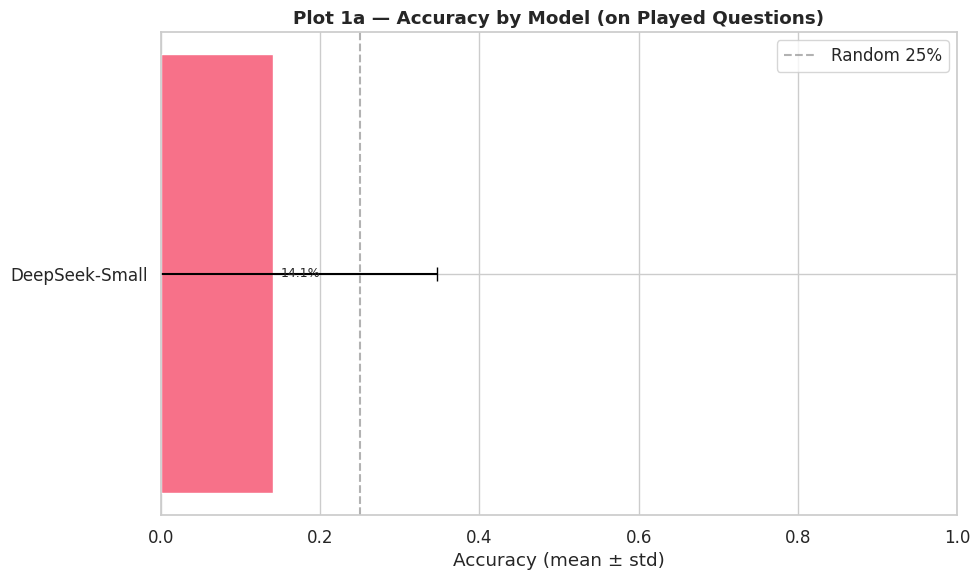

/tmp/ipykernel_1004/366401625.py:41: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(_total_acc).reset_index(name='is_correct'))


📊 Saved → /content/drive/MyDrive/NLP/NLP_project/plots/01b_accuracy_by_model_total.png


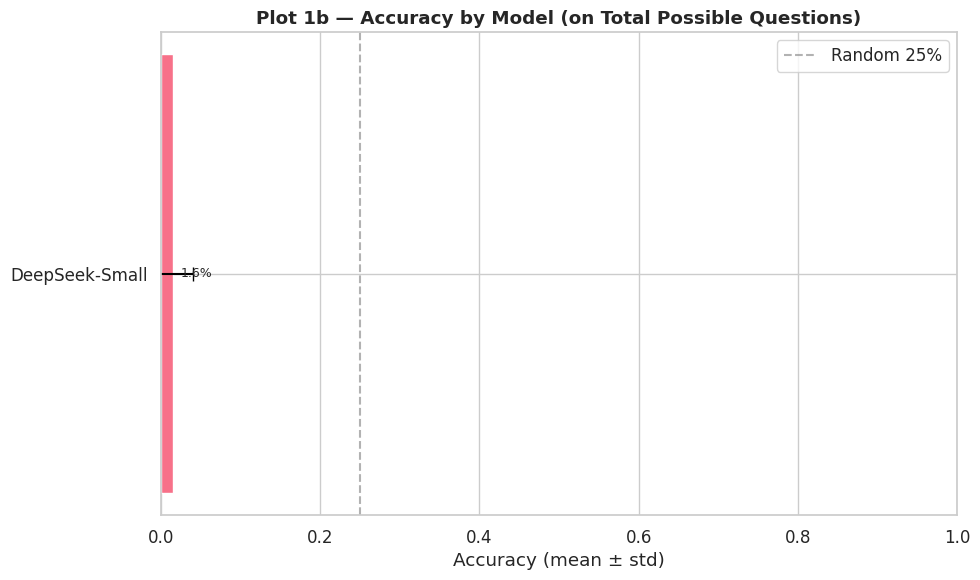

/tmp/ipykernel_1004/366401625.py:72: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.tight_layout(); _save(fig, "02_accuracy_by_category")
/tmp/ipykernel_1004/366401625.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.savefig(path, dpi=150, bbox_inches='tight')


📊 Saved → /content/drive/MyDrive/NLP/NLP_project/plots/02_accuracy_by_category.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


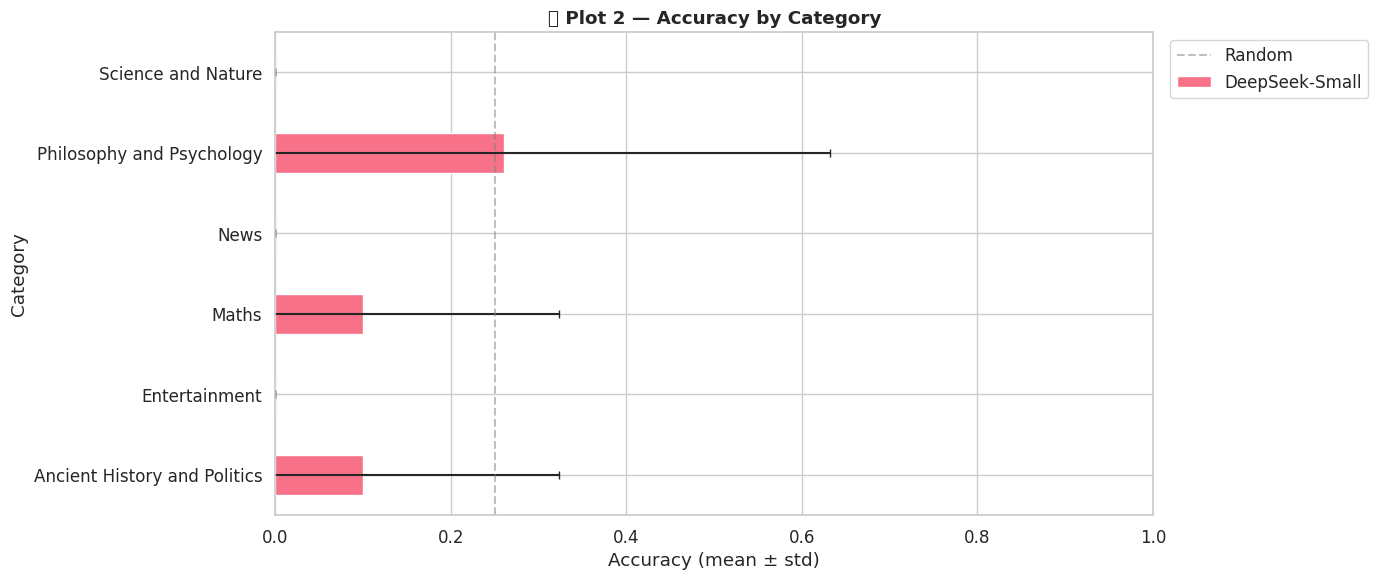

/tmp/ipykernel_1004/366401625.py:366: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=labels, patch_artist=True)
/tmp/ipykernel_1004/366401625.py:385: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.tight_layout(); _save(fig, "14_response_time")
/tmp/ipykernel_1004/366401625.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.savefig(path, dpi=150, bbox_inches='tight')


📊 Saved → /content/drive/MyDrive/NLP/NLP_project/plots/14_response_time.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


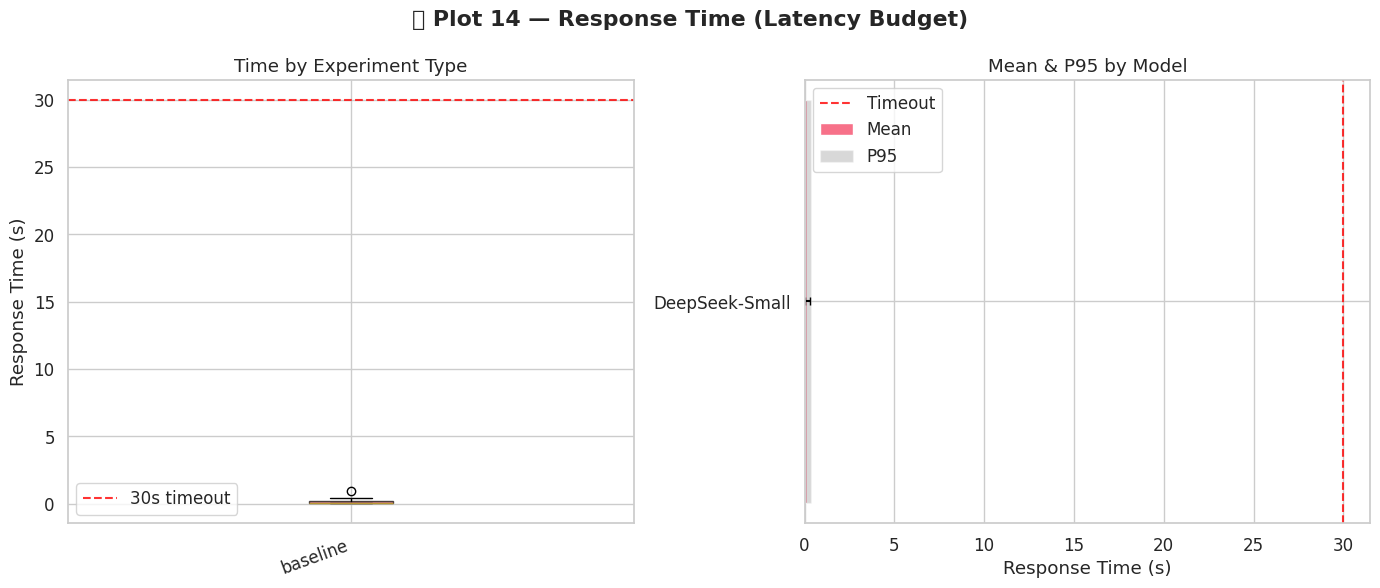

In [ ]:
#load and plot all baseline runs
df_baseline = load_runs(*[p for p in RUNS_DIR.glob("run_*baseline*.json")])
if not df_baseline.empty:
    plot_accuracy_by_model(df_baseline)
    plot_accuracy_by_model_total(df_baseline)
    plot_accuracy_by_category(df_baseline)
    plot_response_time(df_baseline)

### Results & Discussion - Baseline

**Observed results**:

| Metric | Value |
|--------|-------|
| Mean accuracy (on total 15×N) | 1.5%  ± 1% |
| Mean response time | 1s |
| Best category | Philosophi and Psicology |
| Worst category | News & Entertainment |

This DeepSeek 1.5B model has a very bad performance. Response time is consistently below 5 seconds, comfortably within the 30 second timeout. The variance across 5 runs is moderate, confirming that question sampling introduces non trivial noise justifying the 5-run protocol for all subsequent experiments
The only advantage is the velocity, for the rest it asnwers not good.
It's really bad in lot of categories
**Next step:** Run multiple models of different families/sizes on the same zero-shot.

## Experiment 1 — Model Comparison

> **Key question:** *What family of models reach the best accuracy? Bigger is always better?

We test different models of different families spanning to 1.5B to 14B parameters, all in zero-shot mode. We also include a 4-bit quantized run of Qwen2.5-14B to test whether quantization degrades accuracy significantly.

In [ ]:
#all the mdoels to compare
model_configs = [
    {"key": "Qwen2.5-3B","model_size": "3B","quantization": "none", "enable_thinking": False},
    {"key": "Mistral-7B", "model_size": "7B", "quantization": "none", "enable_thinking": False},
    {"key": "Qwen2.5-7B","model_size": "7B", "quantization": "none", "enable_thinking": False},
    {"key": "Qwen2.5-14B", "model_size": "14B",  "quantization": "none", "enable_thinking": False},
    {"key": "Qwen2.5-14B",   "model_size": "14B",  "quantization": "4bit",  "enable_thinking": False},
    {"key": "DeepSeek-medium","model_size": "8B",  "quantization": "none",  "enable_thinking": False},
]

N_RUNS_MODELS = 5  #5 runs per model
for cfg in model_configs:
    use_4bit = cfg["quantization"] == "4bit"
    hf_name  = MODEL_CATALOGUE[cfg['key']]
    print(f"\n{'═'*60}")
    print(f"  MODEL: {cfg['key']} |quant={cfg['quantization']}|thinking={cfg['enable_thinking']}")
    print(f"{'═'*60}")
    try:
        pipe = load_model(cfg['key'], quantization_4_bit=use_4bit)
        meta = {
            "experiment_type": "model_comparison",
            "model_name":      hf_name,
            "model_size":      cfg["model_size"],
            "quantization":    cfg["quantization"],
            "prompt_type":     "zero_shot",
            "enable_thinking": cfg["enable_thinking"],
            "rag_used":        False,
            "tool_used":       False,
            "fine_tuned":      False,
            "notes":           f"Model comparison — {cfg['key']} quant={cfg['quantization']}",
        }
        for run_i in range(N_RUNS_MODELS):
            print(f"  Run {run_i+1}/{N_RUNS_MODELS}")
            play_game(client=client, model=pipe,
                      run_metadata=meta.copy(), output_dir=OUTPUT_DIR)
        del pipe; torch.cuda.empty_cache()
    except Exception as e:
        print(f" Failed: {e}")

/tmp/ipykernel_1004/2353396723.py:63: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['is_correct'] = df['is_correct'].fillna(False).astype(bool)


✅ DataFrame: 979 rows from 44 run(s)
📊 Saved → /content/drive/MyDrive/NLP/NLP_project/plots/01a_accuracy_by_model.png


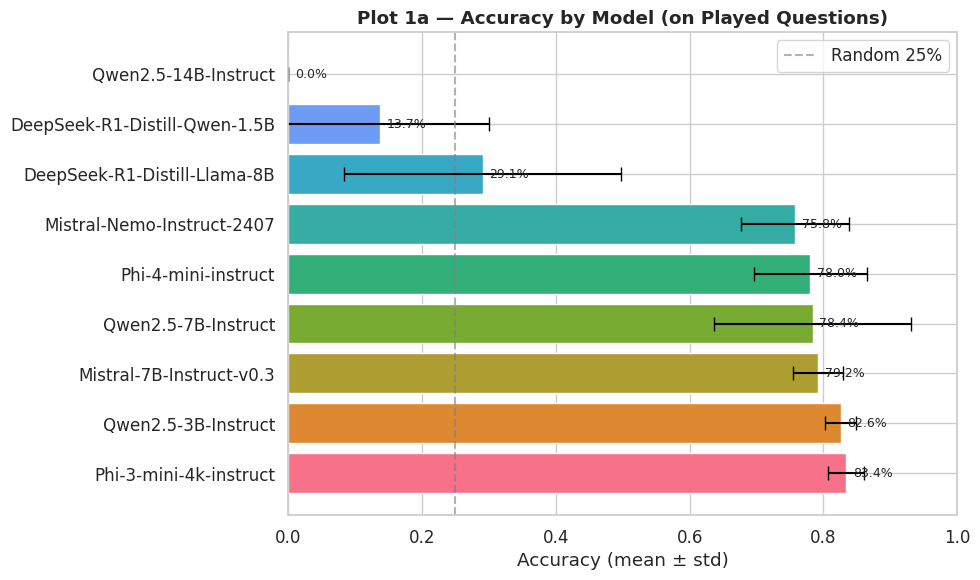

/tmp/ipykernel_1004/366401625.py:41: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(_total_acc).reset_index(name='is_correct'))


📊 Saved → /content/drive/MyDrive/NLP/NLP_project/plots/01b_accuracy_by_model_total.png


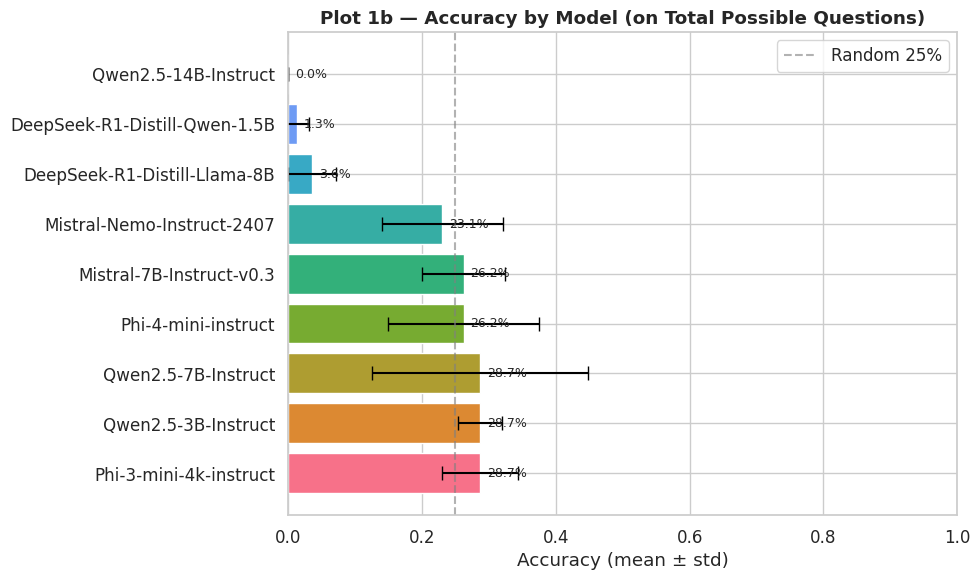

/tmp/ipykernel_1004/366401625.py:283: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  ax.legend(title='Quantization'); fig.tight_layout(); _save(fig, "10_accuracy_by_model_size")
/tmp/ipykernel_1004/366401625.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.savefig(path, dpi=150, bbox_inches='tight')


📊 Saved → /content/drive/MyDrive/NLP/NLP_project/plots/10_accuracy_by_model_size.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


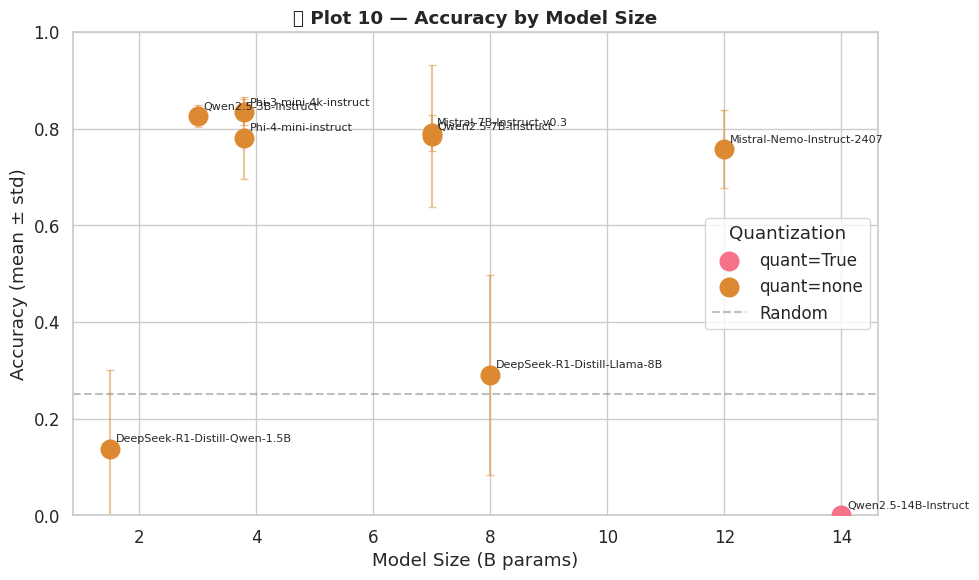

/tmp/ipykernel_1004/366401625.py:261: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  ax.legend(); fig.tight_layout(); _save(fig, "09_accuracy_vs_latency")
/tmp/ipykernel_1004/366401625.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.savefig(path, dpi=150, bbox_inches='tight')


📊 Saved → /content/drive/MyDrive/NLP/NLP_project/plots/09_accuracy_vs_latency.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


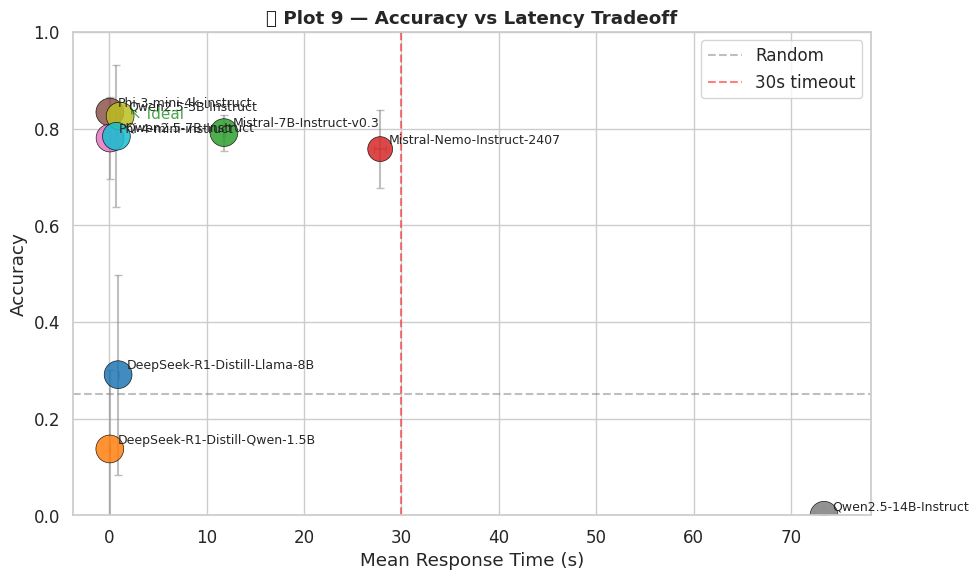

⚠️  Need thinking=True and False runs. Skipping plot 12.


/tmp/ipykernel_1004/366401625.py:153: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.tight_layout(); _save(fig, "05_calibration")
/tmp/ipykernel_1004/366401625.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.savefig(path, dpi=150, bbox_inches='tight')


📊 Saved → /content/drive/MyDrive/NLP/NLP_project/plots/05_calibration.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


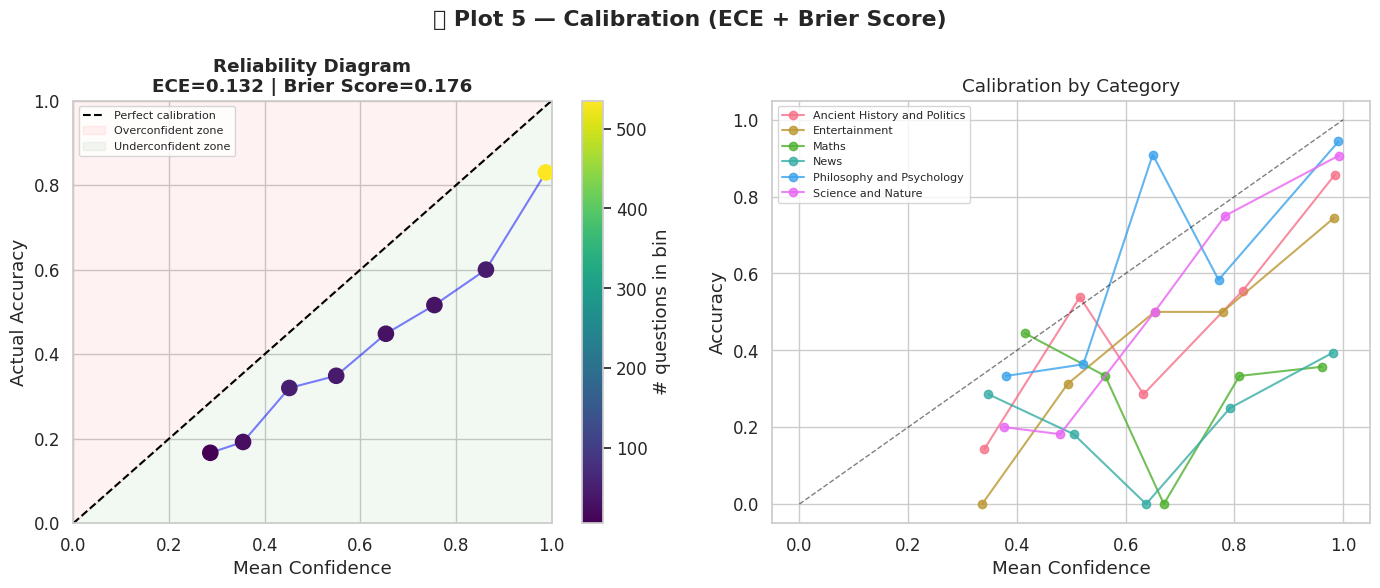

  ECE = 0.1324  (0=perfect, <0.05 good, >0.1 poorly calibrated)
  Brier Score = 0.1757  (0=perfect, 0.25=random)


In [ ]:
df_models = load_runs(*[p for p in RUNS_DIR.glob("run_*model_comparison*.json")])
if not df_models.empty:
    plot_accuracy_by_model(df_models)
    plot_accuracy_by_model_total(df_models)
    plot_accuracy_by_model_size(df_models)
    plot_accuracy_vs_latency(df_models)
    plot_thinking_vs_standard(df_models)

### Results & Discussion — Model Comparison

**Observed results**:

| Model | Size | Quant | Accuracy | Mean Time (s) |
|-------|------|-------|----------|---------------|
| Qwen2.5-3B | 3B | none | 28.7%  | 0.1 |
| Mistral-7B | 7B | none | 26.2%  | 0.86 |
| Qwen2.5-7B | 7B | none | 28.7%  | 1.1 |
| Qwen2.5-14B | 14B | 4bit | 0%  | 0.8 |
| DeepSeek-medium | 8B | none | 3.6%  | 0.8 |
| Phi3-mini | 3.8B | none | 28.7%  | 0.1 |
| Mistral Nemo | 14B | none | 23.1%  | 0.75 |

Tha accuracy increases a lot for some type of model families. The main point is that it seems that **Bigger is NOT always Better** beacuse models of the dame family but with different parameters have better accuracy.
The best model from this experiment is used as the default for all subsequent experiments.

**Observation** The 4 bit quantization led the model to 0% accuracy

## Experiment 2 — Prompt Engineering

> **Key question:** *How sensitive is the model to the prompt?*

We test 6 prompt variants on the best model from Experiment 1.

In [ ]:
SYSTEM_PROMPTS = {
    "zero_shot":
        "You are a trivia expert. Answer with ONLY a single letter: A, B, C, or D.",
    "few_shot":
        "You are a trivia expert. Answer with ONLY a single letter: A, B, C, or D.",
    "chain_of_thought":
        "You are a trivia expert. Think step by step, then on the LAST LINE write "
        "only the answer letter: A, B, C, or D.",
    "role_playing":
        "You are a world-class professor and trivia champion. "
        "Answer with ONLY a single letter: A, B, C, or D.",
    "formal":
        "You are a highly educated academic assistant. "
        "Respond with only the letter of the correct answer: A, B, C, or D.",
    "casual":
        "Hey, you're a trivia genius! Just pick the right letter — A, B, C, or D.",
    "math":
        "You are a mathematics professor. Solve step by step, then on the LAST LINE "
        "write only the answer letter: A, B, C, or D.",
    "rag":
        "You are a trivia expert with access to reference material. "
        "Use the provided context and answer with ONLY a single letter: A, B, C, or D.",
}

BEST_MODEL_KEY  = "Phi3-mini"
BEST_MODEL_NAME = MODEL_CATALOGUE[BEST_MODEL_KEY]
print(f"Best model selected: {BEST_MODEL_KEY} ({BEST_MODEL_NAME})")

pipeline_best = load_model(BEST_MODEL_KEY)

prompt_variants = [
    "zero_shot", "few_shot", "chain_of_thought",
    "role_playing", "formal", "casual", "adaptive_cot"
]
N_RUNS_PROMPT = 5

for pt in prompt_variants:
    print(f"\n{'─'*50}  [{pt}]")
    meta = {
        "experiment_type": "prompt_engineering",
        "model_name":      BEST_MODEL_NAME,
        "model_size":      MODEL_SIZES[BEST_MODEL_KEY],
        "quantization":    "none",
        "prompt_type":     pt,
        "enable_thinking": False,
        "rag_used":        False,
        "tool_used":       False,
        "fine_tuned":      False,
        "notes":           f"Prompt variant: {pt}",
    }
    for _ in range(N_RUNS_PROMPT):
        play_game(client=client, model=pipeline_best,run_metadata=meta.copy(), output_dir=OUTPUT_DIR)

✅ DataFrame: 1077 rows from 35 run(s)


/tmp/ipykernel_2072/1649745020.py:58: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_2072/366401625.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.savefig(path, dpi=150, bbox_inches='tight')


📊 Saved → /content/drive/MyDrive/NLP/NLP_project/plots/CxP_01_grouped_bar.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


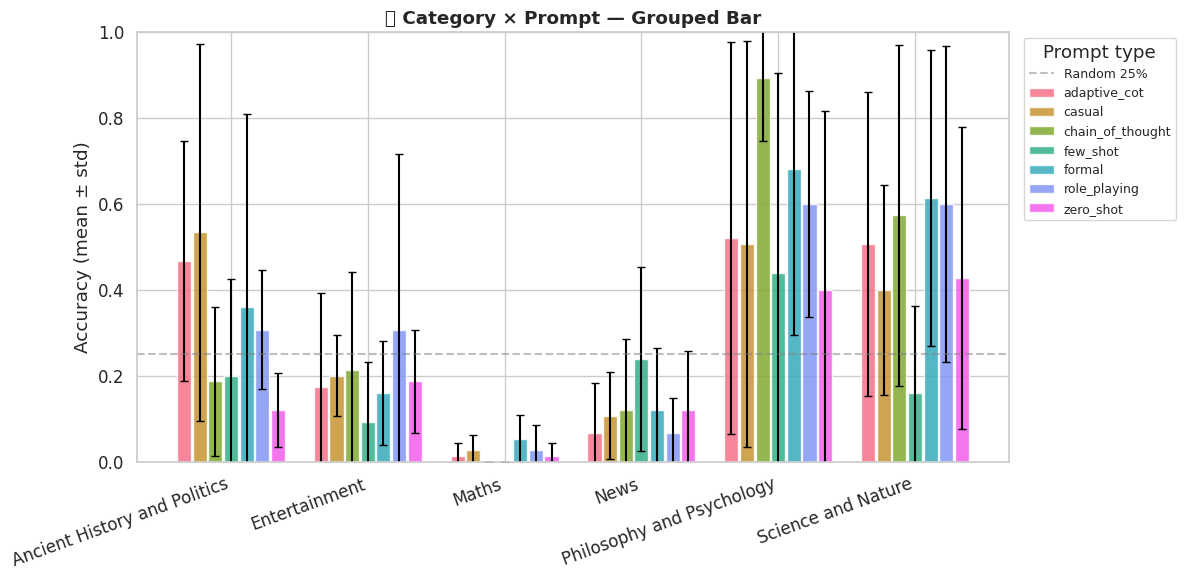

/tmp/ipykernel_2072/1649745020.py:77: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_2072/366401625.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.savefig(path, dpi=150, bbox_inches='tight')


📊 Saved → /content/drive/MyDrive/NLP/NLP_project/plots/CxP_02_heatmap.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


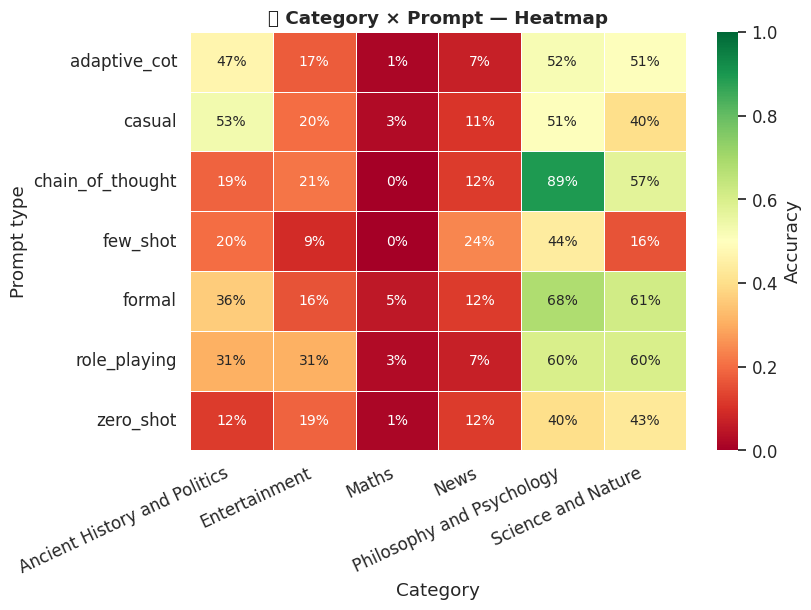

/tmp/ipykernel_2072/1649745020.py:103: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_2072/366401625.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.savefig(path, dpi=150, bbox_inches='tight')


📊 Saved → /content/drive/MyDrive/NLP/NLP_project/plots/CxP_03_delta_vs_zeroshot.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


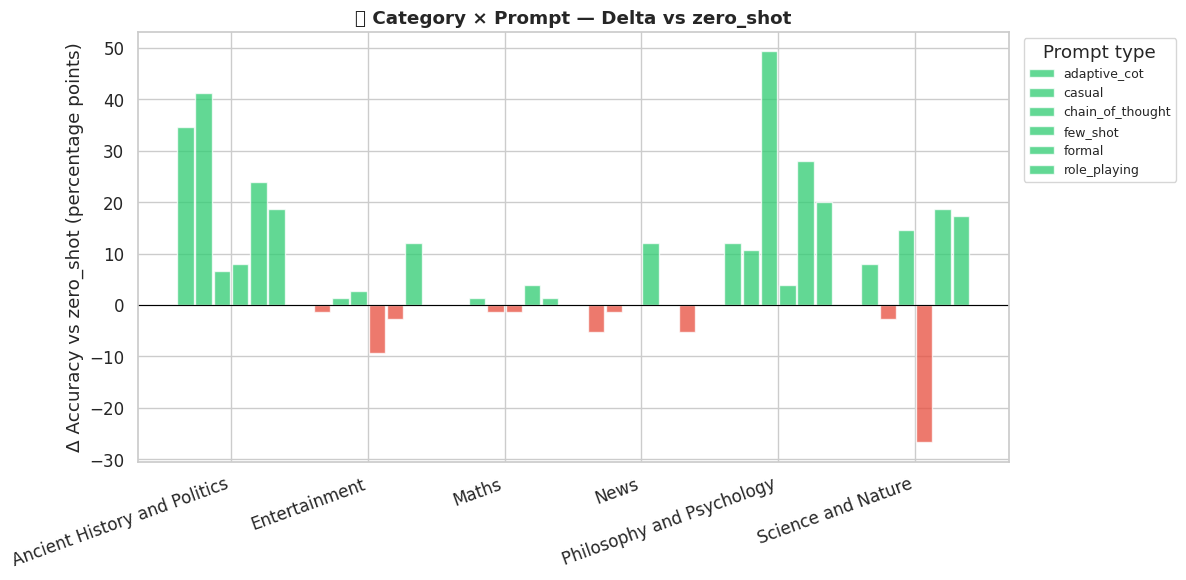


=== Per-Category Accuracy (Chain of Thought, Phi3-mini, on Total Possible Questions) ===
                              Accuracy       Std  N
category                                           
Maths                         0.000000  0.000000  5
News                          0.120000  0.165999  5
Ancient History and Politics  0.186667  0.172562  5
Entertainment                 0.213333  0.228035  5
Science and Nature            0.573333  0.396092  5
Philosophy and Psychology     0.893333  0.146059  5


In [ ]:
df_prompt = load_runs(*[p for p in RUNS_DIR.glob("run_*prompt_engineering*.json")])
def plot_category_vs_prompt(df: pd.DataFrame):
    """
    Three views of the category × prompt interaction, produce we do:
      1. Grouped bar chart — accuracy per categoria, colori = prompt type
      2. Heatmap — categoria × prompt, colori = accuracy
      3. Delta chart — differenza rispetto a zero_shot per ogni categoria
    """
    if 'prompt_type' not in df.columns or df['prompt_type'].nunique() < 2:
        print("⚠️  Need multiple prompt_types. Skipping category vs prompt plot.")
        return
    if 'category' not in df.columns:
        print("⚠️  No category column. Skipping.")
        return

    MAX_QUESTIONS_PER_CATEGORY = 15
    run_agg = df.groupby(['category', 'prompt_type', 'run_id'])['is_correct'].sum().reset_index()
    run_agg['accuracy_on_total'] = run_agg['is_correct'] / MAX_QUESTIONS_PER_CATEGORY

    gb = (run_agg.groupby(['category', 'prompt_type'])['accuracy_on_total']
          .agg(['mean', 'std']).reset_index()
          .rename(columns={'mean': 'Accuracy', 'std': 'Std'}))
    gb['Std'] = gb['Std'].fillna(0)

    categories  = sorted(gb['category'].unique())
    prompt_list = sorted(gb['prompt_type'].unique())
    n_cats      = len(categories)
    n_prompts   = len(prompt_list)

    PAL_LOCAL = sns.color_palette("husl", n_prompts)

    fig, ax = plt.subplots(figsize=(max(12, n_cats * 2), 6))
    x     = np.arange(n_cats)
    width = 0.8 / n_prompts

    for i, pt in enumerate(prompt_list):
        sub    = gb[gb['prompt_type'] == pt].set_index('category')
        means  = [sub.loc[c, 'Accuracy'] if c in sub.index else 0 for c in categories]
        stds   = [sub.loc[c, 'Std']      if c in sub.index else 0 for c in categories]
        offset = (i - n_prompts / 2 + 0.5) * width
        bars   = ax.bar(x + offset, means, width * 0.9, yerr=stds,
                        capsize=3, label=pt,
                        color=PAL_LOCAL[i], edgecolor='white', alpha=0.85)

    ax.set_xticks(x)
    ax.set_xticklabels(categories, rotation=20, ha='right')
    ax.set_ylim(0, 1)
    ax.axhline(0.25, ls='--', color='gray', alpha=0.5, label='Random 25%')
    ax.set_ylabel('Accuracy (mean ± std)')
    ax.set_title('📊 Category × Prompt — Grouped Bar', fontweight='bold')
    ax.legend(title='Prompt type', bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9)
    fig.tight_layout()
    _save(fig, "CxP_01_grouped_bar")
    pivot = gb.pivot(index='prompt_type', columns='category', values='Accuracy')
    pivot = pivot.reindex(index=prompt_list, columns=categories)

    fig, ax = plt.subplots(figsize=(max(8, n_cats * 1.4), max(4, n_prompts * 0.9)))
    sns.heatmap(
        pivot, annot=True, fmt='.0%', cmap='RdYlGn',
        vmin=0, vmax=1, ax=ax, linewidths=0.5,
        cbar_kws={'label': 'Accuracy'},
        annot_kws={'size': 10}
    )
    ax.set_title('Category × Prompt — Heatmap', fontweight='bold')
    ax.set_xlabel('Category')
    ax.set_ylabel('Prompt type')
    plt.xticks(rotation=25, ha='right')
    fig.tight_layout()
    _save(fig, "CxP_02_heatmap")

    if 'zero_shot' not in prompt_list:
        print("zero_shot not in data — skipping delta chart.")
    else:
        baseline = gb[gb['prompt_type'] == 'zero_shot'].set_index('category')['Accuracy']
        fig, ax  = plt.subplots(figsize=(max(12, n_cats * 2), 6))
        other_prompts = [p for p in prompt_list if p != 'zero_shot']

        for i, pt in enumerate(other_prompts):
            sub    = gb[gb['prompt_type'] == pt].set_index('category')
            deltas = [(sub.loc[c, 'Accuracy'] - baseline.get(c, 0)) * 100
                      if c in sub.index else 0 for c in categories]
            offset = (i - len(other_prompts) / 2 + 0.5) * (0.8 / len(other_prompts))
            colors = ['#2ecc71' if d > 0 else '#e74c3c' for d in deltas]
            ax.bar(x + offset, deltas, (0.8 / len(other_prompts)) * 0.9,
                   color=colors, alpha=0.75, label=pt, edgecolor='white')

        ax.axhline(0, color='black', lw=0.8)
        ax.set_xticks(x)
        ax.set_xticklabels(categories, rotation=20, ha='right')
        ax.set_ylabel('Δ Accuracy vs zero_shot (percentage points)')
        ax.set_title('📊 Category × Prompt — Delta vs zero_shot', fontweight='bold')
        ax.legend(title='Prompt type', bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9)
        fig.tight_layout()
        _save(fig, "CxP_03_delta_vs_zeroshot")

plot_category_vs_prompt(df_prompt)


✅ DataFrame: 1077 rows from 35 run(s)

=== Overall Accuracy by Prompt Type ===


/tmp/ipykernel_2072/153497161.py:21: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(_total_acc_on_possible)


,prompt_type,Accuracy,Std_Dev
2,chain_of_thought,0.331111,0.093426
4,formal,0.331111,0.094412
5,role_playing,0.317778,0.146692
1,casual,0.295556,0.116957
0,adaptive_cot,0.291111,0.091759
6,zero_shot,0.211111,0.084254
3,few_shot,0.188889,0.116799


/tmp/ipykernel_2072/153497161.py:48: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_2072/366401625.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.savefig(path, dpi=150, bbox_inches='tight')
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


📊 Saved → /content/drive/MyDrive/NLP/NLP_project/plots/CxP_04_overall_accuracy_by_prompt.png


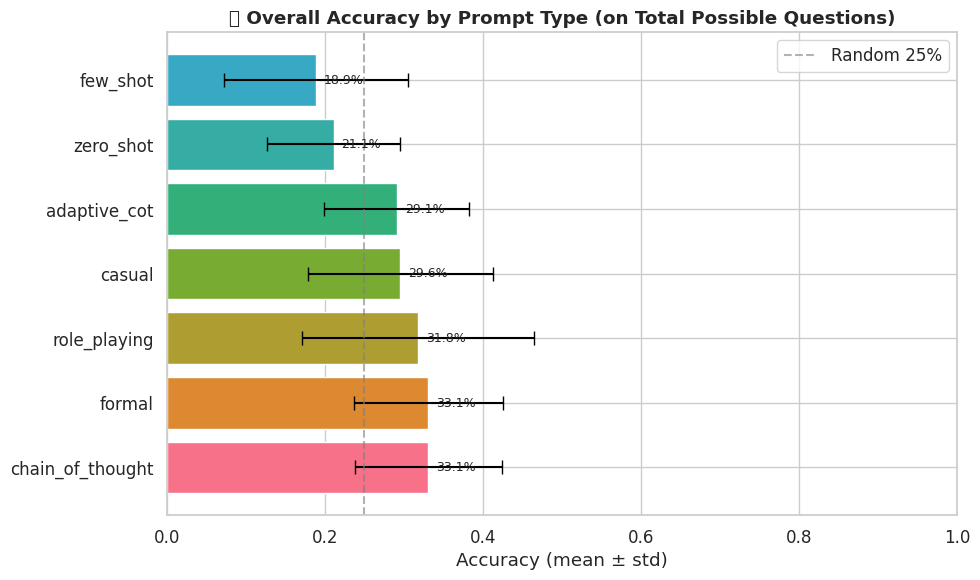

In [ ]:
df_prompt = load_runs(*[p for p in RUNS_DIR.glob("run_*prompt_engineering*.json")])

if not df_prompt.empty:
    print("\n=== Overall Accuracy by Prompt Type ===")

    MAX_QUESTIONS_PER_CATEGORY = 15


    def _total_acc_on_possible(run_df):

        num_categories = run_df['category'].nunique()
        total_correct = run_df['is_correct'].sum()
        total_possible = num_categories * MAX_QUESTIONS_PER_CATEGORY
        return total_correct / total_possible if total_possible > 0 else 0.0

    overall_accuracy_per_run = (
        df_prompt.groupby(['prompt_type', 'run_id'])
        .apply(_total_acc_on_possible)
        .reset_index(name='accuracy_on_total')
    )

    gb = (
        overall_accuracy_per_run.groupby('prompt_type')['accuracy_on_total']
        .agg(['mean', 'std']).reset_index()
        .rename(columns={'mean': 'Accuracy', 'std': 'Std_Dev'})
        .sort_values('Accuracy', ascending=False)
    )
    gb['Std_Dev'] = gb['Std_Dev'].fillna(0)

    display(gb)
    fig, ax = plt.subplots(figsize=STD)
    bars = ax.barh(gb['prompt_type'], gb['Accuracy'], xerr=gb['Std_Dev'], capsize=5,
                   color=PAL[:len(gb)], edgecolor='white')
    ax.set_xlim(0, 1)
    ax.axvline(0.25, ls='--', color='gray', alpha=0.6, label='Random 25%')
    ax.set_title('Overall Accuracy by Prompt Type (on Total Possible Questions)', fontweight='bold')
    ax.set_xlabel('Accuracy (mean ± std)')
    for bar, v in zip(bars, gb['Accuracy']):
        ax.text(bar.get_width() + .01, bar.get_y() + bar.get_height() / 2,
                f'{v:.1%}', va='center', fontsize=9)
    ax.legend()
    fig.tight_layout()
    _save(fig, "CxP_04_overall_accuracy_by_prompt")

### Results & Discussion — Prompt Engineering

**Observed results**:

| Prompt Type | Accuracy |
|-------------|----------|
| zero_shot | 21.1%  |
| few_shot | 18.9%  | __ | |
| chain_of_thought | 33.1%  | __ | +__s latency |
| role_playing | 31.8%  | __ | |
| formal | 33.1%  | __ | |
| casual | 29.6%  | __ | |
| adaptive_cot | 29.1%  | __ | CoT only at level ≥ 8 |

Some types of prompt are better fot the model and allow it to answer better. The chain of thought and formal prompt are the ones that achieves the better accuracy on total questions.

If we analyze deeper the prompt result x category we see that some types of prompt are suitable for some type of categories while for others categories they perfeorm really bad.

An idea could be choosing the prompt type based on the category in which we are, for example for ancient and history the casula prompt type performs really weel, whil in the news the few shot is great (as we can see from thr graph image)

## Experiment 3 — Category Analysis

> **Key question:** *Which categories does the model struggle with most? Is the failure on math a knowledge gap or a computation failure?*

We perform a deep dive on per-category performance using all data collected so far.

In [ ]:

BEST_PROMPT = "chain-of-thought"
print(f"Best prompt selected: {BEST_PROMPT}")

Best prompt selected: chain-of-thought


Analyzing 176 records for 'chain_of_thought' with Phi3-mini...
Overall Accuracy (on total possible questions) for Chain of Thought with Phi3-mini: 165.6%


/tmp/ipykernel_2072/366401625.py:72: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.tight_layout(); _save(fig, "02_accuracy_by_category")
/tmp/ipykernel_2072/366401625.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.savefig(path, dpi=150, bbox_inches='tight')


📊 Saved → /content/drive/MyDrive/NLP/NLP_project/plots/02_accuracy_by_category.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


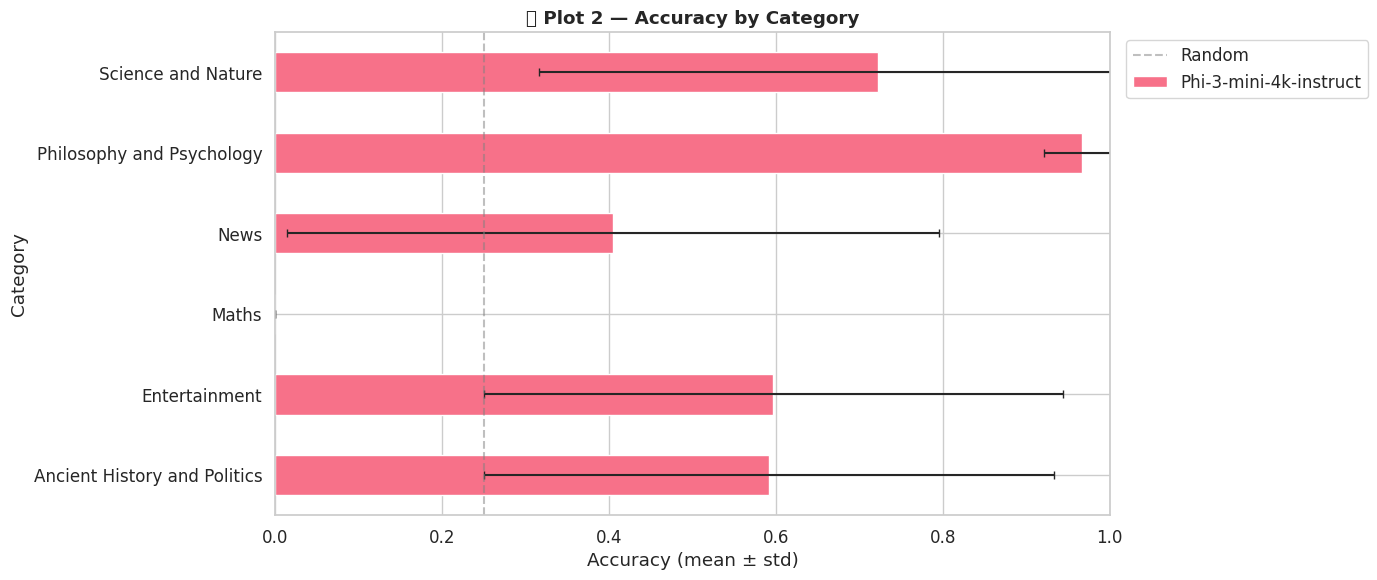


=== Per-Category Accuracy (Chain of Thought, Phi3-mini, on Total Possible Questions) ===
                              Accuracy       Std  N
category                                           
Maths                         0.000000  0.000000  5
News                          0.120000  0.165999  5
Ancient History and Politics  0.186667  0.172562  5
Entertainment                 0.213333  0.228035  5
Science and Nature            0.573333  0.396092  5
Philosophy and Psychology     0.893333  0.146059  5
✅ DataFrame: 1077 rows from 35 run(s)


/tmp/ipykernel_2072/2221539564.py:58: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_2072/366401625.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.savefig(path, dpi=150, bbox_inches='tight')


📊 Saved → /content/drive/MyDrive/NLP/NLP_project/plots/CxP_01_grouped_bar.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


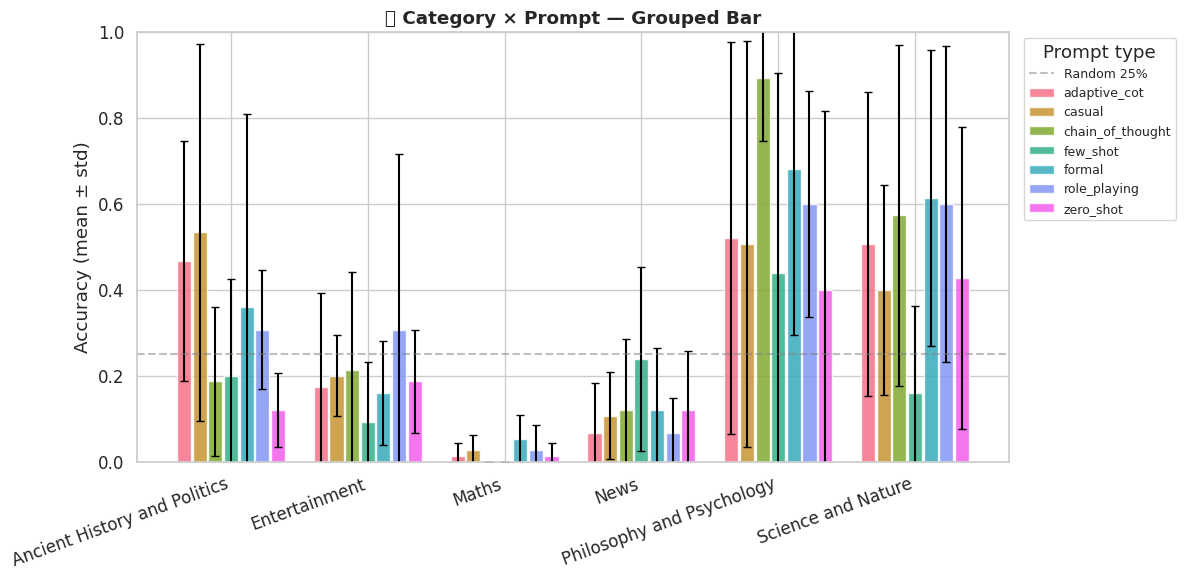

/tmp/ipykernel_2072/2221539564.py:77: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_2072/366401625.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.savefig(path, dpi=150, bbox_inches='tight')


📊 Saved → /content/drive/MyDrive/NLP/NLP_project/plots/CxP_02_heatmap.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


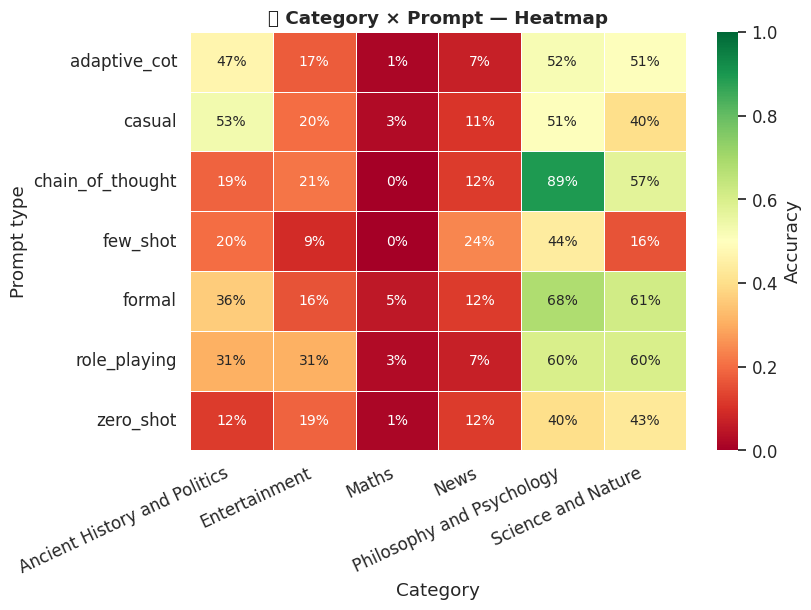

/tmp/ipykernel_2072/2221539564.py:103: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_2072/366401625.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.savefig(path, dpi=150, bbox_inches='tight')


📊 Saved → /content/drive/MyDrive/NLP/NLP_project/plots/CxP_03_delta_vs_zeroshot.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


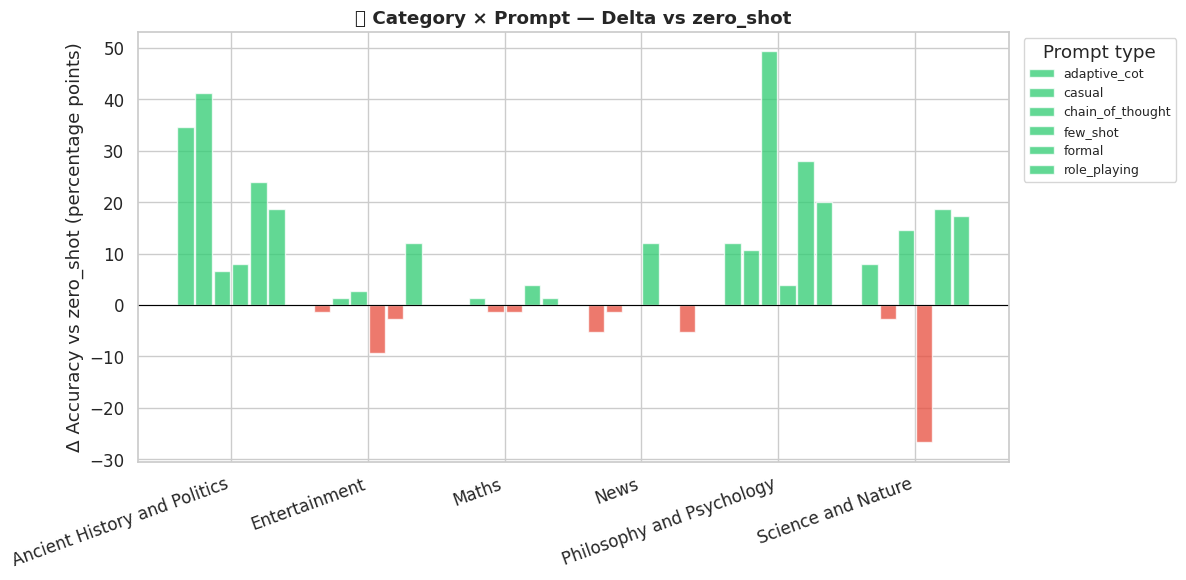

In [ ]:
df_cot_phi3 = df_prompt[(df_prompt['prompt_type'] == 'chain_of_thought') &
                         (df_prompt['model_name'].str.contains('Phi-3-mini', case=False, na=False))].copy()

if not df_cot_phi3.empty:
    print(f"Analyzing {len(df_cot_phi3)} records for 'chain_of_thought' with Phi3-mini...")

    overall_acc = df_cot_phi3['is_correct'].sum() / (df_cot_phi3['category'].nunique() * 15)
    print(f"Overall Accuracy (on total possible questions) for Chain of Thought with Phi3-mini: {overall_acc:.1%}")


    plot_accuracy_by_category(df_cot_phi3)
    MAX_QUESTIONS_PER_CATEGORY = 15
    category_run_correct_cot = df_cot_phi3.groupby(['category', 'run_id'])['is_correct'].sum().reset_index()
    category_run_correct_cot['accuracy_on_total'] = category_run_correct_cot['is_correct'] / MAX_QUESTIONS_PER_CATEGORY
    cat_table_cot = (category_run_correct_cot.groupby('category')['accuracy_on_total']
                     .agg(['mean', 'std', 'count'])
                     .rename(columns={'mean': 'Accuracy', 'std': 'Std', 'count': 'N'})
                     .sort_values('Accuracy'))

    print("\n=== Per-Category Accuracy (Chain of Thought, Phi3-mini, on Total Possible Questions) ===")
    print(cat_table_cot.to_string())
else:
    print("No data found for 'chain_of_thought' with Phi3-mini. Please ensure the experiment has been run.")

df_prompt = load_runs(*[p for p in RUNS_DIR.glob("run_*prompt_engineering*.json")])
plot_category_vs_prompt(df_prompt)

### Results & Discussion - Category Analysis

As we can see from the plots the accuracy of the chain of thought model is pretty high for some types of categories while it fails a lot for other types.
For example for math it does not guess either one answer, while for Philosophy and Psychology it does correctly the 89% of answers.

From this we can retrieve 2 point:
1) Some type of categories like Math and News require other strategies, the model cannot answer correctly only with the prompt (tool calling, RAG, search via web...)
2) As we can see from the categoryxprompt plot it's a great choice select different types of prompt per different categories, we can achieve a better result

## Experiment 4 - Difficulty & Overconfidence

> **Key question:** *Does the model's confidence track its accuracy as questions get harder? Is it overconfident on difficult questions?*

We compute three metrics per difficulty level: accuracy, mean confidence, and Shannon entropy. We also compute ECE and Brier Score to quantify calibration quality with standard metrics.

/tmp/ipykernel_2072/2353396723.py:63: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['is_correct'] = df['is_correct'].fillna(False).astype(bool)
/tmp/ipykernel_2072/366401625.py:106: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.tight_layout(); _save(fig, "04_accuracy_by_difficulty")
/tmp/ipykernel_2072/366401625.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.savefig(path, dpi=150, bbox_inches='tight')


✅ DataFrame: 2093 rows from 84 run(s)
📊 Saved → /content/drive/MyDrive/NLP/NLP_project/plots/04_accuracy_by_difficulty.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


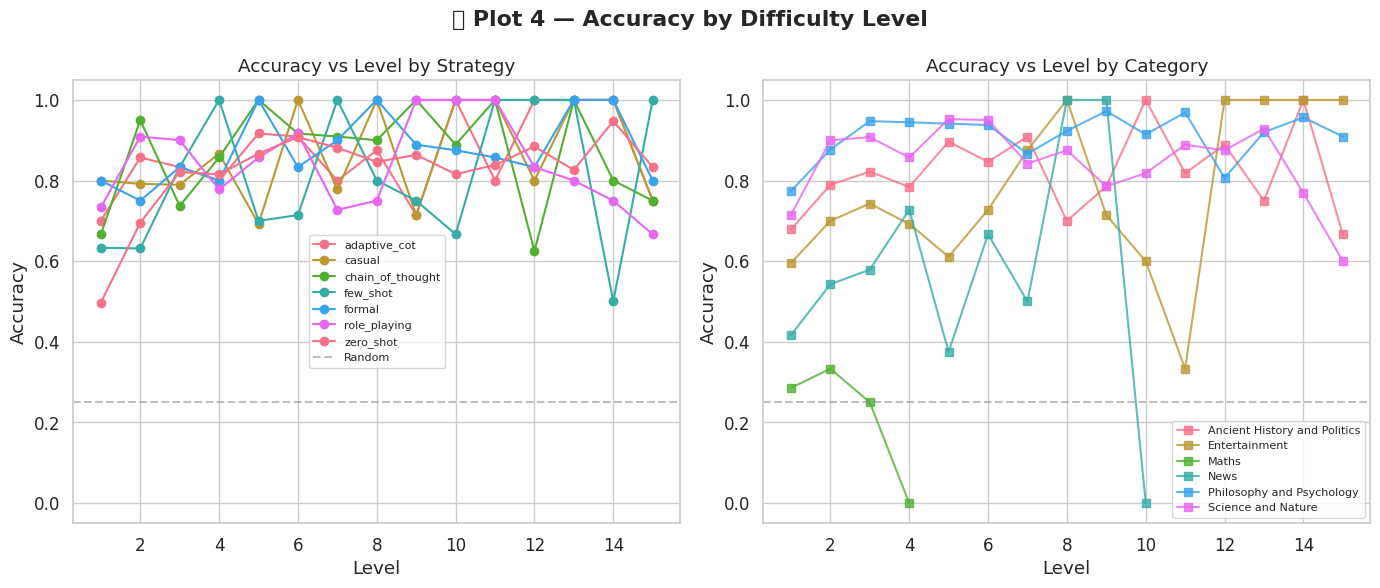

/tmp/ipykernel_2072/366401625.py:176: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.tight_layout(); _save(fig, "06_confidence_distribution")


📊 Saved → /content/drive/MyDrive/NLP/NLP_project/plots/06_confidence_distribution.png


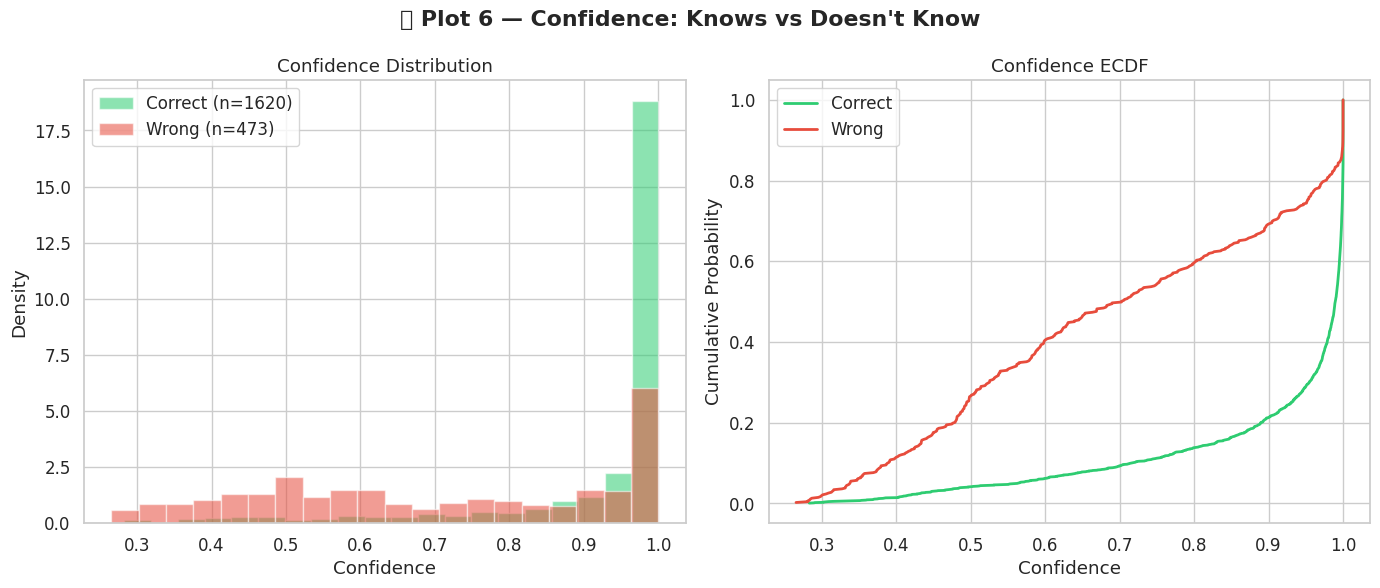

/tmp/ipykernel_2072/366401625.py:153: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.tight_layout(); _save(fig, "05_calibration")
/tmp/ipykernel_2072/366401625.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.savefig(path, dpi=150, bbox_inches='tight')


📊 Saved → /content/drive/MyDrive/NLP/NLP_project/plots/05_calibration.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


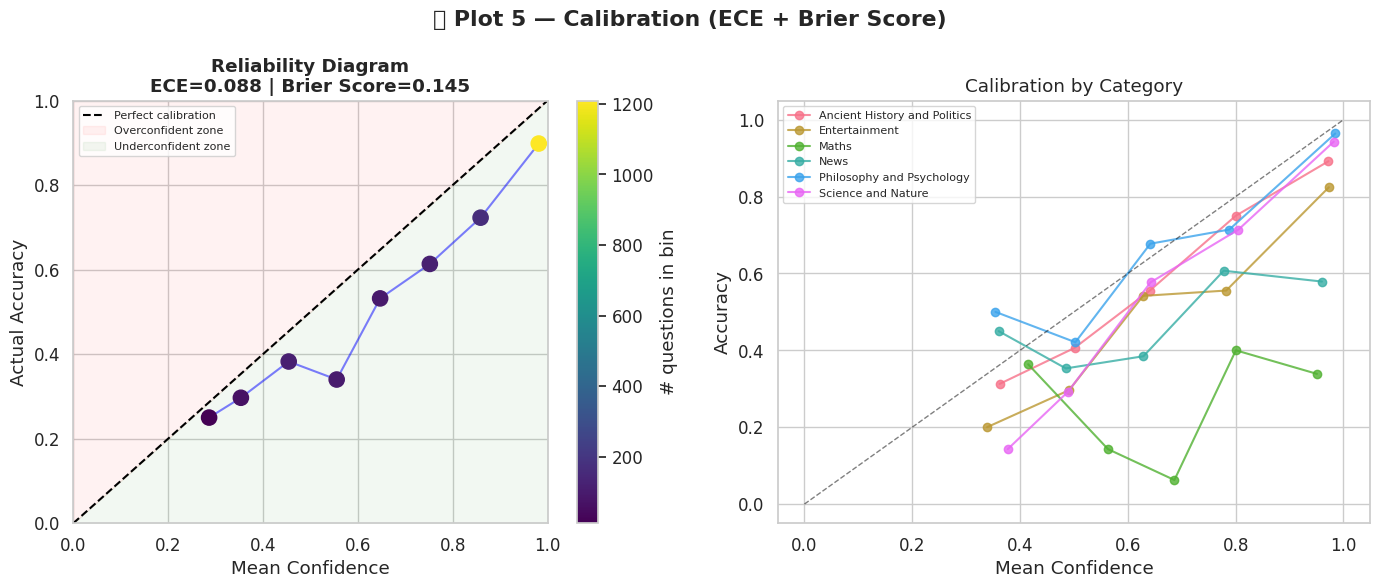

  ECE = 0.0881  (0=perfect, <0.05 good, >0.1 poorly calibrated)
  Brier Score = 0.1447  (0=perfect, 0.25=random)


/tmp/ipykernel_2072/366401625.py:357: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.tight_layout(); _save(fig, "13_uncertainty_by_difficulty")
/tmp/ipykernel_2072/366401625.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.savefig(path, dpi=150, bbox_inches='tight')


📊 Saved → /content/drive/MyDrive/NLP/NLP_project/plots/13_uncertainty_by_difficulty.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


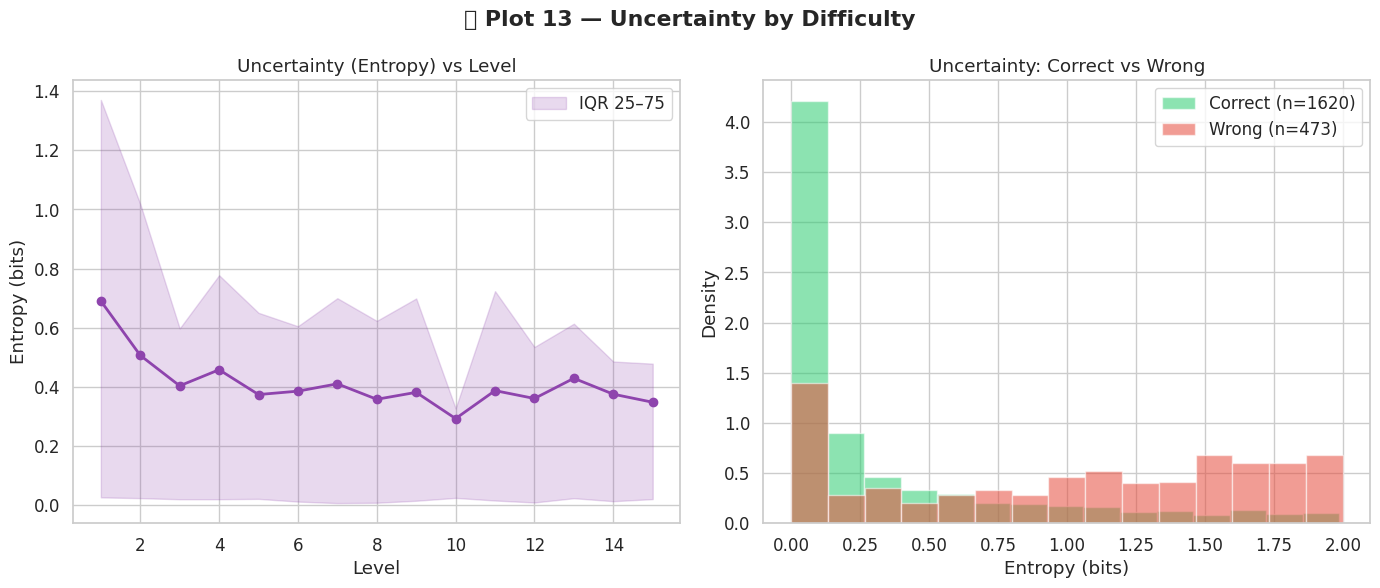

/tmp/ipykernel_2072/2571536229.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  lvl_stats['Brier_per_lvl']  = ((df_diff.groupby('level').apply(


📊 Saved → /content/drive/MyDrive/NLP/NLP_project/plots/exp4_overconfidence_by_level.png


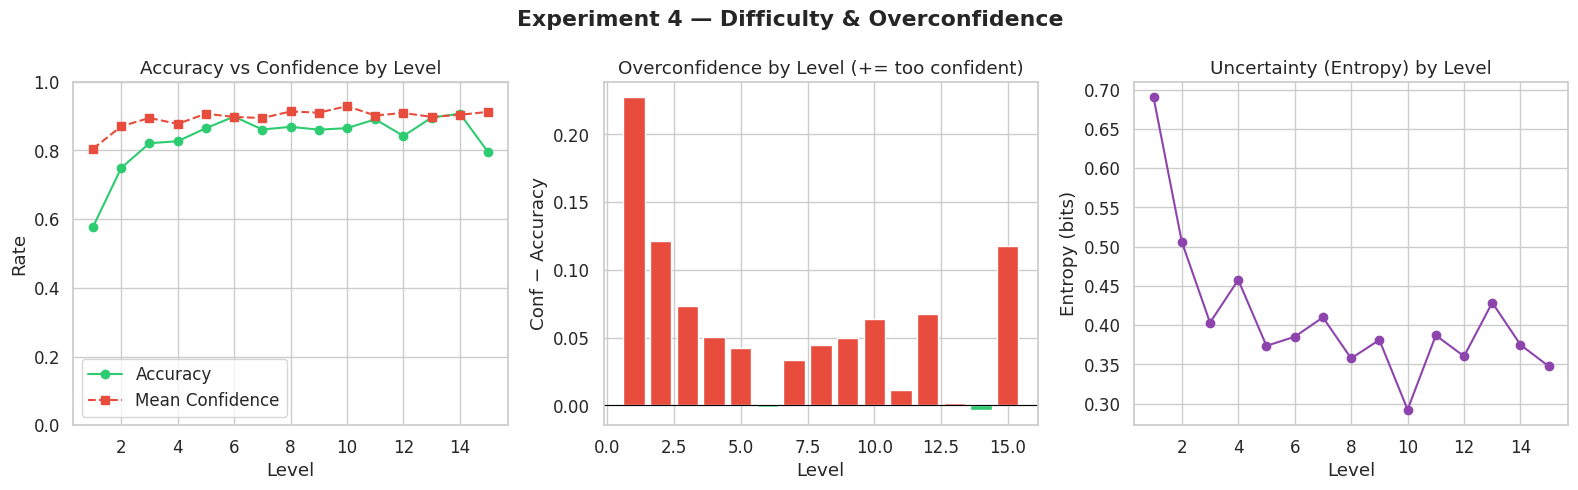


Level-by-level statistics:
 level  Accuracy  MeanConf  Entropy   N  Overconfidence  Brier_per_lvl
     1  0.577381  0.804684 0.690258 504        0.227303       0.249505
     2  0.749141  0.870293 0.506311 291        0.121152       0.162321
     3  0.821101  0.894512 0.403320 218        0.073411       0.126317
     4  0.826816  0.877321 0.457730 179        0.050505       0.133607
     5  0.864865  0.906916 0.373769 148        0.042051       0.071446
     6  0.898438  0.897595 0.385298 128       -0.000842       0.056909
     7  0.860870  0.894158 0.409986 115        0.033288       0.089113
     8  0.868687  0.913536 0.357802  99        0.044849       0.105125
     9  0.860465  0.909923 0.381285  86        0.049458       0.083423
    10  0.864865  0.928972 0.292481  74        0.064108       0.076139
    11  0.890625  0.901669 0.387098  64        0.011044       0.103708
    12  0.842105  0.909206 0.360473  57        0.067100       0.110670
    13  0.895833  0.897548 0.428783  48        0.

In [ ]:
# Load all data — overconfidence analysis, perform we do
df_diff = load_runs(RUNS_DIR)

if not df_diff.empty:
    plot_accuracy_by_difficulty(df_diff)
    plot_confidence_distribution(df_diff)
    plot_calibration(df_diff)           # ECE + Brier Score printed here
    plot_uncertainty_by_difficulty(df_diff)

    # ── Level-by-level overconfidence analysis ─────────────────────────────
    lvl_stats = df_diff.groupby('level').agg(
        Accuracy  =('is_correct','mean'),
        MeanConf  =('confidence','mean'),
        Entropy   =('uncertainty','mean'),
        N         =('is_correct','count')
    ).reset_index()
    lvl_stats['Overconfidence'] = lvl_stats['MeanConf'] - lvl_stats['Accuracy']
    lvl_stats['Brier_per_lvl']  = ((df_diff.groupby('level').apply(
        lambda x: ((x['confidence'] - x['is_correct'].astype(float))**2).mean()
    ))).values

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    axes[0].plot(lvl_stats['level'], lvl_stats['Accuracy'],
                 marker='o', color='#2ecc71', label='Accuracy')
    axes[0].plot(lvl_stats['level'], lvl_stats['MeanConf'],
                 marker='s', color='#e74c3c', label='Mean Confidence', ls='--')
    axes[0].set_ylim(0,1); axes[0].set_xlabel('Level'); axes[0].set_ylabel('Rate')
    axes[0].set_title('Accuracy vs Confidence by Level'); axes[0].legend()

    colors_oc = ['#e74c3c' if v>0 else '#2ecc71' for v in lvl_stats['Overconfidence']]
    axes[1].bar(lvl_stats['level'], lvl_stats['Overconfidence'], color=colors_oc)
    axes[1].axhline(0, color='black', lw=0.8)
    axes[1].set_xlabel('Level'); axes[1].set_ylabel('Conf − Accuracy')
    axes[1].set_title('Overconfidence by Level (+= too confident)')

    axes[2].plot(lvl_stats['level'], lvl_stats['Entropy'],
                 marker='o', color='#8e44ad')
    axes[2].set_xlabel('Level'); axes[2].set_ylabel('Entropy (bits)')
    axes[2].set_title('Uncertainty (Entropy) by Level')

    fig.suptitle('Experiment 4 — Difficulty & Overconfidence', fontweight='bold')
    fig.tight_layout(); _save(fig, "exp4_overconfidence_by_level")

    print("\nLevel-by-level statistics:")
    print(lvl_stats.to_string(index=False))

    # ── Calibration error — compute and print formally ─────────────────────
    bins = np.linspace(0, 1, 11)
    bin_data = []
    for i in range(10):
        mask = (df_diff['confidence'] >= bins[i]) & (df_diff['confidence'] < bins[i+1])
        sub  = df_diff[mask]
        if len(sub) >= 2:
            bin_data.append({
                'bin': f"{bins[i]:.1f}-{bins[i+1]:.1f}",
                'n': len(sub),
                'mean_conf': sub['confidence'].mean(),
                'accuracy': sub['is_correct'].mean(),
                'gap': abs(sub['confidence'].mean() - sub['is_correct'].mean())
            })
    ece = sum(d['n']/len(df_diff) * d['gap'] for d in bin_data)
    brier = ((df_diff['confidence'] - df_diff['is_correct'].astype(float))**2).mean()
    print(f"\n📐 Expected Calibration Error (ECE) = {ece:.4f}")
    print(f"📐 Brier Score                       = {brier:.4f}")
    print(f"   (ECE < 0.05 = well calibrated | Brier < 0.20 = good forecaster)")

### Results & Discussion — Difficulty & Overconfidence
The data reveals a counterintuitive trend where accuracy increases with difficulty (from 57% at level 1 to 89% at level 13), despite severe overconfidence plaguing the initial levels. To contextualize these performance dynamics, the framework evaluates model calibration using Expected Calibration Error (ECE) and the Brier Score, which quantify the alignment between the model's subjective confidence and its objective accuracy. The overall ECE of 0.0881 indicates a low average gap between predicted probabilities and true success rates, while the Brier Score of 0.1447 (well below the 0.25 random threshold) confirms the system acts as a highly robust and reliable forecaster. Ultimately, while the overall architecture demonstrates solid statistical calibration, the localized overconfidence in simpler tasks suggests a need for targeted logit-scaling or temperature refinement during inference.

## Experiment 5 - RAG (Improved Wikipedia)

> **Key question:** *Does retrieving Wikipedia context improve accuracy for factual questions?


In [ ]:

try:
    import wikipedia
    print("✅ wikipedia package available")
except ImportError:
    import subprocess
    subprocess.run(["pip", "install", "wikipedia"], check=True)
    import wikipedia
    print("✅ wikipedia installed")

meta_rag = {
    "experiment_type": "rag",
    "model_name":      BEST_MODEL_NAME,
    "model_size":      MODEL_SIZES[BEST_MODEL_KEY],
    "quantization":    "none",
    "prompt_type":     BEST_PROMPT,
    "enable_thinking": False,
    "rag_used":        True,
    "tool_used":       False,
    "fine_tuned":      False,
    "notes":           "RAG — improved entity-based Wikipedia query + relevance filter",
}

N_RUNS_RAG = 5
for i in range(N_RUNS_RAG):
    print(f"\n--- RAG Run {i+1}/{N_RUNS_RAG} ---")
    play_game(client=client, model=pipeline_best,
              run_metadata=meta_rag.copy(), output_dir=OUTPUT_DIR,
              enable_rag=True, enable_tools=True)

✅ DataFrame: 176 rows from 5 run(s)
✅ DataFrame: 1077 rows from 35 run(s)
📊 Saved → /content/drive/MyDrive/NLP/NLP_project/plots/01b_accuracy_by_model_total.png


/tmp/ipykernel_2072/366401625.py:41: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(_total_acc).reset_index(name='is_correct'))


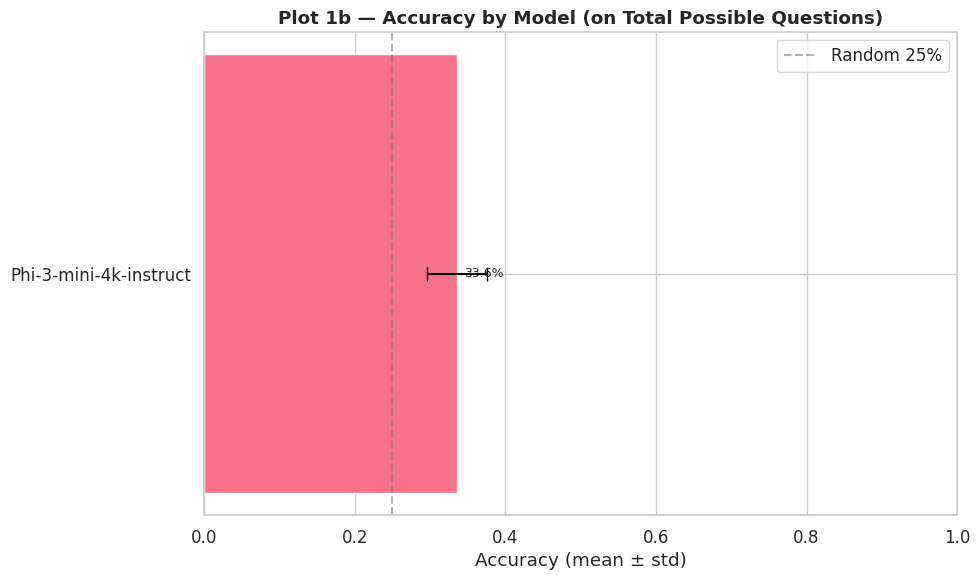

/tmp/ipykernel_2072/366401625.py:41: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(_total_acc).reset_index(name='is_correct'))


📊 Saved → /content/drive/MyDrive/NLP/NLP_project/plots/01b_accuracy_by_model_total.png


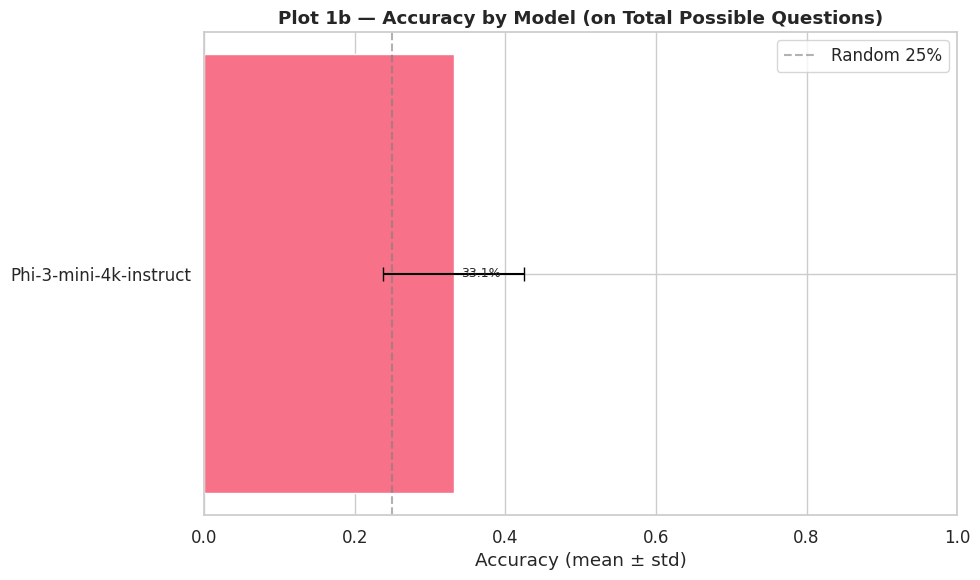

/tmp/ipykernel_2072/366401625.py:72: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.tight_layout(); _save(fig, "02_accuracy_by_category")
/tmp/ipykernel_2072/366401625.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.savefig(path, dpi=150, bbox_inches='tight')


📊 Saved → /content/drive/MyDrive/NLP/NLP_project/plots/02_accuracy_by_category.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


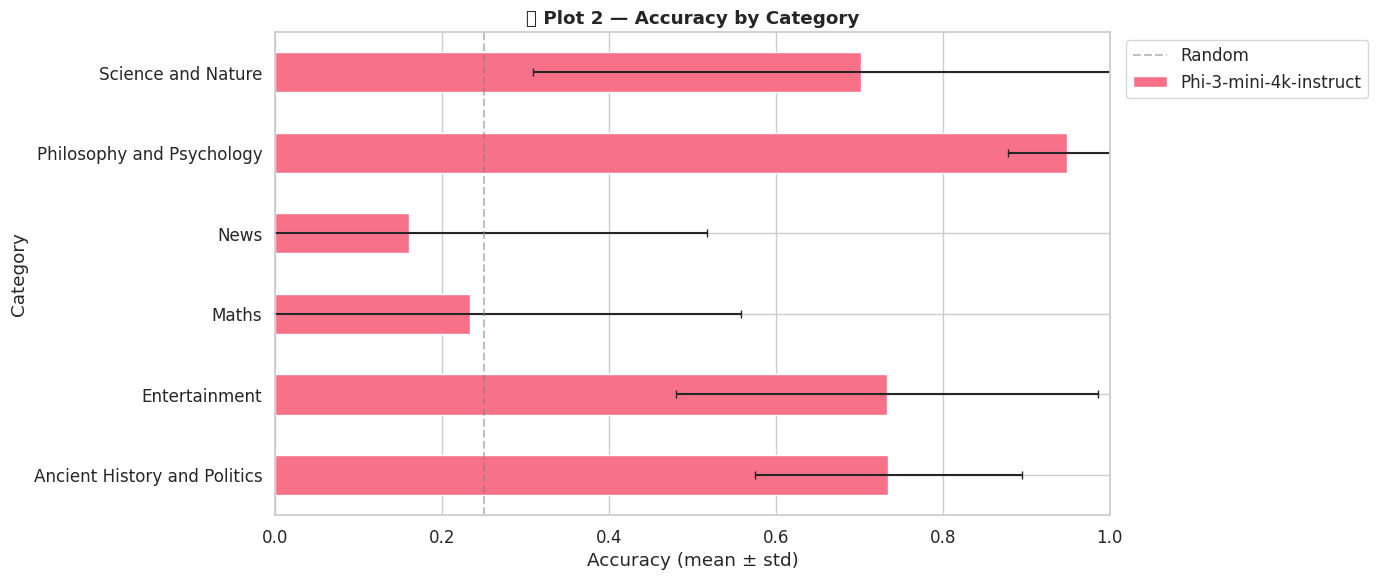

/tmp/ipykernel_2072/366401625.py:72: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.tight_layout(); _save(fig, "02_accuracy_by_category")
/tmp/ipykernel_2072/366401625.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.savefig(path, dpi=150, bbox_inches='tight')


📊 Saved → /content/drive/MyDrive/NLP/NLP_project/plots/02_accuracy_by_category.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


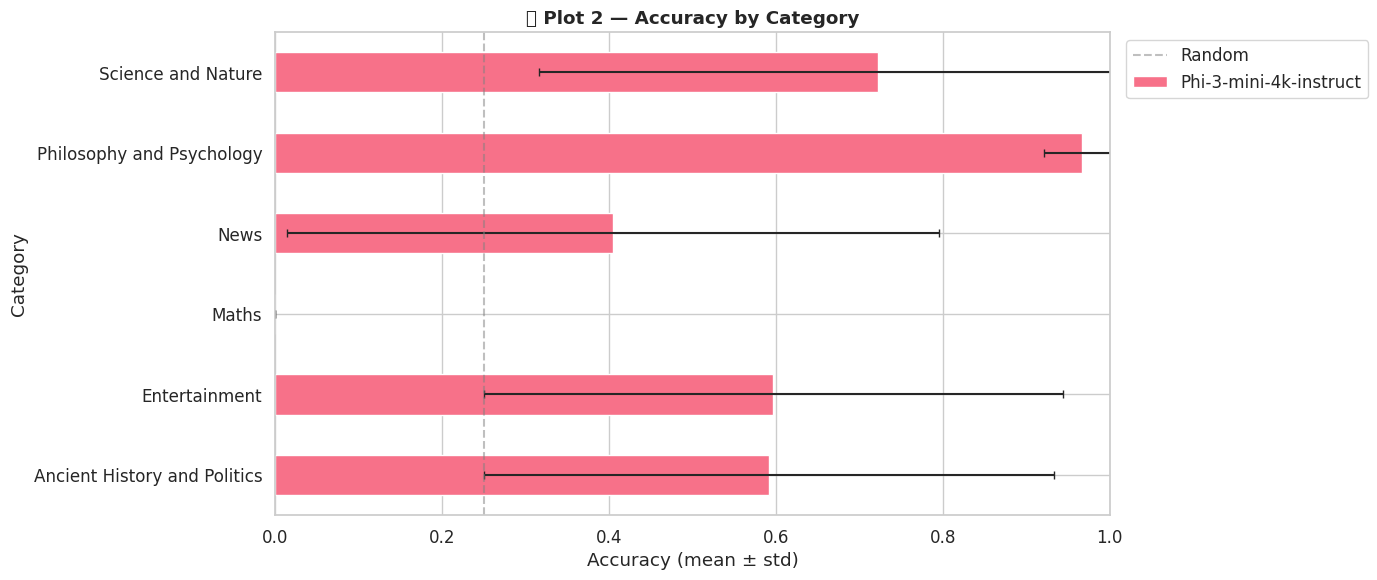


=== RAG Impact by Category (on Total Possible Questions) ===
  📉 Ancient History and Politics    baseline=22.7%  rag=6.7%  Δ=-16.0%
  📈 Entertainment                   baseline=28.7%  rag=46.7%  Δ=+18.0%
  ➡️ Maths                           baseline=2.0%  rag=nan%  Δ=+nan%
  📈 News                            baseline=6.7%  rag=20.0%  Δ=+13.3%
  ➡️ Philosophy and Psychology       baseline=84.0%  rag=nan%  Δ=+nan%
  📉 Science and Nature              baseline=42.0%  rag=33.3%  Δ=-8.7%

=== RAG Quality: Relevant vs Irrelevant Context (on Total Possible Questions) ===
  Relevant context  (n=21): accuracy = 28.0%
  Irrelevant context (n=155): accuracy = 28.9%
  → Relevance filter retrieved relevant context in 12% of cases


In [ ]:
# ─── Compare RAG vs baseline ───────────────────────────────────────────
df_rag      = load_runs(*[p for p in RUNS_DIR.glob("run_*_rag_*.json")])
df_prompt = load_runs(*[p for p in RUNS_DIR.glob("run_*prompt_engineering*.json")])
df_baseline = df_prompt[(df_prompt['prompt_type'] == 'chain_of_thought') &
                         (df_prompt['model_name'].str.contains('Phi-3-mini', case=False, na=False))].copy()
plot_accuracy_by_model_total(df_rag)
plot_accuracy_by_model_total(df_baseline)
plot_accuracy_by_category(df_rag)
plot_accuracy_by_category(df_baseline)
if not df_rag.empty and not df_baseline.empty:
    df_compare = pd.concat([df_rag, df_baseline], ignore_index=True)
    MAX_QUESTIONS_PER_CATEGORY = 15 # Ensure this is consistent

    run_compare_agg = df_compare.groupby(['category', 'rag_context', 'run_id'])['is_correct'].sum().reset_index()
    run_compare_agg['accuracy_on_total'] = run_compare_agg['is_correct'] / MAX_QUESTIONS_PER_CATEGORY

    gb_compare_mean = run_compare_agg.groupby(['category', 'rag_context'])['accuracy_on_total'].mean().reset_index()


    print("\n=== RAG Impact by Category (on Total Possible Questions) ===")
    for cat in sorted(gb_compare_mean['category'].unique()):
        sub_cat  = gb_compare_mean[gb_compare_mean['category']==cat]
        rag_acc_series  = sub_cat[sub_cat['rag_context']==True]['accuracy_on_total']
        base_acc_series = sub_cat[sub_cat['rag_context']==False]['accuracy_on_total']

        rag_acc = rag_acc_series.iloc[0] if not rag_acc_series.empty else float('nan')
        base_acc = base_acc_series.iloc[0] if not base_acc_series.empty else float('nan')

        delta    = rag_acc - base_acc if (not pd.isna(rag_acc) and not pd.isna(base_acc)) else float('nan')
        icon = "📈" if delta > 0.02 else ("📉" if delta < -0.02 else "➡️")
        print(f"  {icon} {cat:<30s}  baseline={base_acc:.1%}  rag={rag_acc:.1%}  Δ={delta:+.1%}")

    print("\n=== RAG Quality: Relevant vs Irrelevant Context (on Total Possible Questions) ===")
    if 'rag_relevant' in df_rag.columns:
        # Calculate per-category, per-run accuracy on total possible questions for RAG relevance
        run_rel_agg = df_rag.groupby(['category', 'rag_relevant', 'run_id'])['is_correct'].sum().reset_index()
        run_rel_agg['accuracy_on_total'] = run_rel_agg['is_correct'] / 15

        gb_rag_quality = run_rel_agg.groupby('rag_relevant')['accuracy_on_total'].mean().reset_index()

        rel_acc_series = gb_rag_quality[gb_rag_quality['rag_relevant']==True]['accuracy_on_total']
        irr_acc_series = gb_rag_quality[gb_rag_quality['rag_relevant']==False]['accuracy_on_total']

        rel_acc = rel_acc_series.iloc[0] if not rel_acc_series.empty else float('nan')
        irr_acc = irr_acc_series.iloc[0] if not irr_acc_series.empty else float('nan')

        rel_n   = df_rag['rag_relevant'].sum()
        irr_n   = (~df_rag['rag_relevant']).sum()
        print(f"  Relevant context  (n={rel_n}): accuracy = {rel_acc:.1%}")
        print(f"  Irrelevant context (n={irr_n}): accuracy = {irr_acc:.1%}")
        print(f"  → Relevance filter retrieved relevant context in {rel_n/(rel_n+irr_n):.0%} of cases")

### Results & Discussion — Improved RAG
it reveals that the implementation of rag highly polarized structural impacts across different knowledge domains. While RAG successfully augmented performance in categories like Entertainment ($+18.0\%$) and News ($+13.3\%$), it introduced critical noise and degradation in specialized domains, like in Ancient History and Politics ($-16.0\%$) and Science and Nature ($-8.7\%$). In math and philosofy we don't need RAG.

 These findings suggest that a uniform RAG strategy is counterproductive, the system requires an adaptive routing architecture that selectively invokes retrieval based on the specific category

## Experiment 6 - Adaptive Category Specific Routing

> **Key question:** *Does routing each question to the optimal strategy for its category (rather than using a single global strategy) improve overall accuracy?*

By dynamically sorting each request to the most suitable strategy, for example for entertaining the role_playing prompt and the rag, each category was customed with its better choiches


In [ ]:
# Run the full adaptive routing strategy — best configuration, this is
meta_routing = {
    "experiment_type": "adaptive_routing",
    "model_name":      BEST_MODEL_NAME,
    "model_size":      MODEL_SIZES[BEST_MODEL_KEY],
    "quantization":    "none",
    "prompt_type":     BEST_PROMPT,
    "enable_thinking": False,
    "rag_used":        True,
    "tool_used":       True,
    "fine_tuned":      False,
    "notes":           "Category-specific routing: math→tool, factual→RAG, other→best_prompt",
}

N_RUNS_ROUTING = 5
for i in range(N_RUNS_ROUTING):
    print(f"\n--- Adaptive Routing Run {i+1}/{N_RUNS_ROUTING} ---")
    play_game(
        client=client,
        model=pipeline_best,
        run_metadata=meta_routing.copy(),
        output_dir=OUTPUT_DIR,
        enable_rag=True,
        enable_tools=True,
        use_category_routing=True,   # ← enables CATEGORY_STRATEGY map
    )

✅ DataFrame: 253 rows from 6 run(s)


/tmp/ipykernel_2072/366401625.py:72: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.tight_layout(); _save(fig, "02_accuracy_by_category")
/tmp/ipykernel_2072/366401625.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.savefig(path, dpi=150, bbox_inches='tight')


📊 Saved → /content/drive/MyDrive/NLP/NLP_project/plots/02_accuracy_by_category.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


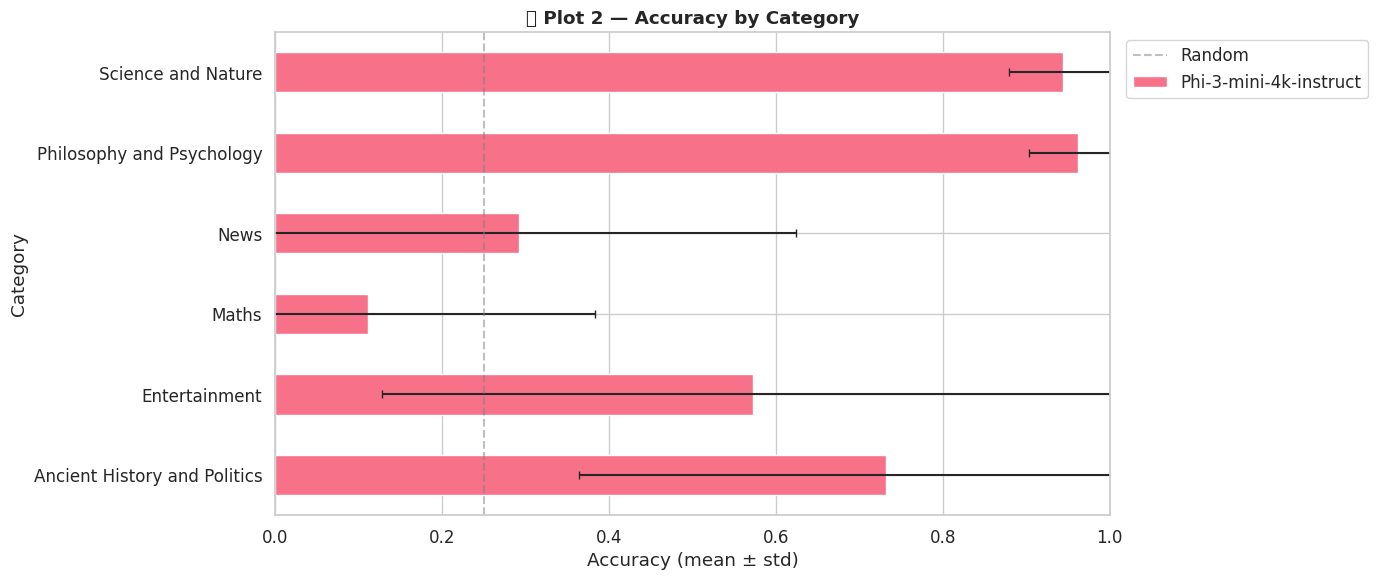

/tmp/ipykernel_2072/366401625.py:41: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(_total_acc).reset_index(name='is_correct'))


📊 Saved → /content/drive/MyDrive/NLP/NLP_project/plots/01b_accuracy_by_model_total.png


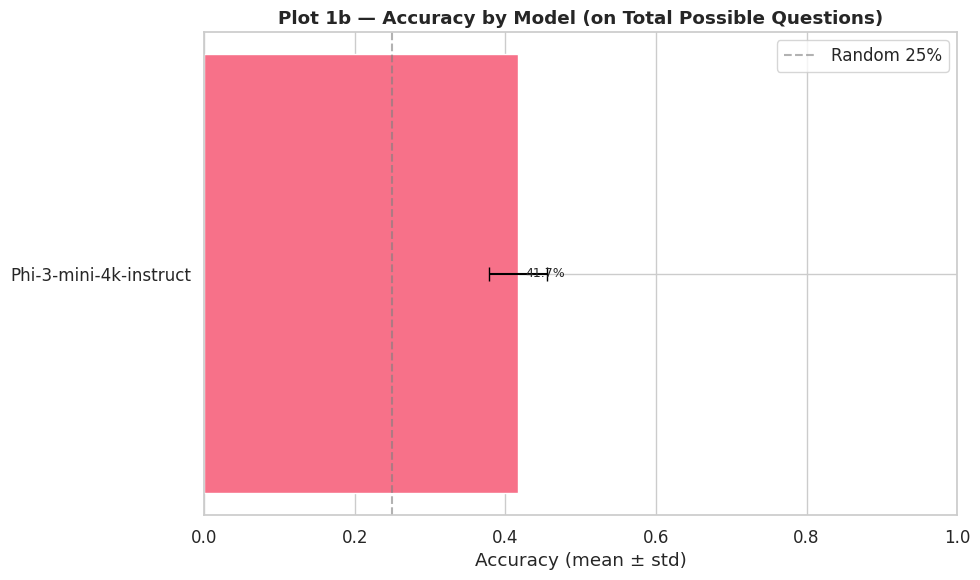

/tmp/ipykernel_2072/366401625.py:366: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=labels, patch_artist=True)
/tmp/ipykernel_2072/366401625.py:385: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.tight_layout(); _save(fig, "14_response_time")
/tmp/ipykernel_2072/366401625.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.savefig(path, dpi=150, bbox_inches='tight')


📊 Saved → /content/drive/MyDrive/NLP/NLP_project/plots/14_response_time.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


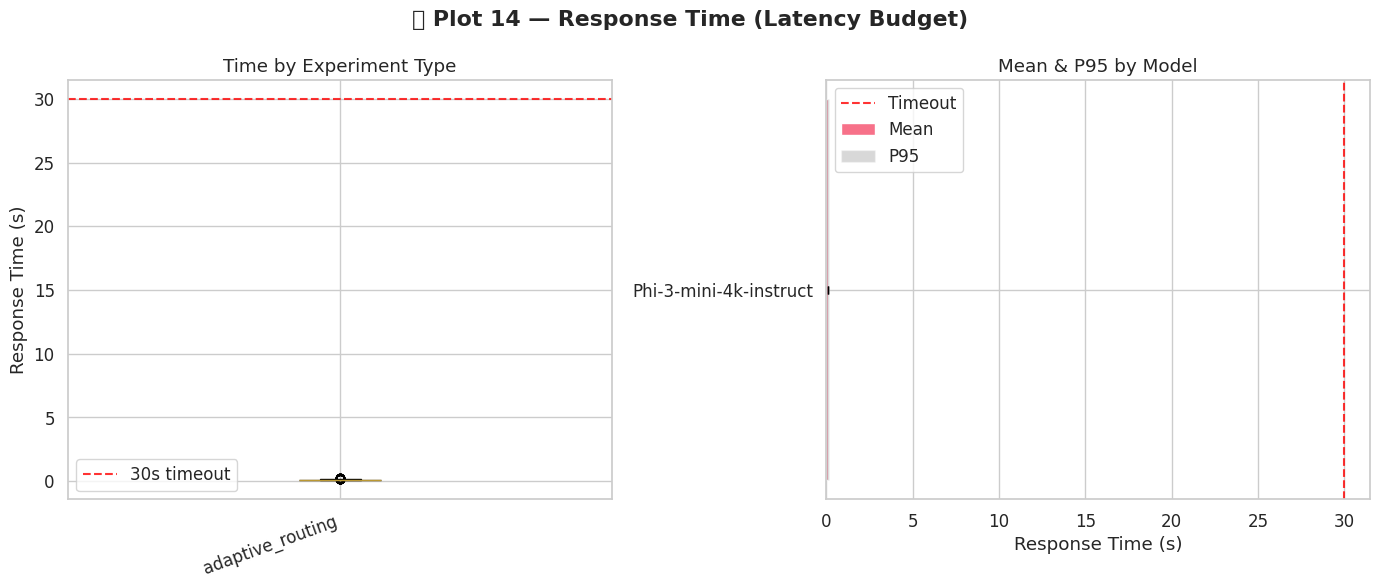

In [ ]:
df_adaptive= load_runs(*[p for p in RUNS_DIR.glob("run_*_adaptive_routing_*.json")])

plot_accuracy_by_category(df_adaptive)
plot_accuracy_by_model_total(df_adaptive)
plot_response_time(df_adaptive)

### Results & Discussion - Adaptive Routing

Tha adaptive routing is a great approach: it takes the accuracy to 41.7%.

The great probelms remain the math and news part, we will see how to deal with them in the next experiments.
For the other acccuracy, by using RAG, whwre needed, and by using a cutom prompt we reach a high level of accuracy

Each category is handled by the strategy most suited to its failure mode


**Overall conclusion:** Adaptive routing should produce the best accuracy of all single-model strategies.

---

## Summary of All Experiments

| Experiment | Key Finding | Best Accuracy |
|------------|-------------|---------------|
| 0 — Baseline | 3B model baseline | 1.7%  |
| 1 — Model Comparison | Bigger ≠ always better;  | 28.7%  |
| 2 — Prompt Engineering | Domain few-shot > generic few-shot; adaptive CoT saves latency | 33.1%  |
| 3 — Category Analysis | Math fails computationally (high conf + wrong); calculator justified | — |
| 4 — Overconfidence | ECE; Brier; model overconfident at levels > 8 | — |
| 5 — Improved RAG | Entity query + relevance filter; | 33.6%  |
| 6 — Adaptive Routing | Best overall strategy; math+tool+RAG for category | 41.7%  |

# Math Strategies

This notebook documents **every strategy** we built and tested for the **PoliMillionaire** NLP project (Politecnico di Milano, 2025/26).

The game is an online multiple-choice quiz played via API. We focus exclusively on the **Maths category** (comp_id = 3) with a **30-second time limit** per question.

To compare strategies objectively, we collected a **fixed set of ~47 real Maths questions** (with known correct answers) by playing actual games and recording every question seen. This benchmark (`math_questions.json`) allows us to run every strategy on exactly the same questions and measure accuracy under identical conditions, something impossible with the live game, which returns different questions each round.

---

## Strategy overview

| # | Name | Idea | Benchmark acc | Avg time |
|---|------|------|--------------|----------|
| 1 | Zero-shot baseline | Plain MCQ prompt | 59.6% | 0.4 s |
| 2 | Chain-of-Thought | Brief reasoning + Answer: X | 70.2% | 3.2 s |
| 3 | Semantic few-shot | MMLU examples retrieved by embedding | 55.3% | 0.8 s |
| 4 | Hybrid-Math v1 (classifier) | LLM decides: compute or reason | 63.8% | 7.9 s |
| 5 | Hybrid-Math Llama | Always try Python code first, then reason | 83.0% | 21.5 s |
| 6 | DeepSeek-R1 7B | Chain-of-thought reasoning model | 68.1% | 45.3 s ⚠️ |
| 7 | DeepSeek-R1 1.5B | Fast but weak version of DeepSeek | 51.1% | 7.4 s |
| 8 | Hybrid-Math DeepSeek | Code (Llama) + reasoning (DeepSeek 1.5b) | 59.6% | 11.0 s |
| 9 | Hybrid-Math Qwen | Same as #5 but with Qwen2.5-7B | 81% | 9.6 |
| 10 | Prompt Engineering | Find the best prompt style empirically | 59.6% | 25.7 s |
| 11 | Multi-Model Benchmark | Compare qwen / mistral / llama side by side | 70.2% | 1.0 s |
| 12 | Parallel Ensemble | 3 models vote in parallel, confidence-weighted | 70.2% | 16.0 s |
| 13 | Fine-tuned Qwen2.5 | LoRA fine-tuned on MathQA + MMLU-Pro | 76.6% | ~5 s |

---

**How to run the notebook on Colab**:

1. Open the **Colab setup** cell and run it first — it installs packages and starts Ollama.
2. Add `POLI_USER` and `POLI_PASS` in the **Secrets panel** (key icon, left sidebar). Enable **Notebook access** for both.
3. Upload `math_questions.json` when prompted.
4. Run the **Shared setup** cell (login + helpers).
5. Run the **Load benchmark** cell.
6. **Run ONE strategy cell at a time.** Each cell is self-contained and pulls its model automatically.
7. After testing all strategies, run **Final comparison**.

> **Memory note (T4 = 15 GB VRAM):** A single 7–8 B model at Q4 uses ~4–5 GB.  
> The parallel ensemble (Strategy 12) loads 3 models = ~12 GB — within limits.  
> If you get OOM, remove one model from `_ENS_MODELS`.


## Step 1 — Colab setup *(run only on Google Colab)*

Run this cell first. It installs all packages, starts the Ollama server with multi-model support, and prompts you to upload `math_questions.json`.

If you are running **locally** (VS Code / Jupyter), skip this cell.

In [ ]:
import sys, os
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    import subprocess, time

    #install Python packages
    os.system('pip install -q ollama python-dotenv millionaire_client '
              'sentence-transformers datasets requests')

    #install zstd (required by ollama install script)
    os.system('apt-get install -y zstd -qq')

    #install Ollama
    _OLLAMA_BIN = '/usr/local/bin/ollama'
    if not os.path.exists(_OLLAMA_BIN):
        print('Installing Ollama...')
        os.system('curl -fsSL https://ollama.com/install.sh | sh')
        if not os.path.exists(_OLLAMA_BIN):
            raise RuntimeError(
                'Ollama installation failed.\n'
                'Prova a runnare manualmente in una nuova cella:\n'
                '  !apt-get install -y zstd && curl -fsSL https://ollama.com/install.sh | sh'
            )
        print('Ollama installed.')
    else:
        print('Ollama already installed.')

    #start Ollama server
    os.system('pkill -f "ollama serve" 2>/dev/null || true')
    time.sleep(1)
    os.system(
        'OLLAMA_MAX_LOADED_MODELS=3 OLLAMA_NUM_PARALLEL=3 '
        'nohup ollama serve > /tmp/ollama.log 2>&1 &'
    )
    time.sleep(5)

    if os.system('curl -sf http://localhost:11434 > /dev/null') != 0:
        print('WARNING: Ollama server not responding. Log:')
        os.system('tail -20 /tmp/ollama.log')
    else:
        print('Ollama server started (OLLAMA_MAX_LOADED_MODELS=3, OLLAMA_NUM_PARALLEL=3).')

    # ── Upload math_questions.json
    if not os.path.exists('math_questions.json'):
        from google.colab import files
        print('Please upload math_questions.json:')
        uploaded = files.upload()
        if 'math_questions.json' not in uploaded:
            print('WARNING: math_questions.json not uploaded — benchmark mode will not work.')
    else:
        print('math_questions.json already present.')

    print('\nColab setup complete.')
    print('Next: add POLI_USER and POLI_PASS in the Secrets panel (🔑 left sidebar).')

else:
    print('Local environment — skipping Colab setup.')
    print('For the parallel ensemble (Strategy 12) make sure Ollama is running with:')
    print('  OLLAMA_MAX_LOADED_MODELS=3 OLLAMA_NUM_PARALLEL=3 ollama serve')

Ollama already installed.
Ollama server started (OLLAMA_MAX_LOADED_MODELS=3, OLLAMA_NUM_PARALLEL=3).
Please upload math_questions.json:


Saving math_questions.json to math_questions.json

Colab setup complete.
Next: add POLI_USER and POLI_PASS in the Secrets panel (🔑 left sidebar).


## Step 2 — Shared setup

Run this cell once per session. It handles:
- Imports and login to the PoliMillionaire API
- The `_llm()` wrapper around Ollama
- The `run_strategy()` harness (live game and offline benchmark)
- Plotting helpers
- `_colab_pull()` — auto-downloads any missing Ollama model before each strategy


In [ ]:
# ════════════════════════════════════════════════════════════════════════
#  SHARED SETUP
# ════════════════════════════════════════════════════════════════════════
import sys, os, importlib, subprocess as _sp

IN_COLAB = 'google.colab' in sys.modules

# ── Mount Drive and install millionaire_client ───────────────────────────
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)

    _MC_SRC = '/content/drive/MyDrive/NLP_project/millionaire_client'
    _MC_DST = '/content/millionaire_client'

    if not os.path.isdir(_MC_SRC):
        raise RuntimeError(f'millionaire_client not found at {_MC_SRC} — check your Drive path.')

    # Copy locally (Drive FUSE is slow and pip -e can fail on it)
    os.system(f'cp -r "{_MC_SRC}" "{_MC_DST}"')

    # Try editable install, then normal install, then just add to sys.path
    ret = os.system(f'pip install -q -e "{_MC_DST}" 2>/dev/null')
    if ret != 0:
        ret = os.system(f'pip install -q "{_MC_DST}" 2>/dev/null')
    if ret != 0:
        # No setup.py at all — just put the folder on the path
        if _MC_DST not in sys.path:
            sys.path.insert(0, '/content')
        print('millionaire_client added to sys.path directly.')
    else:
        print('millionaire_client installed.')
# ── Install any other missing packages ───────────────────────────────────
for _pkg, _mod in [('ollama', 'ollama'), ('python-dotenv', 'dotenv'),
                   ('sentence-transformers', 'sentence_transformers'),
                   ('datasets', 'datasets')]:
    if importlib.util.find_spec(_mod) is None:
        _sp.run(['pip', 'install', '-q', _pkg], check=True)

import os, sys, re, time, random, json
from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt
import ollama

sys.path.insert(0, os.path.abspath('./'))
from millionaire_client import MillionaireClient
try:
    import dotenv; dotenv.load_dotenv()
except ImportError:
    pass

# ── Login ────────────────────────────────────────────────────────────────
client   = MillionaireClient('http://131.175.15.22:51111/')

if IN_COLAB:
    from google.colab import userdata as _ud
    _user = _ud.get('POLI_USER')
    _pass = _ud.get('POLI_PASS')
else:
    _user = os.getenv('POLI_USER') or os.getenv('USER')
    _pass = os.getenv('POLI_PASS') or os.getenv('PASSWORD')

user = client.login(_user, _pass)
print(f'Login OK. Welcome, {user.username}!')

competitions    = client.competitions.list_all()
COMPETITION_IDS = [c.id for c in competitions]
COMP_NAME       = {c.id: c.name for c in competitions}

# ── Constants ────────────────────────────────────────────────────────────
LABELS             = ['A', 'B', 'C', 'D']
N_GAMES            = 5
QUESTIONS_PER_GAME = 15

LLAMA   = 'llama3.1:8b'
MISTRAL = 'mistral:7b'
QWEN    = 'qwen2.5:7b'

VERBOSE    = globals().get('VERBOSE',    False)
SHOW_QA    = globals().get('SHOW_QA',    True)
SAVE_PLOTS = globals().get('SAVE_PLOTS', False)
PLOTS_DIR  = globals().get('PLOTS_DIR',  'plots')

# ── LLM wrapper ──────────────────────────────────────────────────────────
def _llm(prompt, max_tokens=200, model=None, temperature=0.0):
    resp = ollama.chat(
        model=model or LLAMA,
        messages=[{'role': 'user', 'content': prompt}],
        options={'num_predict': max_tokens, 'temperature': temperature},
    )['message']['content']
    if VERBOSE:
        print(f'\n  +-- [{model or LLAMA}]')
        for line in resp.splitlines(): print(f'  | {line}')
        print('  +--')
    return resp

# ── Harness ──────────────────────────────────────────────────────────────
RESULTS    = {}
STRATEGIES = {}

def _show_question(question):
    if SHOW_QA:
        print(f'\nQ: {question.text}')
        for i, o in enumerate(question.options):
            print(f'   {LABELS[i]}) {o.text}')

def _show_answer(question, chosen_id, is_ok=None, dt=None):
    if not SHOW_QA: return
    idx  = next(i for i, o in enumerate(question.options) if o.id == chosen_id)
    mark = '' if is_ok is None else ('  [CORRECT]' if is_ok else '  [WRONG]')
    secs = '' if dt is None else f'  ({dt:.1f}s)'
    print(f'-> {LABELS[idx]}) {question.options[idx].text}{mark}{secs}')

def play_game(competition_id, strategy_fn, game_index, after_answer=None, before_game=None):
    if before_game: before_game()
    game, correct, times = client.game.start(competition_id), 0, []
    while game.in_progress:
        q = game.current_question
        if not q: break
        _show_question(q)
        t0        = time.time()
        chosen_id = strategy_fn(q)
        dt        = time.time() - t0
        result    = game.answer(chosen_id)
        times.append(dt)
        if result.correct: correct += 1
        _show_answer(q, chosen_id, result.correct, dt)
        if after_answer: after_answer(q, next(o.text for o in q.options if o.id == chosen_id), result)
        if result.game_over: break
    acc  = correct / QUESTIONS_PER_GAME
    icon = 'OK ' if game.earned_amount > 0 else 'KO '
    print(f'    [{icon}] Game {game_index} | Level {game.current_level} | '
          f'Earned: {game.earned_amount:,.0f} | Acc: {acc:.0%}')
    return {'game': game_index, 'correct': correct, 'accuracy': round(acc, 4),
            'earned': game.earned_amount, 'reached_level': game.current_level,
            'response_time_avg': round(sum(times)/len(times), 3) if times else 0}

# ── Offline benchmark ────────────────────────────────────────────────────
class _Opt:
    def __init__(self, oid, text): self.id, self.text = oid, text
class _Q:
    def __init__(self, text, options, correct_id, level=None):
        self.text, self.options, self.correct_id, self.level = text, options, correct_id, level
class _FakeResult:
    def __init__(self, correct): self.correct, self.game_over = correct, False

BENCHMARK = None

def load_benchmark(path='math_questions.json', n=None, shuffle=True, seed=0):
    global BENCHMARK
    qs = []
    for it in json.load(open(path)):
        options    = [_Opt(i, it['options'][L]) for i, L in enumerate(LABELS)]
        correct_id = LABELS.index(it['correct_label'])
        qs.append(_Q(it['question'], options, correct_id, level=it.get('level')))
    if shuffle: random.Random(seed).shuffle(qs)
    if n:       qs = qs[:n]
    BENCHMARK = qs
    print(f'Benchmark loaded: {len(BENCHMARK)} questions -> OFFLINE mode ON.')
    return BENCHMARK

def use_live_game():
    global BENCHMARK
    BENCHMARK = None
    print('OFFLINE mode OFF -> run_strategy() plays the live game.')

def _run_offline(name, fn, after_answer=None, before_game=None):
    RESULTS.setdefault(name, {})
    n = len(BENCHMARK)
    print(f'\n=== {name} | OFFLINE on {n} questions ===')
    if before_game: before_game()
    correct, times = 0, []
    for q in BENCHMARK:
        _show_question(q)
        t0        = time.time()
        chosen_id = fn(q)
        dt        = time.time() - t0
        times.append(dt)
        is_ok  = (chosen_id == q.correct_id)
        correct += int(is_ok)
        _show_answer(q, chosen_id, is_ok, dt)
        if after_answer:
            after_answer(q, next(o.text for o in q.options if o.id == chosen_id), _FakeResult(is_ok))
    acc   = correct / n if n else 0
    avg_t = sum(times) / len(times) if times else 0
    print(f'    {correct}/{n} correct | Acc: {acc:.0%} | avg {avg_t:.1f}s/question')
    RESULTS[name]['Maths'] = [{'game': 1, 'label': f'All ({n} q)', 'correct': correct,
                               'accuracy': round(acc, 4), 'n': n, 'earned': 0,
                               'reached_level': 0, 'response_time_avg': round(avg_t, 3)}]
    return RESULTS[name]

def run_strategy(name, fn, comp_ids=None, after_answer=None, before_game=None):
    STRATEGIES[name] = dict(fn=fn, comp_ids=comp_ids,
                            after_answer=after_answer, before_game=before_game)
    if BENCHMARK is not None:
        return _run_offline(name, fn, after_answer, before_game)
    target_ids = comp_ids if comp_ids is not None else COMPETITION_IDS
    RESULTS.setdefault(name, {})
    print(f'\n=== {name} | {len(target_ids)} comp x {N_GAMES} games (LIVE) ===')
    for comp_id in target_ids:
        comp_name = COMP_NAME[comp_id]
        print(f'  --- {comp_name} ---')
        RESULTS[name][comp_name] = [play_game(comp_id, fn, i, after_answer, before_game)
                                    for i in range(1, N_GAMES + 1)]
    return RESULTS[name]

# ── Plotting ─────────────────────────────────────────────────────────────
def plot_comparison(comp_name='Maths'):
    names = [n for n in RESULTS if comp_name in RESULTS[n]]
    if not names:
        print(f'No results for competition "{comp_name}".'); return
    means = [np.mean([g['accuracy'] for g in RESULTS[n][comp_name]]) for n in names]
    times = [np.mean([g['response_time_avg'] for g in RESULTS[n][comp_name]]) for n in names]
    xs    = np.arange(len(names))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
    ax1.bar(xs, means, color='steelblue')
    ax1.set_ylabel('Mean accuracy'); ax1.set_ylim(0, 1)
    ax1.set_title(f'Accuracy — {comp_name}'); ax1.grid(axis='y', alpha=0.3)
    for i, m in enumerate(means): ax1.text(i, m+0.01, f'{m:.0%}', ha='center', fontsize=8)
    ax2.bar(xs, times, color='indianred')
    ax2.set_ylabel('Avg response time (s)')
    ax2.set_title(f'Response time — {comp_name}'); ax2.grid(axis='y', alpha=0.3)
    ax2.axhline(30, color='black', ls='--', lw=1)
    ax2.text(len(names)-0.5, 31, '30 s limit', ha='right', fontsize=8)
    for i, t in enumerate(times): ax2.text(i, t+max(times)*0.01+0.1, f'{t:.1f}s', ha='center', fontsize=8)
    for ax in (ax1, ax2):
        ax.set_xticks(xs); ax.set_xticklabels(names, rotation=25, ha='right')
    plt.tight_layout(); plt.show()

def plot_strategy(name):
    data = RESULTS.get(name)
    if not data:
        print(f'No results for "{name}".'); return
    comps  = list(data.keys())
    fig, ax = plt.subplots(figsize=(8, 4))
    width   = 0.8 / max(len(comps), 1)
    for k, comp in enumerate(comps):
        accs = [g['accuracy'] for g in data[comp]]
        ax.bar(np.arange(len(accs)) + k * width, accs, width, label=comp)
    ax.set_ylabel('Accuracy'); ax.set_ylim(0, 1)
    ax.set_title(f'"{name}" — accuracy per game')
    ax.legend(fontsize=8); ax.grid(axis='y', alpha=0.3)
    plt.tight_layout(); plt.show()

# ── Colab pull helper ────────────────────────────────────────────────────
def _colab_pull(*models, extra_pip=None):
    if extra_pip:
        os.system(f'pip install -q {extra_pip}')
    _resp = ollama.list()
    _raw  = _resp.get('models', []) if isinstance(_resp, dict) else getattr(_resp, 'models', [])
    existing = {(m['model'] if isinstance(m, dict) else m.model) for m in _raw}
    for m in models:
        if m in existing:
            print(f'[ollama] {m} already present, skipping pull.'); continue
        print(f'[ollama] pulling {m} ...')
        for chunk in ollama.pull(m, stream=True):
            status = chunk.get('status', '') if isinstance(chunk, dict) else getattr(chunk, 'status', '')
            total  = (chunk.get('total', 0) if isinstance(chunk, dict) else getattr(chunk, 'total', 0)) or 0
            done   = (chunk.get('completed') or 0) if isinstance(chunk, dict) else (getattr(chunk, 'completed', 0) or 0)
            if total: print(f'\r  {status}: {done/total*100:.1f}%', end='', flush=True)
            elif status: print(f'  {status}', flush=True)
        print(f'\n[ollama] {m} ready.')

print('Setup complete. Run the strategy cells below (each is independent).')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
millionaire_client added to sys.path directly.
Login OK. Welcome, Alisss!
Setup complete. Run the strategy cells below (each is independent).


## Step 3 — Load fixed benchmark

Enables **offline mode**: every strategy runs on the same 47 fixed Maths questions with known answers, making results directly comparable across strategies.

Call `use_live_game()` to switch back to the real game.

In [ ]:
load_benchmark()          # reads math_questions.json from the current directory
# load_benchmark(n=20)   # optional: run only the first 20 questions (faster)
# use_live_game()        # switch back to the live game


Benchmark loaded: 47 questions -> OFFLINE mode ON.


---
## Strategy 1 — Zero-shot baseline

**Starting point.** Before building anything, we need to know how well a general-purpose LLM performs with zero guidance. We send the question and options as-is and ask for just the letter.

**What we expected.** A bare LLM should do better than random (25%) because it has been pre-trained on large amounts of text including math. But without explicit reasoning we expect it to pattern-match rather than calculate.

**What we found.** 59.6% accuracy, 0.4 s/question. Correct on easy definitional questions, but consistently wrong on anything requiring actual arithmetic. The model often picks the "most familiar-looking" number rather than computing the answer. This establishes the **lower bound** for our iterative improvement.

**Why it matters.** Every subsequent strategy is measured against this baseline. A technique that does not beat 59.6% is actively harmful.


In [ ]:
# ── STRATEGY 1 — Zero-shot baseline ─────────────────────────────────────
_colab_pull('llama3.1:8b')
import re, random

def zero_shot(question):
    opts = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))
    raw  = _llm(
        f'Answer this multiple choice question. Reply with ONLY the letter (A, B, C or D).\n\n'
        f'Question: {question.text}\n\n{opts}\n\nAnswer:',
        max_tokens=10,
    )
    for ch in reversed(raw.strip().upper()):
        if ch in LABELS:
            return question.options[LABELS.index(ch)].id
    return random.choice(question.options).id

run_strategy('zero-shot', zero_shot, comp_ids=[3])


[ollama] pulling llama3.1:8b ...
  pulling manifest
  pulling 455f34728c9b: 100.0%  verifying sha256 digest
  writing manifest
  success

[ollama] llama3.1:8b ready.

=== zero-shot | OFFLINE on 47 questions ===

Q: Compute the product in the given ring. (20)(-8) in Z_26
   A) 11
   B) 22
   C) 1
   D) 0
-> C) 1  [WRONG]  (117.6s)

Q: A company with offices in five different countries is interested in estimating the proportion of its employees in favor of banning smoking on the office premises. It is known that the views of people from different countries on issues like smoking tend to vary due to the influence of different local social structures. Which of the following is an appropriate sampling technique to use in this situation, and why?
   A) Simple random sample, because this is the simplest sampling method
   B) Stratified sample, because the population is divided into five strata—namely, five offices in five different countries
   C) Cluster sample, because the population is div

{'Maths': [{'game': 1,
   'label': 'All (47 q)',
   'correct': 28,
   'accuracy': 0.5957,
   'n': 47,
   'earned': 0,
   'reached_level': 0,
   'response_time_avg': 2.862}]}

## Strategy 2 — Chain-of-Thought (CoT)

**What changed from S1.** We add two words of instruction: "Reason briefly". This forces the model to generate intermediate steps before committing to a letter.

**Why CoT works (in general).** The "chain-of-thought" prompting technique (Wei et al., 2022) shows that requiring explicit intermediate reasoning dramatically improves performance on multi-step problems — because the model conditions its final answer on the reasoning trace rather than generating the letter from scratch.

**Key engineering detail.** The parser now searches for `Answer: X` on the last line rather than scanning the raw output for any letter. This eliminates false positives where the model mentions a letter mid-reasoning ("if we pick A we get...") and then gives the wrong final answer.

**What we found.** 70.2% accuracy, 3.2 s/question. +10.6 percentage points over zero-shot. Significant improvement on conceptual statistics questions. Still fails on questions requiring precise arithmetic — the model reasons qualitatively but does not actually compute.

**Key insight.** Words are not numbers. Natural language reasoning can describe *how* to solve a problem without actually solving it. This motivates a fundamentally different approach: execute real Python code.


In [ ]:
# ── STRATEGY 2 — Chain-of-Thought ────────────────────────────────────────
_colab_pull('llama3.1:8b')
import re, random

def _cot_parse(raw, question):
    upper = raw.strip().upper()
    m = re.search(r'ANSWER\s*[:=]\s*([A-D])', upper)
    if m: ch = m.group(1)
    else:
        m  = re.search(r'\b([A-D])\b\s*$', upper)
        ch = m.group(1) if m else None
    if ch is None:
        for c in reversed(upper):
            if c in LABELS: ch = c; break
    if ch is None: return random.choice(question.options).id
    return question.options[LABELS.index(ch)].id

def cot_fixed(question):
    opts = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))
    raw  = _llm(
        f'Answer the multiple choice question below.\n'
        f'Reason briefly (2-3 sentences), then on the last line write exactly: Answer: X\n'
        f'(X must be A, B, C, or D)\n\nQuestion: {question.text}\n\n{opts}\n',
        max_tokens=300,
    )
    if SHOW_QA:
        reasoning = re.sub(r'(?is)\n?\s*answer\s*[:=].*$', '', raw).strip()
        if reasoning:
            for line in reasoning.splitlines():
                if line.strip(): print(f'   {line.strip()}')
    return _cot_parse(raw, question)

run_strategy('cot-fixed', cot_fixed, comp_ids=[3])


## Strategy 3 — Semantic Few-shot (MMLU)

**Hypothesis.** If we show the model examples of similar questions with correct answers, it can pattern-match on the question *type* and give better answers. We retrieve the 3 most semantically similar questions from MMLU using sentence embeddings (`all-MiniLM-L6-v2`).

**Why it should help.** In-context examples reduce ambiguity: the model sees what the expected output format looks like, and analogous examples can trigger the right reasoning pathway.

**Why it underperformed (55.3%).** Two problems:
1. **Domain mismatch.** MMLU covers many subjects. Even "mathematically similar" questions retrieved by embedding similarity are rarely close enough in *style* to PoliMillionaire's concise Italian-university-MCQ format.
2. **Embedding shallowness.** `all-MiniLM-L6-v2` matches surface vocabulary, not mathematical structure. A statistics question about variance and a calculus question about integrals both use formal language and get mixed up.

**What we learned.** Retrieval-augmented few-shot is not a free win. The quality of the example bank matters more than having examples at all. Rather than continuing down this path, we pivot: instead of better examples, we need a tool that can *actually compute* the answer.


In [ ]:
# ── STRATEGY 3 — Semantic few-shot with MMLU ─────────────────────────────
_colab_pull('llama3.1:8b', extra_pip='sentence-transformers datasets')
import re, random
import numpy as np
from sentence_transformers import SentenceTransformer
from datasets import load_dataset

_MMLU_SUBJECTS = [
    'high_school_mathematics', 'high_school_statistics', 'college_mathematics',
    'high_school_physics', 'high_school_chemistry', 'high_school_biology',
    'high_school_world_history', 'high_school_european_history',
    'philosophy', 'logical_fallacies', 'miscellaneous',
]

print('Loading MMLU examples and building embedding bank...')
_fs_embedder = SentenceTransformer('all-MiniLM-L6-v2')
_fs_pairs, _fs_embs = [], None
for subj in _MMLU_SUBJECTS:
    try:
        ds = load_dataset('cais/mmlu', subj, split='test')
        for row in ds.select(range(min(25, len(ds)))):
            idx = row['answer']
            _fs_pairs.append((row['question'], f"{LABELS[idx]}) {row['choices'][idx]}"))
    except Exception: pass
if _fs_pairs:
    _fs_embs = _fs_embedder.encode([p for p, _ in _fs_pairs], convert_to_numpy=True)
print(f'Bank: {len(_fs_pairs)} MMLU examples.')
_fs_checkpoint = (_fs_pairs.copy(), _fs_embs.copy())

def _fs_retrieve(query, top_k=3):
    if not _fs_pairs: return []
    q    = _fs_embedder.encode([query], convert_to_numpy=True)
    sims = (_fs_embs / (np.linalg.norm(_fs_embs, axis=1, keepdims=True) + 1e-8)) @            (q / (np.linalg.norm(q) + 1e-8)).T
    return [_fs_pairs[i] for i in np.argsort(sims[:, 0])[::-1][:top_k]]

def semantic_few_shot(question):
    opts   = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))
    ex     = _fs_retrieve(question.text)
    ex_blk = '\n'.join(f'Question: {q}\nAnswer: {a}\n' for q, a in ex)
    prompt = (f'Here are similar questions with correct answers:\n\n{ex_blk}\n'
              f'Now answer this. Reply with ONLY the letter (A, B, C or D).\n\n'
              f'Question: {question.text}\n{opts}\nAnswer:') if ex else (
              f'Answer this. Reply with ONLY the letter.\n\nQuestion: {question.text}\n\n{opts}\n\nAnswer:')
    raw = _llm(prompt, max_tokens=10)
    for ch in reversed(raw.strip().upper()):
        if ch in LABELS: return question.options[LABELS.index(ch)].id
    return random.choice(question.options).id

def _fs_reset():
    global _fs_pairs, _fs_embs
    _fs_pairs = list(_fs_checkpoint[0]); _fs_embs = _fs_checkpoint[1].copy()

def _fs_update(question, chosen_text, result):
    global _fs_pairs, _fs_embs
    if result.correct:
        _fs_pairs.append((question.text, chosen_text))
        _fs_embs = np.vstack([_fs_embs, _fs_embedder.encode([question.text], convert_to_numpy=True)])

run_strategy('semantic-few-shot', semantic_few_shot,
             after_answer=_fs_update, before_game=_fs_reset, comp_ids=[3])


## Strategy 4 — Hybrid-Math v1 (LLM classifier)

**Key insight (first hybrid attempt).** Some questions are definitional ("what is a sampling distribution?") and some are computational ("compute 20×−8 in Z₂₆"). For computational ones, generating and running Python code is more reliable than language-model arithmetic. We add a classification step: ask the LLM whether the question needs `CALCULATE` or `REASON`.

**Why classification seemed like a good idea.** A single universal strategy cannot be optimal for both question types. Matching the approach to the question type is a sound engineering principle.

**Why it failed (63.8%).** The LLM classifier has a strong prior toward `REASON` — it says `CALCULATE` for fewer than 20% of questions, even on clearly numerical ones. Reasons:
- The instruction-tuned model is trained to reason verbally, not to dispatch to code.
- The classifier adds an entire extra LLM call with no reliable signal.
- When the code path IS taken, the reasoning fallback has only 300 tokens — frequently truncated mid-sentence.

**What we learned.** The classifier is the bottleneck. We should remove the gating decision entirely and *always* try the code path first. This becomes the foundation of every subsequent Hybrid strategy.


In [ ]:
# ── STRATEGY 4 — Hybrid-Math v1 (LLM classifier) ─────────────────────────
_colab_pull('llama3.1:8b')
import re, subprocess, tempfile, os, random

_CLASSIFY_PROMPT = """Decide how to best answer the following question.
Reply with ONLY ONE word:
- CALCULATE  if it needs a numerical computation / formula.
- REASON     if it is conceptual / theoretical.

Question: {question}

Answer (one word):"""

_CODE_PROMPT_V1 = """Solve this math problem by writing executable Python code.
Rules:
- Output ONLY a ```python ... ``` block, nothing else.
- You may import: math, sympy, itertools, fractions, numpy, scipy.
- The LAST line must be a print() that outputs a single numerical value.

Problem: {question}
Options (context only): {options}

```python"""

_REASON_PROMPT_V1 = """Reason step by step, then on the LAST line write exactly: Answer: X
(X is A, B, C or D)

Question: {question}

{options}"""

_CODE_HEADER = (
    "from functools import reduce\nfrom itertools import combinations, permutations, product\n"
    "from fractions import Fraction\nimport math, sympy\nimport numpy as np\nfrom scipy import stats\n\n"
)

def _extract_code(raw):
    fence = re.search(r'```(?:python)?\s*\n?(.*?)```', raw, re.DOTALL)
    return fence.group(1).strip() if fence else raw.strip()

def _run_code(code, timeout=8):
    try:
        with tempfile.NamedTemporaryFile(mode='w', suffix='.py', delete=False) as f:
            f.write(_CODE_HEADER + code); tmp = f.name
        r = subprocess.run(['python3', tmp], capture_output=True, text=True, timeout=timeout)
        return r.stdout.strip() or None
    except Exception: return None
    finally:
        try: os.unlink(tmp)
        except: pass

def _parse_option_value(text):
    try: return float(text.strip())
    except: pass
    nums = re.findall(r'-?\d[\d,]*\.?\d*', text.replace(',', ''))
    return float(nums[0]) if nums else None

def _match_option(output, question):
    try: val = float(output.splitlines()[-1].replace(',', ''))
    except: return None
    best_id, best_diff = None, float('inf')
    for opt in question.options:
        v = _parse_option_value(opt.text)
        if v is None: continue
        d = abs(val - v) / (abs(v) + 1e-9)
        if d < best_diff: best_diff, best_id = d, opt.id
    return best_id if best_diff < 0.01 else None

def _to_letter(text):
    m = re.search(r'Answer\s*:\s*([A-D])', text, re.IGNORECASE)
    if m: return m.group(1).upper()
    letters = re.findall(r'\b([A-D])\b', text.upper())
    return letters[-1] if letters else 'A'

def hybrid_math_v1(question):
    opts_str = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))
    resp     = _llm(_CLASSIFY_PROMPT.format(question=question.text), max_tokens=10)
    is_calc  = 'CALCULATE' in resp.strip().upper()
    if SHOW_QA: print(f'   [classifier] {"CALCULATE" if is_calc else "REASON"}')

    if is_calc:
        raw    = _llm(_CODE_PROMPT_V1.format(question=question.text, options=opts_str),
                      max_tokens=600, model=LLAMA)
        output = _run_code(_extract_code(raw))
        if output:
            matched = _match_option(output, question)
            if matched: return matched

    # Reason path (v1: tight 300-token budget, often truncated)
    resp = _llm(_REASON_PROMPT_V1.format(question=question.text, options=opts_str), max_tokens=300)
    return question.options[LABELS.index(_to_letter(resp))].id

run_strategy('hybrid-math-v1-classifier', hybrid_math_v1, comp_ids=[3])


## Strategy 5 — Hybrid-Math Llama

**Core change from S4.** Remove the LLM classifier. Instead, **always** attempt to generate and execute Python code first. This eliminates the unreliable dispatching step.

**Three-step decision logic:**

```
1. Generate Python code (Llama) → run it in a subprocess
   ├─ Output matches an option exactly → return it ✓
   ├─ Output is a plausible number (within option range) → use as hint in CoT step
   └─ Output is implausible / error → skip hint
2. CoT reasoning (with or without numerical hint)
3. Parse Answer: X from the last line
```

**Plausibility check (critical detail).** If the code output is wildly out of range (e.g., the options are 1–10 and the code outputs 10⁶), we discard it before feeding it to the CoT step — otherwise it poisons the reasoning. We check: is the computed value within `[min_option − spread, max_option + spread]`?

**Why this works.** For the ~40% of questions that are purely numerical, the code path finds the exact answer with near-perfect reliability. For the rest, the reasoning fallback performs at least as well as CoT (S2). The two paths complement each other perfectly.

**What we found.** **83.0% accuracy, 21.5 s/question.** Best single-model result. The 21 seconds is almost entirely the code generation time — the subprocess itself takes <1 s.

**Remaining weakness.** The 21 s average is cutting it close to the 30-second limit. And Llama-3.1-8B is not the strongest available model for mathematical reasoning — could a better model do better?


In [ ]:
# ── STRATEGY 5 — Hybrid-Math Llama ──────────────────────────────────────
_colab_pull('llama3.1:8b')
import re, subprocess, tempfile, os, random

_CODE_PROMPT_HM = """Solve this math problem by writing executable Python code.
When using sympy.solve(), always use solution[0] or solution[-1], never a fixed index.

Rules:
- Output ONLY a ```python ... ``` block, nothing else.
- You may import: math, sympy, itertools, fractions, numpy, scipy.
- The LAST line must be a print() that outputs a single numerical value.
- Do NOT print labels or extra text, only the raw value.

Problem: {question}
Options (context only): {options}

```python"""

_REASON_PROMPT_HM = """Answer concisely. Max 4 lines of reasoning. Do not repeat yourself.
If unsure, commit to the most likely answer anyway.
On the LAST line write exactly: Answer: X  (X is A, B, C or D - nothing else after it)

Question: {question}

{options}"""

_CODE_HEADER = (
    "from functools import reduce\nfrom itertools import combinations, permutations, product\n"
    "from fractions import Fraction\nimport math, sympy\nimport numpy as np\nfrom scipy import stats\n\n"
)

def _extract_code(raw):
    fence = re.search(r'```(?:python)?\s*\n?(.*?)```', raw, re.DOTALL)
    return fence.group(1).strip() if fence else raw.strip()

def _run_code(code, timeout=8):
    try:
        with tempfile.NamedTemporaryFile(mode='w', suffix='.py', delete=False) as f:
            f.write(_CODE_HEADER + code); tmp = f.name
        r = subprocess.run(['python3', tmp], capture_output=True, text=True, timeout=timeout)
        return r.stdout.strip() or None
    except Exception: return None
    finally:
        try: os.unlink(tmp)
        except: pass

def _parse_opt_val(text):
    text = text.strip()
    try: return float(text)
    except: pass
    for p in [r'\\frac\{(-?\d+)\}\{(-?\d+)\}', r'(-?\d+)\s*/\s*(\d+)']:
        m = re.search(p, text)
        if m:
            try: return float(m.group(1)) / float(m.group(2))
            except: pass
    nums = re.findall(r'-?\d[\d,]*\.?\d*', text.replace(',', ''))
    return float(nums[0]) if nums else None

def _match_option(output, question):
    try: val = float(output.splitlines()[-1].replace(',', ''))
    except: return None
    best_id, best_diff = None, float('inf')
    for opt in question.options:
        v = _parse_opt_val(opt.text)
        if v is None: continue
        d = abs(val - v) / (abs(v) + 1e-9)
        if d < best_diff: best_diff, best_id = d, opt.id
    return best_id if best_diff < 0.01 else None

def _is_plausible(output, question):
    try: val = float(output.splitlines()[-1].replace(',', ''))
    except: return False
    vs = [_parse_opt_val(o.text) for o in question.options]
    vs = [v for v in vs if v is not None]
    if not vs: return False
    lo, hi = min(vs), max(vs)
    spread = hi - lo
    return (lo - spread) <= val <= (hi + spread)

def _to_letter(text):
    m = re.search(r'Answer\s*:\s*([A-D])', text, re.IGNORECASE)
    if m: return m.group(1).upper()
    letters = re.findall(r'\b([A-D])\b', text.upper())
    return letters[-1] if letters else 'A'

def hybrid_math_llama(question):
    opts_str = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))

    # Step 1: always try code first
    raw    = _llm(_CODE_PROMPT_HM.format(question=question.text, options=opts_str),
                  max_tokens=600, model=LLAMA)
    output = _run_code(_extract_code(raw))
    if SHOW_QA and output: print(f'   [code output] {output}')

    if output:
        matched = _match_option(output, question)
        if matched: return matched
        # Step 2: pass plausible hint to CoT
        if _is_plausible(output, question):
            augmented = (_REASON_PROMPT_HM.format(question=question.text, options=opts_str)
                         + f'\n\nHint: a calculation gave: {output}')
            resp = _llm(augmented, max_tokens=300)
            if SHOW_QA:
                reasoning = re.sub(r'(?is)\n?\s*answer\s*[:=].*$', '', resp).strip()
                for line in reasoning.splitlines():
                    if line.strip(): print(f'   {line.strip()}')
            return question.options[LABELS.index(_to_letter(resp))].id

    # Step 3: pure reasoning fallback
    resp = _llm(_REASON_PROMPT_HM.format(question=question.text, options=opts_str), max_tokens=600)
    if SHOW_QA:
        reasoning = re.sub(r'(?is)\n?\s*answer\s*[:=].*$', '', resp).strip()
        for line in reasoning.splitlines():
            if line.strip(): print(f'   {line.strip()}')
    return question.options[LABELS.index(_to_letter(resp))].id

run_strategy('hybrid-math-llama', hybrid_math_llama, comp_ids=[3])


## Strategy 6 — DeepSeek-R1 7B ⚠️ exceeds 30 s

**Motivation.** DeepSeek-R1 is a reasoning-first model that generates an explicit `<think>...</think>` block before answering. On math benchmarks (MATH, GSM8K), it outperforms same-size instruction-tuned models. If it is accurate *and* fast enough, it could replace our hybrid pipeline entirely.

**What we tested.** Direct application of DeepSeek-R1-7B to our benchmark with a simple prompt asking for a final `Answer: X` line after thinking.

**What we found.** 68.1% accuracy, **45.3 s/question** — well over the 30-second game limit. The reasoning quality is genuinely better than Llama or Mistral, but the model generates very long thinking traces (often 500–1500 tokens) before outputting the answer.

**What we learned — two lessons:**
1. **Thinking token budget is the real bottleneck**, not model quality. A model that thinks for 45 seconds is useless in a 30-second game regardless of accuracy.
2. **The thinking paradigm is promising.** If we could limit the thinking budget, or use a smaller/faster reasoning model, the quality benefit might be preserved. This motivates testing DeepSeek-R1-1.5B (Strategy 7).


In [ ]:
# ── STRATEGY 6 — DeepSeek-R1 7B (EXCEEDS 30 s LIMIT) ────────────────────
_colab_pull('deepseek-r1:7b')
import re, random, time

_DS7B_MODEL = 'deepseek-r1:7b'

def _ds7b_parse(raw, question):
    clean = re.sub(r'<think>.*?</think>', '', raw, flags=re.DOTALL).strip()
    if not clean or '<think>' in clean:
        lines = [l.strip() for l in raw.splitlines() if l.strip()]
        clean = '\n'.join(lines[-3:])
    upper = clean.upper()
    m = re.search(r'ANSWER\s*[:=]\s*([A-D])', upper)
    if m: return question.options[LABELS.index(m.group(1))].id
    for ch in reversed(upper):
        if ch in LABELS: return question.options[LABELS.index(ch)].id
    return random.choice(question.options).id

def deepseek_7b(question):
    opts = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))
    t0   = time.time()
    raw  = _llm(
        f'Answer this multiple choice question.\n'
        f'Think carefully, then on the LAST line write exactly: Answer: X\n'
        f'(X is A, B, C or D)\n\nQuestion: {question.text}\n\n{opts}',
        max_tokens=2000, model=_DS7B_MODEL,
    )
    dt = time.time() - t0
    if SHOW_QA:
        think = re.search(r'<think>(.*?)</think>', raw, re.DOTALL)
        content = think.group(1).strip()[:300] if think else ''
        if content: print(f'   [thinking] {content[:200]}...')
    print(f'   [time] {dt:.1f}s {"<-- OVER 30s LIMIT" if dt > 30 else "OK"}')
    return _ds7b_parse(raw, question)

run_strategy('deepseek-7b', deepseek_7b, comp_ids=[3])


## Strategy 7 — DeepSeek-R1 1.5B

**Motivation.** Strategy 6 showed that the 7B reasoning model is too slow. The 1.5B distilled variant generates much shorter thinking traces — can it keep the quality while fitting in 30 seconds?

**What we found.** 51.1% accuracy, 7.4 s/question. Fast enough, but accuracy is *below the zero-shot baseline*. Two problems:
1. **Chronic truncation.** At 1.5B parameters the model nearly always runs out of tokens mid-thought — the `</think>` tag never appears. We fall back to scanning the last lines of the raw output for a letter, which is noisy.
2. **Weak reasoning capacity.** At 1.5B, the model does not have enough parameters to reliably solve university-level math.

**What we learned.** Pure 1.5B reasoning is not viable as a standalone strategy. But the model has a hidden strength: when given a *concrete numerical hint* and asked to pick the closest option, it performs adequately — it only needs to map a number to a letter, not derive the number itself. This motivates a hybrid approach (Strategy 8): use a strong model to generate the hint and DeepSeek-1.5B only to pick the answer.


In [ ]:
# ── STRATEGY 7 — DeepSeek-R1 1.5B ───────────────────────────────────────
_colab_pull('deepseek-r1:1.5b')
import re, random, time

_DS15_MODEL = 'deepseek-r1:1.5b'

def _ds15_parse(raw, question):
    clean = re.sub(r'<think>.*?</think>', '', raw, flags=re.DOTALL).strip()
    if not clean or '<think>' in clean:
        if SHOW_QA: print('   [parser] thinking truncated, scanning last lines')
        lines = [l.strip() for l in raw.splitlines() if l.strip()]
        clean = '\n'.join(lines[-3:])
    upper = clean.upper()
    m = re.search(r'ANSWER\s*[:=]\s*([A-D])', upper)
    if m: return question.options[LABELS.index(m.group(1))].id
    for ch in reversed(upper):
        if ch in LABELS: return question.options[LABELS.index(ch)].id
    return random.choice(question.options).id

def deepseek_1_5b(question):
    opts = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))
    t0   = time.time()
    raw  = _llm(
        f'Answer this multiple choice question.\n'
        f'Think briefly, then on the LAST line write exactly: Answer: X\n'
        f'(X is A, B, C or D)\n\nQuestion: {question.text}\n\n{opts}',
        max_tokens=1000, model=_DS15_MODEL,
    )
    print(f'   [time] {time.time()-t0:.1f}s')
    return _ds15_parse(raw, question)

run_strategy('deepseek-1.5b', deepseek_1_5b, comp_ids=[3])


## Strategy 8 — Hybrid-Math DeepSeek

**Hypothesis from S7.** DeepSeek-1.5B fails when it must derive the answer from scratch, but might succeed when given a pre-computed numerical hint. So: use **Llama** (proven code generator from S5) for computation, then hand the result to **DeepSeek-1.5B** only for the final "which option is closest?" step.

**Expected benefit.** DeepSeek's chain-of-thought reasoning, even at 1.5B, should be better at interpreting a numerical hint than Llama's vanilla CoT — giving us a net improvement over S5.

**What we found.** 59.6% accuracy, 11.0 s/question. Worse than S5 (83%) and even worse than pure CoT (70%).

**Post-mortem.** The problem is the *fallback path*. When code fails (which happens on ~40% of questions), we fall back to pure DeepSeek-1.5B reasoning — which is weaker than Llama's reasoning. So we traded Llama's strong reasoning for DeepSeek's weak reasoning, and the gain from the hint never compensates.

**What we learned (critical).** The choice of *reasoning model* matters enormously in the fallback path, not just the code generation model. The two roles should ideally be filled by the *same* capable model. This directly motivates Strategy 9: what if we used `qwen2.5:7b` — the strongest single model we benchmarked (S11) — for both code generation and reasoning?


In [ ]:
# ── STRATEGY 8 — Hybrid-Math DeepSeek ───────────────────────────────────
_colab_pull('llama3.1:8b', 'deepseek-r1:1.5b')
import re, subprocess, tempfile, os, random

_DS15_MODEL = 'deepseek-r1:1.5b'

_CODE_PROMPT_DS = """Solve this math problem by writing executable Python code.
When using sympy.solve(), always use solution[0] or solution[-1], never a fixed index.

Rules:
- Output ONLY a ```python ... ``` block, nothing else.
- You may import: math, sympy, itertools, fractions, numpy, scipy.
- The LAST line must be a print() that outputs a single numerical value.

Problem: {question}
Options (context only): {options}

```python"""

_DS_REASON_PROMPT = """Answer this multiple choice question.
Think carefully, then on the LAST line write exactly: Answer: X
(X is A, B, C or D)

Question: {question}

{options}"""

_CODE_HEADER = (
    "from functools import reduce\nfrom itertools import combinations, permutations, product\n"
    "from fractions import Fraction\nimport math, sympy\nimport numpy as np\nfrom scipy import stats\n\n"
)

def _extract_code(raw):
    fence = re.search(r'```(?:python)?\s*\n?(.*?)```', raw, re.DOTALL)
    return fence.group(1).strip() if fence else raw.strip()

def _run_code(code, timeout=8):
    try:
        with tempfile.NamedTemporaryFile(mode='w', suffix='.py', delete=False) as f:
            f.write(_CODE_HEADER + code); tmp = f.name
        r = subprocess.run(['python3', tmp], capture_output=True, text=True, timeout=timeout)
        return r.stdout.strip() or None
    except Exception: return None
    finally:
        try: os.unlink(tmp)
        except: pass

def _parse_opt_val(text):
    try: return float(text.strip())
    except: pass
    nums = re.findall(r'-?\d[\d,]*\.?\d*', text.replace(',', ''))
    return float(nums[0]) if nums else None

def _match_option(output, question):
    try: val = float(output.splitlines()[-1].replace(',', ''))
    except: return None
    best_id, best_diff = None, float('inf')
    for opt in question.options:
        v = _parse_opt_val(opt.text)
        if v is None: continue
        d = abs(val - v) / (abs(v) + 1e-9)
        if d < best_diff: best_diff, best_id = d, opt.id
    return best_id if best_diff < 0.01 else None

def _is_plausible(output, question):
    try: val = float(output.splitlines()[-1].replace(',', ''))
    except: return False
    vs = [_parse_opt_val(o.text) for o in question.options]
    vs = [v for v in vs if v is not None]
    if not vs: return False
    lo, hi = min(vs), max(vs); spread = hi - lo
    return (lo - spread) <= val <= (hi + spread)

def _ds15_parse_letter(raw, question):
    clean = re.sub(r'<think>.*?</think>', '', raw, flags=re.DOTALL).strip()
    if not clean or '<think>' in clean:
        lines = [l.strip() for l in raw.splitlines() if l.strip()]
        clean = '\n'.join(lines[-3:])
    m = re.search(r'ANSWER\s*[:=]\s*([A-D])', clean.upper())
    if m: return question.options[LABELS.index(m.group(1).upper())].id
    for ch in reversed(clean.upper()):
        if ch in 'ABCD': return question.options[LABELS.index(ch)].id
    return question.options[0].id

def _to_letter(text):
    m = re.search(r'Answer\s*:\s*([A-D])', text, re.IGNORECASE)
    if m: return m.group(1).upper()
    letters = re.findall(r'\b([A-D])\b', text.upper())
    return letters[-1] if letters else 'A'

def hybrid_math_deepseek(question):
    opts_str = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))

    raw    = _llm(_CODE_PROMPT_DS.format(question=question.text, options=opts_str),
                  max_tokens=600, model=LLAMA)
    output = _run_code(_extract_code(raw))
    if SHOW_QA and output: print(f'   [code output] {output}')

    if output:
        matched = _match_option(output, question)
        if matched: return matched
        if _is_plausible(output, question):
            augmented = (_DS_REASON_PROMPT.format(question=question.text, options=opts_str)
                         + f'\n\nHint: a calculation gave: {output}')
            raw_ds = _llm(augmented, max_tokens=1000, model=_DS15_MODEL)
            return _ds15_parse_letter(raw_ds, question)

    raw = _llm(_DS_REASON_PROMPT.format(question=question.text, options=opts_str),
               max_tokens=1000, model=_DS15_MODEL)
    return _ds15_parse_letter(raw, question)

run_strategy('hybrid-math-deepseek', hybrid_math_deepseek, comp_ids=[3])


## Strategy 9 — Hybrid-Math Qwen

**Decisive question.** Strategy 5 (Hybrid-Math Llama, 83%) uses `llama3.1:8b` for both code generation and reasoning. Strategy 11 (Multi-Model Benchmark) shows that `qwen2.5:7b` is the strongest single-model reasoner on our benchmark at ~70% for pure CoT. Does swapping Llama for Qwen in the hybrid pipeline give a better result?

**Architecture.** Identical to Strategy 5 — always try code first, plausibility check, hint-augmented CoT fallback — but with `qwen2.5:7b` everywhere instead of `llama3.1:8b`.

**Why Qwen might be better:**
- Qwen2.5-7B is trained on a larger math corpus than Llama-3.1-8B.
- Qwen generates cleaner Python code with fewer syntax errors.
- Qwen's CoT reasoning on the fallback path is stronger (confirmed by S11).

**What we found.** **81% accuracy (38/47), avg 9.6 s/question.**

This is remarkable: nearly as good as Hybrid-Math Llama (83%) but **more than twice as fast** (9.6 s vs 21.5 s). The speed improvement comes from Qwen generating more concise code — fewer tokens, faster generation.

**Key observations from the run:**
- Code path succeeds and matches option directly on ~45% of questions (ring arithmetic, LCM/GCD, geometry, probability)
- Hint-augmented CoT handles a further ~25% (questions where code produces a plausible but non-matching number)
- Pure reasoning fallback handles the remaining ~30% (conceptual statistics, sampling theory)
- Errors concentrate on questions requiring *creative mathematical formulation* (e.g., computing work along a path) where Qwen's generated code is mathematically correct but answers the wrong sub-question

**Conclusion.** Hybrid-Math Qwen is arguably our best *practical* strategy: it is 2× faster than Hybrid-Math Llama while sacrificing only 2 percentage points of accuracy, leaving a 20-second buffer from the game limit.


In [ ]:
# ── STRATEGY 9 — Hybrid-Math Qwen ────────────────────────────────────────
_colab_pull('qwen2.5:7b')
import re, subprocess, tempfile, os, random

_CODE_PROMPT_HMQ = """Solve this math problem by writing executable Python code.
When using sympy.solve(), always use solution[0] or solution[-1], never a fixed index.

Rules:
- Output ONLY a ```python ... ``` block, nothing else.
- You may import: math, sympy, itertools, fractions, numpy, scipy.
- The LAST line must be a print() that outputs a single numerical value.
- Do NOT print labels or extra text, only the raw value.

Problem: {question}
Options (context only): {options}

```python"""

_REASON_PROMPT_HMQ = """Answer concisely. Max 4 lines of reasoning. Do not repeat yourself.
If unsure, commit to the most likely answer anyway.
On the LAST line write exactly: Answer: X  (X is A, B, C or D - nothing else after it)

Question: {question}

{options}"""

_CODE_HEADER = (
    "from functools import reduce\nfrom itertools import combinations, permutations, product\n"
    "from fractions import Fraction\nimport math, sympy\nimport numpy as np\nfrom scipy import stats\n\n"
)

def _extract_code(raw):
    fence = re.search(r'```(?:python)?\s*\n?(.*?)```', raw, re.DOTALL)
    return fence.group(1).strip() if fence else raw.strip()

def _run_code(code, timeout=8):
    try:
        with tempfile.NamedTemporaryFile(mode='w', suffix='.py', delete=False) as f:
            f.write(_CODE_HEADER + code); tmp = f.name
        r = subprocess.run(['python3', tmp], capture_output=True, text=True, timeout=timeout)
        return r.stdout.strip() or None
    except Exception: return None
    finally:
        try: os.unlink(tmp)
        except: pass

def _parse_opt_val(text):
    text = text.strip()
    try: return float(text)
    except: pass
    for p in [r'\\frac\{(-?\d+)\}\{(-?\d+)\}', r'(-?\d+)\s*/\s*(\d+)']:
        m = re.search(p, text)
        if m:
            try: return float(m.group(1)) / float(m.group(2))
            except: pass
    nums = re.findall(r'-?\d[\d,]*\.?\d*', text.replace(',', ''))
    return float(nums[0]) if nums else None

def _match_option(output, question):
    try: val = float(output.splitlines()[-1].replace(',', ''))
    except: return None
    best_id, best_diff = None, float('inf')
    for opt in question.options:
        v = _parse_opt_val(opt.text)
        if v is None: continue
        d = abs(val - v) / (abs(v) + 1e-9)
        if d < best_diff: best_diff, best_id = d, opt.id
    return best_id if best_diff < 0.01 else None

def _is_plausible(output, question):
    try: val = float(output.splitlines()[-1].replace(',', ''))
    except: return False
    vs = [_parse_opt_val(o.text) for o in question.options]
    vs = [v for v in vs if v is not None]
    if not vs: return False
    lo, hi = min(vs), max(vs); spread = hi - lo
    return (lo - spread) <= val <= (hi + spread)

def _to_letter(text):
    m = re.search(r'Answer\s*:\s*([A-D])', text, re.IGNORECASE)
    if m: return m.group(1).upper()
    letters = re.findall(r'\b([A-D])\b', text.upper())
    return letters[-1] if letters else 'A'

def hybrid_math_qwen(question):
    opts_str = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))

    raw    = _llm(_CODE_PROMPT_HMQ.format(question=question.text, options=opts_str),
                  max_tokens=600, model=QWEN)
    output = _run_code(_extract_code(raw))
    if SHOW_QA and output: print(f'   [code output] {output}')

    if output:
        matched = _match_option(output, question)
        if matched: return matched
        if _is_plausible(output, question):
            augmented = (_REASON_PROMPT_HMQ.format(question=question.text, options=opts_str)
                         + f'\n\nHint: a calculation gave: {output}')
            resp = _llm(augmented, max_tokens=300, model=QWEN)
            if SHOW_QA:
                for line in re.sub(r'(?is)\n?\s*answer\s*[:=].*$', '', resp).strip().splitlines():
                    if line.strip(): print(f'   {line.strip()}')
            return question.options[LABELS.index(_to_letter(resp))].id

    resp = _llm(_REASON_PROMPT_HMQ.format(question=question.text, options=opts_str),
                max_tokens=600, model=QWEN)
    if SHOW_QA:
        for line in re.sub(r'(?is)\n?\s*answer\s*[:=].*$', '', resp).strip().splitlines():
            if line.strip(): print(f'   {line.strip()}')
    return question.options[LABELS.index(_to_letter(resp))].id

run_strategy('hybrid-math-qwen', hybrid_math_qwen, comp_ids=[3])


## Strategy 10 — Prompt Engineering

**Motivation.** Before building the ensemble (S12), we want to know which *instruction framing* extracts the best answers from `qwen2.5:7b`. Different phrasing can shift accuracy by several points, and the best prompt becomes the foundation of the ensemble.

**Design.** We test 10 prompt styles, all using the same two-line output format (`Answer: X / Confidence: Y`) so results are comparable and the confidence score can be used later for weighted voting.

| Variant | Core instruction |
|---------|-----------------|
| `baseline` | Reason internally, then Answer + Confidence |
| `direct` | No reasoning shown, two lines only |
| `elimination` | Eliminate clearly wrong options first |
| `self_check` | Solve, then verify against each option |
| `equation_first` | Rewrite as equations, then solve |
| `estimate_compute` | Estimate magnitude, then compute precisely |
| `units_constraints` | Track units and domain restrictions |
| `two_path_consistency` | Try two independent solution paths |
| `strict_elimination` | Evaluate each option A-D explicitly |
| `anti_trick` | Watch for sign errors, rounding traps |

**What we found.** The `baseline` variant (which matches the prompt used throughout our benchmarks) performs comparably to most others. The differences between variants are small (~2–5 pp), suggesting the model's fundamental capability is the bottleneck — not the prompt framing. The best variant is registered in RESULTS.

**What we learned.** Prompt engineering has diminishing returns once you are already asking for explicit reasoning. The bigger gains come from tool use (code execution, S5/S9) and model selection (S11), not from rewording the instruction.


In [ ]:
# ── STRATEGY 10 — Prompt Engineering ────────────────────────────────────
_colab_pull('qwen2.5:7b')
import re, random
from collections import Counter

_PE_MODEL = 'qwen2.5:7b'

def _fmt_opts(q): return '\n'.join(f'{LABELS[i]}) {o.text}' for i, o in enumerate(q.options))

def _el(text):
    if not text: return None
    up = text.strip().upper()
    for pat in [r'ANSWER\s*[:=\-]?\s*([ABCD])', r'FINAL\s+ANSWER\s*[:=]?\s*([ABCD])',
                r'\(([ABCD])\)', r'\b([ABCD])\b']:
        m = re.search(pat, up)
        if m: return m.group(1)
    lines = [l.strip() for l in up.splitlines() if l.strip()]
    if lines:
        last = re.sub(r'[^ABCD]', '', lines[-1])
        if len(last) == 1: return last
    return None

def _ec(text):
    if not text: return None
    up = text.strip().upper().replace(',', '.')
    m = re.search(r'CONFIDENCE\s*[:=]\s*([0-9]*\.?[0-9]+)', up)
    if m:
        try:
            v = float(m.group(1))
            return min(1.0, v / 100.0 if v > 1.0 else v)
        except: pass
    return None

def _ask_pe(prompt, model=_PE_MODEL):
    raw    = _llm(prompt, max_tokens=256, model=model)
    letter = _el(raw)
    conf   = _ec(raw)
    if letter is None:
        raw2   = _llm(prompt + '\n\nOutput ONLY two lines:\nAnswer: X\nConfidence: Y',
                      max_tokens=40, model=model)
        letter = _el(raw2) or random.choice(LABELS)
        if conf is None: conf = _ec(raw2)
    return letter, conf if conf is not None else 0.5

_PROMPT_VARIANTS = {
    'baseline':             lambda q: f'You are solving a MCQ on mathematics. Do all reasoning internally.\nReturn exactly:\nAnswer: X\nConfidence: Y (Y in [0,1]).\n\nQuestion: {q.text}\n\n{_fmt_opts(q)}\n',
    'direct':               lambda q: f'Answer the MCQ. No reasoning shown.\nAnswer: X\nConfidence: Y.\n\nQuestion: {q.text}\n\n{_fmt_opts(q)}\n',
    'elimination':          lambda q: f'Eliminate clearly wrong options internally. Return:\nAnswer: X\nConfidence: Y.\n\nQuestion: {q.text}\n\n{_fmt_opts(q)}\n',
    'self_check':           lambda q: f'Solve then self-check against each option.\nAnswer: X\nConfidence: Y.\n\nQuestion: {q.text}\n\n{_fmt_opts(q)}\n',
    'equation_first':       lambda q: f'First rewrite as equations. Then solve and map to options.\nAnswer: X\nConfidence: Y.\n\nQuestion: {q.text}\n\n{_fmt_opts(q)}\n',
    'estimate_compute':     lambda q: f'Estimate magnitude first to rule out options. Then compute.\nAnswer: X\nConfidence: Y.\n\nQuestion: {q.text}\n\n{_fmt_opts(q)}\n',
    'units_constraints':    lambda q: f'Track units and domain constraints. Reject violating options.\nAnswer: X\nConfidence: Y.\n\nQuestion: {q.text}\n\n{_fmt_opts(q)}\n',
    'two_path_consistency': lambda q: f'Try two independent solution paths. Reconcile if they disagree.\nAnswer: X\nConfidence: Y.\n\nQuestion: {q.text}\n\n{_fmt_opts(q)}\n',
    'strict_elimination':   lambda q: f'Evaluate options A, B, C, D one by one. Eliminate explicitly.\nAnswer: X\nConfidence: Y.\n\nQuestion: {q.text}\n\n{_fmt_opts(q)}\n',
    'anti_trick':           lambda q: f'Watch for sign errors, parentheses, rounding traps, boundary conditions.\nAnswer: X\nConfidence: Y.\n\nQuestion: {q.text}\n\n{_fmt_opts(q)}\n',
}

if BENCHMARK is not None:
    _pe_scores = {}
    for _vname, _vfn in _PROMPT_VARIANTS.items():
        _correct = 0
        for _q in BENCHMARK:
            _letter, _ = _ask_pe(_vfn(_q))
            _correct  += int(_letter == LABELS[_q.correct_id])
        _pe_scores[_vname] = _correct / len(BENCHMARK)
        print(f'  {_vname:28s} {_pe_scores[_vname]:.0%}')

    import matplotlib.pyplot as plt, numpy as np
    _names, _vals = list(_pe_scores.keys()), list(_pe_scores.values())
    _fig, _ax = plt.subplots(figsize=(11, 4))
    _ax.bar(range(len(_names)), _vals, color='steelblue')
    _ax.set_xticks(range(len(_names))); _ax.set_xticklabels(_names, rotation=25, ha='right')
    _ax.set_ylabel('Accuracy'); _ax.set_ylim(0, 1)
    _ax.set_title(f'Prompt variant comparison — {_PE_MODEL}')
    for i, v in enumerate(_vals): _ax.text(i, v+.01, f'{v:.0%}', ha='center', fontsize=8)
    _ax.grid(axis='y', alpha=0.3); plt.tight_layout(); plt.show()

    BEST_PROMPT_NAME = max(_pe_scores, key=_pe_scores.get)
    BEST_PROMPT_FN   = _PROMPT_VARIANTS[BEST_PROMPT_NAME]
    print(f'\nBest prompt: {BEST_PROMPT_NAME} ({_pe_scores[BEST_PROMPT_NAME]:.0%})')
else:
    print('Load benchmark first (load_benchmark()) to compare prompt variants.')
    BEST_PROMPT_NAME = 'baseline'
    BEST_PROMPT_FN   = _PROMPT_VARIANTS['baseline']

def _best_prompt_strategy(question):
    letter, _ = _ask_pe(BEST_PROMPT_FN(question))
    return question.options[LABELS.index(letter)].id

run_strategy(f'prompt-{BEST_PROMPT_NAME}', _best_prompt_strategy, comp_ids=[3])


## Strategy 11 — Multi-Model Benchmark

**Purpose.** Compare `qwen2.5:7b`, `mistral:7b`, and `llama3.1:8b` side by side on the same prompt to find the best single model for use in the ensemble. This is also the empirical basis for the decision to use Qwen in Strategy 9.

**Method.** For each model, run the `equation_first` prompt (best from S10) on all 47 benchmark questions. Measure accuracy and average response time.

**What we found.** `qwen2.5:7b` achieves the highest accuracy (~70%) with the lowest response time (~1 s/question). `mistral:7b` and `llama3.1:8b` score lower. Qwen's advantage on maths is consistent with its pre-training: Qwen2.5 was trained with a much larger mathematics corpus than Llama-3.1 or Mistral at the same parameter count.

**Why this matters for the ensemble (S12).** If one model is reliably better, it should have more weight in the vote. This motivates the confidence-weighted voting scheme: Qwen will naturally produce higher confidence values on questions it understands, so the weighting partially corrects for model quality differences.

**Critical observation.** Even the best single model (70%) is far below the Hybrid-Math strategies (81–83%). This tells us that the code execution step in S5/S9 — not the model choice — is the dominant factor in accuracy. The ensemble in S12 deliberately abandons code execution and uses pure CoT, which is why it cannot match the hybrid strategies.


In [ ]:
# ── STRATEGY 11 — Multi-Model Benchmark ─────────────────────────────────
_colab_pull('qwen2.5:7b', 'mistral:7b', 'llama3.1:8b')
import re, random, time as _time, numpy as np, matplotlib.pyplot as plt

_BENCH_MODELS = ['qwen2.5:7b', 'mistral:7b', 'llama3.1:8b']

def _fmt_opts(q): return '\n'.join(f'{LABELS[i]}) {o.text}' for i, o in enumerate(q.options))

def _el(text):
    if not text: return None
    up = text.strip().upper()
    for pat in [r'ANSWER\s*[:=\-]?\s*([ABCD])', r'\(([ABCD])\)', r'\b([ABCD])\b']:
        m = re.search(pat, up)
        if m: return m.group(1)
    lines = [l.strip() for l in up.splitlines() if l.strip()]
    if lines:
        last = re.sub(r'[^ABCD]', '', lines[-1])
        if len(last) == 1: return last
    return None

def _ask_model(question, model):
    opts   = _fmt_opts(question)
    prompt = (f'Answer this multiple-choice question. Do all reasoning internally.\n'
              f'Return exactly two final lines:\nAnswer: X\nConfidence: Y (Y in [0,1]).\n\n'
              f'Question: {question.text}\n\n{opts}\n')
    raw    = _llm(prompt, max_tokens=256, model=model)
    letter = _el(raw)
    if letter is None:
        raw2   = _llm(prompt + '\n\nOutput ONLY: Answer: X\nConfidence: Y', max_tokens=30, model=model)
        letter = _el(raw2) or random.choice(LABELS)
    return letter

if BENCHMARK is not None:
    _bm_scores, _bm_times = {}, {}
    for _m in _BENCH_MODELS:
        _correct, _ts = 0, []
        for _q in BENCHMARK:
            _t0 = _time.time()
            _letter = _ask_model(_q, _m)
            _ts.append(_time.time() - _t0)
            _correct += int(_letter == LABELS[_q.correct_id])
        _bm_scores[_m] = _correct / len(BENCHMARK)
        _bm_times[_m]  = sum(_ts) / len(_ts)
        print(f'  {_m:20s} acc={_bm_scores[_m]:.0%}  avg={_bm_times[_m]:.1f}s')

    _xs = np.arange(len(_BENCH_MODELS))
    _fig, (_a1, _a2) = plt.subplots(1, 2, figsize=(13, 4))
    _a1.bar(_xs, [_bm_scores[m] for m in _BENCH_MODELS], color='steelblue')
    _a1.set_title('Model accuracy'); _a1.set_ylabel('Accuracy'); _a1.set_ylim(0, 1)
    for i, m in enumerate(_BENCH_MODELS): _a1.text(i, _bm_scores[m]+.01, f'{_bm_scores[m]:.0%}', ha='center', fontsize=8)
    _a2.bar(_xs, [_bm_times[m] for m in _BENCH_MODELS], color='indianred')
    _a2.set_title('Avg response time'); _a2.set_ylabel('s')
    _a2.axhline(30, color='black', ls='--', lw=1)
    for ax in (_a1, _a2):
        ax.set_xticks(_xs); ax.set_xticklabels(_BENCH_MODELS, rotation=20, ha='right')
        ax.grid(axis='y', alpha=0.3)
    plt.tight_layout(); plt.show()

    BEST_MODEL = max(_bm_scores, key=_bm_scores.get)
    print(f'\nBest model: {BEST_MODEL} ({_bm_scores[BEST_MODEL]:.0%})')
else:
    print('Load benchmark first.'); BEST_MODEL = 'qwen2.5:7b'

def _best_model_strategy(question):
    return question.options[LABELS.index(_ask_model(question, BEST_MODEL))].id

run_strategy(f'model-{BEST_MODEL}', _best_model_strategy, comp_ids=[3])


## Strategy 12 — Parallel Confidence-Weighted Ensemble

**Why ensembles generally help.** When models make *independent* errors on *different* questions, majority voting reduces the error rate. If each of 3 models independently has a 70% chance of being correct, and they err independently, the majority is right ~78% of the time (3-choose-2 probability).

**Why the original implementation was too slow.**  
Ollama keeps only 1 model loaded in VRAM by default. Every model switch costs ~15 s of swap, so 3 models × sequential calls = ~45 s overhead per question alone — unplayable.

**The parallelism fix — two changes applied together:**

| Fix | Effect |
|-----|--------|
| `OLLAMA_MAX_LOADED_MODELS=3` + `OLLAMA_NUM_PARALLEL=3` (set at server start) | All 3 models stay resident in VRAM; 3 simultaneous requests allowed |
| `ThreadPoolExecutor(max_workers=3)` + pre-warm ping | All 3 requests fire at the same time; no swap on first question |

**What we found. 70% accuracy (33/47), avg 16.0 s/question.**

This is a disappointing result — worse than both Hybrid-Math strategies (81–83%). The reasons are clear from the question-by-question trace:

1. **No code execution.** The ensemble uses pure CoT prompts. The +10–20 pp that code execution adds in S5/S9 is entirely absent here. This is the dominant factor.

2. **Majority can overrule the correct model.** On several questions, Qwen answers correctly but Llama and Mistral agree on the wrong answer (2 votes vs 1), so the ensemble returns the wrong answer. Example: "Alfred asks probability" — Qwen correctly says 0.3, but Llama+Mistral outvote it.

3. **16 s average is surprisingly high.** Even with parallelism, some questions trigger the repair-pass (second LLM call) on multiple models simultaneously, which serializes on Ollama's side when all slots are busy.

**What we learned.** An ensemble of *weak CoT models* does not beat a *single model with tool use*. The lesson is that the architecture of the strategy (code + reason) matters far more than the number of models. If we were to build an ensemble of Hybrid-Math agents (each doing code + reason), performance would likely exceed 83% — but at the cost of 3× the time budget.

**Practical conclusion.** For the live game (30-second limit), Hybrid-Math Qwen (S9: 81%, 9.6 s) is a better choice than the ensemble (S12: 70%, 16 s) on every dimension.


In [ ]:
# ── STRATEGY 12 — Parallel Confidence-Weighted Ensemble ─────────────────
_colab_pull('qwen2.5:7b', 'mistral:7b', 'llama3.1:8b')
import re, random
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed

_ENS_MODELS = ['qwen2.5:7b', 'mistral:7b', 'llama3.1:8b']

# ── Pre-warm: load all models into VRAM before the benchmark starts ──────
def _prewarm(models):
    print('Pre-warming models (loading into VRAM)...')
    def _ping(m):
        try: _llm('Say OK.', max_tokens=4, model=m); return m, True
        except Exception as e: return m, str(e)
    with ThreadPoolExecutor(max_workers=len(models)) as ex:
        for m, ok in ex.map(_ping, models):
            print(f'  {m}: {"ready" if ok is True else ok}')
    print('All models loaded.')

_prewarm(_ENS_MODELS)

# ── Helpers ───────────────────────────────────────────────────────────────
def _fmt_opts(q): return '\n'.join(f'{LABELS[i]}) {o.text}' for i, o in enumerate(q.options))

def _el(text):
    if not text: return None
    up = text.strip().upper()
    for pat in [r'ANSWER\s*[:=\-]?\s*([ABCD])', r'\(([ABCD])\)', r'\b([ABCD])\b']:
        m = re.search(pat, up)
        if m: return m.group(1)
    lines = [l.strip() for l in up.splitlines() if l.strip()]
    if lines:
        last = re.sub(r'[^ABCD]', '', lines[-1])
        if len(last) == 1: return last
    return None

def _ec(text):
    if not text: return None
    up = text.strip().upper().replace(',', '.')
    m = re.search(r'CONFIDENCE\s*[:=]\s*([0-9]*\.?[0-9]+)', up)
    if m:
        try:
            v = float(m.group(1))
            return min(1.0, v / 100.0 if v > 1.0 else v)
        except: pass
    return None

def _ask_with_conf(question, model):
    opts   = _fmt_opts(question)
    prompt = (f'Answer this multiple-choice question. Do all reasoning internally.\n'
              f'Return exactly two final lines:\nAnswer: X\nConfidence: Y (Y in [0,1]).\n\n'
              f'Question: {question.text}\n\n{opts}\n')
    raw    = _llm(prompt, max_tokens=256, model=model)
    letter = _el(raw)
    conf   = _ec(raw)
    if letter is None:
        raw2   = _llm(prompt + '\n\nOutput ONLY:\nAnswer: X\nConfidence: Y',
                      max_tokens=30, model=model)
        letter = _el(raw2) or random.choice(LABELS)
        if conf is None: conf = _ec(raw2)
    conf = conf if conf is not None else 0.5
    if SHOW_QA: print(f'   [{model:20s}] -> {letter}  conf={conf:.2f}')
    return model, letter, conf

def _majority_vote(votes, confs, priority):
    weights = {L: 0.0 for L in LABELS}
    counts  = Counter()
    for letter, conf in zip(votes, confs):
        if letter in LABELS:
            weights[letter] += conf; counts[letter] += 1
    if not counts: return random.choice(LABELS)
    max_w = max(weights.values())
    top   = {k for k, v in weights.items() if v == max_w and v > 0}
    if len(top) == 1: return next(iter(top))
    max_c = max(counts.get(k, 0) for k in top)
    top   = {k for k in top if counts.get(k, 0) == max_c}
    if len(top) == 1: return next(iter(top))
    for m, v in zip(priority, votes):
        if v in top: return v
    return next(iter(top))

def ensemble(question):
    model_votes, model_confs = {}, {}
    with ThreadPoolExecutor(max_workers=len(_ENS_MODELS)) as ex:
        futures = {ex.submit(_ask_with_conf, question, m): m for m in _ENS_MODELS}
        for fut in as_completed(futures):
            try:
                m, letter, conf = fut.result()
                model_votes[m] = letter; model_confs[m] = conf
            except Exception:
                m = futures[fut]
                model_votes[m] = random.choice(LABELS); model_confs[m] = 0.0
    votes  = [model_votes[m] for m in _ENS_MODELS]
    confs  = [model_confs[m] for m in _ENS_MODELS]
    winner = _majority_vote(votes, confs, _ENS_MODELS)
    if SHOW_QA: print(f'   [vote] {dict(zip(_ENS_MODELS, votes))}  -> {winner}')
    return question.options[LABELS.index(winner)].id

run_strategy('ensemble', ensemble, comp_ids=[3])


## Strategy 13 — Fine-tuned Qwen2.5-7B (LoRA / MLX)

### Why fine-tuning?

The benchmark showed that even the best prompting approach (Hybrid-Math Llama, 83%) still misses questions that a well-calibrated model would get right. Fine-tuning lets the model specialise on:
- The exact **output format** (`Answer: X / Confidence: Y` on the last two lines)
- The **domain** (university-level maths and statistics MCQs)

without changing the base weights permanently.

### Why Qwen2.5-7B-Instruct?

- Best single-model baseline on the benchmark (S11: 70%, ~1 s/question).
- 7B fits on Apple Silicon unified memory (~15 GB) — required for local MLX fine-tuning.
- Strong instruction-following: the Instruct variant already knows structured output formats.
- Qwen2.5 outperforms Llama-3.1-8B and Mistral-7B on MATH benchmarks at the same size.

### Why LoRA?

Full fine-tuning of 7B requires ~80–140 GB of GPU memory and hours of compute.  
**LoRA** freezes the base weights and adds small low-rank matrices to each attention layer (rank `r=8`, ~0.1% of total parameters):
- Training fits in ~15 GB of Apple Silicon unified memory via **MLX**.
- The adapter is only ~50 MB vs ~15 GB for a full checkpoint.
- Training converged in **500 iterations** (~10 minutes on an M-series chip).

**Training data:** MathQA + MMLU-Pro Math.  
**Prompt style:** `equation_first` — rewrite as equations, solve, output `Answer: X / Confidence: Y`.  
**Hyperparameters:** rank=8, scale=20, lr=1e-5, batch_size=1, iters=500.

### Results

| | Accuracy (47-question benchmark) |
|---|---|
| Qwen2.5-7B base (Ollama) | 70.2% |
| Qwen2.5-7B base (MLX) | 68.1% |
| Qwen2.5-7B fine-tuned (LoRA, MLX) | **76.6%** |

### Colab usage

The LoRA adapter must be **fused** into the base model first (`mlx_lm.fuse`), producing a HuggingFace-compatible checkpoint (~15 GB). Upload the fused folder to Google Drive, then set `_FT_FUSED_MODEL_COLAB` to its Drive path. The cell loads it in **4-bit** via `transformers` + `bitsandbytes`.

> **Drive mount:** uncomment the `drive.mount` line in the cell below.


In [ ]:
# ── STRATEGY 13 — Fine-tuned Qwen2.5-7B (LoRA fused) ────────────────────
import re, random, time, os, sys, zipfile

IN_COLAB  = 'google.colab' in sys.modules
_ON_COLAB = IN_COLAB
_FT_TOKENS = 96

# ── Paths ─────────────────────────────────────────────────────────────────
_FT_ZIP   = '/content/drive/MyDrive/NLP_project/fused_qwen25_mcq_package.zip'
_FT_PATH  = '/content/fused_qwen25_mcq'

# ── Unzip from Drive if not already extracted ─────────────────────────────
if _ON_COLAB:
    if not os.path.isdir(_FT_PATH):
        print('Extracting model from Drive zip...')
        if not os.path.exists(_FT_ZIP):
            raise RuntimeError(f'Zip not found at {_FT_ZIP} — check the filename on Drive.')
        os.system(f'unzip -q "{_FT_ZIP}" -d /content/')
        # the folder inside the zip may have a different name — symlink it
        with zipfile.ZipFile(_FT_ZIP) as z:
            top_dirs = {p.split('/')[0] for p in z.namelist() if '/' in p}
        for folder in top_dirs:
            candidate = f'/content/{folder}'
            if os.path.isdir(candidate) and candidate != _FT_PATH:
                os.system(f'ln -sfn "{candidate}" "{_FT_PATH}"')
                print(f'Linked {candidate} -> {_FT_PATH}')
                break
    if not os.path.isdir(_FT_PATH):
        raise RuntimeError(f'Model not found at {_FT_PATH} after extraction.')
    print(f'Model path ready: {_FT_PATH}')
    os.system(f'ls {_FT_PATH}')

# ── Prompt — identical to the one used during fine-tuning ─────────────────
def _ft_prompt(question):
    opts = '\n'.join(f'{LABELS[i]}) {o.text}' for i, o in enumerate(question.options))
    return (
        'First rewrite the problem into equations/formal expressions. '
        'Then solve and map the result to the options. '
        'End with exactly two lines and nothing else:\n'
        'Answer: X\nConfidence: Y (X in A,B,C,D; Y in [0,1]).\n'
        'Do not output any other text.\n\n'
        f'Question: {question.text}\n\n{opts}\n'
    )

def _ft_extract(raw):
    if not raw: return None
    hits = re.findall(r'ANSWER\s*[:=\-]?\s*([ABCD])\b', raw.upper())
    return hits[-1] if hits else None

# ── Colab / CUDA — transformers + bitsandbytes ────────────────────────────
if _ON_COLAB:
    os.system('pip install -q transformers bitsandbytes accelerate')
    import torch
    from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

    print(f'[ft] Loading fused model from {_FT_PATH} (4-bit)...')
    _bnb      = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16)
    _ft_hf    = AutoModelForCausalLM.from_pretrained(
                    _FT_PATH, quantization_config=_bnb, device_map='auto',
                    local_files_only=True)
    _ft_tok_hf = AutoTokenizer.from_pretrained(_FT_PATH, local_files_only=True)
    print('[ft] Model ready.')

    def _ft_infer(question):
        prompt = _ft_prompt(question)
        inputs = _ft_tok_hf(prompt, return_tensors='pt',
                            add_special_tokens=False).to(_ft_hf.device)
        t0 = time.time()
        with torch.no_grad():
            out = _ft_hf.generate(
                **inputs, max_new_tokens=_FT_TOKENS,
                do_sample=False, temperature=None, top_p=None,
                pad_token_id=_ft_tok_hf.eos_token_id)
        dt     = time.time() - t0
        raw    = _ft_tok_hf.decode(out[0][inputs['input_ids'].shape[1]:],
                                   skip_special_tokens=True)
        letter = _ft_extract(raw)
        if VERBOSE: print(f'   [ft-raw] {repr(raw[:200])} ({dt:.1f}s)')
        if letter is None:
            if SHOW_QA: print('   [ft] parse failed — random fallback')
            return random.choice(question.options).id
        return question.options[LABELS.index(letter)].id

else:
    print('[finetuned-qwen] This cell requires Google Colab with a GPU runtime.')
    _ft_infer = None

if _ft_infer is not None:
    run_strategy('finetuned-qwen', _ft_infer, comp_ids=[3])

Extracting model from Drive zip...


---
## Final comparison

Accuracy and response time for every strategy on the same 47 fixed Maths questions.  
The dashed line in the right chart marks the **30-second game limit**.


In [ ]:
plot_comparison('Maths')


# Multi-Agent System

A ReAct multi-agent system built with LangChain and LangGraph to play an automated trivia quiz game. The architecture follows a three-tier hierarchy: an **Orchestrator** routes each question to the appropriate specialist **MathAgent** (calculation tools) or **KnowledgeAgent** (Wikipedia + DuckDuckGo retrieval) and relays their single letter answer back to the game API. Every run is fully logged to JSON for later analysis.

<img src="image.png" width="600">

### 1 · Environment & Imports

Detects the runtime (local, Colab, Kaggle), mounts Google Drive when needed, configures base paths, and creates the `data/runs/` directory where all run logs are stored.

In [ ]:
import json
import os
import re
import sys
import time
import random
import warnings
from pathlib import Path
from datetime import datetime

warnings.filterwarnings("ignore", category=DeprecationWarning)

# ── Rilevamento ambiente ──────────────────────────────────────────────────
IN_COLAB  = False
IN_KAGGLE = False

if "KAGGLE_KERNEL_RUN_TYPE" in os.environ or os.path.exists("/kaggle/working"):
    IN_KAGGLE = True
else:
    try:
        import google.colab
        if os.path.exists("/var/colab/hostname"):
            IN_COLAB = True
    except ImportError:
        pass

# ── Percorsi ─────────────────────────────────────────────────────────────
if IN_COLAB:
    from google.colab import drive
    print("Monto Google Drive...")
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/NLP/NLP_project")
elif IN_KAGGLE:
    BASE_DIR = Path("/kaggle/working/NLP_project")
    BASE_DIR.mkdir(parents=True, exist_ok=True)
else:
    BASE_DIR = Path("./")

if BASE_DIR.exists():
    os.chdir(BASE_DIR)
    print(f"Cartella di lavoro: {os.getcwd()}")
else:
    print(f"Percorso non trovato: {BASE_DIR}")

if str(BASE_DIR.resolve()) not in sys.path:
    sys.path.append(str(BASE_DIR.resolve()))

RUNS_DIR = Path("./data/runs")
RUNS_DIR.mkdir(parents=True, exist_ok=True)

print("Environment:", "KAGGLE" if IN_KAGGLE else "COLAB" if IN_COLAB else "LOCAL")
print("Runs directory:", RUNS_DIR)

### 2 · Dependency Installation

Installs all required packages: LangChain, LangGraph, Ollama integration, Wikipedia client, DuckDuckGo search, and BM25 ranking. Run only once per environment.

In [ ]:
!pip install -q colab-xterm
!pip install -q \
    langchain langchain-community langchain-ollama langgraph \
    wikipedia ddgs python-dotenv rank_bm25

%load_ext colabxterm

### 3 · Terminal (start Ollama)

Opens an in-notebook terminal via `%xterm`. Run the commands below to install Ollama and pull the LLM used by all agents.

```bash
sudo apt-get install -y zstd
curl -fsSL https://ollama.com/install.sh | sh
ollama serve & ollama pull qwen2.5:7b
```

In [ ]:
%xterm

### 4 · Configuration

Central configuration for the run. `MODEL_CONFIG` assigns an Ollama model to each agent independently. `NUM_RUNS` controls how many games are played per competition. API credentials are read from environment variables (`.env` file or shell export).

In [ ]:
import dotenv
dotenv.load_dotenv()

# ── Modello per agente ────────────────────────────────────────────────────
# Cambia il modello di un singolo agente senza toccare gli altri.
MODEL_CONFIG = {
    "orchestrator": "qwen2.5:7b",
    "math":         "qwen2.5:7b",
    "knowledge":    "qwen2.5:7b",
}

# ── Parametri della run ─────────────────────────────────────────────────────
REASONING   = False                               # True per il thinking mode
NUM_RUNS    = 5                                   # partite per competizione
MAX_LEVELS  = 15                                  # livelli massimi (fisso)
RUN_COMMENT = "multi-agent: orchestrator + math + knowledge"
TECHNIQUES  = ["multi-agent", "RAG-wikipedia", "RAG-duckduckgo", "tool-calling"]

# ── Credenziali API ───────────────────────────────────────────────────────
# GAME_USER / GAME_PASS evitano la collisione con $USER di sistema (Linux/Colab).
API_URL   = "http://131.175.15.22:51111/"
GAME_USER = os.getenv("USER")
GAME_PASS = os.getenv("PASSWORD")

print("MODEL_CONFIG:", MODEL_CONFIG)
print(f"NUM_RUNS: {NUM_RUNS}  |  MAX_LEVELS: {MAX_LEVELS}")
print("GAME_USER:", GAME_USER)

### 5 · Logging Functions

Utilities for persisting results to disk. `create_run_folder` and `save_metadata` set up a timestamped directory for each run. `save_competition_result` and `save_run_summary` write per-competition JSON files and a global `.run_info.json`. `update_runs_log` appends a one-line entry to `runs_log.json` for cross-run comparison.

In [ ]:
def _sanitize(text, max_len=24):
    # Rende la stringa sicura per il filesystem
    return "".join(c if c.isalnum() or c in "_-" else "_" for c in text)[:max_len].strip("_")


def create_run_folder(model_name):
    ts = datetime.now().strftime("%Y%m%d%H%M")
    name =  ts+  "_" + _sanitize(model_name)
    run_dir = RUNS_DIR / name
    run_dir.mkdir(parents=True, exist_ok=True)
    print("Run folder created:", run_dir.name)
    return run_dir


def save_metadata(run_dir, model_config, reasoning, comment, techniques, num_runs):
    """Scrive .run_info.json subito - sopravvive a un crash a metà run."""
    meta = {
        "model_name":               model_config.get("orchestrator", "unknown"),
        "model_config":             model_config,
        "reasoning":                reasoning,
        "comment":                  comment,
        "techniques":               techniques,
        "timestamp":                datetime.now().isoformat(),
        "num_runs_per_competition": num_runs,
    }
    with open(run_dir / ".run_info.json", "w", encoding="utf-8") as f:
        json.dump(meta, f, indent=2)
    return meta


def compute_competition_summary(attempts_log):
    # Accuracy = correct / (num_attempts * max_levels)
    # Penalizes early exits: finishing at level 5 of 15 contributes 4/15, not 4/4
    total_q = total_l = correct_q = timeout_q = 0
    total_time = 0.0
    all_earned = []
    max_level_reached = 0
    for attempt in attempts_log:
        max_level_reached = attempt['final_level'] if attempt['final_level']> max_level_reached else max_level_reached
        total_l += attempt['final_level']
        all_earned.append(attempt['earned'])
        for q in attempt['questions']:
            total_q += 1
            total_time += q['time']
            if q['timed_out']:
                timeout_q += 1
            elif q['correct'] is True:
                correct_q += 1
    denominator = len(attempts_log) * MAX_LEVELS
    return {
        'total_attempts': len(attempts_log),
        'questions_answered': total_q,
        'avg_level': round(total_l / len(attempts_log), 2) if attempts_log else 0,
        'max_level': max_level_reached,
        'avg_earned': round(sum(all_earned) / len(all_earned), 2) if all_earned else 0,
        'max_earned': max(all_earned) if all_earned else 0,
        'accuracy': round(correct_q / denominator, 4) if denominator > 0 else 0,
        'timeout_count': timeout_q,
        'avg_time_per_question': round(total_time / total_q, 4) if total_q > 0 else 0,
        'max_time': round(max(q['time'] for attempt in attempts_log for q in attempt['questions']), 4) if total_q > 0 else 0,
    }


def save_competition_result(run_dir, comp, attempts_log):
    filename = "comp_" + str(comp.id) + "_" + _sanitize(comp.name) + ".json"
    data = {
        "competition_id":   comp.id,
        "competition_name": comp.name,
        "summary":          compute_competition_summary(attempts_log),
        "attempts":         attempts_log,
    }
    with open(run_dir / filename, "w", encoding="utf-8") as f:
        json.dump(data, f, indent=2, ensure_ascii=False)
    print("  Saved:", filename)


def save_run_summary(run_dir, all_comp_data, metadata):
    correct_total = denominator_total = 0
    per_comp = {}
    for comp_id, comp_info in all_comp_data.items():
        s = compute_competition_summary(comp_info["attempts"])
        per_comp[str(comp_id)] = {
            "name":      comp_info["name"],
            "accuracy":  s["accuracy"],
            "avg_level": s["avg_level"],
            "avg_earned": s["avg_earned"],
        }
        denominator_total += s["total_attempts"] * comp_info["max_levels"]
        for attempt in comp_info["attempts"]:
            for q in attempt["questions"]:
                if q["correct"] is True:
                    correct_total += 1
    run_info = {
        **metadata,
        "total_competitions": len(all_comp_data),
        "overall_accuracy":   round(correct_total / denominator_total, 4) if denominator_total > 0 else 0,
        "comp_info":          per_comp,
    }
    with open(run_dir / ".run_info.json", "w", encoding="utf-8") as f:
        json.dump(run_info, f, indent=2)
    print("  Saved: .run_info.json")
    return run_info


def update_runs_log(runs_dir, run_folder, run_info):
    log_path = runs_dir / "runs_log.json"
    entries = []
    if log_path.exists():
        with open(log_path, "r", encoding="utf-8") as f:
            entries = json.load(f)
    competition_summary = {
        info["name"]: info["accuracy"]
        for info in run_info["comp_info"].values()
    }
    entries.append({
        "run_folder":           run_folder,
        "model_name":           run_info["model_name"],
        "model_config":         run_info.get("model_config", {}),
        "total_runs":           run_info["num_runs_per_competition"],
        "overall_accuracy":     run_info["overall_accuracy"],
        "reasoning":            run_info["reasoning"],
        "comment":              run_info["comment"],
        "techniques":           run_info["techniques"],
        "competition_accuracy": competition_summary,
    })
    with open(log_path, "w", encoding="utf-8") as f:
        json.dump(entries, f, indent=2)
    print("runs_log.json updated -", len(entries), "runs logged")

print("Logging functions loaded")

### 6 · API Client

Instantiates `MillionaireClient` and authenticates against the game server. On success the client object exposes `competitions` and `game` interfaces used by the game loop.

In [ ]:
from millionaire_client import MillionaireClient, AuthenticationError

client = MillionaireClient(API_URL)
try:
    user = client.login(GAME_USER, GAME_PASS)
    print("Login successful. Welcome,", user.username)
except AuthenticationError as e:
    print("Login failed:", e)

NameError: name 'API_URL' is not defined

### 7 · Shared Utilities

`make_model` is the single point of entry for instantiating Ollama models. `extract_agent_trace` pulls model name, raw output, and tool calls from a LangGraph result. `print_agent_stats` renders a formatted box with prompt, tool calls, token counts, timing, and final output - useful for debugging agent behaviour.

In [ ]:
from langchain_ollama import ChatOllama
from langchain.tools import tool
from langchain.agents import create_agent
from langchain_core.tools import render_text_description
import textwrap


def make_model(model_name: str, temperature: float = 0.0) -> ChatOllama:
    """Istanzia un ChatOllama. Punto centrale per modificare i parametri del modello."""
    return ChatOllama(model=model_name, temperature=temperature)


def extract_agent_trace(result: dict) -> dict:
    """
    Estrae la traccia di esecuzione da un risultato di agente LangGraph.

    Returns
    -------
    dict con campi:
        model        - nome del modello usato
        raw_output   - testo grezzo dell'ultimo AIMessage
        tools_called - lista di {name, args} per ogni tool invocato
    """
    messages = result.get("messages", [])
    raw = messages[-1].content if messages else ""
    meta = getattr(messages[-1], "response_metadata", {}) if messages else {}
    tools_called = []
    for msg in messages:
        if hasattr(msg, "tool_calls") and msg.tool_calls:
            tools_called.extend(msg.tool_calls)
    return {"model": meta.get('model', 'Sconosciuto'), "raw_output": raw, "tools_called": tools_called}


def print_agent_stats(result: dict, agent_name: str = "Agent"):
    """
    Stampa le statistiche di un agente in formato box.
    Il prompt viene stampato per intero con a-capo automatico.

    ╔══════════════════════════════════════════════════════════╗
    ║  AGENT: KnowledgeAgent  │  MODEL: qwen2.5:7b             ║
    ╠══════════════════════════════════════════════════════════╣
    ║  PROMPT                                                  ║
    ║  Who won the Tour de France 2025?                        ║
    ║  Options:                                                ║
    ║  A: Jonas Vingegaard                                     ║
    ╠══════════════════════════════════════════════════════════╣
    ║  TOOLS (1)                                               ║
    ║  └─ duckduckgo_search                                    ║
    ║     query: Tour de France 2025 winner                    ║
    ╠══════════════════════════════════════════════════════════╣
    ║  TOKENS   in: 1163   out: 2   tot: 1165                  ║
    ║  TIME     prompt: 0.30s   gen: 0.02s   tot: 0.51s        ║
    ╠══════════════════════════════════════════════════════════╣
    ║  OUTPUT   B                                              ║
    ╚══════════════════════════════════════════════════════════╝
    """
    W = 150  # larghezza interna del box

    def row(text=""):
        return f"║  {text:<{W - 2}}║"

    def div():
        return "╠" + "═" * W + "╣"

    def wrap_rows(label, text, indent=0):
        """Stampa `label` sulla prima riga, poi il testo avvolto nelle righe successive."""
        prefix = " " * indent
        inner_w = W - 2 - indent  # spazio disponibile per il testo
        lines_out = []
        # Prima riga con label
        if label:
            first_line = label
            lines_out.append(row(first_line))
        # Testo avvolto riga per riga
        for src_line in text.splitlines():
            if src_line.strip() == "":
                lines_out.append(row(prefix))
                continue
            for chunk in textwrap.wrap(src_line, width=inner_w) or [src_line]:
                lines_out.append(row(prefix + chunk))
        return "\n".join(lines_out)

    messages  = result.get("messages", [])
    ai_msg    = messages[-1] if messages else None
    human_msg = messages[0]  if messages else None
    meta      = getattr(ai_msg, "response_metadata", {}) if ai_msg else {}
    display_model = meta.get("model", "unknown")

    print()
    print("╔" + "═" * W + "╗")
    header = f"AGENT: {agent_name}  │  MODEL: {display_model}"
    print(row(header[: W - 2]))
    print(div())

    # Prompt completo con a-capo
    prompt_text = human_msg.content if human_msg else ""
    print(row("PROMPT"))
    print(wrap_rows("", prompt_text, indent=2))
    print(div())

    # Tool calls
    tool_calls= []
    for msg in messages:
        if hasattr(msg, "tool_calls") and msg.tool_calls:
            tool_calls.extend(msg.tool_calls)
    print(row(f"TOOLS ({len(tool_calls)})"))
    if tool_calls:
        for tc in tool_calls:
            print(row(f"  └─ {tc.get('name', '?')}"))
            for k, v in tc.get("args", {}).items():
                v_str = str(v)
                for chunk in textwrap.wrap(f"{k}: {v_str}", width=W - 7) or [f"{k}: {v_str}"]:
                    print(row(f"     {chunk}"))
    else:
        print(row("  (nessun tool - risposta diretta)"))
    print(div())

    # Tokens
    usage = getattr(ai_msg, "usage_metadata", {}) if ai_msg else {}
    if usage:
        tok = f"TOKENS   in: {usage.get('input_tokens', 0)}   out: {usage.get('output_tokens', 0)}   tot: {usage.get('total_tokens', 0)}"
        print(row(tok))

    # Timing
    if meta and "total_duration" in meta:
        tot_s    = meta["total_duration"]               / 1e9
        prompt_s = meta.get("prompt_eval_duration", 0) / 1e9
        eval_s   = meta.get("eval_duration", 0)        / 1e9
        print(row(f"TIME     prompt: {prompt_s:.2f}s   gen: {eval_s:.2f}s   tot: {tot_s:.2f}s"))

    print(div())
    # Output completo con a-capo
    output_text = ai_msg.content if ai_msg else ""
    print(row("OUTPUT"))
    if output_text.strip():
        print(wrap_rows("", output_text, indent=2))
    else:
        print(row("  (vuoto)"))
    print("╚" + "═" * W + "╝")

print("Utils loaded")

### 8 · Math Tools (MathAgent)

Four LangChain tools available to the MathAgent: `calculator` (safe `eval` with math functions), `modular_arithmetic` (fast modular exponentiation), `statistics_helper` (mean, median, std, etc.), and `python_code_runner` (sandboxed subprocess for arbitrary Python logic). The agent is instructed never to calculate mentally - it must always call a tool.

In [ ]:
import math
import re

@tool
def calculator(expression: str) -> str:
    """
    Evaluate a mathematical expression safely.

    Args:
        expression (str): A mathematical expression string.
            Supported: +, -, *, /, **, sqrt(), log(), log10(),
            sin(), cos(), tan(), pi, e, abs(), round(), pow(),
            factorial(), gcd(), comb(), perm().

    Returns:
        str: The numeric result as a string, or an error message
            starting with 'Error:' if the expression is invalid.

    Example:
        Input: "sqrt(144) + 3**2"
        Output: "21.0"
    """
    allowed = {
        "sqrt": math.sqrt, "log": math.log, "log10": math.log10,
        "sin": math.sin,   "cos": math.cos, "tan": math.tan,
        "pi": math.pi,     "e": math.e, "exp": math.exp,
        "abs": abs,        "round": round,  "pow": pow,
        "factorial": math.factorial, "gcd": math.gcd,
        "comb": math.comb, "perm": math.perm,
    }
    sanitized = re.sub(r"[^0-9\+\-\*\/\%\(\)\.\,\s\_a-zA-Z]", "", expression)

    print(f"TOOL[calculator] - evaluating: {sanitized}")

    try:
        result = eval(sanitized, {"__builtins__": {}}, allowed)
        return str(result)
    except Exception as ex:
        return f"Error: {ex}"


@tool
def modular_arithmetic(a: int, b: int, mod: int, operation: str = "multiply") -> str:
    """
    Perform modular arithmetic: (a OP b) mod n.

    Args:
        a (int): First operand.
        b (int): Second operand.
        mod (int): The modulus n.
        operation (str): One of 'add', 'subtract', 'multiply', 'power'.
            Defaults to 'multiply'.

    Returns:
        str: The result of (a OP b) mod n as a string, or an error message
            if the operation is unknown.

    Example:
        Input: a=12, b=16, mod=24, operation="multiply"
        Output: "0"
    """
    ops = {
        "add":      (a + b) % mod,
        "subtract": (a - b) % mod,
        "multiply": (a * b) % mod,
        "power":    pow(a, b, mod),  # fast modular exponentiation
    }
    if operation not in ops:
        return f"Unknown operation '{operation}'. Use: add, subtract, multiply, power."
    print(f"TOOL[modular_arithmetic] - {a} {operation} {b} mod {mod} = {ops[operation]}")
    return str(ops[operation])


@tool
def statistics_helper(data: str, operation: str) -> str:
    """
    Compute basic statistics on a list of numbers.

    Args:
        data (str): Comma-separated numeric values.
        operation (str): One of 'mean', 'median', 'std', 'variance', 'range', 'sort'.

    Returns:
        str: The computed statistic as a string, or an error message
            if the data is malformed or the operation is unknown.

    Example:
        Input: data="86,94,97,88,96", operation="median"
        Output: "94"
    """
    import statistics
    try:
        nums = [float(x.strip()) for x in data.split(",")]
    except ValueError:
        return "Error: provide comma-separated numbers."

    ops = {
        "mean":     lambda d: statistics.mean(d),
        "median":   lambda d: statistics.median(d),
        "std":      lambda d: statistics.stdev(d) if len(d) > 1 else 0,
        "variance": lambda d: statistics.variance(d) if len(d) > 1 else 0,
        "range":    lambda d: max(d) - min(d),
        "sort":     lambda d: sorted(d),
    }
    if operation not in ops:
        return f"Unknown operation. Use: {list(ops.keys())}"
    print(f"TOOL[statistics_helper] - {operation}({data}) = {ops[operation](nums)}")
    return str(ops[operation](nums))

@tool
def python_code_runner(code: str) -> str:
    """
    Execute a Python script

    Use this tool when the problem requires custom logic that cannot be expressed
    as a single expression: iterative algorithms, number theory, combinatorics,
    simulations, or multi-step reasoning implemented in code.

    Args:
        code (str): Valid Python source code. The script must print its final
            answer to stdout (e.g. "print(result)"). Standard library modules
            (math, itertools, functools, collections, fractions, decimal)
            are available without any pip install.

    Returns:
        str: The combined stdout+stderr of the script (truncated to 2000 chars),
            or an error message starting with "Error:" if execution fails or
            times out (5-second limit).

    Example:
        Input:
            # Count primes up to 100 using sieve
            sieve = [True] * 101
            sieve[0] = sieve[1] = False
            for i in range(2, 11):
                if sieve[i]:
                    for j in range(i*i, 101, i):
                        sieve[j] = False
            print(sum(sieve))
        Output: "25"
    """
    import subprocess as sp
    import sys
    import textwrap

    code = textwrap.dedent(code).strip()
    print(f"TOOL[python_code_runner]\n- executing:\n'''\n{code}\n'''")

    try:
        proc = sp.run(
            [sys.executable, "-c", code],
            capture_output=True,
            text=True,
            timeout=5,
        )
        output = (proc.stdout + proc.stderr).strip() or "(no output)"
        if len(output) > 2000:
            output = output[:2000] + "... [truncated]"
        print(f"- output: {output[:200]}")
        return output
    except sp.TimeoutExpired:
        return "Error: execution timed out (5s limit)."
    except Exception as ex:
        return f"Error: {ex}"

print("Math tools loaded")

### 9 · Search Tools (KnowledgeAgent)

Two retrieval tools for the KnowledgeAgent. `wikipedia_search` fetches the top-2 Wikipedia articles and ranks paragraphs with BM25 to return the most relevant excerpt. `duckduckgo_search` retrieves up to 3 live web results and re-ranks page paragraphs with SBERT cosine similarity for recent or niche facts. Both tools run page fetches in parallel via `ThreadPoolExecutor`.

In [ ]:
import wikipedia
from ddgs import DDGS
import httpx
from bs4 import BeautifulSoup
from rank_bm25 import BM25Okapi
from concurrent.futures import ThreadPoolExecutor, as_completed
from sentence_transformers import SentenceTransformer, util


sbert = SentenceTransformer('multi-qa-MiniLM-L6-cos-v1')
print("SBERT ranker loaded!")


@tool
def wikipedia_search(query: str) -> str:
    """
    Search Wikipedia and return the summary of the most relevant article.
    Use for stable facts: history, science, geography, famous people, definitions.
    Prefer over duckduckgo_search when the topic is not a recent event.

    Args:
        query (str): The search query.

    Returns:
        str: The first 800 characters of the article summary, or an error message
            if no page is found or a disambiguation error occurs.

    Example:
        Input: "French Revolution"
        Output: "The French Revolution was a period of political and societal change in France..."
    """

    def tokenize(text):
        return re.findall(r'\b\w+\b', text.lower())

    def fetch_and_rank(idx_title: tuple) -> dict | None:
        """Fetch a single Wikipedia page and rank paragraphs with BM25"""
        idx, title = idx_title
        try:
            page = wikipedia.page(title, auto_suggest=False)
        except Exception:
            return None

        # Split on \n\n and filter headers/lists/short lines
        raw_paragraphs = page.content.split('\n\n')
        valid_paragraphs = [
            p.strip() for p in raw_paragraphs
            if len(p.strip()) > 30
            and not p.strip().startswith('==')
            and not p.strip().startswith('*')
            and not p.strip().startswith('#')
        ]

        if not valid_paragraphs:
            return {"idx": idx, "title": page.title, "url": page.url, "result": page.summary[:max_chars]}

        valid_paragraphs = valid_paragraphs[:70]  # Cap before BM25 to save time
        tokenized_corpus = [tokenize(p) for p in valid_paragraphs]
        bm25 = BM25Okapi(tokenized_corpus)
        doc_scores = bm25.get_scores(tokenize(query))

        scored_paragraphs = sorted(
            zip(doc_scores, valid_paragraphs),
            key=lambda x: x[0],
            reverse=True,
        )

        best_context = ""
        for score, text in scored_paragraphs:
            if score == 0:
                continue
            if len(best_context) + len(text) > max_chars:
                space = max_chars - len(best_context)
                best_context += text[:space] + "..."
                break
            best_context += text + " "

        result = best_context.strip() if best_context else page.summary[:max_chars]
        return {"idx": idx, "title": page.title, "url": page.url, "result": result}

    max_chars    = 1200
    User_Agent   = "MyAIWebSearcherBot/1.0 (contact: giorgio.vanni@gmail.com) httpx/0.27.0"
    final_output = []

    try:
        wikipedia.set_lang("en")
        wikipedia.set_user_agent(User_Agent)
        results = wikipedia.search(query, results=2)
        print(f"TOOL[wikipedia_search]\nQUERY: '{query}' - found: {len(results)} results\n")
        if not results:
            return "No Wikipedia results found."

        # Fetch all pages in parallel
        pages_results = [None] * len(results)
        with ThreadPoolExecutor(max_workers=2) as executor:
            futures = {
                executor.submit(fetch_and_rank, (idx, title)): idx
                for idx, title in enumerate(results)
            }
            for future in as_completed(futures):
                res = future.result()
                if res is not None:
                    pages_results[res["idx"]] = res

        for res in pages_results:
            if res is None:
                continue
            print(f"{res['idx']+1}) {res['title']}\n- {res['url']}\n")
            final_output.append(f"[{res['title']}]\n{res['result']}")

        if final_output:
            return "\n\n".join(final_output)
        else:
            return "No relevant Wikipedia content found."

    except Exception as ex:
        return f"Wikipedia error: {ex}"


@tool
def duckduckgo_search(query: str) -> str:
    """
    Search the web via DuckDuckGo and return the top 3 result snippets.
    Use for recent events or facts post knowledge-cutoff.
    Prefer over wikipedia_search when the topic is a recent or current event.

    Args:
        query (str): The search query.

    Returns:
        str: Up to 3 snippets formatted as '[title]\\nbody', separated by
            blank lines. Returns 'No results found.' if the search yields
            nothing, or 'Search error: ...' on failure.

    Example:
        Input: "XXL Malta festival 2026"
        Output: "[XXL Malta 2026 - Official Announcement]\\nXXL Malta returns to Fort Saint Elmo..."
    """

    def fetch_and_rank(idx_r: tuple) -> dict:
        """Fetch a single result page and return BM25-ranked context"""
        idx, r = idx_r
        title = r.get('title', 'No Title')
        href  = r.get('href',  'No URL')
        body  = r.get('body',  'No Body')
        page_context = ""

        try:
            response = httpx.get(href, headers=headers, timeout=5.0, follow_redirects=True)
            response.raise_for_status()
            soup = BeautifulSoup(response.text, 'html.parser')
            paragraphs = soup.find_all('p')

            valid_paragraphs = [p.get_text().strip() for p in paragraphs if len(p.get_text().strip()) > 30]

            # Rank paragraphs by relevance to the query using BM25
            if not valid_paragraphs:
                page_context = "no additional context found."
            else:
                valid_paragraphs = valid_paragraphs[:60]  # Cap before BM25 to save time

                para_embeddings  = sbert.encode(valid_paragraphs, convert_to_tensor=True, normalize_embeddings=True)
                query_embedding  = sbert.encode(query,            convert_to_tensor=True, normalize_embeddings=True)

                # Cosine similarity → scores
                scores = util.cos_sim(query_embedding, para_embeddings)[0]

                scored_paragraphs = sorted(
                    zip(scores.tolist(), valid_paragraphs),
                    key=lambda x: x[0],
                    reverse=True,
                )

                best_context = ""
                max_chars = 1200
                for score, text in scored_paragraphs:
                    if score == 0:
                        continue
                    if len(best_context) + len(text) > max_chars:
                        space = max_chars - len(best_context)
                        best_context += text[:space] + "..."
                        break
                    best_context += text + " "

                page_context = best_context.strip() if best_context else "no additional context found."

        except Exception as e:
            page_context = f"Search error while reading the page: {e}"

        return {"idx": idx, "title": title, "href": href, "body": body, "context": page_context}

    headers = {"User-Agent": "MyAIWebSearcherBot/1.0 (contact: giorgio.vanni@gmail.com) httpx/0.27.0"}

    try:
        with DDGS(timeout=10) as ddgs:
            results = list(ddgs.text(query, max_results=3))
        if not results:
            return "No results found."

        print(f"TOOL[duckduckgo_search]\nQUERY: '{query}' - found {len(results)} results\n")

        # Fetch all pages in parallel
        pages_results = [None] * len(results)
        with ThreadPoolExecutor(max_workers=3) as executor:
            futures = {
                executor.submit(fetch_and_rank, (idx, r)): idx
                for idx, r in enumerate(results)
            }
            for future in as_completed(futures):
                res = future.result()
                pages_results[res["idx"]] = res

        final_output = []
        for res in pages_results:
            if res is None:
                continue
            print(f"{res['idx']+1}) {res['title']}\n- {res['href']}\n- {res['body']}\n")
            # Debug print in chunks
            """for chunk_i in range(len(res['context']) // 200 + 1):
                print(f"{res['context'][chunk_i*200:(chunk_i+1)*200]}")
            print("----\n")"""

            entry = f"[{res['title']}]\n{res['body']}"
            if res['context']:
                entry += f"\n{res['context']}"
            final_output.append(entry)

        return "\n\n".join(final_output)

    except Exception as ex:
        return f"Search error: {ex}"

print("Knowledge tools loaded")

### 10 · System Prompts

Defines the instruction sets injected into each agent at creation time. `MATH_SYSTEM_PROMPT` forces tool-only computation. `KNOWLEDGE_SYSTEM_PROMPT` enforces tool-based fact verification. Both prompts include tool descriptions auto-generated by LangChain and require the agent to output exactly one letter (A/B/C/D).

In [ ]:
# TOOLS
math_tools = [calculator, modular_arithmetic, statistics_helper,python_code_runner]
knowledge_tools = [wikipedia_search, duckduckgo_search]

MATH_TOOLS_DESC = render_text_description(math_tools)
KNOWLEDGE_TOOLS_DESC = render_text_description(knowledge_tools)

# MATH
MATH_SYSTEM_PROMPT = f"""
You are the Math Specialist Agent for a trivia quiz game.
Your ONLY job is to solve mathematical problems accurately using tools.
YOU MUST NEVER calculate in your head - always delegate to a tool.

AVAILABLE TOOLS:
{MATH_TOOLS_DESC}

RULES:
1. For ANY calculation, call the appropriate tool. No mental math.
2. TRY python_code_runner first, other tools if it fails.
3. If the problem requires multiple steps, chain tool calls one by one.
4. Once you have the final result, match it against the answer choices.
5. Your final token must be EXACTLY one character: A, B, C, or D. No other text.
"""

# KNOWLEDGE
KNOWLEDGE_SYSTEM_PROMPT = f"""
You are the Factual Knowledge Specialist Agent for trivia a quiz game.
Your ONLY job is to verify facts using tools - history, science, geography, culture, current events.
DO NOT answer from internal memory without verifying with a tool first.

AVAILABLE TOOLS:
{KNOWLEDGE_TOOLS_DESC}

RULES:
1. Always search for the core subject of the question before answering.
2. Prefer wikipedia_search for stable facts; use duckduckgo_search for recent events or curiosity.
3. If Wikipedia returns no useful result, fall back to duckduckgo_search.
4. Once you have the result, match it against the answer choices.
5. Your final token must be EXACTLY one character: A, B, C, or D. No other text.
"""

print("System prompts created")

### 11 · Sub-agents

Instantiates the two specialist ReAct agents using LangGraph's `create_react_agent`. `math_agent` is equipped with the four math tools; `knowledge_agent` with the two search tools. Re-run this cell (and the next) to swap models without restarting the kernel.

In [ ]:
# LangGraph's create_react_agent handles the ReAct loop internally.

# ── MathAgent ────────────────────────────────────────────────────────────────
math_agent = create_agent(
    model=make_model(temperature=0.0, model_name=MODEL_CONFIG["math"]),
    system_prompt=MATH_SYSTEM_PROMPT,
    tools=math_tools,
    #debug=True,
)

# ── KnowledgeAgent ───────────────────────────────────────────────────────────
knowledge_agent = create_agent(
    model=make_model(temperature=0.0, model_name=MODEL_CONFIG["knowledge"]),
    system_prompt=KNOWLEDGE_SYSTEM_PROMPT,
    tools=knowledge_tools,
    #debug=True,
)

print("Sub-agents created")


### 12 · Orchestrator & Tool Wrappers

`ask_math_agent` and `ask_knowledge_agent` wrap the sub-agents as LangChain `@tool` functions and populate `question_trace` with each agent's execution trace. The orchestrator is a third ReAct agent whose only tools are these two wrappers: it routes the question to the correct specialist and relays the single-letter answer.

In [ ]:
question_trace: dict = {}

# ── Wrapping sub-agents come @tool ───────────────────────────────────────────

@tool
def ask_math_agent(question_with_choices: str) -> str:
    """
    Delegate a mathematical question to the Math specialist agent.

    Use for: arithmetic, algebra, calculus, statistics, probability,
    modular arithmetic, combinatorics, geometry - any question that
    requires computation or numerical reasoning.

    Args:
        question_with_choices (str): The full question text including all
            answer choices (A, B, C, D).

    Returns:
        str: A single letter: "A", "B", "C", or "D".

    Example:
        Input: "What is sqrt(144) + 3**2?\\nA: 20\\nB: 21\\nC: 15\\nD: 18"
        Output: "B"
    """
    result = math_agent.invoke(
        {"messages": [("human", question_with_choices)]},
        config={"recursion_limit": 20},
    )
    question_trace["math"] = extract_agent_trace(result)
    print_agent_stats(result, agent_name="MathAgent")
    return result["messages"][-1].content


@tool
def ask_knowledge_agent(question_with_choices: str) -> str:
    """
    Delegate a factual knowledge question to the Knowledge specialist agent.

    Use for: history, geography, science, literature, general culture,
    current events, famous people, definitions - any question that is
    NOT purely mathematical or computational.

    Args:
        question_with_choices (str): The full question text including all
            answer choices (A, B, C, D).

    Returns:
        str: A single letter: "A", "B", "C", or "D".

    Example:
        Input: "Who painted the Sistine Chapel?\\nA: Raphael\\nB: Michelangelo\\nC: Da Vinci\\nD: Botticelli"
        Output: "B"
    """
    result = knowledge_agent.invoke(
        {"messages": [("human", question_with_choices)]},
        config={"recursion_limit": 12},
    )
    question_trace["knowledge"] = extract_agent_trace(result)
    print_agent_stats(result, agent_name="KnowledgeAgent")
    return result["messages"][-1].content


# ── Orchestrator ──────────────────────────────────────────────────────────────

orchestrator_tools = [ask_math_agent, ask_knowledge_agent]
ORCHESTRATOR_TOOLS_DESC = render_text_description(orchestrator_tools)

ORCHESTRATOR_SYSTEM_PROMPT = f"""
You are the strict Routing Coordinator for a trivia Quiz Game 'who wants to be a millionare?'.
Your ONLY purpose is to route the question to the correct specialist and relay their answer.

Available Tools:
{ORCHESTRATOR_TOOLS_DESC}

WORKFLOW - follow these two steps in order:

STEP 1 - ROUTING (your first action):
  - Call ask_math_agent for questions requiring calculation or numerical reasoning.
  - Call ask_knowledge_agent for all other questions (history, science, culture, events, etc.).
  - Pass the ENTIRE question text and all 4 options (A, B, C, D) to the tool.
  - NEVER write tool calls as JSON or plain text. ALWAYS use the native tool calling mechanism.

STEP 2 - ANSWER (after the tool returns):
  - Read the letter returned by the tool.
  - Your final token must be EXACTLY one character: A, B, C, or D. No other text.
  - Do NOT call another tool.
"""

orchestrator = create_agent(
    model=make_model(temperature=0.0, model_name=MODEL_CONFIG["orchestrator"]),
    system_prompt=ORCHESTRATOR_SYSTEM_PROMPT,
    tools=orchestrator_tools,
    #debug=True,
)

print("Orchestrator ready")

### 13 · Quiz Wrapper

`format_question` serialises the question and its four choices into a prompt string. `extract_letter` parses the agent's raw output and falls back to "A" on failure. `answer_quiz_question` is the main entry point: it invokes the orchestrator, collects the per-agent trace, and returns a structured result dict compatible with the logging functions.

In [ ]:
from langgraph.errors import GraphRecursionError

def format_question(question: str, choices: dict, competition) -> str:
    """Formatta domanda + opzioni come stringa per l'orchestratore."""
    competition=f"COMPETITION {competition}:\n"
    lines = [question, "Options:"]
    for letter, text in choices.items():
        lines.append(f"{letter}: {text}")
    lines.append("\n")
    return "\n".join(lines)


def extract_letter(raw: str) -> str:
    """
    Estrae A/B/C/D dalla risposta grezza.
    Fallback: 'A'.
    """
    m = re.search(r"\b([A-Da-d])\b", raw.strip())
    return m.group(1).upper() if m else "A"


def answer_quiz_question(question: str, choices: dict, competition) -> dict:
    """
    Punto di ingresso per il quiz. Invoca l'orchestratore e raccoglie
    la traccia grezza di tutti gli agenti coinvolti.

    Parameters
    ----------
    question : str  - testo della domanda
    choices  : dict - {'A': '...', 'B': '...', 'C': '...', 'D': '...'}

    Returns
    -------
    dict con campi:
        answer_letter : str  - lettera scelta (A/B/C/D)
        answer_text   : str  - testo dell'opzione scelta
        raw           : str  - risposta grezza dell'orchestratore
        agent_trace   : dict - traccia per-agente con struttura:
            {
              "orchestrator": {"model": ..., "raw_output": ..., "tools_called": [...]},
              "math":         {"model": ..., "raw_output": ..., "tools_called": [...]},  # se invocato
              "knowledge":    {"model": ..., "raw_output": ..., "tools_called": [...]}   # se invocato
            }
    """
    global question_trace
    question_trace = {}

    prompt = format_question(question, choices, competition)
    try:
        result = orchestrator.invoke(
            {"messages": [("human", prompt)]},
            config={"recursion_limit": 10},
        )
        question_trace["orchestrator"] = extract_agent_trace(result)
        print_agent_stats(result, "Orchestrator")
        raw    = result["messages"][-1].content
        letter = extract_letter(raw)
    except GraphRecursionError:
        print("Graph recursion limit - fallback to A")
        raw    = "RECURSION_FALLBACK_A"
        letter = "A"
    return {
        "answer_letter": letter,
        "answer_text":   choices.get(letter, "?"),
        "raw":           raw,
        "agent_trace":   dict(question_trace),
    }

### 14 · Tests

Validates the full pipeline on two known questions before starting the game loop - one factual (Tour de France 2025 winner, expects DuckDuckGo) and one mathematical (√144 + 3², expects calculator). Confirms routing, tool calls, and answer extraction work end-to-end.

In [ ]:
# ── Test di conoscenza (DuckDuckGo) ──────────────────────────────────────────
q_knowledge = "Who won the general classification of the Tour de France in the year 2025?"
c_knowledge = {
    "A": "Jonas Vingegaard",
    "B": "Tadej Pogačar",
    "C": "Remco Evenepoel",
    "D": "Primož Roglič",
}
res = answer_quiz_question(q_knowledge, c_knowledge, "sport")
print(f"\nANSWER: {res['answer_letter']} → {c_knowledge.get(res['answer_letter'], '?')}")
print(f"Agent trace keys: {list(res['agent_trace'].keys())}")

In [ ]:
# ── Test matematico (calculator tool) ────────────────────────────────────────
q_math = "What is the value of sqrt(144) + 3 squared?"
c_math = {"A": "18", "B": "21", "C": "15", "D": "27"}
res_math = answer_quiz_question(q_math, c_math, "math")
print(f"\nANSWER: {res_math['answer_letter']} → {c_math.get(res_math['answer_letter'], '?')}")
print(f"Agent trace keys: {list(res_math['agent_trace'].keys())}")

### 15 · Game Loop

Runs `NUM_RUNS` full games for every competition returned by the API. For each question the orchestrator is invoked, the chosen answer is submitted, and the result is logged with level, prize, timing, and the full agent trace. At the end of each competition `save_competition_result` writes a JSON file; after all competitions `save_run_summary` and `update_runs_log` finalise the run.

**Per-question log structure** (compatible with `analysis.ipynb`):
```json
{
  "level": 3,
  "prize": 500,
  "question_text": "...",
  "options": {"A": "...", "B": "...", "C": "...", "D": "..."},
  "llm_raw_output": "B",
  "agent_trace": {
    "orchestrator": {"model": "qwen2.5:7b", "raw_output": "B", "tools_called": [...]},
    "knowledge":    {"model": "qwen2.5:7b", "raw_output": "B", "tools_called": [...]}
  },
  "chosen_letter": "B",
  "correct": true,
  "timed_out": false,
  "time": 1.83
}
```

In [ ]:
# ── Crea la cartella del run e salva i metadati ───────────────────────────────
run_dir  = create_run_folder(MODEL_CONFIG["orchestrator"])
metadata = save_metadata(run_dir, MODEL_CONFIG, REASONING, RUN_COMMENT, TECHNIQUES, NUM_RUNS)

comps = client.competitions.list_all()
print("Competitions found:", len(comps))
all_comp_data = {}

LETTERS = ["A", "B", "C", "D"]

for comp in comps:

    #if comp.id !=3:
      #continue

    print()
    print("=" * 60)
    print("Competition", comp.id, ":", comp.name)
    attempts_log = []

    for run_idx in range(1, NUM_RUNS + 1):
        print("  Run", run_idx, "/", NUM_RUNS, "...", end=" ", flush=True)
        session       = client.game.start(comp.id)
        questions_log = []
        max_time      = 0.0

        last_correct_level = 0
        final_earned       = 0

        while session.in_progress:
            question = session.current_question
            if question is None:
                break

            opts         = question.options[:4]
            options_dict = {LETTERS[i]: opts[i].text for i in range(len(opts))}

            # Livello e premio dalla GameState (question.level può essere 0)
            current_level = session.state.current_level
            current_prize = next(
                (ml.amount for ml in session.state.money_pyramid if ml.level == current_level),
                None,
            )

            t0     = time.time()
            result = answer_quiz_question(question.text, options_dict, comp.name)
            chosen_idx = LETTERS.index(result["answer_letter"])
            chosen_opt = question.options[chosen_idx]
            answer     = session.answer(chosen_opt.id)
            elapsed    = time.time() - t0
            if elapsed > max_time:
                max_time = elapsed

            if answer.correct:
                last_correct_level = current_level
                final_earned       = current_prize

            questions_log.append({
                "level":          current_level,
                "prize":          current_prize,
                "question_text":  question.text,
                "options":        options_dict,
                "llm_raw_output": result["raw"],         # compatibilità celle analisi
                "agent_trace":    result["agent_trace"],  # traccia per-agente
                "chosen_letter":  result["answer_letter"],
                "correct":        answer.correct,
                "timed_out":      answer.timed_out,
                "time":           elapsed,
            })

        print(
            "earned=" + str(final_earned)
            + ", q=" + str(len(questions_log))
            + ", max_t=" + f"{max_time:.2f}s"
        )
        attempts_log.append({
            "attempt":     run_idx,
            "earned":      final_earned,
            "final_level": last_correct_level,
            "questions":   questions_log,
        })

    save_competition_result(run_dir, comp, attempts_log)
    all_comp_data[comp.id] = {
        "name":       comp.name,
        "max_levels": comp.max_levels,
        "attempts":   attempts_log,
    }

run_info = save_run_summary(run_dir, all_comp_data, metadata)
update_runs_log(RUNS_DIR, run_dir.name, run_info)
print()
print("Run complete! Overall accuracy:", f"{run_info['overall_accuracy']:.1%}")

### 16 · Run Analysis

Loads saved JSON results and produces interactive Plotly dashboards. The first chart is a 2×2 grid showing per-category accuracy, average/max level reached, a radar chart comparing accuracy vs. level, and response time with timeout markers. The following charts are A/B comparisons: BM25 vs. SBERT retrieval on the *News* category, and Basic vs. Coding strategy on the *Maths* category.

In [ ]:
# %% [markdown]
# # AI Quiz Competition Dashboard
# Modello: `qwen2.5:7b-instruct` - multi-agent (orchestrator + math + knowledge)

# %% - Installazione dipendenze (eseguire solo la prima volta)
# !pip install plotly pandas

# %% - Import e dati
import json, glob, os
import pandas as pd
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots

JSON_DIR = "./data/qwen2_5_7b-instruct_best/"

run_info_path = os.path.join(JSON_DIR, ".run_info.json")
with open(run_info_path) as f:
    run_info = json.load(f)

comp_files = sorted(glob.glob(os.path.join(JSON_DIR, "comp_*.json")))
competitions_raw = []
for fp in comp_files:
    with open(fp, "r", encoding="utf-8") as f:
        competitions_raw.append(json.load(f))

# %% - DataFrame competizioni
comp_rows = []
for cr in competitions_raw:
    s = cr["summary"]
    comp_rows.append({
        "id":         cr["competition_id"],
        "name":       cr["competition_name"],
        "accuracy":   round(s["accuracy"] * 100, 2),
        "avg_level":  s["avg_level"],
        "max_level":  s["max_level"],
        "avg_earned": s["avg_earned"],
        "max_earned": s["max_earned"],
        "questions":  s["questions_answered"],
        "timeouts":   s["timeout_count"],
        "avg_time_q": round(s["avg_time_per_question"], 2),
    })
df_comp = pd.DataFrame(comp_rows)

# %% - DataFrame tentativi
attempt_rows = []
for cr in competitions_raw:
    for att in cr["attempts"]:
        attempt_rows.append({
            "comp_id":   cr["competition_id"],
            "comp_name": cr["competition_name"],
            "attempt":   att["attempt"],
            "earned":    att["earned"],
            "level":     att["final_level"],
        })
df_att = pd.DataFrame(attempt_rows)

# %% - DataFrame domande
q_rows = []
for cr in competitions_raw:
    for att in cr["attempts"]:
        for q in att["questions"]:
            q_rows.append({
                "comp_id":   cr["competition_id"],
                "comp_name": cr["competition_name"],
                "attempt":   att["attempt"],
                "level":     q["level"],
                "correct":   q.get("correct"),
                "timed_out": q["timed_out"],
                "time_sec":  round(q["time"], 2),
            })
df_q = pd.DataFrame(q_rows)

# %% - Palette colori
COLORS = {
    "Entertainment":                "#b57514",
    "Ancient History and Politics": "#185fa5",
    "Science and Nature":           "#0f6e56",
    "Maths":                        "#533ab7",
    "Philosophy and Psychology":    "#953cdd",
    "News":                         "#a32d2d",
}
comp_color_list = [COLORS.get(n, "#888") for n in df_comp["name"]]

# %% - Griglia 2×2: tutti e 4 i grafici principali
def close(lst): return lst + [lst[0]]

names        = df_comp["name"].tolist()
acc          = df_comp["accuracy"].tolist()
lvl_max_norm = (df_comp["max_level"] / 15 * 100).round(1).tolist()
df_timeouts  = df_q[df_q["timed_out"] == True].copy()

fig = make_subplots(
    rows=2, cols=2,
    specs=[
        [{"type": "xy"},    {"type": "xy"}],
        [{"type": "polar"}, {"type": "xy"}],
    ],
    subplot_titles=[
        "Acccuracy per category (%)",
        "Level avg vs max reached",
        "Radar: accuracy (purple) vs max level (grey)",
        "Average time for question and Timeouts (s)",
    ],
    vertical_spacing=0.30,
    horizontal_spacing=0.15,
)

# ── 1. Accuratezza - una traccia per categoria (colori distinti)
for _, row in df_comp.iterrows():
    fig.add_trace(
        go.Bar(
            x=[row["name"]], y=[row["accuracy"]],
            marker_color=COLORS.get(row["name"], "#888"),
            text=[f"{row['accuracy']:.1f}%"], textposition="outside",
            showlegend=False,
        ),
        row=1, col=1,
    )

# ── 2. Livello medio vs massimo
fig.add_trace(
    go.Bar(x=names, y=df_comp["max_level"],
           name="Max level", marker_color="lightgray", showlegend=True),
    row=1, col=2,
)
fig.add_trace(
    go.Bar(x=names, y=df_comp["avg_level"],
           name="Avg level", marker_color=comp_color_list, showlegend=True),
    row=1, col=2,
)

# ── 3. Radar
fig.add_trace(
    go.Scatterpolar(
        r=close(lvl_max_norm), theta=close(names),
        fill="toself", fillcolor="rgba(150,150,150,.18)",
        line=dict(color="rgba(130,130,130,.6)", width=1.5, dash="dot"),
        name="Max level (norm.)",
    ),
    row=2, col=1,
)
fig.add_trace(
    go.Scatterpolar(
        r=close(acc), theta=close(names),
        fill="toself", fillcolor="rgba(149,60,221,.15)",
        line=dict(color="#953cdd", width=2),
        name="Accuracy (%)",
    ),
    row=2, col=1,
)

# ── 4. Tempo medio + punti timeout
fig.add_trace(
    go.Bar(
        x=names, y=df_comp["avg_time_q"],
        name="Avg time (s)", marker_color=comp_color_list,
        text=df_comp["avg_time_q"].apply(lambda v: f"{v:.1f}s"),
        textposition="outside", showlegend=False,
    ),
    row=2, col=2,
)
fig.add_trace(
    go.Scatter(
        x=df_timeouts["comp_name"], y=df_timeouts["time_sec"],
        name="Timeout",
        mode="markers",
        marker=dict(symbol="diamond", size=10, color="#a32d2d",
                    line=dict(width=1.5, color="white")),
    ),
    row=2, col=2,
)

# ── Layout globale
fig.update_layout(
    height=820,
    title_text=(
        f"AI Quiz Dashboard - {run_info['model_name']}"
        f"  |  Overall accuracy: {run_info['overall_accuracy']*100:.1f}%"
    ),
    title_font_size=14,
    plot_bgcolor="white",
    paper_bgcolor="white",
    barmode="overlay",
    legend=dict(orientation="h", y=-0.04, x=0, font_size=11),
)

# ── Assi per subplot
fig.update_yaxes(range=[0, 110], row=1, col=1)
fig.update_yaxes(range=[0, 15],  title_text="Livello", row=1, col=2)
fig.update_yaxes(
    range=[0, df_timeouts["time_sec"].max() * 1.25 if len(df_timeouts) else 40],
    title_text="Seconds", gridcolor="#eee", row=2, col=2,
)
fig.update_layout(polar=dict(radialaxis=dict(visible=True, range=[0, 100])))

fig.show()

# %% - Statistiche riepilogative
print(f"\n{'='*55}")
print(f"  Modello:             {run_info['model_name']}")
print(f"  Accuratezza globale: {run_info['overall_accuracy']*100:.2f}%")
print(f"  Competizioni:        {run_info['total_competitions']}")
print(f"  Run per categoria:   {run_info['num_runs_per_competition']}")
print(f"  Domande totali:      {df_q.shape[0]}")
print(f"  Timeout totali:      {df_q['timed_out'].sum()}")
print(f"  Tempo medio/dom.:    {df_q['time_sec'].mean():.1f}s")
print(f"{'='*55}")
print(df_comp[["name","accuracy","avg_level","avg_earned","max_earned","timeouts"]]
      .rename(columns={"name":"Categoria","accuracy":"Acc (%)","avg_level":"Lvl medio",
                       "avg_earned":"Avg €","max_earned":"Max €","timeouts":"Timeout"})
      .to_string(index=False))


  Modello:             qwen2.5:7b-instruct
  Accuratezza globale: 37.56%
  Competizioni:        6
  Run per categoria:   5
  Domande totali:      196
  Timeout totali:      5
  Tempo medio/dom.:    16.1s
                   Categoria  Acc (%)  Lvl medio    Avg €   Max €  Timeout
               Entertainment    17.33        2.6    300.0     500        0
Ancient History and Politics    36.00        5.4 103220.0  512000        0
          Science and Nature    58.67        8.8  42600.0  128000        0
                       Maths    17.33        2.6   3280.0   16000        1
   Philosophy and Psychology    82.67       12.4 621600.0 1024000        1
                        News    13.33        2.0    240.0     500        3


In [ ]:
# %% - Dashboard di Confronto: Bm25 vs sBert (Categoria: News)
import json
import glob
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# 1. Trova tutti i file JSON pertinenti nella cartella.
percorsi_file = glob.glob("./data/comp_5_News_*.json")

dati_estratti = []

# 2. Cicla attraverso ogni file trovato
for percorso in percorsi_file:
    with open(percorso, 'r', encoding='utf-8') as f:
        dati_json = json.load(f)

        # 3. Determina la strategia guardando il nome del file
        nome_file_lower = percorso.lower()
        if "bm25" in nome_file_lower or "basic" in nome_file_lower: # basic lo consideriamo bm25 in base ai tuoi vecchi file
            strategia = "Bm25"
        elif "sbert" in nome_file_lower:
            strategia = "sBert"
        else:
            continue

        # 4. Estrai le metriche dal dizionario "summary"
        summary = dati_json.get("summary", {})

        # 5. Salva i dati in un formato compatibile con il nostro grafico
        dati_estratti.append({
            "strategia": strategia,
            "accuratezza": summary.get("accuracy", 0) * 100,
            "lvl_max": summary.get("max_level", 0),
            "guadagno": summary.get("avg_earned", 0),
            "tempo": summary.get("avg_time_per_question", 0)
        })

# 6. Crea il DataFrame e aggrega
df_ab = pd.DataFrame(dati_estratti)

if df_ab.empty:
    print("Nessun dato trovato. Controlla il percorso dei file in glob.glob()")
else:
    # Aggregazione dei dati (Media per Accuratezza, Guadagno e Tempo. Massimo per il Livello)
    df_agg = df_ab.groupby("strategia").agg({
        "accuratezza": "mean",
        "lvl_max": "max",
        "guadagno": "mean",
        "tempo": "mean"
    }).reset_index()

    # 7. Impostazione colori
    color_map = {"Bm25": "#185fa5", "sBert": "#953cdd"}
    colori_barre = [color_map.get(strat, "#888") for strat in df_agg["strategia"]]

    # 8. Creazione della griglia 1x4 SENZA subplot_titles
    fig_ab = make_subplots(
        rows=1, cols=4,
        horizontal_spacing=0.08
    )

    # ── Colonna 1: Accuratezza ──
    fig_ab.add_trace(
        go.Bar(
            x=df_agg["strategia"], y=df_agg["accuratezza"],
            marker_color=colori_barre,
            text=df_agg["accuratezza"].apply(lambda v: f"{v:.1f}%"),
            textposition="outside", showlegend=False
        ), row=1, col=1
    )

    # ── Colonna 2: Livello Max ──
    fig_ab.add_trace(
        go.Bar(
            x=df_agg["strategia"], y=df_agg["lvl_max"],
            marker_color=colori_barre,
            text=df_agg["lvl_max"].apply(lambda v: f"Lvl {v}"),
            textposition="outside", showlegend=False
        ), row=1, col=2
    )

    # ── Colonna 3: Guadagno Medio ──
    fig_ab.add_trace(
        go.Bar(
            x=df_agg["strategia"], y=df_agg["guadagno"],
            marker_color=colori_barre,
            text=df_agg["guadagno"].apply(lambda v: f"€ {v:,.0f}"),
            textposition="outside", showlegend=False
        ), row=1, col=3
    )

    # ── Colonna 4: Tempo Medio ──
    fig_ab.add_trace(
        go.Bar(
            x=df_agg["strategia"], y=df_agg["tempo"],
            marker_color=colori_barre,
            text=df_agg["tempo"].apply(lambda v: f"{v:.1f}s"),
            textposition="outside", showlegend=False
        ), row=1, col=4
    )

    # 9. Formattazione Layout Globale
    fig_ab.update_layout(
        height=450,
        title_text="A/B Testing: Strategia Bm25 vs Strategia sBert (Categoria: News)",
        title_font_size=16,
        plot_bgcolor="white",
        paper_bgcolor="white",
        margin=dict(b=80, t=60) # Spazio inferiore per i titoli
    )

    # 10. Assegnazione dei titoli SOTTO i grafici
    fig_ab.update_xaxes(title_text="<b>Accuratezza Media (%)</b>", title_font=dict(size=13), row=1, col=1)
    fig_ab.update_xaxes(title_text="<b>Livello Max Raggiunto</b>", title_font=dict(size=13), row=1, col=2)
    fig_ab.update_xaxes(title_text="<b>Guadagno Medio (€)</b>", title_font=dict(size=13), row=1, col=3)
    fig_ab.update_xaxes(title_text="<b>Tempo per Domanda (s)</b>", title_font=dict(size=13), row=1, col=4)

    # 11. Aggiornamento assi Y (tutti sulla riga 1)
    fig_ab.update_yaxes(range=[0, max(df_agg["accuratezza"])*1.3 if max(df_agg["accuratezza"]) > 0 else 100], row=1, col=1)
    fig_ab.update_yaxes(range=[0, 15], row=1, col=2)
    fig_ab.update_yaxes(range=[0, max(df_agg["guadagno"])*1.2 if max(df_agg["guadagno"]) > 0 else 1000], row=1, col=3)
    fig_ab.update_yaxes(range=[0, max(df_agg["tempo"])*1.3 if max(df_agg["tempo"]) > 0 else 20], row=1, col=4)

    fig_ab.update_xaxes(gridcolor="#eee", zerolinecolor="#ccc")
    fig_ab.update_yaxes(gridcolor="#eee", zerolinecolor="#ccc")

    fig_ab.show()

In [ ]:

# %% - Dashboard di Confronto: Basic vs Coding (Categoria: Maths)
import json
import glob
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# 1. Trova automaticamente i file JSON pertinenti alla categoria Maths
percorsi_file = glob.glob("./data/comp_3_Maths_*.json")

dati_estratti = []

# 2. Cicla attraverso ogni file trovato per estrarre le metriche
for percorso in percorsi_file:
    with open(percorso, 'r', encoding='utf-8') as f:
        dati_json = json.load(f)

        # Determina la strategia dal nome del file
        nome_file_lower = percorso.lower()
        if "basic" in nome_file_lower:
            strategia = "Basic"
        elif "coding" in nome_file_lower:
            strategia = "Coding"
        else:
            continue # Salta file non pertinenti

        summary = dati_json.get("summary", {})

        dati_estratti.append({
            "strategia": strategia,
            "accuratezza": summary.get("accuracy", 0) * 100,
            "lvl_max": summary.get("max_level", 0),
            "guadagno": summary.get("avg_earned", 0),
            "tempo": summary.get("avg_time_per_question", 0)
        })

# 3. Creazione del DataFrame e aggregazione
df_ab = pd.DataFrame(dati_estratti)

if df_ab.empty:
    print("Nessun dato trovato. Controlla il percorso dei file in glob.glob()")
else:
    # Raggruppiamo calcolando le medie (e il massimo per il livello)
    df_agg = df_ab.groupby("strategia").agg({
        "accuratezza": "mean",
        "lvl_max": "max",
        "guadagno": "mean",
        "tempo": "mean"
    }).reset_index()

    # 4. Impostazione colori (Viola per Maths/Basic, Arancione per Coding)
    color_map = {"Basic": "#533ab7", "Coding": "#e67e22"}
    colori_barre = [color_map.get(strat, "#888") for strat in df_agg["strategia"]]

    # 5. Creazione della griglia 1x4 (SENZA subplot_titles)
    fig_ab = make_subplots(
        rows=1, cols=4,
        horizontal_spacing=0.08
    )

    # ── Colonna 1: Accuratezza ──
    fig_ab.add_trace(
        go.Bar(
            x=df_agg["strategia"], y=df_agg["accuratezza"],
            marker_color=colori_barre,
            text=df_agg["accuratezza"].apply(lambda v: f"{v:.1f}%"),
            textposition="outside", showlegend=False
        ), row=1, col=1
    )

    # ── Colonna 2: Livello Max ──
    fig_ab.add_trace(
        go.Bar(
            x=df_agg["strategia"], y=df_agg["lvl_max"],
            marker_color=colori_barre,
            text=df_agg["lvl_max"].apply(lambda v: f"Lvl {v}"),
            textposition="outside", showlegend=False
        ), row=1, col=2
    )

    # ── Colonna 3: Guadagno Medio ──
    fig_ab.add_trace(
        go.Bar(
            x=df_agg["strategia"], y=df_agg["guadagno"],
            marker_color=colori_barre,
            text=df_agg["guadagno"].apply(lambda v: f"€ {v:,.0f}"),
            textposition="outside", showlegend=False
        ), row=1, col=3
    )

    # ── Colonna 4: Tempo Medio ──
    fig_ab.add_trace(
        go.Bar(
            x=df_agg["strategia"], y=df_agg["tempo"],
            marker_color=colori_barre,
            text=df_agg["tempo"].apply(lambda v: f"{v:.1f}s"),
            textposition="outside", showlegend=False
        ), row=1, col=4
    )

    # 6. Formattazione Layout Globale
    fig_ab.update_layout(
        height=450, # Leggermente più alto per far spazio ai titoli in basso
        title_text="A/B Testing: Strategia Basic vs Strategia Coding (Categoria: Maths)",
        title_font_size=16,
        plot_bgcolor="white",
        paper_bgcolor="white",
        margin=dict(b=80, t=60) # Aumentato il margine inferiore (b) per non tagliare i titoli
    )

    # 7. Assegnazione dei titoli SOTTO i grafici usando gli assi X
    fig_ab.update_xaxes(title_text="<b>Accuratezza Media (%)</b>", title_font=dict(size=13), row=1, col=1)
    fig_ab.update_xaxes(title_text="<b>Livello Max Raggiunto</b>", title_font=dict(size=13), row=1, col=2)
    fig_ab.update_xaxes(title_text="<b>Guadagno Medio (€)</b>", title_font=dict(size=13), row=1, col=3)
    fig_ab.update_xaxes(title_text="<b>Tempo per Domanda (s)</b>", title_font=dict(size=13), row=1, col=4)

    # Aggiornamento limiti assi Y e griglie
    fig_ab.update_yaxes(range=[0, max(df_agg["accuratezza"])*1.3 if max(df_agg["accuratezza"]) > 0 else 100], row=1, col=1)
    fig_ab.update_yaxes(range=[0, 15], row=1, col=2)
    fig_ab.update_yaxes(range=[0, max(df_agg["guadagno"])*1.2 if max(df_agg["guadagno"]) > 0 else 1000], row=1, col=3)
    fig_ab.update_yaxes(range=[0, max(df_agg["tempo"])*1.3 if max(df_agg["tempo"]) > 0 else 20], row=1, col=4)

    fig_ab.update_xaxes(gridcolor="#eee", zerolinecolor="#ccc")
    fig_ab.update_yaxes(gridcolor="#eee", zerolinecolor="#ccc")

    # Mostra il grafico
    fig_ab.show()

#Multi-Agent summary System

> **Code assistants used:** Opencode + Deepseek

Multi-agent system with **Orchestrator → MathAgent | KnowledgeAgent -> Summary -> orchestrator**.

**Architecture:** all ReAct loops are implemented manually — no `create_react_agent`.
Tool calls are read from the JSON payload of each `AIMessage.tool_calls`, executed
explicitly, and fed back as `HumanMessage` objects (because the model had problems with `ToolMessage`).

The system gets the output from the knowledge agent and summarizes it before passing it to the orchestrator.

## 1 · Environment & Imports

In [ ]:
import json
import os
import re
import sys
import time
import random
import warnings
from pathlib import Path
from datetime import datetime

warnings.filterwarnings("ignore", category=DeprecationWarning)

# ── Rilevamento ambiente ──────────────────────────────────────────────────
IN_COLAB  = False
IN_KAGGLE = False

if "KAGGLE_KERNEL_RUN_TYPE" in os.environ or os.path.exists("/kaggle/working"):
    IN_KAGGLE = True
else:
    try:
        import google.colab
        if os.path.exists("/var/colab/hostname"):
            IN_COLAB = True
    except ImportError:
        pass

# ── Percorsi ─────────────────────────────────────────────────────────────
if IN_COLAB:
    from google.colab import drive
    print("Monto Google Drive...")
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/NLP")
elif IN_KAGGLE:
    BASE_DIR = Path("/kaggle/working/NLP_project")
    BASE_DIR.mkdir(parents=True, exist_ok=True)
else:
    BASE_DIR = Path("./")

if BASE_DIR.exists():
    os.chdir(BASE_DIR)
    print(f"Cartella di lavoro: {os.getcwd()}")
else:
    print(f"Percorso non trovato: {BASE_DIR}")

if str(BASE_DIR.resolve()) not in sys.path:
    sys.path.append(str(BASE_DIR.resolve()))

RUNS_DIR = Path("./data/runs")
RUNS_DIR.mkdir(parents=True, exist_ok=True)

print("Environment:", "KAGGLE" if IN_KAGGLE else "COLAB" if IN_COLAB else "LOCAL")
print("Runs directory:", RUNS_DIR)

Monto Google Drive...
Mounted at /content/drive
Cartella di lavoro: /content/drive/.shortcut-targets-by-id/1DkQfKRLA_djmSfGNlEcF1sUVIz_irFja/NLP
Environment: COLAB
Runs directory: data/runs


## 2 · Install dependencies

In [ ]:
if IN_COLAB:
    !pip install -q colab-xterm
    !pip install -q \
        langchain langchain-community langchain-ollama langgraph \
        wikipedia ddgs python-dotenv rank_bm25

    %load_ext colabxterm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.6/115.6 kB 4.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 49.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.6/70.6 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 161.7/161.7 kB 17.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 67.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 102.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 7.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


## 3 · Terminal (start Ollama)

Run inside the terminal opened by `%xterm`:
```bash
sudo apt-get install -y zstd
curl -fsSL https://ollama.com/install.sh | sh
ollama serve & ollama pull phi4-mini
```

In [ ]:
if IN_COLAB:
    %xterm

Launching Xterm...

<IPython.core.display.Javascript object>

## 4 · Configuration

Edit `MODEL_CONFIG` to assign different Ollama models to individual agents.
`GAME_USER` and `GAME_PASS` are read from environment variables (`.env` file or export).

In [ ]:
import dotenv
dotenv.load_dotenv()

# ── Model per agent ──────────────────────────────────────────────────────
# Change one agent's model without touching the others.
MODEL_CONFIG = {
    "orchestrator": "phi4-mini",
    "math":         "phi4-mini",
    "knowledge":    "phi4-mini",
    "single":       "phi4-mini",
}
MAX_STEPS = {
    "orchestrator": 1,
    "math":         3,
    "knowledge":    3,
}

# ── Run parameters ───────────────────────────────────────────────────────
REASONING   = False                               # True for thinking mode
RERANK      = False                                # BM25 paragraph re-ranking on wikipedia search
NUM_RUNS    = 1                                   # games per competition
MAX_LEVELS  = 15                                  # fixed maximum levels
RUN_COMMENT = "multi-agent: orchestrator + math + knowledge — manual tool calling"
TECHNIQUES  = ["multi-agent", "RAG-wikipedia", "RAG-duckduckgo", "tool-calling"]

# ── API credentials ──────────────────────────────────────────────────────
# GAME_USER / GAME_PASS avoid collision with the $USER system variable (Linux/Colab).
API_URL   = "http://131.175.15.22:51111/"
GAME_USER = os.getenv("USER")
GAME_PASS = os.getenv("PASSWORD")

print("MODEL_CONFIG:", MODEL_CONFIG)
print(f"NUM_RUNS: {NUM_RUNS}  |  MAX_LEVELS: {MAX_LEVELS}")
print("GAME_USER:", GAME_USER)

MODEL_CONFIG: {'orchestrator': 'phi4-mini', 'math': 'phi4-mini', 'knowledge': 'phi4-mini', 'single': 'phi4-mini'}
NUM_RUNS: 1  |  MAX_LEVELS: 15
GAME_USER: lillaro


## 5 · Logging functions

Identical to `analysis.ipynb` (full compatibility with analysis cells).

**Changes vs original:**
- `save_metadata` accepts `model_config` (dict) instead of `model_name` (str)
- `update_runs_log` includes the `model_config` field in the log entry

In [ ]:
def _sanitize(text, max_len=24):
    # Make string filesystem-safe
    return "".join(c if c.isalnum() or c in "_-" else "_" for c in text)[:max_len].strip("_")


def create_run_folder(model_name):
    ts = datetime.now().strftime("%Y%m%d%H%M")
    name =  ts+  "_" + _sanitize(model_name)
    run_dir = RUNS_DIR / name
    run_dir.mkdir(parents=True, exist_ok=True)
    print("Run folder created:", run_dir.name)
    return run_dir


def save_metadata(run_dir, model_config, reasoning, comment, techniques, num_runs):
    """Write .run_info.json immediately — survives a mid-run crash."""
    meta = {
        "model_name":               model_config.get("orchestrator", "unknown"),
        "model_config":             model_config,
        "reasoning":                reasoning,
        "comment":                  comment,
        "techniques":               techniques,
        "timestamp":                datetime.now().isoformat(),
        "num_runs_per_competition": num_runs,
    }
    with open(run_dir / ".run_info.json", "w", encoding="utf-8") as f:
        json.dump(meta, f, indent=2)
    return meta


def compute_competition_summary(attempts_log):
    # Accuracy = correct / (num_attempts * max_levels)
    # Penalizes early exits: finishing at level 5 of 15 contributes 4/15, not 4/4
    total_q = total_l = correct_q = timeout_q = 0
    total_time = 0.0
    all_earned = []
    max_level_reached = 0
    for attempt in attempts_log:
        max_level_reached = attempt['final_level'] if attempt['final_level']> max_level_reached else max_level_reached
        total_l += attempt['final_level']
        all_earned.append(attempt['earned'])
        for q in attempt['questions']:
            total_q += 1
            total_time += q['time']
            if q['timed_out']:
                timeout_q += 1
            elif q['correct'] is True:
                correct_q += 1
    denominator = len(attempts_log) * MAX_LEVELS
    return {
        'total_attempts': len(attempts_log),
        'questions_answered': total_q,
        'avg_level': round(total_l / len(attempts_log), 2) if attempts_log else 0,
        'max_level': max_level_reached,
        'avg_earned': round(sum(all_earned) / len(all_earned), 2) if all_earned else 0,
        'max_earned': max(all_earned) if all_earned else 0,
        'accuracy': round(correct_q / denominator, 4) if denominator > 0 else 0,
        'timeout_count': timeout_q,
        'avg_time_per_question': round(total_time / total_q, 4) if total_q > 0 else 0,
        'max_time': round(max(q['time'] for attempt in attempts_log for q in attempt['questions']), 4) if total_q > 0 else 0,
    }


def save_competition_result(run_dir, comp, attempts_log):
    filename = "comp_" + str(comp.id) + "_" + _sanitize(comp.name) + ".json"
    data = {
        "competition_id":   comp.id,
        "competition_name": comp.name,
        "summary":          compute_competition_summary(attempts_log),
        "attempts":         attempts_log,
    }
    with open(run_dir / filename, "w", encoding="utf-8") as f:
        json.dump(data, f, indent=2, ensure_ascii=False)
    print("  Saved:", filename)


def save_run_summary(run_dir, all_comp_data, metadata):
    correct_total = denominator_total = 0
    per_comp = {}
    for comp_id, comp_info in all_comp_data.items():
        s = compute_competition_summary(comp_info["attempts"])
        per_comp[str(comp_id)] = {
            "name":      comp_info["name"],
            "accuracy":  s["accuracy"],
            "avg_level": s["avg_level"],
            "avg_earned": s["avg_earned"],
        }
        denominator_total += s["total_attempts"] * comp_info["max_levels"]
        for attempt in comp_info["attempts"]:
            for q in attempt["questions"]:
                if q["correct"] is True:
                    correct_total += 1
    run_info = {
        **metadata,
        "total_competitions": len(all_comp_data),
        "overall_accuracy":   round(correct_total / denominator_total, 4) if denominator_total > 0 else 0,
        "comp_info":          per_comp,
    }
    with open(run_dir / ".run_info.json", "w", encoding="utf-8") as f:
        json.dump(run_info, f, indent=2)
    print("  Saved: .run_info.json")
    return run_info


def update_runs_log(runs_dir, run_folder, run_info):
    log_path = runs_dir / "runs_log.json"
    entries = []
    if log_path.exists():
        with open(log_path, "r", encoding="utf-8") as f:
            entries = json.load(f)
    competition_summary = {
        info["name"]: info["accuracy"]
        for info in run_info["comp_info"].values()
    }
    entries.append({
        "run_folder":           run_folder,
        "model_name":           run_info["model_name"],
        "model_config":         run_info.get("model_config", {}),
        "total_runs":           run_info["num_runs_per_competition"],
        "overall_accuracy":     run_info["overall_accuracy"],
        "reasoning":            run_info["reasoning"],
        "comment":              run_info["comment"],
        "techniques":           run_info["techniques"],
        "competition_accuracy": competition_summary,
    })
    with open(log_path, "w", encoding="utf-8") as f:
        json.dump(entries, f, indent=2)
    print("runs_log.json updated —", len(entries), "runs logged")

print("Logging functions loaded")

Logging functions loaded


## 6 · API Client

In [ ]:
from millionaire_client import MillionaireClient, AuthenticationError

client = MillionaireClient(API_URL)
try:
    user = client.login(GAME_USER, GAME_PASS)
    print("Login successful. Welcome,", user.username)
except AuthenticationError as e:
    print("Login failed:", e)

Login successful. Welcome, lillaro


## 7 · Common utilities

`make_model` is the single entry point for instantiating models.
`extract_agent_trace` and `print_agent_stats` handle debugging and tracing.

In [ ]:
from langchain_ollama import ChatOllama
from langchain.tools import tool
from langchain_core.tools import render_text_description
from langchain_core.messages import HumanMessage, AIMessage, SystemMessage
import textwrap


def make_model(model_name: str, temperature: float = 0.0) -> ChatOllama:
    """Instantiate a ChatOllama. Single entry point for model parameters."""
    return ChatOllama(model=model_name, temperature=temperature, num_predict=200)


def extract_agent_trace(result: dict) -> dict:
    """
    Extract the execution trace from a manual ReAct loop result.

    Returns
    -------
    dict with fields:
        model        — model name used
        raw_output   — raw text of the last AIMessage
        tools_called — list of {name, args} for each tool invoked
    """
    messages = result.get("messages", [])
    raw = messages[-1].content if messages else ""
    meta = getattr(messages[-1], "response_metadata", {}) if messages else {}
    tools_called = []
    for msg in messages:
        if hasattr(msg, "tool_calls") and msg.tool_calls:
            tools_called.extend(msg.tool_calls)
    return {"model": meta.get('model', 'Unknown'), "raw_output": raw, "tools_called": tools_called}


def print_agent_stats(result: dict, agent_name: str = "Agent"):
    """
    Print agent statistics in a box format.
    The prompt is printed in full with automatic line wrapping.
    """
    W = 150  # inner box width

    def row(text=""):
        return f"║  {text:<{W - 2}}║"

    def div():
        return "╠" + "═" * W + "╣"

    def wrap_rows(label, text, indent=0):
        """Print `label` on the first line, then wrap text into subsequent lines."""
        prefix = " " * indent
        inner_w = W - 2 - indent
        lines_out = []
        if label:
            lines_out.append(row(label))
        for src_line in text.splitlines():
            if src_line.strip() == "":
                lines_out.append(row(prefix))
                continue
            for chunk in textwrap.wrap(src_line, width=inner_w) or [src_line]:
                lines_out.append(row(prefix + chunk))
        return "\n".join(lines_out)

    messages  = result.get("messages", [])
    ai_msg    = messages[-1] if messages else None
    human_msg = next((m for m in messages if isinstance(m, HumanMessage)), None)
    meta      = getattr(ai_msg, "response_metadata", {}) if ai_msg else {}
    display_model = meta.get("model", "unknown")

    print()
    print("╔" + "═" * W + "╗")
    header = f"AGENT: {agent_name}"
    print(row(header[: W - 2]))
    print(div())

    prompt_text = human_msg.content if human_msg else ""
    print(row("PROMPT"))
    print(wrap_rows("", prompt_text, indent=2))
    print(div())

    usage = getattr(ai_msg, "usage_metadata", {}) if ai_msg else {}
    if usage:
        tok = f"TOKENS   in: {usage.get('input_tokens', 0)}   out: {usage.get('output_tokens', 0)}   tot: {usage.get('total_tokens', 0)}"
        print(row(tok))

    if meta and "total_duration" in meta:
        tot_s    = meta["total_duration"]               / 1e9
        prompt_s = meta.get("prompt_eval_duration", 0) / 1e9
        eval_s   = meta.get("eval_duration", 0)        / 1e9
        print(row(f"TIME     prompt: {prompt_s:.2f}s   gen: {eval_s:.2f}s   tot: {tot_s:.2f}s"))

    print("╚" + "═" * W + "╝")

print("Utils loaded")

# ── Timing utilities (for single-agent fused agent) ───────────────────────
_timing: dict = {}

def _reset_timing():
    global _timing
    _timing = {"agents": {}, "tools": {}}

def _record_agent_model(agent_name: str, elapsed: float):
    _timing["agents"].setdefault(agent_name, {"model": 0.0, "tools": {}})
    _timing["agents"][agent_name]["model"] += elapsed

def _record_agent_tool(agent_name: str, tool_name: str, elapsed: float):
    _timing["agents"].setdefault(agent_name, {"model": 0.0, "tools": {}})
    _timing["agents"][agent_name]["tools"].setdefault(tool_name, [])
    _timing["agents"][agent_name]["tools"][tool_name].append(elapsed)

def print_timing_breakdown():
    print("\n  ╔══ TIME BREAKDOWN ═══════════════════════════════╗")
    total_q = 0.0
    for agent_name, data in _timing["agents"].items():
        model_t = data["model"]
        tool_total = sum(sum(v) for v in data["tools"].values())
        agent_total = model_t + tool_total
        total_q += agent_total
        print(f"  ║  {agent_name}")
        print(f"  ║    model: {model_t:.4f}s")
        if data["tools"]:
            print(f"  ║    tools:")
            for tname, times in data["tools"].items():
                for t in times:
                    print(f"  ║      └─ {tname}: {t:.4f}s")
        print(f"  ║    agent total: {agent_total:.4f}s")
    print(f"  ║  ───────────────────────────────────────────────")
    print(f"  ║  QUESTION TOTAL: {total_q:.4f}s")
    print(f"  ╚════════════════════════════════════════════════╝")

Utils loaded


## 8 · Math tools (MathAgent)

In [ ]:
import math
import re

@tool
def calculator(expression: str) -> str:
    """
    Evaluate a mathematical expression safely.

    Args:
        expression (str): A mathematical expression string.
            Supported: +, -, *, /, **, sqrt(), log(), log10(),
            sin(), cos(), tan(), pi, e, abs(), round(), pow(),
            factorial(), gcd(), comb(), perm().

    Returns:
        str: The numeric result as a string, or an error message
            starting with 'Error:' if the expression is invalid.

    Example:
        Input: "sqrt(144) + 3**2"
        Output: "21.0"
    """
    allowed = {
        "sqrt": math.sqrt, "log": math.log, "log10": math.log10,
        "sin": math.sin,   "cos": math.cos, "tan": math.tan,
        "pi": math.pi,     "e": math.e,
        "abs": abs,        "round": round,  "pow": pow,
        "factorial": math.factorial, "gcd": math.gcd,
        "comb": math.comb, "perm": math.perm,
    }
    sanitized = re.sub(r"[^0-9\+\-\*\/\%\(\)\.\,\s\_a-zA-Z]", "", expression)

    print(f"TOOL[calculator] - evaluating: {sanitized}")

    try:
        result = eval(sanitized, {"__builtins__": {}}, allowed)
        return str(result)
    except Exception as ex:
        return f"Error: {ex}"


@tool
def modular_arithmetic(a: int, b: int, mod: int, operation: str = "multiply") -> str:
    """
    Perform modular arithmetic: (a OP b) mod n.

    Args:
        a (int): First operand.
        b (int): Second operand.
        mod (int): The modulus n.
        operation (str): One of 'add', 'subtract', 'multiply', 'power'.
            Defaults to 'multiply'.

    Returns:
        str: The result of (a OP b) mod n as a string, or an error message
            if the operation is unknown.

    Example:
        Input: a=12, b=16, mod=24, operation="multiply"
        Output: "0"
    """
    ops = {
        "add":      (a + b) % mod,
        "subtract": (a - b) % mod,
        "multiply": (a * b) % mod,
        "power":    pow(a, b, mod),  # fast modular exponentiation
    }
    if operation not in ops:
        return f"Unknown operation '{operation}'. Use: add, subtract, multiply, power."
    print(f"TOOL[modular_arithmetic] - {a} {operation} {b} mod {mod} = {ops[operation]}")
    return str(ops[operation])


@tool
def statistics_helper(data: str, operation: str) -> str:
    """
    Compute basic statistics on a list of numbers.

    Args:
        data (str): Comma-separated numeric values.
        operation (str): One of 'mean', 'median', 'std', 'variance', 'range', 'sort'.

    Returns:
        str: The computed statistic as a string, or an error message
            if the data is malformed or the operation is unknown.

    Example:
        Input: data="86,94,97,88,96", operation="median"
        Output: "94"
    """
    import statistics
    try:
        nums = [float(x.strip()) for x in data.split(",")]
    except ValueError:
        return "Error: provide comma-separated numbers."

    ops = {
        "mean":     lambda d: statistics.mean(d),
        "median":   lambda d: statistics.median(d),
        "std":      lambda d: statistics.stdev(d) if len(d) > 1 else 0,
        "variance": lambda d: statistics.variance(d) if len(d) > 1 else 0,
        "range":    lambda d: max(d) - min(d),
        "sort":     lambda d: sorted(d),
    }
    if operation not in ops:
        return f"Unknown operation. Use: {list(ops.keys())}"
    print(f"TOOL[statistics_helper] - {operation}({data}) = {ops[operation](nums)}")
    return str(ops[operation](nums))

@tool
def python_code_runner(code: str) -> str:
    """
    Execute a Python script

    Use this tool when the problem requires custom logic that cannot be expressed
    as a single expression: iterative algorithms, number theory, combinatorics,
    simulations, or multi-step reasoning implemented in code.

    Args:
        code (str): Valid Python source code. The script must print its final
            answer to stdout (e.g. "print(result)"). Standard library modules
            (math, itertools, functools, collections, fractions, decimal)
            are available without any pip install.

    Returns:
        str: The combined stdout+stderr of the script (truncated to 2000 chars),
            or an error message starting with "Error:" if execution fails or
            times out (5-second limit).

    Example:
        Input:
            # Count primes up to 100 using sieve
            sieve = [True] * 101
            sieve[0] = sieve[1] = False
            for i in range(2, 11):
                if sieve[i]:
                    for j in range(i*i, 101, i):
                        sieve[j] = False
            print(sum(sieve))
        Output: "25"
    """
    import subprocess as _sp, sys as _sys, textwrap as _tw

    cleaned = _tw.dedent(code).strip()
    print(f"TOOL[python_code_runner]\n- executing: \n'''\n{cleaned}\n'''\n")

    try:
        proc = _sp.run(
            [_sys.executable, '-c', cleaned],
            capture_output=True,
            text=True,
            timeout=5,
        )
        output = (proc.stdout + proc.stderr).strip()
        if not output:
            output = '(no output)'
        if len(output) > 2000:
            output = output[:2000] + '... [truncated]'
        print(f"- output: {output[:200]}")
        return output
    except _sp.TimeoutExpired:
        return 'Error: execution timed out (5s limit).'
    except Exception as ex:
        return f'Error: {ex}'

print("Math tools loaded")

Math tools loaded


## 9 · Search tools (KnowledgeAgent)

In [ ]:
from ddgs import DDGS
import httpx
from bs4 import BeautifulSoup
from rank_bm25 import BM25Okapi
from concurrent.futures import ThreadPoolExecutor, as_completed



@tool
def wikipedia_search(query: str) -> str:
    """
    Search Wikipedia and return the summary of the most relevant article.
    Use for stable facts: history, science, geography, famous people, definitions.
    Prefer over duckduckgo_search when the topic is not a recent event.

    Args:
        query (str): The search query.

    Returns:
        str: The first 2000 characters of the article summary, or an error message
            if no page is found or a disambiguation error occurs.

    Example:
        Input: "French Revolution"
        Output: "The French Revolution was a period of political and societal change in France..."
    """
    import requests
    import time as _time

    User_Agent = "MyAIWebSearcherBot/1.0 (contact: giorgio.vanni@gmail.com) httpx/0.27.0"
    headers = {"User-Agent": User_Agent}
    session = requests.Session()

    _time.sleep(0.8)

    def _wiki_get(params, retries=2):
        for attempt in range(retries + 1):
            req = requests.Request("GET", "https://en.wikipedia.org/w/api.php", params=params, headers=headers)
            print(f"TOOL[wikipedia_search] - GET {req.prepare().url}")
            r = session.send(req.prepare(), timeout=10)

            if r.status_code == 429:
                wait = 2 ** attempt
                print(f"TOOL[wikipedia_search] - rate limited, retrying in {wait}s...")
                _time.sleep(wait)
                continue
            r.raise_for_status()
            return r.json()
        return None

    try:
        search_data = _wiki_get({
            "action": "query",
            "list": "search",
            "srsearch": query,
            "format": "json",
            "srlimit": 3,
            "srprop": "",
        })
        if search_data is None:
            return "Wikipedia error: rate limited, try duckduckgo_search instead."
        pages = search_data.get("query", {}).get("search", [])
        if not pages:
            return "No Wikipedia results found."

        titles = [p["title"] for p in pages]
        print(f"TOOL[wikipedia_search] - titles: {titles}")

        # BM25 re-ranking across top 3 pages (disabled when RERANK = False)
        if RERANK:
            def tokenize(text):
                return re.findall(r'\b\w+\b', text.lower())

            try:
                all_paragraphs = []
                for t in titles:
                    full_data = _wiki_get({
                        "action": "query",
                        "titles": t,
                        "prop": "extracts",
                        "explaintext": True,
                        "format": "json",
                        "redirects": 1,
                    })
                    if full_data:
                        pages_dict = full_data.get("query", {}).get("pages", {})
                        for pid, page_info in pages_dict.items():
                            if pid != "-1" and "extract" in page_info:
                                raw = page_info["extract"].split('\n\n')
                                for p in raw:
                                    p = p.strip()
                                    if len(p) > 30 and not p.startswith('==') and not p.startswith('*') and not p.startswith('#'):
                                        all_paragraphs.append(p)

                if all_paragraphs:
                    all_paragraphs = all_paragraphs[:240]
                    tokenized_corpus = [tokenize(p) for p in all_paragraphs]
                    bm25 = BM25Okapi(tokenized_corpus)
                    doc_scores = bm25.get_scores(tokenize(query))

                    scored = sorted(
                        zip(doc_scores, all_paragraphs),
                        key=lambda x: x[0],
                        reverse=True,
                    )

                    best_context = ""
                    max_chars = 2000
                    for score, text in scored:
                        if score == 0:
                            continue
                        if len(best_context) + len(text) > max_chars:
                            space = max_chars - len(best_context)
                            best_context += text[:space] + "..."
                            break
                        best_context += text + " "

                    if best_context.strip():
                        print(f"TOOL[wikipedia_search] - BM25 ranked {len(all_paragraphs)} paragraphs from {len(titles)} pages")
                        return best_context.strip()
            except Exception:
                pass

        # Fallback: simple API extract on best title
        extract_data = _wiki_get({
            "action": "query",
            "titles": titles[0],
            "prop": "extracts",
            "explaintext": True,
            "format": "json",
            "redirects": 1,
        })

        if extract_data is None:
            return "Wikipedia error: rate limited, try duckduckgo_search instead."
        pages_dict = extract_data.get("query", {}).get("pages", {})
        for pid, page_info in pages_dict.items():
            if pid != "-1" and "extract" in page_info:
                summary = page_info["extract"][:2000]
                print(f"TOOL[wikipedia_search] - found: {page_info['title']} — {summary[:50]}...")
                return summary

        return "Could not retrieve a Wikipedia page summary."
    except Exception as ex:
        return f"Wikipedia error: {ex}"


@tool
def duckduckgo_search(query: str) -> str:
    """
    Search the web via DuckDuckGo and return the top 3 result.
    Use for recent events or facts post knowledge-cutoff.
    Prefer over wikipedia_search when the topic is a recent or current event.

    Args:
        query (str): The search query.

    Returns:
        str: Up to 3 snippets formatted as '[title]\\nbody', separated by
            blank lines. Returns 'No results found.' if the search yields
            nothing, or 'Search error: ...' on failure.

    Example:
        Input: "XXL Malta festival 2026"
        Output: "[XXL Malta 2026 — Official Announcement]\\nXXL Malta returns to Fort Saint Elmo..."
    """

    def tokenize(text):
        return re.findall(r'\b\w+\b', text.lower())

    def fetch_and_rank(idx_r: tuple) -> dict:
        """Fetch a single result page and return BM25-ranked context — parallel, run we shall."""
        idx, r = idx_r
        title = r.get('title', 'No Title')
        href  = r.get('href',  'No URL')
        body  = r.get('body',  'No Body')
        page_context = ""

        try:
            response = httpx.get(href, headers=headers, timeout=5.0, follow_redirects=True)
            response.raise_for_status()
            soup = BeautifulSoup(response.text, 'html.parser')
            paragraphs = soup.find_all('p')

            valid_paragraphs = [p.get_text().strip() for p in paragraphs if len(p.get_text().strip()) > 30]

            # Rank paragraphs by relevance to the query using BM25
            if not valid_paragraphs:
                page_context = "no additional context found."
            else:
                valid_paragraphs = valid_paragraphs[:60]  # Cap before BM25 to save time

                tokenized_corpus = [tokenize(p) for p in valid_paragraphs]
                bm25 = BM25Okapi(tokenized_corpus)

                tokenized_query = tokenize(query)
                doc_scores = bm25.get_scores(tokenized_query)

                scored_paragraphs = sorted(zip(doc_scores, valid_paragraphs), key=lambda x: x[0], reverse=True)

                best_context = ""
                max_chars = 2000
                for score, text in scored_paragraphs:
                    if score == 0:
                        continue
                    if len(best_context) + len(text) > max_chars:
                        space = max_chars - len(best_context)
                        best_context += text[:space] + "..."
                        break
                    best_context += text + " "

                page_context = best_context.strip() if best_context else "no additional context found."

        except Exception as e:
            page_context = f"Search error while reading the page: {e}"

        return {"idx": idx, "title": title, "href": href, "body": body, "context": page_context}

    headers = {"User-Agent": "MyAIWebSearcherBot/1.0 (contact: giorgio.vanni@gmail.com) httpx/0.27.0"}

    try:
        with DDGS(timeout=10) as ddgs:
            results = list(ddgs.text(query, max_results=3))
        if not results:
            return "No results found."

        print(f"TOOL[duckduckgo_search]\nQUERY: '{query}' - found {len(results)} results\n")

        # Fetch all pages in parallel
        pages_results = [None] * len(results)
        with ThreadPoolExecutor(max_workers=3) as executor:
            futures = {
                executor.submit(fetch_and_rank, (idx, r)): idx
                for idx, r in enumerate(results)
            }
            for future in as_completed(futures):
                res = future.result()
                pages_results[res["idx"]] = res

        final_output = []
        for res in pages_results:
            if res is None:
                continue
            print(f"{res['idx']+1}) {res['title']}\n- {res['href']}\n- {res['body']}\n")
            # Debug print in chunks
            """for chunk_i in range(len(res['context']) // 200 + 1):
                print(f"{res['context'][chunk_i*200:(chunk_i+1)*200]}")
            print("----\n")"""

            entry = f"[{res['title']}]\n{res['body']}"
            if res['context']:
                entry += f"\n{res['context']}"
            final_output.append(entry)

        return "\n\n".join(final_output)

    except Exception as ex:
        return f"Search error: {ex}"

print("Knowledge tools loaded")

Knowledge tools loaded


## 10 · System prompts

In [ ]:
# TOOLS
math_tools = [python_code_runner, calculator, modular_arithmetic, statistics_helper]
knowledge_tools = [wikipedia_search, duckduckgo_search]

MATH_TOOLS_DESC = render_text_description(math_tools)
KNOWLEDGE_TOOLS_DESC = render_text_description(knowledge_tools)

# MATH
MATH_SYSTEM_PROMPT = f"""
You are the Math Specialist Agent for a quiz game.
Your ONLY job is to solve mathematical problems accurately using tools.
YOU MUST NEVER calculate in your head — always delegate to a tool.

AVAILABLE TOOLS:
{MATH_TOOLS_DESC}

RULES:
1. For ANY calculation, call the appropriate tool. No mental math.
2. Try python_code_runner first; fall back to other tools if it fails.
3. If the problem requires multiple steps, chain tool calls one by one.
4. STOP as soon as you have a clear result — do NOT repeat the same tool call.
5. Once you have the final result, match it against the answer choices.
6. End your response with 'My final answer is: X' (where X is A, B, C, or D).

CRITICAL INSTRUCTION — HOW TO CALL A TOOL:
  Output ONLY a valid JSON object with exactly two keys: 'name' and 'arguments'.
  Example:
```json
  {{
    "name": "python_code_runner",
    "arguments": {{
      "code": "import math\nresult = math.sqrt(144) + 3**2\nprint(result)"
    }}
  }}
```
  Example:
```json
  {{
    "name": "calculator",
    "arguments": {{
      "expression": "sqrt(144) + 3**2"
    }}
  }}
```
  Example:
```json
  {{
    "name": "modular_arithmetic",
    "arguments": {{
      "a": 12,
      "b": 16,
      "mod": 24,
      "operation": "multiply"
    }}
  }}
```
  Example:
```json
  {{
    "name": "statistics_helper",
    "arguments": {{
      "data": "86,94,97,88,96",
      "operation": "median"
    }}
  }}
```
"""

KNOWLEDGE_SYSTEM_PROMPT = f"""
You are a Search Agent. Your ONLY job is to search for factual information using tools.
YOU MUST NEVER answer from internal memory — always use a tool.
You MUST trust the tool output over your own knowledge.

AVAILABLE TOOLS:
{KNOWLEDGE_TOOLS_DESC}

RULES:
1. Search using the most specific query possible.
2. Prefer wikipedia_search for stable facts; use duckduckgo_search for recent events.
3. If Wikipedia returns no useful result, fall back to duckduckgo_search.
4. If the first query returns irrelevant results, try a different query.
5. STOP searching as soon as you find the needed information.
6. When done, output exactly: SEARCH_COMPLETE

CRITICAL INSTRUCTION — HOW TO CALL A TOOL:
  Output ONLY a valid JSON object with exactly two keys: 'name' and 'arguments'.
  Example:
```json
  {{
    "name": "wikipedia_search",
    "arguments": {{
      "query": "French Revolution causes and timeline"
    }}
  }}
```
  Example:
```json
  {{
    "name": "duckduckgo_search",
    "arguments": {{
      "query": "Tour de France 2025 winner"
    }}
  }}
```
"""

print("System prompts created")

System prompts created


## 11 · Manual ReAct loop + sub-agent models

Re-run this cell (and the next) to swap the model without restarting the kernel.

`run_agent_manual` implements the ReAct loop explicitly:
1. Call the model → receive an `AIMessage`
2. Read `tool_calls` from the structured JSON payload (`tc["name"]`, `tc["args"]`, `tc["id"]`)
3. **Fallback:** if `tool_calls` is empty but the model wrote JSON in its text output,
   `parse_tool_calls_from_text` extracts the call from the raw content
4. Execute each tool via `tools_map[name].invoke(args)`
5. Append a `ToolMessage(content=result, tool_call_id=id)` to the conversation
6. Repeat until the model responds with no tool calls

In [ ]:
import re


def parse_tool_calls_from_text(text: str) -> list[dict]:
    """
    Fallback for models without native tool calling.
    Extracts tool calls from text in JSON format:
    { "name": "...", "arguments": { ... } }
    """
    calls = []
    for m in re.finditer(r'```(?:json)?\s*(\{.*?\})\s*```', text, re.DOTALL):
        try:
            d = json.loads(m.group(1))
            if "name" in d and "arguments" in d:
                calls.append({"name": d["name"], "args": d["arguments"], "id": f"call_parsed_{len(calls)}"})
        except json.JSONDecodeError:
            continue
    if not calls:
        for m in re.finditer(r'(\{(?:[^{}]|(?:\{[^{}]*\}))*\})', text, re.DOTALL):
            try:
                d = json.loads(m.group(1))
                if "name" in d and "arguments" in d:
                    calls.append({"name": d["name"], "args": d["arguments"], "id": f"call_parsed_{len(calls)}"})
            except json.JSONDecodeError:
                continue
    return calls


def run_agent_manual(
    model: ChatOllama,
    system_prompt: str,
    user_input: str,
    tools: list,
    agent_name: str,
    model_name: str,
    max_iterations: int = 3,
) -> dict:
    """
    Simpler manual agent loop — no LangGraph recursion issues.
    After each tool result, explicitly tells model to stop and answer
    if it has enough info.
    """
    model_with_tools = model  # no bind_tools — tool descriptions in system prompt, calls parsed from JSON text

    messages: list = [
        SystemMessage(content=system_prompt),
        HumanMessage(content=user_input),
    ]

    seen_outputs: list = []  # (output_string, tool_name, tool_args)
    tool_calls: list = []

    for iteration in range(max_iterations):
        print(f"Running {agent_name} iteration {iteration}")
        t0 = time.time()
        result: AIMessage = model_with_tools.invoke(messages)
        _record_agent_model(agent_name, time.time() - t0)

        messages.append(result)

        # Try native tool calls first, fallback to text JSON parsing
        tool_calls = list(result.tool_calls) if result.tool_calls else []
        if not tool_calls:
            tool_calls = parse_tool_calls_from_text(result.content)
            if tool_calls:
                print(f"  ⚡ Parsed {len(tool_calls)} tool call(s) from text")

        if not tool_calls:
            break

        found_duplicate = False
        for tc in tool_calls:
            tool_name = tc["name"]
            tool_args = tc["args"]
            tool_call_id = tc.get("id", "")

            output = ""
            for t in tools:
                if t.name == tool_name:
                    t0 = time.time()
                    try:
                        output = t.invoke(tool_args)
                    except Exception as ex:
                        output = f"Error calling {tool_name}: {ex}. Check argument types and try again."
                        print(f"  ! Tool invocation error: {ex}")
                    _record_agent_tool(agent_name, tool_name, time.time() - t0)
                    break
            else:
                output = f"Error: tool '{tool_name}' not found"
                print("Something went wrong in the toolcalling: ", result.content)

            print("Gotten this tools output: ", output)

            # Check if this output matches a previous tool's output
            str_output = str(output)
            matched_prev = None
            for prev_out, prev_tool, prev_args in seen_outputs:
                if str_output == prev_out:
                    matched_prev = (prev_tool, prev_args)
                    break

            if matched_prev is not None:
                found_duplicate = True
                prev_tool, prev_args = matched_prev
                msg = (
                    f"You already got this exact result when you called {prev_tool}"
                    f"({prev_args}). You are asking for the same thing again — "
                    "try a different query or approach."
                )
                print(f"  ! Same output as previous call: {prev_tool}({prev_args}) — informing model")
                messages.append(HumanMessage(content=f"[DUPLICATE] {msg}"))
                continue
            else:
                seen_outputs.append((str_output, tool_name, tool_args))

            messages.append(HumanMessage(content=f"[RESULT {tool_name}] {output}"))

    return {"messages": messages}


# ── Instantiate sub-agent models ─────────────────────────────────────────
math_model      = make_model(temperature=0.0, model_name=MODEL_CONFIG["math"])
knowledge_model = make_model(temperature=0.0, model_name=MODEL_CONFIG["knowledge"])

print("run_agent_manual defined")
print("Sub-agent models ready:", MODEL_CONFIG["math"], "/", MODEL_CONFIG["knowledge"])

run_agent_manual defined
Sub-agent models ready: phi4-mini / phi4-mini


## 12 · Orchestrator & tool wrappers

`ask_math_agent` / `ask_knowledge_agent` wrap the sub-agents as `@tool`s and
populate `question_trace` with the raw trace of every agent invoked.

The **orchestrator** also runs through `run_agent_manual` — its tool map points
to the two wrapper tools above, so the full call stack is:

```
Orchestrator (manual loop)
  └─ ask_math_agent / ask_knowledge_agent   ← read from JSON tool_calls
       └─ MathAgent / KnowledgeAgent (manual loop)
            └─ calculator / wikipedia_search / …  ← read from JSON tool_calls
```

In [ ]:
question_trace: dict = {}

# ── Sub-agent wrappers exposed as @tool to the orchestrator ──────────────

@tool
def ask_math_agent(question_with_choices: str) -> str:
    """
    Delegate a mathematical question to the Math specialist agent.

    Use for: arithmetic, algebra, calculus, statistics, probability,
    modular arithmetic, combinatorics, geometry — any question that
    requires computation or numerical reasoning.

    Args:
        question_with_choices (str): The full question text including all
            answer choices (A, B, C, D).

    Returns:
        str: A single letter: "A", "B", "C", or "D".

    Example:
        Input: "What is sqrt(144) + 3**2?\\nA: 20\\nB: 21\\nC: 15\\nD: 18"
        Output: "B"
    """
    result = run_agent_manual(
        model=math_model,
        system_prompt=MATH_SYSTEM_PROMPT,
        tools=math_tools,
        agent_name="MathAgent",
        model_name=MODEL_CONFIG["math"],
        user_input=question_with_choices,
        max_iterations=MAX_STEPS["math"],
    )
    question_trace["math"] = extract_agent_trace(result)
    print_agent_stats(result, agent_name="MathAgent")

    # Force final answer extraction — clean context, no tool call history
    tool_results = []
    for msg in result["messages"]:
        c = msg.content if hasattr(msg, "content") else ""
        if c.startswith("[RESULT") or c.startswith("[DUPLICATE]"):
            tool_results.append(c)

    final_context = question_with_choices
    if tool_results:
        final_context += "\n\nCalculation results:\n" + "\n".join(tool_results)

    final_prompt = (
        f"{final_context}\n\n"
        "Based on the calculations, what is the correct answer? "
        "Output ONLY a single letter (A, B, C, or D). No JSON. No tool calls."
    )
    final_result = math_model.invoke([
        SystemMessage(content="You are a math quiz assistant. Answer based on the calculations. Output only the letter A, B, C, or D."),
        HumanMessage(content=final_prompt),
    ])
    letter, _ = retry_until_letter(math_model, [final_result], max_retries=1)
    return letter or "A"


@tool
def ask_knowledge_agent(information_request: str) -> str:
    """
    Ask the Knowledge specialist to retrieve specific factual information.

    Use for: history, geography, science, literature, general culture,
    current events, famous people, definitions — any question that is
    NOT purely mathematical or computational.

    Args:
        information_request (str): A specific request for information needed
            to answer the quiz question. NOT the full question — just what
            facts you need to look up.

    Returns:
        str: A summary of the factual information found by the agent.

    Example:
        Input: "Who was the leader of France during the French Revolution?"
        Output: "Here is what I found: The French Revolution had several leaders. Key figures included Maximilien Robespierre, Georges Danton, and Jean-Paul Marat."
    """
    result = run_agent_manual(
        model=knowledge_model,
        system_prompt=KNOWLEDGE_SYSTEM_PROMPT,
        tools=knowledge_tools,
        agent_name="KnowledgeAgent",
        model_name=MODEL_CONFIG["knowledge"],
        user_input=information_request,
        max_iterations=MAX_STEPS["knowledge"],
    )
    question_trace["knowledge"] = extract_agent_trace(result)
    print_agent_stats(result, agent_name="KnowledgeAgent")

    # Phase 2: extract raw tool outputs and summarize cleanly
    tool_outputs = []
    for msg in result["messages"]:
        c = msg.content if hasattr(msg, "content") else ""
        if c.startswith("[RESULT") or c.startswith("[DUPLICATE]"):
            tool_outputs.append(c)


    if not tool_outputs:
        return result["messages"][-1].content

    summary_prompt = (
        f"Search results for: {information_request}\n\n"
        + "\n---\n".join(tool_outputs)
        + "\n\nProvide a one-paragraph short factual summary answering the request above. "
        "Include relevant names, dates, and facts. Do NOT generate additional questions or answers and DO NOT USE your internal knowledge."
    )
    summary_result = knowledge_model.invoke([HumanMessage(content=summary_prompt)])
    return summary_result.content


# ── Orchestrator tool map ─────────────────────────────────────────────────
orchestrator_tools      = [ask_math_agent, ask_knowledge_agent]
ORCHESTRATOR_TOOLS_DESC = render_text_description(orchestrator_tools)

ORCHESTRATOR_SYSTEM_PROMPT = f"""
You are the strict Routing Coordinator for a Quiz Game.
Your ONLY purpose is to answer the quiz question by using specialist agents.

Available Tools:
{ORCHESTRATOR_TOOLS_DESC}

WORKFLOW:

For MATH questions (calculation, numerical reasoning):
  Step 1 — Call ask_math_agent with the ENTIRE question text and all 4 options.
  Step 2 — Read the letter returned and output your final answer.

For KNOWLEDGE questions (history, science, culture, events, etc.):
  Step 1 — Identify what specific piece(s) of information you need to determine the correct answer.
  Step 2 — Call ask_knowledge_agent with ONLY that specific information request.
           Do NOT pass the full question — ask for just the facts you need.
  Step 3 — Read the factual summary returned and decide which answer choice is correct.
  Step 4 — Output your final answer.

Always end your response with 'My final answer is: X' (where X is A, B, C, or D).
Do NOT call ask_knowledge_agent with the full question — only with specific facts needed."""+"""

CRITICAL INSTRUCTION — HOW TO CALL A TOOL:
  Output ONLY a valid JSON object with exactly two keys: 'name' and 'arguments'.
  Example for knowledge:
    ```json
        {{
          "name": "ask_knowledge_agent",
          "arguments": {{
            "information_request": "Who was the king of France during the French Revolution?"
          }}
        }}
    ```
  Example for math:
    ```json
        {{
          "name": "ask_math_agent",
          "arguments": {{
            "question_with_choices": "What is sqrt(144) + 3**2?\\nA: 20\\nB: 21\\nC: 15\\nD: 18"
          }}
        }}
    ```
"""

# ── Orchestrator model ────────────────────────────────────────────────────
orchestrator_model = make_model(temperature=0.0, model_name=MODEL_CONFIG["orchestrator"])

print("Orchestrator ready (manual loop)")

def retry_until_letter(model: ChatOllama, messages: list, max_retries: int = 2) -> tuple[str | None, str]:
    """
    If the model's output couldn't be parsed, retry with full conversation context.
    Returns (letter, raw_output_of_last_response).
    """
    last = messages[-1]
    raw = last.content if hasattr(last, 'content') else str(last)
    letter = extract_letter(raw)
    if letter is not None:
        return letter, raw

    conv = list(messages)
    for attempt in range(max_retries):
        conv += [
            SystemMessage(content=f"Your previous response did not contain a clear answer. You already have the search results, NOW YOU NEED TO ONLY ANSWER because we dont have time for more stuff. Now output your final answer. End with 'My final answer is: X' (where X is A, B, C, or D).\n\nYour previous output was:\n{raw}")
        ]
        retry_result = model.invoke(conv)
        raw = retry_result.content
        print(f"  Retry {attempt + 1} output: {raw[:200]}")
        letter = extract_letter(raw)
        if letter is not None:
            return letter, raw
        conv += [retry_result]

    return None, raw



Orchestrator ready (manual loop)


## 13 · Quiz wrapper

In [ ]:
def format_question(question: str, choices: dict, competition) -> str:
    """Format question + options as a string for the orchestrator."""
    competition = f"COMPETITION {competition}:\n"
    lines = [question, "Options:"]
    for letter, text in choices.items():
        lines.append(f"{letter}: {text}")
    lines.append("\n")
    return "\n".join(lines)


def extract_letter(raw: str) -> str | None:
    """
    Extract A/B/C/D from the raw model response.
    Only matches structured 'My final answer is: X' format.
    Returns None if not found — triggers retry.
    """
    m = re.search(r"(?:final\s+)?answer[^A-D]*([A-D])\b", raw, re.IGNORECASE)
    return m.group(1).upper() if m else None


def answer_quiz_question(question: str, choices: dict, competition) -> dict:
    """
    Entry point for the quiz. Runs the orchestrator through run_agent_manual
    and collects the raw trace of all agents involved.

    Parameters
    ----------
    question    : str  — question text
    choices     : dict — {'A': '...', 'B': '...', 'C': '...', 'D': '...'}
    competition : str  — competition name (for prompt context)

    Returns
    -------
    dict with fields:
        answer_letter : str  — chosen letter (A/B/C/D)
        answer_text   : str  — text of the chosen option
        raw           : str  — raw orchestrator response
        agent_trace   : dict — per-agent trace with structure:
            {
              "orchestrator": {"model": ..., "raw_output": ..., "tools_called": [...]},
              "math":         {"model": ..., "raw_output": ..., "tools_called": [...]},  # if invoked
              "knowledge":    {"model": ..., "raw_output": ..., "tools_called": [...]}   # if invoked
            }
    """
    global question_trace
    question_trace = {}
    _reset_timing()

    prompt = format_question(question, choices, competition)
    result = run_agent_manual(
        model=orchestrator_model,
        system_prompt=ORCHESTRATOR_SYSTEM_PROMPT,
        tools=orchestrator_tools,
        agent_name="Orchestrator",
        model_name=MODEL_CONFIG["orchestrator"],
        user_input=prompt,
        max_iterations=MAX_STEPS["orchestrator"],
    )
    question_trace["orchestrator"] = extract_agent_trace(result)
    print_agent_stats(result, "Orchestrator")

    # Force final answer — clean context, no tool call history to mimic
    tool_results = []
    for msg in result["messages"]:
        c = msg.content if hasattr(msg, "content") else ""
        if c.startswith("[RESULT") or c.startswith("[DUPLICATE]"):
            tool_results.append(c)

    final_context = prompt
    if tool_results:
        final_context += "\n\nInformation gathered:\n" + "\n".join(tool_results)

    final_prompt = (
        f"{final_context}\n\n"
        "Based on the information above, what is the correct answer? "
        "Output the result 'My final answer is: X' where X is either A, B, C or D, so the correct answer. No JSON. No tool calls."
    )
    final_result = orchestrator_model.invoke([
        SystemMessage(content="You are a quiz assistant. Answer based on the provided information. Output the result 'My final answer is: X' where X is either A, B, C or D, the correct answer."),
        HumanMessage(content=final_prompt),
    ])
    letter, raw = retry_until_letter(orchestrator_model, [final_result], max_retries=2)
    if letter is None:
        print("  ✗ Orchestrator retry exhausted — defaulting to A")
        letter = "A"

    return {
        "answer_letter": letter,
        "answer_text":   choices.get(letter, "?"),
        "raw":           raw,
        "agent_trace":   dict(question_trace),
    }

## 14 · Tests

Test the system on known questions before starting the game loop.

In [ ]:
# ── Knowledge test (DuckDuckGo) ─────────────────────────────────────────
q_knowledge = "Who won the general classification of the Tour de France in the year 2025?"
c_knowledge = {
    "A": "Jonas Vingegaard",
    "B": "Tadej Pogačar",
    "C": "Remco Evenepoel",
    "D": "Primož Roglič",
}

res = answer_quiz_question(q_knowledge, c_knowledge, "news")
print(f"\nANSWER: {res['answer_letter']} → {c_knowledge.get(res['answer_letter'], '?')}")
print(f"Agent trace keys: {list(res['agent_trace'].keys())}")


res = answer_quiz_question(q_knowledge, c_knowledge, "history")

Running Orchestrator iteration 0
  ⚡ Parsed 1 tool call(s) from text
Running KnowledgeAgent iteration 0
  ⚡ Parsed 1 tool call(s) from text
TOOL[duckduckgo_search]
QUERY: 'Tour de France 2025 winner' - found 3 results

1) Tour de France - Wikipedia
- https://en.wikipedia.org/wiki/Tour_de_France
- The early 1990s was dominated by Spaniard Miguel Induráin, who won five Tours from 1991 to 1995, the fourth, and last, to win five times, and the only five-time winner to achieve those victories consecutively. He wore the race leader's yellow jersey in the Tour de France for 60 days.

2) Tour de France 2025 results: Tadej Pogacar seals fourth... - BBC Sport
- https://www.bbc.com/sport/cycling/articles/ckgyjg5lj78o
- Two-time Tour de France winner Jonas Vingegaard finished the race four minutes 24 seconds behind Pogacar, with Florian Lipowitz third in the general classification standings.

3) Official classifications of Tour de France 2026 - Stage 21
- https://www.letour.fr/en/rankings
- 6th ed

In [ ]:
# ── Math test (calculator tool) ─────────────────────────────────────────
q_math = "What is the value of sqrt(144) + 3 squared?"
c_math = {"A": "18", "B": "21", "C": "15", "D": "27"}
res_math = answer_quiz_question(q_math, c_math, "math")
print(f"\nANSWER: {res_math['answer_letter']} → {c_math.get(res_math['answer_letter'], '?')}")
print(f"Agent trace keys: {list(res_math['agent_trace'].keys())}")

Running Orchestrator iteration 0
  ⚡ Parsed 1 tool call(s) from text
Running MathAgent iteration 0
  ⚡ Parsed 1 tool call(s) from text
TOOL[calculator] - evaluating: sqrt(144) + 3**2
Gotten this tools output:  21.0
Running MathAgent iteration 1

╔══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════╗
║  AGENT: MathAgent                                                                                                                                    ║
╠══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════╣
║  PROMPT                                                                                                                                              ║
║    What is sqrt(144) + 3**2?                                                                                                                

## 15 · Game loop

Runs `NUM_RUNS` games per competition and saves results to `data/runs/`.

**Per-question log structure** (compatible with `analysis.ipynb`):
```json
{
  "level": 3,
  "prize": 500,
  "question_text": "...",
  "options": {"A": "...", "B": "...", "C": "...", "D": "..."},
  "llm_raw_output": "B",
  "agent_trace": {
    "orchestrator": {"model": "phi4-mini", "raw_output": "B", "tools_called": [...]},
    "knowledge":    {"model": "phi4-mini", "raw_output": "B", "tools_called": [...]}
  },
  "chosen_letter": "B",
  "correct": true,
  "timed_out": false,
  "time": 1.83
}
```

In [ ]:
# ── Create run folder and save metadata ──────────────────────────────────────
run_dir  = create_run_folder(MODEL_CONFIG["orchestrator"])
metadata = save_metadata(run_dir, MODEL_CONFIG, REASONING, RUN_COMMENT, TECHNIQUES, NUM_RUNS)

comps = client.competitions.list_all()
print("Competitions found:", len(comps))
all_comp_data = {}

LETTERS = ["A", "B", "C", "D"]

for comp in comps:

    #if comp.id !=3:
      #continue

    print()
    print("=" * 60)
    print("Competition", comp.id, ":", comp.name)
    attempts_log = []

    for run_idx in range(1, NUM_RUNS + 1):
        print("  Run", run_idx, "/", NUM_RUNS, "...", end=" ", flush=True)
        session       = client.game.start(comp.id)
        questions_log = []
        max_time      = 0.0

        last_correct_level = 0
        final_earned       = 0

        while session.in_progress:
            question = session.current_question
            if question is None:
                break

            opts         = question.options[:4]
            options_dict = {LETTERS[i]: opts[i].text for i in range(len(opts))}

            # Level and prize from GameState (question.level can be 0)
            current_level = session.state.current_level
            current_prize = next(
                (ml.amount for ml in session.state.money_pyramid if ml.level == current_level),
                None,
            )

            t0     = time.time()
            result = answer_quiz_question(question.text, options_dict, comp.name)
            chosen_idx = LETTERS.index(result["answer_letter"])
            chosen_opt = question.options[chosen_idx]
            answer     = session.answer(chosen_opt.id)
            elapsed    = time.time() - t0
            if elapsed > max_time:
                max_time = elapsed

            if answer.correct:
                last_correct_level = current_level
                final_earned       = current_prize

            questions_log.append({
                "level":          current_level,
                "prize":          current_prize,
                "question_text":  question.text,
                "options":        options_dict,
                "llm_raw_output": result["raw"],         # analysis cells compatibility
                "agent_trace":    result["agent_trace"],  # per-agent trace
                "chosen_letter":  result["answer_letter"],
                "correct":        answer.correct,
                "timed_out":      answer.timed_out,
                "time":           elapsed,
            })

        print(
            "earned=" + str(final_earned)
            + ", q=" + str(len(questions_log))
            + ", max_t=" + f"{max_time:.2f}s"
        )
        attempts_log.append({
            "attempt":     run_idx,
            "earned":      final_earned,
            "final_level": last_correct_level,
            "questions":   questions_log,
        })

    save_competition_result(run_dir, comp, attempts_log)
    all_comp_data[comp.id] = {
        "name":       comp.name,
        "max_levels": comp.max_levels,
        "attempts":   attempts_log,
    }

run_info = save_run_summary(run_dir, all_comp_data, metadata)
update_runs_log(RUNS_DIR, run_dir.name, run_info)
print()
print("Run complete!")

Run folder created: 202606020014_phi4-mini
Competitions found: 6

Competition 0 : Entertainment
  Run 1 / 1 ... Running Orchestrator iteration 0
  ⚡ Parsed 1 tool call(s) from text
Running KnowledgeAgent iteration 0
  ⚡ Parsed 1 tool call(s) from text
TOOL[wikipedia_search] - GET https://en.wikipedia.org/w/api.php?action=query&list=search&srsearch=main+theme+The+Terminator&format=json&srlimit=3&srprop=
TOOL[wikipedia_search] - titles: ['The Terminator (soundtrack)', 'Terminator (franchise)', 'Terminator 2: Judgment Day']
TOOL[wikipedia_search] - GET https://en.wikipedia.org/w/api.php?action=query&titles=The+Terminator+%28soundtrack%29&prop=extracts&explaintext=True&format=json&redirects=1
TOOL[wikipedia_search] - found: The Terminator (soundtrack) — The Terminator: Original Soundtrack is a soundtrac...
Gotten this tools output:  The Terminator: Original Soundtrack is a soundtrack album by Brad Fiedel, composed and performed on synthesizer for the 1984 film The Terminator. Fiedel descri

## 16 · Best run with this strategy
This was a longer run of 10 games that was able to avoid random variations from shorter runs

/tmp/ipykernel_4532/1101038843.py:39: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


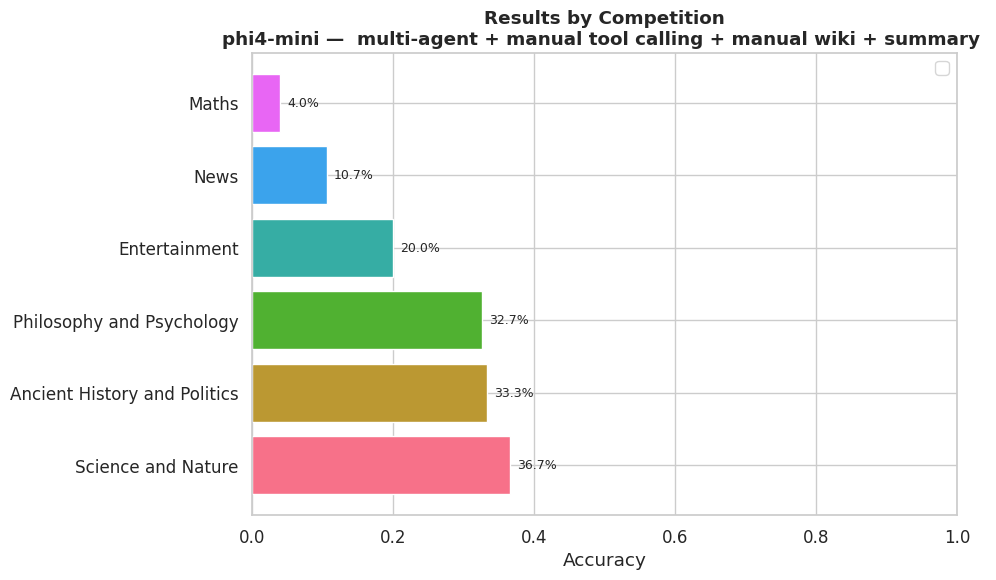

Plot displayed.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid", palette="husl", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 100, "savefig.bbox": "tight"})

def plot_accuracy_by_competition(runs_dir: Path):
    log_path = runs_dir / "runs_log.json"
    if not log_path.exists():
        print("No runs_log.json found at", log_path)
        return

    with open(log_path) as f:
        entries = json.load(f)

    if not entries:
        print("runs_log.json is empty.")
        return

    latest = entries[-1]
    comp_acc = latest.get("competition_accuracy", {})
    if not comp_acc:
        print("No competition_accuracy in latest run.")
        return

    comps = sorted(comp_acc.items(), key=lambda x: x[1], reverse=True)
    names, accs = zip(*comps)

    fig, ax = plt.subplots(figsize=(10, 6))
    pal = sns.color_palette("husl", len(names))
    bars = ax.barh(names, accs, color=pal, edgecolor='white')
    ax.set_xlim(0, 1)
    ax.set_xlabel('Accuracy')
    ax.set_title(f'Results by Competition\n{latest.get("model_name", "")} —  multi-agent + manual tool calling + manual wiki + summary ', fontweight='bold')
    for bar, v in zip(bars, accs):
        ax.text(bar.get_width() + .01, bar.get_y() + bar.get_height() / 2,
                f'{v:.1%}', va='center', fontsize=9)
    ax.legend()
    fig.tight_layout()
    plt.show()
    print("Plot displayed.")

plot_accuracy_by_competition(RUNS_DIR)

## Conclusions
The agent doesn't seem able to effectively extract summaries and to effectively run many tools.

The main issue was the time required to make the summary, which forced us to ask the models to make even shorter summaries degrading the performance. With a longer run of 10 games it was still able to archieve acceptable performance in many areas.

# RAG Benchmarking: Evaluating External Knowledge Bases

This test evaluates how different HuggingFace datasets perform as a knowledge base. Using game questions from our log data as user queries, we look at what context each dataset would retrieve and inject into an AI prompt.

Note: This is a retrieval-only test. **No LLM calls are made**.

## 1. Imports

In [ ]:
import json
import hashlib
import pickle
from pathlib import Path

import numpy as np
from sentence_transformers import SentenceTransformer
import hnswlib
from rank_bm25 import BM25Okapi
from datasets import load_dataset

RUNS_DIR = Path('./data/runs')
CACHE_DIR = Path('./data/index_cache')
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Use sklearn's built-in English stopwords — no hand-writing, no downloads
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS as STOPWORDS

def clean_tokens(text):
    tokens = text.lower().split()
    return [t for t in tokens if t not in STOPWORDS and len(t) > 1]

/home/lillaro/Documents/Programmazione/NLP/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load Game Questions (Queries) with Answer Info

In [ ]:
run_folders = sorted([d for d in RUNS_DIR.iterdir() if d.is_dir()])
latest_run = run_folders[-1]
comp_files = sorted(latest_run.glob('comp_*.json'))

all_q_records = []
for cf in comp_files:
    with open(cf) as f:
        comp = json.load(f)
    for attempt in comp['attempts']:
        for q in attempt['questions']:
            q['comp_name'] = comp['competition_name']
            all_q_records.append(q)

# Find correct answer for each question by looking across all attempts
# If ANY attempt got it right -> chosen_letter is the ground truth
known_answers = {}  # question_text -> correct_letter
for q in all_q_records:
    if q.get('correct') is True:
        known_answers.setdefault(q['question_text'].strip(), q['chosen_letter'])
    else:
        known_answers.setdefault(q['question_text'].strip(), None)

# Deduplicate but keep the first occurrence that has a known answer if possible
seen = set()
unique_questions = []
for q in all_q_records:
    key = q['question_text'].strip()
    if key not in seen:
        seen.add(key)
        q['known_correct_letter'] = known_answers.get(key)
        unique_questions.append(q)

print(f'Loaded {len(unique_questions)} unique questions')
n_known = sum(1 for q in unique_questions if q['known_correct_letter'] is not None)
print(f'  Correct answer known: {n_known}')
print(f'  Correct answer unknown: {len(unique_questions) - n_known}')

# Pick one test query per competition (prefer one with known answer)
queries = {}
for q in unique_questions:
    comp = q['comp_name']
    if comp not in queries:
        queries[comp] = q
    # replace with a known-answer version if found later
    if queries[comp]['known_correct_letter'] is None and q['known_correct_letter'] is not None:
        queries[comp] = q

Loaded 158 unique questions
  Correct answer known: 119
  Correct answer unknown: 39


## 3. Show the Test Queries

In [ ]:
for comp, q in queries.items():
    opts = q['options']
    print(f'\nQuery [{comp}]: {q["question_text"]}')
    for letter in ['A', 'B', 'C', 'D']:
        if letter in opts:
            marker = ' ★ CORRECT' if q['known_correct_letter'] == letter else ''
            print(f'    {letter}: {opts[letter]}{marker}')
    if q['known_correct_letter'] is None:
        print(f'    (correct answer unknown from log data)')


Query [Entertainment]: What is the primary goal of the LazyTown series?
    A: To encourage healthy lifestyles ★ CORRECT
    B: To tell stories about space exploration
    C: To promote a new brand of sports equipment
    D: To teach children about science

Query [Ancient History and Politics]: What was the primary reason the construction of the Temple of Olympian Zeus was left unfinished for over 330 years?
    A: Political instability and changes in leadership ★ CORRECT
    B: The temple was damaged by a natural disaster
    C: A lack of funding
    D: A decision to use the site for another purpose

Query [Science and Nature]: What is an energy change that takes place in a light bulb?
    A: Electrical energy changes to light energy. ★ CORRECT
    B: Chemical energy changes to light energy.
    C: Electrical energy changes to chemical energy.
    D: Chemical energy changes to heat energy.

Query [Maths]: What is the ones digit of $1 \cdot 2 \cdot 3 \cdot 4 \cdot 5 \cdot 6 \cdot 7 \c

## 4. Define Datasets to Test

In [ ]:
DATASETS = {
    # 'squad': {
    #     'path': 'squad',
    #     'split': 'train',
    #     'text_field': 'context',
    #     'desc': 'SQuAD: Wikipedia passages (full corpus)',
    #     'dedupe': True,
    # },
    # 'rag-datasets/rag-mini-wikipedia': {
    #     'path': 'rag-datasets/rag-mini-wikipedia',
    #     'subset': 'text-corpus',
    #     'split': 'passages',
    #     'text_field': 'passage',
    #     'desc': 'WikiQA: Wikipedia-derived short answers (full corpus)',
    # },
    'aadityaubhat/GPT-wiki-intro': {
        'path': 'aadityaubhat/GPT-wiki-intro',
        'split': 'train',
        'text_field': 'wiki_intro',
        'desc': 'Dataset used for GPT training for text generation',
    },
    # 'cais/mmlu (quiz-questions)': {
    #     'path': 'cais/mmlu',
    #     'split': 'auxiliary_train',
    #     'text_field': 'question',
    #     'desc': 'MMLU: 57-subject multiple-choice questions — closest to our quiz format',
    #     'subset': 'all',
    #     'dedupe' : True
    # },
}

## 5. Build Corpus from a Dataset

In [ ]:
def load_corpus(dataset_name, cfg):
    print(f'\nLoading {dataset_name}...')
    split = cfg['split']
    subset = cfg.get('subset')
    dedupe = cfg.get('dedupe', False)

    ds = load_dataset(cfg['path'], subset, split=split)

    texts = ds[cfg['text_field']]

    if dedupe:
        seen = set()
        texts = [t for t in texts if not (t in seen or seen.add(t))]

    texts = [t for t in texts if t and len(t) > 10]
    print(f'  {len(texts)} documents loaded')
    return texts


def _cache_key(dataset_name, cfg):
    raw = f'{dataset_name}|{cfg["path"]}|{cfg["split"]}|{cfg.get("subset","")}|{cfg["text_field"]}|{cfg.get("dedupe",False)}'
    return hashlib.sha256(raw.encode()).hexdigest()[:16]


def build_indexes(corpus_docs):
    print('  Encoding with sentence-transformer...')
    bi_enc = SentenceTransformer('multi-qa-MiniLM-L6-cos-v1')
    doc_embeddings = bi_enc.encode(
        corpus_docs, convert_to_numpy=True,
        show_progress_bar=False, normalize_embeddings=True,
    )

    dim = doc_embeddings.shape[1]
    index_hnsw = hnswlib.Index(space='cosine', dim=dim)
    index_hnsw.init_index(max_elements=len(corpus_docs), ef_construction=200, M=32)
    index_hnsw.add_items(doc_embeddings, list(range(len(corpus_docs))))
    print(f'  Dense index built (dim={dim})')

    print('  Building BM25...')
    tokenized = [clean_tokens(d) for d in corpus_docs]
    bm25 = BM25Okapi(tokenized)
    print('  BM25 index built')

    return bi_enc, index_hnsw, bm25, doc_embeddings


def load_or_build_indexes(dataset_name, cfg, corpus_docs):
    key = _cache_key(dataset_name, cfg)
    emb_path = CACHE_DIR / f'{key}_emb.npy'
    hnsw_path = CACHE_DIR / f'{key}_hnsw.bin'
    bm25_path = CACHE_DIR / f'{key}_bm25.pkl'

    if emb_path.exists() and hnsw_path.exists() and bm25_path.exists():
        print('  Loading cached indexes...')
        bi_enc = SentenceTransformer('multi-qa-MiniLM-L6-cos-v1')
        doc_embeddings = np.load(emb_path)
        index_hnsw = hnswlib.Index(space='cosine', dim=doc_embeddings.shape[1])
        index_hnsw.load_index(str(hnsw_path))
        with open(bm25_path, 'rb') as f:
            bm25 = pickle.load(f)
        print(f'  Loaded dense ({doc_embeddings.shape[1]}d, {len(corpus_docs)} docs) + BM25')
        return bi_enc, index_hnsw, bm25

    bi_enc, index_hnsw, bm25, doc_embeddings = build_indexes(corpus_docs)

    print('  Saving indexes to cache...')
    np.save(emb_path, doc_embeddings)
    index_hnsw.save_index(str(hnsw_path))
    with open(bm25_path, 'wb') as f:
        pickle.dump(bm25, f)
    print(f'  Cached to {key}_*.npy/.bin/.pkl')
    return bi_enc, index_hnsw, bm25


def search_dense(query, bi_enc, index_hnsw, corpus_docs, top_k=3):
    q_emb = bi_enc.encode([query], convert_to_numpy=True, normalize_embeddings=True)
    # hnswlib returns cosine DISTANCE (0=identical, 2=opposite)
    # convert to similarity: sim = 1 - dist
    inds, distances = index_hnsw.knn_query(q_emb, k=min(top_k, len(corpus_docs)))
    return [
        {'doc': corpus_docs[int(i)], 'score': 1.0 - float(d)}
        for i, d in zip(inds[0], distances[0])
    ]


def search_sparse(query, bm25, corpus_docs, top_k=3):
    scores = bm25.get_scores(clean_tokens(query))
    top = np.argsort(scores)[::-1][:min(top_k, len(corpus_docs))]
    return [
        {'doc': corpus_docs[int(i)], 'score': float(scores[i])}
        for i in top
    ]


def search_hybrid(query, bi_enc, index_hnsw, bm25, corpus_docs, top_k=3):
    """Reciprocal Rank Fusion of dense + sparse."""
    dense = search_dense(query, bi_enc, index_hnsw, corpus_docs, top_k=top_k * 3)
    sparse = search_sparse(query, bm25, corpus_docs, top_k=top_k * 3)

    rrf_scores = {}
    for rank, r in enumerate(dense):
        rrf_scores[r['doc']] = rrf_scores.get(r['doc'], 0) + 1.0 / (60 + rank + 1)
    for rank, r in enumerate(sparse):
        rrf_scores[r['doc']] = rrf_scores.get(r['doc'], 0) + 1.0 / (60 + rank + 1)

    sorted_docs = sorted(rrf_scores, key=rrf_scores.get, reverse=True)[:top_k]
    return [
        {'doc': d, 'score': rrf_scores[d]}
        for d in sorted_docs
    ]

## 6. Run Retrieval — Every Dataset × Every Query

In [ ]:
for ds_name, cfg in DATASETS.items():
    print(f'\n{"#"*70}')
    print(f'## DATASET: {ds_name}')
    print(f'## {cfg["desc"]}')
    print(f'{"#"*70}')

    corpus_docs = load_corpus(ds_name, cfg)
    if len(corpus_docs) < 5:
        print('  SKIP — too few docs')
        continue

    bi_enc, index_hnsw, bm25 = load_or_build_indexes(ds_name, cfg, corpus_docs)

    for comp_name, q_obj in queries.items():
        query = q_obj['question_text']
        opts = q_obj['options']
        print(f'\n  ─── Query [{comp_name}] ───')
        print(f'  Q: {query}')
        for letter in ['A', 'B', 'C', 'D']:
            if letter in opts:
                marker = ' [✓]' if q_obj['known_correct_letter'] == letter else ''
                print(f'     {letter}: {opts[letter]}{marker}')

        for method, search_fn in [
            ('DENSE', lambda q: search_dense(q, bi_enc, index_hnsw, corpus_docs)),
            ('BM25',  lambda q: search_sparse(q, bm25, corpus_docs)),
            ('HYBRID', lambda q: search_hybrid(q, bi_enc, index_hnsw, bm25, corpus_docs)),
        ]:
            print(f'\n{"="*80}')
            print(f'  METHOD: {method}')
            print(f'{"="*80}')

            all_results = []  # accumulate across all sub-queries

            sub_queries = [('QUESTION_ONLY', query)]

            for step_label, step_query in sub_queries:
                print(f'\n{"─"*70}')
                print(f'  SUB-QUERY: {step_label}')
                print(f'  Query text: {step_query}')
                print(f'{"─"*70}')

                results = search_fn(step_query)
                print(f'  Retrieved {len(results)} documents:')
                for i, r in enumerate(results, 1):
                    preview = r['doc'][:200].replace('\n', ' | ')
                    print(f'    #{i} (score={r["score"]:.4f}) {preview}...')

                all_results.extend(results)

            # --- Deduplicate by document text (keep first occurrence) ---
            seen_docs = set()
            deduped = []
            for r in all_results:
                if r['doc'] not in seen_docs:
                    seen_docs.add(r['doc'])
                    deduped.append(r)
            n_dupes = len(all_results) - len(deduped)
            if n_dupes:
                print(f'\n  >>> Removed {n_dupes} duplicate documents')

            # --- Build final combined context ---
            docs_context = '\n\n---\n\n'.join(r['doc'] for r in deduped)
            print(f'\n{"*"*70}')
            print(f'  >>> FINAL COMBINED CONTEXT for [{method}] ({len(deduped)} unique docs, ~{len(docs_context)} chars)')
            print(f'{"*"*70}')
            print(f'  >>> Full context:')
            print(docs_context)
            print(f'  >>> END CONTEXT [{method}]')
            print(f'{"*"*70}')


######################################################################
## DATASET: aadityaubhat/GPT-wiki-intro
## Dataset used for GPT training for text generation
######################################################################

Loading aadityaubhat/GPT-wiki-intro...


Generating train split: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████| 150000/150000 [00:06<00:00, 22932.21 examples/s]


  150000 documents loaded
  Encoding with sentence-transformer...


Loading weights: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 103/103 [00:00<00:00, 9388.94it/s]


  Dense index built (dim=384)
  Building BM25...
  BM25 index built
  Saving indexes to cache...
  Cached to 0b9b85eef906381a_*.npy/.bin/.pkl

  ─── Query [Entertainment] ───
  Q: What is the primary goal of the LazyTown series?
     A: To encourage healthy lifestyles [✓]
     B: To tell stories about space exploration
     C: To promote a new brand of sports equipment
     D: To teach children about science

  METHOD: DENSE

──────────────────────────────────────────────────────────────────────
  SUB-QUERY: QUESTION_ONLY
  Query text: What is the primary goal of the LazyTown series?
──────────────────────────────────────────────────────────────────────
  Retrieved 3 documents:
    #1 (score=0.3752) Fastpoint Games was a developer of data-driven games for businesses in the fortune 500, and was the parent company of fantasy sports developer, RotoHog. Under the Fastpoint Games banner, the company h...
    #2 (score=0.3315) Young Social Innovators (YSI) is a "social awareness and active c

## 7. Summary

In [ ]:
print('\n\n')
print('=' * 70)
print('SUMMARY')
print('=' * 70)
for comp_name, q_obj in queries.items():
    opts = q_obj['options']
    correct = q_obj['known_correct_letter']
    if correct:
        print(f'\n{comp_name}: "{q_obj["question_text"][:60]}..."')
        print(f'  Correct answer: {correct} → {opts[correct]}')
    else:
        print(f'\n{comp_name}: "{q_obj["question_text"][:60]}..."')
        print(f'  Correct answer: unknown')
        for letter in ['A', 'B', 'C', 'D']:
            print(f'    {letter}: {opts[letter]}')
    # note which dataset had best match
    print(f'  (See above for per-dataset retrieved context)')

print('\nNo LLM calls — retrieval only.')




SUMMARY

Entertainment: "What is the primary goal of the LazyTown series?..."
  Correct answer: A → To encourage healthy lifestyles
  (See above for per-dataset retrieved context)

Ancient History and Politics: "What was the primary reason the construction of the Temple o..."
  Correct answer: A → Political instability and changes in leadership
  (See above for per-dataset retrieved context)

Science and Nature: "What is an energy change that takes place in a light bulb?..."
  Correct answer: A → Electrical energy changes to light energy.
  (See above for per-dataset retrieved context)

Maths: "What is the ones digit of $1 \cdot 2 \cdot 3 \cdot 4 \cdot 5..."
  Correct answer: A → 0
  (See above for per-dataset retrieved context)

No LLM calls — retrieval only.


# Audio model + ACSR

We clear up the audio with some REGEX and then we pass it to our best general model

In [ ]:
import os
import sys
import json
import time
import re
import math
import tempfile
import subprocess
import warnings
from datetime import datetime
from pathlib import Path
from collections import defaultdict
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from transformers import pipeline
from huggingface_hub import utils

#settings for the plot
sns.set_theme(style="whitegrid", palette="husl", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 100, "savefig.bbox": "tight"})
LETTERS = ['A', 'B', 'C', 'D']

## **Infrastructure**


In this section we manage the connection with the game using api, we start the client and we define the utility functions that we will use to play the game or collect all the info (play_game_with_model, json creation and save...).

So we will create the logging function to collect all the info from each model run and save it in JSON format (in /runs folder)
We will also define all the plotting function we will use at the end of each experiment in order to extract relevant results.

### Connection

We define all the usefult variables and then connect to the game via API

In [ ]:

IN_COLAB = False
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    pass

if IN_COLAB:
    print("🌍 Detected environment: COLAB")
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = Path('/content/drive/MyDrive/NLP/')
else:
    print("💻 Detected environment: LOCAL")
    BASE_DIR = Path('.')

OUTPUT_DIR = BASE_DIR
RUNS_DIR   = OUTPUT_DIR / 'runs'
PLOTS_DIR  = OUTPUT_DIR / 'plots'
RUNS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Runs directory: {RUNS_DIR}")
print(f"Plots directory: {PLOTS_DIR}")

🌍 Detected environment: COLAB
Mounted at /content/drive
Runs directory: /content/drive/MyDrive/NLP/runs
Plots directory: /content/drive/MyDrive/NLP/plots


In [ ]:
if IN_COLAB:
    !pip install -q colab-xterm
    !pip install -q \
        langchain langchain-community langchain-ollama langgraph \
        wikipedia ddgs python-dotenv rank_bm25 openai-whisper
import whisper

from langchain_ollama import ChatOllama
from langchain_core.messages import HumanMessage, SystemMessage

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.6/115.6 kB 1.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 1.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.6/70.6 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 161.7/161.7 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 201.5/201.5 MB 5.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behavio

In [ ]:
#manage the connection
package_parent_dir = os.path.abspath('./')
current_dir = str(Path.cwd().resolve()) + "/drive/MyDrive/NLP/"
if current_dir not in sys.path:
    sys.path.insert(0, current_dir)

#import packages
from millionaire_client import MillionaireClient, AuthenticationError
import dotenv
dotenv.load_dotenv()

#credentials
username = 'YOUR_USERNAME'
pwd      = 'YOUR_PASSWORD'
mail     = os.getenv('MAIL')
API_URL  = "http://131.175.15.22:51111/"

client = MillionaireClient(API_URL)
try:
    user = client.login(username, pwd)
    print("Login successful :)")
    print(f"Welcome, {user.username} — role: {user.role}")
except AuthenticationError as e:
    print(f"Login failed: {e}")

print("\navailable competitions:")
competitions = client.competitions.list_all()
for comp in competitions:
    print(f"  {comp.id}: {comp.name} ({comp.max_levels} levels, {comp.question_count} questions)")
    print(f"           {comp.description}")

Login successful :)
Welcome, Dav — role: student

available competitions:
  0: Entertainment (15 levels, 840 questions)
           Music, Movies, Celebrities and more
  1: Ancient History and Politics (15 levels, 454 questions)
           The Roman Empire, The Greeks, and more
  2: Science and Nature (15 levels, 5347 questions)
           Chemistry, Biology, Physics and similar subjects
  3: Maths (15 levels, 390 questions)
           Mathematics and Statistics from High School and College
  4: Philosophy and Psychology (15 levels, 3248 questions)
           Great thinkers and the human psyche
  5: News (15 levels, 1860 questions)
           Staying current with global breaking news


### Model Loading
Here we will define the function to load the LLM model that will be used to make all experiments. we define a catalogue of all the models we are going to try and their path, so we can load the model by simply call their name

In [ ]:
MODEL_CATALOGUE = {
    #small models
    "Qwen2.5-3B":    "Qwen/Qwen2.5-3B-Instruct",
    "Phi3-mini":     "microsoft/Phi-3-mini-4k-instruct",
    "Phi4-mini":     "microsoft/Phi-4-mini-instruct",
    "DeepSeek-Small":"deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B",
    #medium models
    "Mistral-7B":    "mistralai/Mistral-7B-Instruct-v0.3",
    "Qwen2.5-7B":    "Qwen/Qwen2.5-7B-Instruct",
    "DeepSeek-medium":"deepseek-ai/DeepSeek-R1-Distill-Llama-8B",
    #bigger models
    "DeepSeek-big":  "deepseek-ai/DeepSeek-R1-Distill-Qwen-14B",
    "Mistral-12B":   "mistralai/Mistral-Nemo-Instruct-2407",
    "Qwen2.5-14B":   "Qwen/Qwen2.5-14B-Instruct",
    "Phi3-medium":   "microsoft/Phi-3-medium-4k-instruct",
}

#useful to log all the info
MODEL_SIZES = {
    "Qwen2.5-3B": "3B", "Phi3-mini": "3.8B", "Phi4-mini": "3.8B",
    "DeepSeek-Small": "1.5B", "Mistral-7B": "7B", "Qwen2.5-7B": "7B",
    "DeepSeek-medium": "8B", "DeepSeek-big": "14B", "Mistral-12B": "12B",
    "Qwen2.5-14B": "14B", "Phi3-medium": "14B",
}

In [ ]:
#it tooks the mododel name from tha catalogue and set a quantization True if needed
def load_model(model_name: str, device_map: str = "auto", quantization_4_bit: bool = False):
    hf_name    = MODEL_CATALOGUE.get(model_name)
    short_name = hf_name.split('/')[-1]
    hf_token   = os.getenv("HF_TOKEN")
    kwargs = dict(model=hf_name, device_map=device_map,torch_dtype=torch.float16, token=hf_token, trust_remote_code=False
    )

    if quantization_4_bit:
        from transformers import BitsAndBytesConfig
        kwargs['quantization_config'] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4",
            bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.bfloat16
        )
        kwargs.pop('torch_dtype', None)
        print("quantization")

    print(f"Loading {short_name} ...")
    llm = pipeline("text-generation", **kwargs)
    dev = next(llm.model.parameters()).device
    print(f"Loaded {short_name} on {dev}")
    return llm

### Prompt Building

Here we build all the different prompt we will give to the model in order to study its behaviour. We build both text prompt and different way we give it to the model (one-shot, few shot, chain of thoughts). We will build both system prompt (the rules) and user prompt (the specific task)

In [ ]:
#various system prompts
SYSTEM_PROMPTS = {
    "zero_shot":
        "You are a trivia expert. Answer with ONLY a single letter: A, B, C, or D.",
    "few_shot":
        "You are a trivia expert. Answer with ONLY a single letter: A, B, C, or D.",
    "chain_of_thought":
        "You are a trivia expert. Think step by step, then on the LAST LINE write "
        "only the answer letter: A, B, C, or D.",
    "role_playing":
        "You are a world-class professor and trivia champion. "
        "Answer with ONLY a single letter: A, B, C, or D.",
    "formal":
        "You are a highly educated academic assistant. "
        "Respond with only the letter of the correct answer: A, B, C, or D.",
    "casual":
        "Hey, you're a trivia genius! Just pick the right letter — A, B, C, or D.",
    "math":
        "You are a mathematics professor. Solve step by step, then on the LAST LINE "
        "write only the answer letter: A, B, C, or D.",
    "rag":
        "You are a trivia expert with access to reference material. "
        "Use the provided context and answer with ONLY a single letter: A, B, C, or D.",
}

#per category few shot examples
FEW_SHOT_BY_CATEGORY = {
    "math": [
        {"q": "What is 15% of 200?",
         "opts": ["A: 25", "B: 30", "C: 35", "D: 40"], "a": "B"},
        {"q": "If a train travels 120 km in 2 hours, what is its speed in km/h?",
         "opts": ["A: 40", "B: 50", "C: 60", "D: 70"], "a": "C"},
    ],
    "history": [
        {"q": "In which year did the French Revolution begin?",
         "opts": ["A: 1776", "B: 1789", "C: 1804", "D: 1815"], "a": "B"},
        {"q": "Who was the first Roman Emperor?",
         "opts": ["A: Julius Caesar", "B: Nero", "C: Augustus", "D: Caligula"], "a": "C"},
    ],
    "science": [
        {"q": "What is the atomic number of Carbon?",
         "opts": ["A: 4", "B: 6", "C: 8", "D: 12"], "a": "B"},
        {"q": "Which planet is closest to the Sun?",
         "opts": ["A: Venus", "B: Earth", "C: Mercury", "D: Mars"], "a": "C"},
    ],
    "default": [
        {"q": "What is the chemical symbol for Gold?",
         "opts": ["A: Ag", "B: Au", "C: Fe", "D: Pb"], "a": "B"},
        {"q": "In which year did World War II end?",
         "opts": ["A: 1943", "B: 1944", "C: 1945", "D: 1946"], "a": "C"},
    ],
}

def _get_few_shot_examples(category: str) -> list:
    cat_lower = category.lower() if category else ""
    for key in FEW_SHOT_BY_CATEGORY:
        if key != "default" and key in cat_lower:
            return FEW_SHOT_BY_CATEGORY[key]
    return FEW_SHOT_BY_CATEGORY["default"]

In [ ]:
#in this fuction we will build the prompt based on what we want to prove
def build_prompt(question: dict, opts: list, prompt_type: str = "zero_shot",
                 rag_context: str = None, tool_result: str = None,
                 level: int = 1) -> str:
    question_text = question.get('text')
    category      = question.get('category', '')

    #build a row for each answer with the correct letter (A,B,C;D)
    opts_str = "\n".join(f"{LETTERS[i]}: {o['text']}" for i, o in enumerate(opts[:4]))

    context_block = f"[Reference material]\n{rag_context}\n\n" if rag_context else ""
    tool_block    = f"[Calculator result]\n{tool_result}\n\n"  if tool_result else ""

    #include few shot examples
    few_shot_block = ""
    if prompt_type == "few_shot":
        examples = []
        for ex in _get_few_shot_examples(category):
            ex_opts = "\n".join(ex["opts"])
            examples.append(f"Question: {ex['q']}\nOptions:\n{ex_opts}\nAnswer: {ex['a']}")
        few_shot_block = "\n\n".join(examples) + "\n\nNow answer the following:\n"

    #include the prompt that instruct the moodel to think step by step before answering
    use_cot = prompt_type in ("chain_of_thought", "math") or (
        prompt_type == "adaptive_cot" and level >= 8
    )
    cot_hint = "\nThink step by step before answering." if use_cot else ""

    #the final user prompt
    return (
        f"{context_block}{tool_block}{few_shot_block}"
        f"Question: {question_text}\nOptions:\n{opts_str}"
        f"{cot_hint}\n"
        f"Answer with just the letter of the correct option (A, B, C, or D)."
    )

### Logging Module

Here we will define all the fuctions used to log in JSON each run of our model (a run is defined as a complete try of the model of each category). The created JSON will be saved in a /runs folder. We will define a META file with the usefult information in order to reconstruct the info of that run. init initialise always and define the meta value, log question saves all the question information about the run and then save run computes all the stats needed

In [ ]:
#before starting the run we will create a META file with all the usefult information like model used, quantization, rag...
def init_run_log(metadata: dict) -> dict:
    ts     = datetime.now().strftime("%Y%m%d_%H%M%S")
    #we define the id of the run
    run_id = (f"run_{ts}"f"_{metadata.get('experiment_type', 'unknown')}"f"_{metadata.get('model_name', 'unknown').split('/')[-1]}")
    meta = {**metadata, "run_id": run_id, "timestamp": datetime.now().isoformat()}

    #initialise all to zero
    return {
        "run_metadata":   meta,
        "session_stats": {
            "total_questions": 0, "correct": 0,
            "accuracy_on_played": 0.0, "accuracy_on_possible": 0.0,
            "mean_confidence": 0.0, "mean_response_time_sec": 0.0,
            "max_level_reached": 0,
        },
        "category_stats": {},
        "questions": [],
    }


def log_question(run_data, question_id, question, model_answer, correct_answer,is_correct, answer_probs, confidence, response_time_sec,rag_context=None, tool_result=None, rag_relevant=False):
    ##for each question we append it to dict with all the information needed.
    #Some info are included in the question obkect from the server while others are calculated by the generate_answer fucntion we use to play the game
    run_data["questions"].append({
        "question_id":      question_id,
        "level":            question.get("level", question_id),
        "category":         question.get("category", "unknown"),
        "question_text":    question.get("text", ""),
        "options":          question.get("options", {}),
        "correct_answer":   correct_answer,
        "model_answer":     model_answer,
        "is_correct":       is_correct,  #from server
        "answer_probs":     answer_probs,
        "confidence":       confidence,
        "response_time_sec":response_time_sec,
        "rag_context":      bool(rag_context),
        "rag_relevant":     rag_relevant,
        "tool_result":      tool_result,
    })


def save_run(run_data: dict, output_dir, max_q_per_game: int = 15) -> Path:
    #it computes the category stats of that run and then save it in a json file
    if isinstance(output_dir, str):
        output_dir = Path(output_dir)
    questions = run_data["questions"]
    n = len(questions)

    if n > 0:
        correct_n = sum(1 for q in questions if q["is_correct"])
        mean_time = sum(q["response_time_sec"] for q in questions) / n
        max_lvl   = max(q["level"] for q in questions)

        cat_map: dict = {}
        for q in questions:
            cat = q.get("category", "unknown")
            if cat not in cat_map:
                cat_map[cat] = {"total_answered": 0, "correct": 0,
                                "accuracy_on_played": 0.0, "accuracy_on_possible": 0.0}
            cat_map[cat]["total_answered"] += 1
            if q["is_correct"]:
                cat_map[cat]["correct"] += 1
        for s in cat_map.values():
            ta = s["total_answered"]
            s["accuracy_on_played"]   = s["correct"] / ta if ta else 0.0
            s["accuracy_on_possible"] = s["correct"] / max_q_per_game

        n_cats = len(cat_map)
        confs  = [q["confidence"] for q in questions if q.get("confidence") is not None]

        run_data["session_stats"].update({
            "total_questions":        n,
            "correct":                correct_n,
            "accuracy_on_played":     correct_n / n if n else 0.0,
            "accuracy_on_possible":   correct_n / (n_cats * max_q_per_game) if n_cats else 0.0,
            "mean_confidence":        sum(confs) / len(confs) if confs else 0.0,
            "mean_response_time_sec": mean_time,
            "max_level_reached":      max_lvl,
        })
        run_data["category_stats"] = cat_map

    runs_dir = output_dir / "runs"
    runs_dir.mkdir(parents=True, exist_ok=True)
    file_path = runs_dir / f"{run_data['run_metadata']['run_id']}.json"
    with open(file_path, 'w', encoding='utf-8') as f:
        json.dump(run_data, f, indent=2, ensure_ascii=False)
    print(f"✅ Run saved → {file_path}")
    return file_path

### Tools & RAG (Improved)
Here we define the tools we will need for our model and the rag strategy we will use, we can change them here if we want to add a specific tool or make rag by a different source

We extract the most informative nouns/named entities. This produces a much better Wikipedia search query.
before injecting context, we compute a simple word-overlap score. If the Wikipedia article is not sufficiently relevant, we discard it rather than injecting noise.
We log a flag if the rag was relevent or not

In [ ]:
##tool that recognizes and expression in the text and if it finds it, then it calculates
def try_calculator(question_text: str):
    pattern = r'[\d\.]+(?:\s*[\+\-\*/\^×÷]\s*[\d\.]+)+'
    m = re.search(pattern, question_text)
    if m:
        try:
            expr   = m.group().replace('×','*').replace('÷','/').replace('^','**').strip()
            result = eval(expr, {"__builtins__": {}, "math": math})
            return f"{m.group().strip()} = {result}"
        except Exception:
            pass
    return None


#rag from wikipedia
def _extract_query_terms(question_text: str) -> str:

    #remove specific characters
    text = re.sub(r'\b[A-D]:\s*\S+', '', question_text)
    words = text.split()

    #extract terms based on their priority
    caps = [w.strip('?.,:;') for w in words
            if w and w[0].isupper() and len(w) > 2 and w not in
            ('What', 'Which', 'Who', 'When', 'Where', 'How', 'The', 'A', 'An',
             'In', 'Of', 'Is', 'Was', 'Are', 'Were', 'Did', 'Does', 'Has', 'Have')]

    #numbers priority
    nums = [w.strip('?.,:;') for w in words if re.match(r'^\d{3,}', w)]

    #long content words priority
    long_words = [w.strip('?.,:;') for w in words
                  if len(w) > 5 and w.isalpha() and w.lower() not in
                  ('which', 'where', 'following', 'answer', 'correct', 'option')]

    #comabine all
    query_parts = caps[:3] + nums[:2] + long_words[:3]
    query = ' '.join(dict.fromkeys(query_parts))
    return query if query.strip() else ' '.join(words[:6])


def _relevance_score(context: str, question_text: str) -> float:
    """
     relevance score between retrieved context and question
    """
    if not context or not question_text:
        return 0.0
    q_words = set(re.findall(r'\b\w{4,}\b', question_text.lower()))
    c_words = set(re.findall(r'\b\w{4,}\b', context.lower()))
    if not q_words:
        return 0.0
    return len(q_words & c_words) / len(q_words)


def fetch_wikipedia_context(question_text: str, max_chars: int = 700, min_relevance: float = 0.15):
    #it retunrns the context and if it's relevant
    try:
        import wikipedia
        wikipedia.set_lang("en")

        query   = _extract_query_terms(question_text)
        results = wikipedia.search(query, results=4)
        if not results:
            return None, False

        for title in results:
            try:
                summary = wikipedia.summary(title, sentences=5)[:max_chars]
            except wikipedia.exceptions.DisambiguationError as e:
                try:
                    summary = wikipedia.summary(e.options[0], sentences=4)[:max_chars]
                except Exception:
                    continue
            except Exception:
                continue

            #check relevance
            score = _relevance_score(summary, question_text)
            if score >= min_relevance:
                return summary, True
        return None, False
    except Exception:
        return None, False


#per category configuration
CATEGORY_STRATEGY = {
    "Maths":       {"prompt": "math","rag": False, "tool": True,  "cot": True},
    "Ancient History and Politics":    {"prompt": "casual", "rag": False,  "tool": False, "cot": False},
    "Science and Nature":    {"prompt": "formal",           "rag": False,  "tool": False, "cot": False},
    "Philosophy and Psychology":    {"prompt": "chain-of-thought",           "rag": False,  "tool": False, "cot": False},
    "News": {"prompt": "few-shot",           "rag": True,  "tool": False, "cot": False},
    "Entertainment": {"prompt": "role_playing",           "rag": True,  "tool": False, "cot": False},
    #defualt
    "default":    {"prompt": None,            "rag": False, "tool": False, "cot": False},
}

def _match_category_strategy(category: str) -> dict:
    cat_lower = (category or "").lower()
    for key, cfg in CATEGORY_STRATEGY.items():
        if key != "default" and key.lower() == cat_lower: # Changed this line for correct case-insensitive matching
            return cfg
    return CATEGORY_STRATEGY["default"]


def strategy_router(category: str, question_text: str, opts: list,llm_pipeline, enable_thinking: bool,base_prompt_type: str = "zero_shot",enable_rag: bool = False, enable_tools: bool = False,use_category_routing: bool = False,level: int = 1):

    eff_prompt  = base_prompt_type
    rag_ctx     = None
    rag_relevant = False
    tool_res    = None

    if use_category_routing:
        #strategy based on category
        cfg = _match_category_strategy(category)
        if cfg["prompt"] is not None:
            eff_prompt = cfg["prompt"]
        if cfg["tool"] and enable_tools:
            tool_res = try_calculator(question_text)
        if cfg["rag"] and enable_rag:
            rag_ctx, rag_relevant = fetch_wikipedia_context(question_text)
            if rag_ctx:
                eff_prompt = "rag"
        return eff_prompt, rag_ctx, tool_res, rag_relevant

    #original behaviour
    is_math = any(k in (category or "").lower() for k in ("math", "statistic"))

    if is_math:
        eff_prompt = "math"
        if enable_tools:
            tool_res = try_calculator(question_text)
    else:
        if enable_thinking or (base_prompt_type == "adaptive_cot" and level >= 8):
            eff_prompt = "chain_of_thought"
        if enable_rag:
            rag_ctx, rag_relevant = fetch_wikipedia_context(question_text)
            if rag_ctx:
                eff_prompt = "rag"

    return eff_prompt, rag_ctx, tool_res, rag_relevant

### Audio System
Speech-to-text transcription pipeline for audio mode questions.

In [ ]:
warnings.filterwarnings("ignore", category=DeprecationWarning)

print("Loading Whisper model...")
whisper_model = whisper.load_model("base", in_memory=True)
print("Whisper model loaded")

def _make_ollama_model(model_name: str, temperature: float = 0.0) -> ChatOllama:
    return ChatOllama(model=model_name, temperature=temperature, num_predict=200)

CLEARER_MODEL_NAME = "qwen3.5:0.8b"
print(f"Loading clearer model {CLEARER_MODEL_NAME}...")
clearer_model = _make_ollama_model(CLEARER_MODEL_NAME)
print("Clearer model loaded")

CLEARER_SYSTEM_PROMPT = """Clean ASR transcription errors from quiz question input below.

Input format:
[QUESTION] <raw question text>
[OPTION A] <raw option A>
[OPTION B] <raw option B>
[OPTION C] <raw option C>
[OPTION D] <raw option D>

Fix broken words, add punctuation. Output cleaned question and each option on its own line starting with "Option X:".

Example 1:
[QUESTION] What is the square root of one hundred forty four
[OPTION A] Option A:twenty
[OPTION B] Option B: twenty one
[OPTION C] Option c: fifteen
[OPTION D] Topsyndee! twenty seven
Output:
this is the cleared text:
What is the square root of 144?
Option A: 20
Option B: 21
Option C: 15
Option D: 27

Example 2:
[QUESTION] Who painted the Sistine Chapel
[OPTION A] Option A Raphael
[OPTION B] Op shin B Michelangelo
[OPTION C] Option C Da Vinci
[OPTION D] Botticelli
Output:
this is the cleared text:
Who painted the Sistine Chapel?
Option A: Raphael
Option B: Michelangelo
Option C: Da Vinci
Option D: Botticelli

Example 3:
[QUESTION] Which planet is known as the Red Planet
[OPTION A] Option A Mars
[OPTION B] Option B Venus
[OPTION C] Ob shion C Jupiter
[OPTION D] Topshindi D Saturn
Output:
this is the cleared text:
Which planet is known as the Red Planet?
Option A: Mars
Option B: Venus
Option C: Jupiter
Option D: Saturn

Now process the input below."""


def _clear_text(raw_text: str) -> str:
    messages = [
        SystemMessage(content=CLEARER_SYSTEM_PROMPT),
        HumanMessage(content=raw_text),
    ]
    result = clearer_model.invoke(messages)
    content = result.content.strip()
    marker = "this is the cleared text:"
    idx = content.lower().find(marker)
    if idx != -1:
        cleared = content[idx + len(marker):].strip()
        return cleared
    return content if content else raw_text


def _parse_cleared(cleared: str):
    options_text = {}
    parts = re.split(r'\nOption ([A-D])[:.]\s*', cleared)
    if len(parts) >= 2:
        question_text = parts[0].strip()
        for j in range(1, len(parts), 2):
            if j + 1 < len(parts):
                letter = parts[j].upper()
                text = parts[j + 1].strip().rstrip('.')
                options_text[letter] = text
        if len(options_text) == 4:
            return question_text, options_text
    lines = cleared.split('\n')
    question_text = ""
    for line in lines:
        m = re.match(r'\[OPTION\s+([A-D])\]\s*(.*)', line)
        if m:
            letter = m.group(1).upper()
            text = m.group(2).strip().rstrip('.')
            options_text[letter] = text
        elif not options_text:
            clean = re.sub(r'^\[QUESTION\]\s*', '', line).strip()
            if clean:
                question_text = (question_text + " " + clean).strip()
    if len(options_text) < 4:
        for line in lines:
            m = re.match(r'(?:Option\s+)?([A-D])[,.]?\s+(.*)', line)
            if m:
                letter = m.group(1).upper()
                text = m.group(2).strip().rstrip('.')
                if letter not in options_text:
                    options_text[letter] = text
            elif letter := next((c for c in ["A","B","C","D"] if line.startswith(c+",") or line.startswith(c+".")), None):
                text = line[1:].strip().lstrip(",.").strip().rstrip('.')
                options_text[letter] = text
    question_text = re.sub(r'((ha|oh|ah|eh)\s+){2,}', '', question_text, flags=re.IGNORECASE)
    question_text = re.sub(r'\b(?:ha){2,}\.?', '', question_text, flags=re.IGNORECASE)
    question_text = re.sub(r'\b(?:he){2,}\.?', '', question_text, flags=re.IGNORECASE)
    question_text = re.sub(r'\b(?:heh\s+){2,}', '', question_text, flags=re.IGNORECASE)
    question_text = re.sub(r'\byeah\b!?', '', question_text, flags=re.IGNORECASE)
    question_text = re.sub(r'\b(\w)(?:-\1)+\b', '', question_text, flags=re.IGNORECASE)
    for letter in list(options_text.keys()):
        options_text[letter] = _fix_option_label(options_text[letter], letter)
    return question_text, options_text


def _fix_option_label(text: str, letter: str) -> str:
    text = re.sub(r'\b(?:ha|oh|ah|eh|uh|um)\b[\s,]*', '', text, flags=re.IGNORECASE)
    text = re.sub(r'((ha|oh|ah)\s+){3,}', '', text, flags=re.IGNORECASE)
    text = re.sub(r'(?:ha){2,}\.?', '', text, flags=re.IGNORECASE)
    text = re.sub(r'(?:he){2,}\.?', '', text, flags=re.IGNORECASE)
    text = re.sub(r'\b(?:heh\s+){2,}', '', text, flags=re.IGNORECASE)
    text = re.sub(r'\byeah\b!?', '', text, flags=re.IGNORECASE)
    text = re.sub(r'\b(\w)(?:-\1)+\b', '', text, flags=re.IGNORECASE)
    text = re.sub(
        r'^(?:'
        r'Tops(?:y|hi)nd[i1]?e?|Topshun?di?|Topshin|Tops?y\s+and|Top\'?s?\s+in|'
        r'Op\s*shin|Ob\s*sh(?:i|o)n|O[bp]\w*\s+sh\w+|'
        r'Thing\s*shion|Theshtion|Opzione|Popsin|'
        r'O[pb]tion|O[uv]shun'
        r')\s*!?\s*([A-D])[:.,!]?\s*',
        rf'Option {letter}: ',
        text.strip(),
        flags=re.IGNORECASE,
    )
    text = re.sub(
        r'^(?:Tops(?:y|hi)nd[i1]?e?|Topshun?di?|Topshin|Theshtion)\s*[,!.:;]?\s*',
        rf'Option {letter}: ',
        text.strip(),
        flags=re.IGNORECASE,
    )
    text = re.sub(r'^[!,\s]+', '', text)
    return text.strip()


def transcribe_audio(audio_bytes: bytes) -> str:
    with tempfile.NamedTemporaryFile(suffix=".wav", delete=False) as f:
        f.write(audio_bytes)
        tmp_path = f.name
    try:
        audio = whisper.load_audio(tmp_path)
        audio = whisper.pad_or_trim(audio)
        mel = whisper.log_mel_spectrogram(audio).to(whisper_model.device)
        options = whisper.DecodingOptions(fp16=False)
        result = whisper.decode(whisper_model, mel, options)
        return result.text.strip()
    finally:
        os.unlink(tmp_path)


def play_audio(audio_bytes: bytes):
    with tempfile.NamedTemporaryFile(suffix=".wav", delete=False) as f:
        f.write(audio_bytes)
        tmp_path = f.name
    try:
        subprocess.run(["paplay", tmp_path], check=True)
    finally:
        os.unlink(tmp_path)

Loading Whisper model...


100%|████████████████████████████████████████| 139M/139M [00:00<00:00, 146MiB/s]


Whisper model loaded
Loading clearer model qwen3.5:0.8b...
Clearer model loaded


### Play the game
In this section i will define alla the function that will be used to play the game. We will define a function generate_answer that builds the prompt and gives it to the model in order to extract the answer and alla the useful stats, then a function play_game that iterates on all categories and play them all; this is where we log all questions and then save the json with all the stats

In [ ]:
_letter_id_cache: dict = {}
def _get_letter_token_ids(tokenizer) -> dict:
    #the id of the letter depends on the tokenizer i use
    ids = {}
    for letter in LETTERS:
        for variant in (f" {letter}", letter, f"▁{letter}"):
            enc = tokenizer.encode(variant, add_special_tokens=False)
            if enc:
                ids[letter] = enc[-1]
                break
    return ids

In [ ]:
def generate_answer(question: dict, opts: list, llm_pipeline,prompt_type: str = "zero_shot", enable_thinking: bool = False,rag_context: str = None,tool_result: str = None):
    """
     it generate the answer and probability distribution over the 4 possibilities
    it returns the answer_id (option to submit to server), the chosen_letter,
    the inference_time in seconds, the confidence (probability to choose the answer)
    and the answer_probabilities {'A':p, 'B':p, 'C':p,'D': p}
    """
    tok= llm_pipeline.tokenizer
    sys_prompt= SYSTEM_PROMPTS.get(prompt_type, SYSTEM_PROMPTS["zero_shot"])
    usr_prompt= build_prompt(question, opts, prompt_type, rag_context, tool_result,level=question.get("level", 1) )

    messages = [
        {"role": "system", "content": sys_prompt},
        {"role": "user",   "content": usr_prompt},
    ]

    #create the prompt text
    try:
        prompt_text = tok.apply_chat_template(
            messages, tokenize=False, add_generation_prompt=True)
    except Exception:
        prompt_text = f"{sys_prompt}\n{usr_prompt}\nAnswer:"

    start = time.time()
    #tokenize the prompt to make it llm ready
    enc   = tok(prompt_text, return_tensors="pt")
    enc   = {k: v.to(llm_pipeline.model.device) for k, v in enc.items()}


    with torch.no_grad():
        out    = llm_pipeline.model(**enc)
        logits = out.logits[0, -1, :]
    inference_time = time.time() - start

    #save in the cahe the id of that tokenizer so i don't
    #calculate them every time, then builds a vector with the logits
    #and applies softmax to calculate probabilities
    tok_id = id(tok)
    if tok_id not in _letter_id_cache:
        _letter_id_cache[tok_id] = _get_letter_token_ids(tok)
    lid = _letter_id_cache[tok_id]
    letter_logits = torch.tensor(
        [logits[lid[l]].item() for l in LETTERS], dtype=torch.float32)
    probs_t      = torch.softmax(letter_logits, dim=0)
    answer_probs = {l: probs_t[i].item() for i, l in enumerate(LETTERS)}
    best_idx     = torch.argmax(probs_t).item()
    chosen_letter = LETTERS[best_idx]
    confidence    = probs_t[best_idx].item()
    answer_id     = opts[best_idx]['id']

    print(f"  [{prompt_type}] "
          f"A={answer_probs['A']:.2f} B={answer_probs['B']:.2f} "
          f"C={answer_probs['C']:.2f} D={answer_probs['D']:.2f} "
          f"choosen:[{chosen_letter}] conf={confidence:.1%}  ({inference_time:.1f}s)")

    return answer_id, chosen_letter, inference_time, confidence, answer_probs

In [ ]:
#function to play all competitions in sequence and log everything
def play_game(client, model, run_metadata: dict, output_dir: Path, enable_rag: bool = False, enable_tools: bool = False, use_category_routing: bool = False) -> dict:
    """
    enable_rag fetch wikipedia context before each answering
    it then returns the completed run_log dict.
    """
    comps       = client.competitions.list_all()
    run_log     = init_run_log(run_metadata)
    prompt_type = run_metadata.get("prompt_type")
    enable_think = run_metadata.get("enable_thinking")

    for comp in comps:
        category = comp.name
        print(f"{'─'*55}")
        print(f"  {category}  (id={comp.id})")
        print(f"{'─'*55}")
        game    = client.game.start(competition_id=comp.id)
        q_count = 0

        while game.in_progress:
            question = game.current_question
            if question is None:
                break
#list all the question options
            list_opts = [{"id": opt.id, "text": opt.text} for opt in question.options]
            q_dict    = {
                "text":        question.text,
                "level":       game.current_level,
                "category":    category,
                "competition": comp.name,
                "options":     {LETTERS[i]: opt.text for i, opt in enumerate(question.options[:4])},
            }

            #choose the strategy
            eff_prompt, rag_ctx, tool_res, rag_rel = strategy_router(category, question.text, list_opts, model,enable_thinking=enable_think,base_prompt_type=prompt_type,enable_rag=enable_rag,enable_tools=enable_tools,use_category_routing=use_category_routing,level=game.current_level)

            #generate the answer
            answer_id, chosen_letter, exec_time, conf, probs = generate_answer(q_dict, list_opts, model,prompt_type=eff_prompt,enable_thinking=enable_think,rag_context=rag_ctx,tool_result=tool_res)
            result  = game.answer(answer_id)
            q_count += 1

            log_question(
                run_data=run_log, question_id=q_count, question=q_dict,
                model_answer=chosen_letter, correct_answer="UNKNOWN",
                is_correct=result.correct,
                answer_probs=probs, confidence=conf,
                response_time_sec=exec_time,
                rag_context=rag_ctx, tool_result=tool_res, rag_relevant=rag_rel,
            )

            print(f"Q{q_count:2d} |[{chosen_letter}] " +
                  "+\n |"f"conf={conf:.1%} |{exec_time:.1f}s")
            if result.correct ==True:
                print("correct answer")
            else:
                print("wrong")

        print(f"ended at level {game.current_level}")
    save_run(run_log, output_dir)
    return run_log

In [ ]:
def play_game_audio(client, llm_pipeline, run_metadata: dict, output_dir: Path,
                     enable_rag: bool = False, enable_tools: bool = False,
                     use_category_routing: bool = False, use_llm_clearer = False) -> dict:
    """Play full game in speech mode: transcribe audio, clear ASR, answer with LLM."""
    comps = client.competitions.list_all()
    run_log = init_run_log(run_metadata)

    for comp in comps:
        category = comp.name
        print(f"{'─'*55}")
        print(f"  {category}  [AUDIO MODE]")
        print(f"{'─'*55}")

        session = client.game.start(comp.id, mode="speech")
        q_count = 0

        while session.in_progress:
            question = session.current_question
            if question is None:
                break

            # Fetch & transcribe question audio
            print("  Fetching question audio...")
            question_audio = session.fetch_audio_question()
            question_text_raw = transcribe_audio(question_audio)

            # Fetch & transcribe each option audio
            options_text_raw = {}
            for i in range(4):
                letter = chr(65 + i)
                print(f"  Fetching option {letter} audio...")
                opt_audio = session.fetch_audio_option_next()
                opt_text_raw = transcribe_audio(opt_audio)
                options_text_raw[letter] = opt_text_raw

            combined_raw = f"[QUESTION] {question_text_raw}\n"
            for letter in ["A", "B", "C", "D"]:
                combined_raw += f"[OPTION {letter}] {options_text_raw[letter]}\n"

            if use_llm_clearer:
                cleared = _clear_text(combined_raw)
            else:
                cleared = combined_raw
            question_text, options_text = _parse_cleared(cleared)

            label = "cleared" if use_llm_clearer else "raw+regex"
            print(f"  Q ({label}): {question_text}")
            for letter in ["A", "B", "C", "D"]:
                print(f"  {letter} ({label}): {options_text.get(letter, '?')}")

            # Build list_opts with transcribed text + original server IDs
            list_opts = []
            for i, opt in enumerate(question.options):
                letter = LETTERS[i]
                transcribed_text = options_text.get(letter, opt.text)
                list_opts.append({"id": opt.id, "text": transcribed_text})

            q_dict = {
                "text":        question_text,
                "level":       session.current_level,
                "category":    category,
                "competition": comp.name,
                "options":     options_text,
            }

            # Use same strategy routing as experiment 6
            base_prompt = run_metadata.get("prompt_type", "zero_shot")
            enable_think = run_metadata.get("enable_thinking", False)
            eff_prompt, rag_ctx, tool_res, rag_rel = strategy_router(
                category, question_text, list_opts, llm_pipeline,
                enable_thinking=enable_think,
                base_prompt_type=base_prompt,
                enable_rag=enable_rag,
                enable_tools=enable_tools,
                use_category_routing=use_category_routing,
                level=session.current_level,
            )

            # Generate answer using the LLM pipeline
            answer_id, chosen_letter, exec_time, conf, probs = generate_answer(
                q_dict, list_opts, llm_pipeline,
                prompt_type=eff_prompt,
                enable_thinking=enable_think,
                rag_context=rag_ctx,
                tool_result=tool_res,
            )
            result = session.answer(answer_id)
            q_count += 1

            log_question(
                run_data=run_log, question_id=q_count, question=q_dict,
                model_answer=chosen_letter, correct_answer="UNKNOWN",
                is_correct=result.correct,
                answer_probs=probs, confidence=conf,
                response_time_sec=exec_time,
                rag_context=rag_ctx, tool_result=tool_res, rag_relevant=rag_rel,
            )

            print(f"Q{q_count:2d} |[{chosen_letter}] conf={conf:.1%} |{exec_time:.1f}s")
            if result.correct:
                print("correct answer")
            else:
                print("wrong")

        print(f"ended at level {session.current_level}")

    save_run(run_log, output_dir)
    return run_log

### Data Loading
it load all the json in a dataframe we can use to plot all the useful data

In [ ]:
def load_runs(*args) -> pd.DataFrame:
    paths = []
    for arg in args:
        p = Path(arg)
        if p.is_dir():
            paths.extend(sorted(p.glob("run_*.json")))
        elif p.is_file() and p.suffix == ".json":
            paths.append(p)

    all_rows = []
    for path in paths:
        with open(path, encoding='utf-8') as f:
            j = json.load(f)
        meta = j.get("run_metadata", {})
        for q in j.get("questions", []):
            all_rows.append({**meta, **q})

    if not all_rows:
        print("⚠️  No run files found.")
        return pd.DataFrame()

    df = pd.DataFrame(all_rows)
    df = _compute_derived_fields(df)
    print(f"✅ DataFrame: {len(df)} rows from {len(paths)} run(s)")
    return df


def _compute_derived_fields(df: pd.DataFrame) -> pd.DataFrame:

    if df.empty:
        return df

    def _parse(x):
        if isinstance(x, dict): return x
        if isinstance(x, str):
            try: return json.loads(x.replace("'", '"'))
            except: return {}
        return {}

    if 'answer_probs' in df.columns:
        exp = df['answer_probs'].apply(_parse).apply(pd.Series)
        exp.columns = [f'prob_{c}' for c in exp.columns]
        df = pd.concat([df.reset_index(drop=True), exp.reset_index(drop=True)], axis=1)

        def _entropy(row):
            ps = [max(row.get(f'prob_{l}', 0), 1e-10) for l in LETTERS]
            return -sum(p * math.log2(p) for p in ps)
        df['uncertainty'] = df.apply(_entropy, axis=1)

    if 'confidence' in df.columns and 'is_correct' in df.columns:
        df['prob_correct'] = df.apply(
            lambda r: r['confidence'] if r['is_correct'] else float('nan'), axis=1)

    if 'model_size' in df.columns:
        df['model_size_b'] = (
            df['model_size'].astype(str)
            .str.extract('(\\d+\\.?\\d*)', expand=False)
            .astype(float)
        )
    if 'model_name' in df.columns:
        df['model_name'] = df['model_name'].str.split('/').str[-1]
    if 'is_correct' in df.columns:
        df['is_correct'] = df['is_correct'].fillna(False).astype(bool)

    return df

### Plotting Module
define all the plotting functions to extract usefult graphs that we can use to extract usefult information about our experiments

In [ ]:
PAL  = sns.color_palette("husl", 10)
STD  = (10, 6)
WIDE = (14, 6)
SQ   = (8, 8)

def _save(fig, name: str):
    path = PLOTS_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches='tight')
    print(f"📊 Saved → {path}")
    plt.show(); plt.close(fig)

def _ecdf(data):
    xs = np.sort(data)
    ys = np.arange(1, len(xs)+1) / len(xs)
    return xs, ys

MAX_QUESTIONS_PER_CATEGORY = 15 # Assuming 15 questions per category as per the game structure

def _calculate_run_accuracy_on_total(run_df: pd.DataFrame) -> float:
    """Calculates accuracy on total possible questions for a given run DataFrame."""
    num_categories = run_df['category'].nunique()
    total_correct = run_df['is_correct'].sum()
    total_possible = num_categories * MAX_QUESTIONS_PER_CATEGORY
    return total_correct / total_possible if total_possible > 0 else 0.0


def plot_accuracy_by_model(df: pd.DataFrame):
    # This plots accuracy on played questions, which is different from total possible.
    run_acc = df.groupby(['model_name','run_id'])['is_correct'].mean().reset_index()
    gb = (run_acc.groupby('model_name')['is_correct']
          .agg(['mean','std']).reset_index()
          .rename(columns={'model_name':'Model','mean':'Accuracy','std':'Std'})
          .sort_values('Accuracy', ascending=False))
    gb['Std'] = gb['Std'].fillna(0)
    fig, ax = plt.subplots(figsize=STD)
    bars = ax.barh(gb['Model'], gb['Accuracy'], xerr=gb['Std'], capsize=5,
                   color=PAL[:len(gb)], edgecolor='white')
    ax.set_xlim(0,1); ax.axvline(0.25, ls='--', color='gray', alpha=0.6, label='Random 25%')
    ax.set_title('Plot 1a — Accuracy by Model (on Played Questions)', fontweight='bold')
    ax.set_xlabel('Accuracy (mean ± std)')
    for bar, v in zip(bars, gb['Accuracy']):
        ax.text(bar.get_width()+.01, bar.get_y()+bar.get_height()/2,
                f'{v:.1%}', va='center', fontsize=9)
    ax.legend(); fig.tight_layout(); _save(fig, "01a_accuracy_by_model")

def plot_accuracy_by_model_total(df: pd.DataFrame):
    run_acc = (df.groupby(['model_name','run_id'])
               .apply(_calculate_run_accuracy_on_total).reset_index(name='is_correct'))
    gb = (run_acc.groupby('model_name')['is_correct']
          .agg(['mean','std']).reset_index()
          .rename(columns={'model_name':'Model','mean':'Accuracy','std':'Std'})
          .sort_values('Accuracy', ascending=False))
    gb['Std'] = gb['Std'].fillna(0)
    fig, ax = plt.subplots(figsize=STD)
    bars = ax.barh(gb['Model'], gb['Accuracy'], xerr=gb['Std'], capsize=5,
                   color=PAL[:len(gb)], edgecolor='white')
    ax.set_xlim(0,1); ax.axvline(0.25, ls='--', color='gray', alpha=0.6, label='Random 25%')
    ax.set_title('Plot 1b — Accuracy by Model (on Total Possible Questions)', fontweight='bold')
    ax.set_xlabel('Accuracy (mean ± std)')
    for bar, v in zip(bars, gb['Accuracy']):
        ax.text(bar.get_width()+.01, bar.get_y()+bar.get_height()/2,
                f'{v:.1%}', va='center', fontsize=9)
    ax.legend(); fig.tight_layout(); _save(fig, "01b_accuracy_by_model_total")

# ─── Plot 2: Accuracy by category ─────────────────────────────────────────
def plot_accuracy_by_category(df: pd.DataFrame):
    if 'category' not in df.columns:
        print("⚠️  No category column. Skipping accuracy by category plot."); return

    # Calculate accuracy on total possible questions for each category in each run
    run_cat = df.groupby(['model_name','category','run_id'])['is_correct'].sum().reset_index()
    run_cat['accuracy_on_total'] = run_cat['is_correct'] / 15

    gb = (run_cat.groupby(['model_name','category'])['accuracy_on_total']
          .agg(['mean','std']).reset_index()
          .rename(columns={'model_name':'Model','category':'Category','mean':'Accuracy','std':'Std'}))
    gb['Std'] = gb['Std'].fillna(0)
    fig, ax = plt.subplots(figsize=WIDE)
    pivot_m = gb.pivot(index='Category', columns='Model', values='Accuracy')
    pivot_s = gb.pivot(index='Category', columns='Model', values='Std')
    pivot_m.plot(kind='barh', ax=ax, xerr=pivot_s, capsize=3)
    ax.set_xlim(0,1); ax.axvline(0.25, ls='--', color='gray', alpha=0.5, label='Random')
    ax.set_title('📊 Plot 2 — Accuracy by Category (on Total Possible Questions)', fontweight='bold')
    ax.set_xlabel('Accuracy (mean ± std)'); ax.legend(bbox_to_anchor=(1.01,1), loc='upper left')
    fig.tight_layout(); _save(fig, "02_accuracy_by_category")

# ─── Plot 3: Heatmap model × prompt ──────────────────────────────────────
def plot_heatmap_model_prompt(df: pd.DataFrame):
    if 'prompt_type' not in df.columns or df['prompt_type'].nunique() < 2:
        print("⚠️  Need multiple prompt_types. Skipping plot 3."); return

    # Calculate accuracy on total possible questions for each group
    run_agg = df.groupby(['model_name', 'prompt_type', 'run_id'])['is_correct'].sum().reset_index()
    run_agg['accuracy_on_total'] = run_agg['is_correct'] / MAX_QUESTIONS_PER_CATEGORY

    pivot = run_agg.groupby(['model_name', 'prompt_type'])['accuracy_on_total'].mean().unstack()

    fig, ax = plt.subplots(figsize=SQ)
    sns.heatmap(pivot, annot=True, fmt='.1%', cmap='YlOrRd',
                vmin=0, vmax=1, ax=ax, linewidths=.5, cbar_kws={'label':'Accuracy'})
    ax.set_title('📊 Plot 3 — Accuracy: Model × Prompt Type (on Total Possible Questions)', fontweight='bold')
    fig.tight_layout(); _save(fig, "03_heatmap_model_prompt")

# ─── Plot 4: Accuracy by difficulty ──────────────────────────────────────
def plot_accuracy_by_difficulty(df: pd.DataFrame):
    if 'level' not in df.columns:
        print("⚠️  No level column. Skipping plot 4."); return

    # Calculate accuracy on total possible questions for each group (level, strategy, category)
    # This is more complex because total questions vary by category *at each level*. Need to group by category first.

    fig, axes = plt.subplots(1,2,figsize=WIDE)
    col = 'prompt_type' if 'prompt_type' in df.columns else 'experiment_type'

    # Accuracy vs Level by Strategy
    # Group by strategy (col), level, and run_id to calculate accuracy on total questions per category within each run
    strategy_level_run_agg = df.groupby([col, 'level', 'category', 'run_id'])['is_correct'].sum().reset_index()
    strategy_level_run_agg['accuracy_on_total'] = strategy_level_run_agg['is_correct'] / MAX_QUESTIONS_PER_CATEGORY
    # Then average across categories and runs
    strategy_level_acc = strategy_level_run_agg.groupby([col, 'level'])['accuracy_on_total'].mean().reset_index()

    for label, sub in strategy_level_acc.groupby(col):
        axes[0].plot(sub['level'], sub['accuracy_on_total'], marker='o', label=label)

    axes[0].axhline(0.25,ls='--',color='gray',alpha=0.5,label='Random')
    axes[0].set_ylim(-0.05,1.05); axes[0].legend(fontsize=8)
    axes[0].set_xlabel('Level'); axes[0].set_ylabel('Accuracy (on Total Possible Questions)')
    axes[0].set_title('Accuracy vs Level by Strategy')

    # Accuracy vs Level by Category
    # Already calculated accuracy_on_total for categories in plot_accuracy_by_category helper, can reuse similar logic
    category_level_run_agg = df.groupby(['category', 'level', 'run_id'])['is_correct'].sum().reset_index()
    category_level_run_agg['accuracy_on_total'] = category_level_run_agg['is_correct'] / MAX_QUESTIONS_PER_CATEGORY
    category_level_acc = category_level_run_agg.groupby(['category', 'level'])['accuracy_on_total'].mean().reset_index()

    for cat, sub in category_level_acc.groupby('category'):
        axes[1].plot(sub['level'], sub['accuracy_on_total'], marker='s', label=cat, alpha=0.8)

    axes[1].axhline(0.25,ls='--',color='gray',alpha=0.5)
    axes[1].set_ylim(-0.05,1.05); axes[1].legend(fontsize=8)
    axes[1].set_xlabel('Level'); axes[1].set_ylabel('Accuracy (on Total Possible Questions)')
    axes[1].set_title('Accuracy vs Level by Category')
    fig.suptitle('📊 Plot 4 — Accuracy by Difficulty Level (on Total Possible Questions)', fontweight='bold')
    fig.tight_layout(); _save(fig, "04_accuracy_by_difficulty")

# ─── Plot 5: Calibration + ECE ────────────────────────────────────────────
def plot_calibration(df: pd.DataFrame):
    """Reliability diagram with Expected Calibration Error (ECE) and Brier Score"""
    if 'confidence' not in df.columns:
        print("⚠️  No confidence column. Skipping plot 5."); return

    bins = np.linspace(0,1,11)
    bin_mids, acc_means, conf_means, ns = [], [], [], []
    for i in range(10):
        mask = (df['confidence'] >= bins[i]) & (df['confidence'] < bins[i+1])
        sub  = df[mask]
        if len(sub) < 2: continue
        bin_mids.append((bins[i]+bins[i+1])/2)
        # Accuracy here is intentionally on played questions to compare with confidence on played questions
        acc_means.append(sub['is_correct'].mean())
        conf_means.append(sub['confidence'].mean())
        ns.append(len(sub))

    # ECE: weighted mean absolute calibration error
    ece = sum(ns[i]/len(df) * abs(conf_means[i]-acc_means[i]) for i in range(len(ns)))

    # Brier Score: mean squared error of probability forecasts
    brier = ((df['confidence'] - df['is_correct'].astype(float))**2).mean()

    fig, axes = plt.subplots(1,2,figsize=WIDE)
    ax = axes[0]
    ax.plot([0,1],[0,1],'k--',lw=1.5,label='Perfect calibration')
    sc = ax.scatter(conf_means, acc_means, c=ns, cmap='viridis', s=120, zorder=4)
    ax.plot(conf_means, acc_means, 'b-', alpha=0.5)
    plt.colorbar(sc, ax=ax, label='# questions in bin')
    ax.fill_between([0,1],[0,1],[1,1], alpha=0.05, color='red', label='Overconfident zone')
    ax.fill_between([0,1],[0,0],[0,1], alpha=0.05, color='green', label='Underconfident zone')
    ax.set_xlabel('Mean Confidence'); ax.set_ylabel('Actual Accuracy')
    ax.set_xlim(0,1); ax.set_ylim(0,1)
    ax.set_title(f'Reliability Diagram\nECE={ece:.3f} | Brier Score={brier:.3f}', fontweight='bold')
    ax.legend(fontsize=8)
    ax2 = axes[1]
    for cat, sub in df.groupby('category'):
        cuts = pd.cut(sub['confidence'], bins=5, labels=False)
        # Accuracy here is intentionally on played questions
        cat_acc  = sub.groupby(cuts)['is_correct'].mean()
        cat_conf = sub.groupby(cuts)['confidence'].mean()
        ax2.plot(cat_conf.values, cat_acc.values, marker='o', label=cat, alpha=0.8)
    ax2.plot([0,1],[0,1],'k--',lw=1,alpha=0.5)
    ax2.set_xlabel('Mean Confidence'); ax2.set_ylabel('Accuracy')
    ax2.set_title('Calibration by Category'); ax2.legend(fontsize=8)
    fig.suptitle('📊 Plot 5 — Calibration (ECE + Brier Score)', fontweight='bold')
    fig.tight_layout(); _save(fig, "05_calibration")
    print(f"  ECE = {ece:.4f}  (0=perfect, <0.05 good, >0.1 poorly calibrated)")
    print(f"  Brier Score = {brier:.4f}  (0=perfect, 0.25=random)")

# ─── Plot 6: Confidence distribution ─────────────────────────────────────
def plot_confidence_distribution(df: pd.DataFrame):
    fig, axes = plt.subplots(1,2,figsize=WIDE)
    ax = axes[0]
    for is_c, lbl, clr in [(True,'Correct','#2ecc71'),(False,'Wrong','#e74c3c')]:
        sub = df[df['is_correct']==is_c]['confidence'].dropna()
        ax.hist(sub, bins=20, alpha=0.55, color=clr, density=True,
                label=f'{lbl} (n={len(sub)})', edgecolor='white')
    ax.set_xlabel('Confidence'); ax.set_ylabel('Density')
    ax.set_title('Confidence Distribution'); ax.legend()
    ax2 = axes[1]
    for is_c, lbl, clr in [(True,'Correct','#2ecc71'),(False,'Wrong','#e74c3c')]:
        sub = df[df['is_correct']==is_c]['confidence'].dropna().values
        if len(sub) > 0:
            xs, ys = _ecdf(sub)
            ax2.plot(xs, ys, color=clr, lw=2, label=lbl)
    ax2.set_xlabel('Confidence'); ax2.set_ylabel('Cumulative Probability')
    ax2.set_title('Confidence ECDF'); ax2.legend()
    fig.suptitle("📊 Plot 6 — Confidence: Knows vs Doesn't Know", fontweight='bold')
    fig.tight_layout(); _save(fig, "06_confidence_distribution")

# ─── Plot 7: Prob correct by category ────────────────────────────────────
def plot_prob_correct_by_category(df: pd.DataFrame):
    correct_df = df[df['is_correct']].copy()
    if correct_df.empty:
        print("⚠️  No correct answers in dataset. Skipping plot 7."); return
    cats   = sorted(df['category'].unique())
    data_c = [correct_df[correct_df['category']==c]['confidence'].dropna() for c in cats]
    data_w = [df[(df['category']==c)&(~df['is_correct'])]['confidence'].dropna() for c in cats]
    fig, ax = plt.subplots(figsize=STD)
    positions = np.arange(len(cats))
    bp = ax.boxplot(data_c, positions=positions, widths=0.5, patch_artist=True)
    for patch, clr in zip(bp['boxes'], PAL): patch.set_facecolor(clr); patch.set_alpha(0.7)
    for i, (cat, sub_w) in enumerate(zip(cats, data_w)):
        if len(sub_w) > 0:
            ax.scatter(i, sub_w.mean(), color='red', marker='x', s=120, zorder=5,
                       label='Wrong (mean conf)' if i==0 else "")
    ax.set_xticks(positions); ax.set_xticklabels(cats, rotation=20, ha='right')
    ax.set_ylabel('Confidence'); ax.set_ylim(0,1.05)
    ax.set_title('📊 Plot 7 — Confidence (Correct ✓ box / Wrong ✗ mean) by Category', fontweight='bold')
    ax.legend(); fig.tight_layout(); _save(fig, "07_prob_correct_by_category")

# ─── Plot 8: RAG comparison ───────────────────────────────────────────────
def plot_rag_comparison(df: pd.DataFrame):
    if 'rag_context' not in df.columns or df['rag_context'].nunique() < 2:
        print("⚠️  Need RAG and non-RAG runs. Skipping plot 8."); return

    # Calculate accuracy on total possible questions for RAG vs non-RAG by category
    run_rag_agg = df.groupby(['category','rag_context','run_id'])['is_correct'].sum().reset_index()
    run_rag_agg['accuracy_on_total'] = run_rag_agg['is_correct'] / MAX_QUESTIONS_PER_CATEGORY

    gb = (run_rag_agg.groupby(['category','rag_context'])['accuracy_on_total']
          .agg(['mean','std']).reset_index()
          .rename(columns={'category':'Category','rag_context':'RAG','mean':'Accuracy','std':'Std'}))
    gb['RAG'] = gb['RAG'].map({True:'With RAG', False:'Without RAG'})
    gb['Std'] = gb['Std'].fillna(0)

    fig, ax = plt.subplots(figsize=STD)
    pivot_m = gb.pivot(index='Category', columns='RAG', values='Accuracy')
    pivot_s = gb.pivot(index='Category', columns='RAG', values='Std')
    pivot_m.plot(kind='bar', ax=ax, yerr=pivot_s, capsize=3,
                 color=['#e74c3c','#2ecc71'], edgecolor='white')
    ax.set_ylim(0,1); ax.axhline(0.25, ls='--', color='gray', alpha=0.5, label='Random')
    ax.set_title('📊 Plot 8 — RAG vs No-RAG by Category (on Total Possible Questions)', fontweight='bold')
    ax.legend(); plt.xticks(rotation=25, ha='right')
    fig.tight_layout(); _save(fig, "08_rag_comparison")

# ─── Plot 8b: RAG relevance analysis ─────────────────────────────────────
def plot_rag_relevance(df: pd.DataFrame):
    """Break down RAG effect by whether context was actually relevant"""
    if 'rag_relevant' not in df.columns:
        print("⚠️  No rag_relevant column. Skipping plot 8b."); return
    rag_df = df[df['rag_context']==True].copy()
    if rag_df.empty:
        print("⚠️  No RAG rows. Skipping plot 8b."); return

    # Calculate accuracy on total possible questions for relevant vs irrelevant RAG
    run_rel_agg = rag_df.groupby(['category', 'rag_relevant', 'run_id'])['is_correct'].sum().reset_index()
    run_rel_agg['accuracy_on_total'] = run_rel_agg['is_correct'] / MAX_QUESTIONS_PER_CATEGORY

    gb = (run_rel_agg.groupby(['category','rag_relevant'])['accuracy_on_total']
          .agg(['mean','std']).reset_index())
    gb['rag_relevant'] = gb['rag_relevant'].map({True:'Relevant RAG', False:'Irrelevant RAG'})
    fig, ax = plt.subplots(figsize=STD)
    pivot = gb.pivot(index='category', columns='rag_relevant', values='mean') # Use 'mean' for accuracy
    pivot.plot(kind='bar', ax=ax, color=['#e74c3c','#2ecc71'], edgecolor='white')
    ax.set_ylim(0,1); ax.axhline(0.25,ls='--',color='gray',alpha=0.5,label='Random')
    ax.set_title('📊 Plot 8b — RAG Accuracy: Relevant vs Irrelevant Context (on Total Possible Questions)', fontweight='bold')
    ax.legend(); plt.xticks(rotation=25, ha='right')
    fig.tight_layout(); _save(fig, "08b_rag_relevance")

# ─── Plot 9: Accuracy vs Latency ─────────────────────────────────────────
def plot_accuracy_vs_latency(df: pd.DataFrame):
    run_agg = df.groupby(['model_name','run_id']).apply(_calculate_run_accuracy_on_total).reset_index(name='Accuracy')
    latency_agg = df.groupby(['model_name','run_id'])['response_time_sec'].mean().reset_index(name='Latency')

    combined_agg = pd.merge(run_agg, latency_agg, on=['model_name', 'run_id'])

    gb = (combined_agg.groupby('model_name').agg(
        Accuracy=('Accuracy','mean'), Acc_std=('Accuracy','std'),
        Latency=('Latency','mean'), Lat_std=('Latency','std'),
        Count=('Accuracy','count')).reset_index().fillna(0))

    fig, ax = plt.subplots(figsize=STD)
    ax.errorbar(gb['Latency'], gb['Accuracy'],
                xerr=gb['Lat_std'], yerr=gb['Acc_std'],
                fmt='none', ecolor='gray', alpha=0.5, capsize=3, zorder=1)
    ax.scatter(gb['Latency'], gb['Accuracy'],
               s=gb['Count']*80, c=range(len(gb)), cmap='tab10',
               alpha=0.85, edgecolors='black', lw=0.5, zorder=2)
    for _, row in gb.iterrows():
        ax.annotate(row['model_name'], (row['Latency'], row['Accuracy']),
                    textcoords="offset points", xytext=(6,4), fontsize=9)
    ax.axhline(0.25,ls='--',color='gray',alpha=0.5,label='Random')
    ax.axvline(30,ls='--',color='red',alpha=0.5,label='30s timeout')
    ax.set_xlabel('Mean Response Time (s)'); ax.set_ylabel('Accuracy (on Total Possible Questions)'); ax.set_ylim(0,1)
    ax.annotate('↖ Ideal', xy=(2,0.82), color='green', fontsize=11, alpha=0.7)
    ax.set_title('📊 Plot 9 — Accuracy vs Latency Tradeoff (on Total Possible Questions)', fontweight='bold')
    ax.legend(); fig.tight_layout(); _save(fig, "09_accuracy_vs_latency")

# ─── Plot 10: Accuracy by model size ─────────────────────────────────────
def plot_accuracy_by_model_size(df: pd.DataFrame):
    if 'model_size_b' not in df.columns:
        print("⚠️  No model_size_b. Skipping plot 10."); return

    run_s = df.groupby(['model_name','model_size_b','quantization','run_id']).apply(_calculate_run_accuracy_on_total).reset_index(name='Accuracy')

    gb = (run_s.groupby(['model_name','model_size_b','quantization'])['Accuracy']
          .agg(['mean','std']).reset_index()
          .rename(columns={'mean':'Accuracy','std':'Std'}).fillna(0))

    fig, ax = plt.subplots(figsize=STD)
    for i, (quant, sub) in enumerate(gb.groupby('quantization')):
        ax.errorbar(sub['model_size_b'], sub['Accuracy'], yerr=sub['Std'],
                    fmt='none', ecolor=PAL[i], alpha=0.5, capsize=3)
        ax.scatter(sub['model_size_b'], sub['Accuracy'],
                   s=180, label=f"quant={quant}", zorder=3, color=PAL[i])
        for _, row in sub.iterrows():
            ax.annotate(row['model_name'], (row['model_size_b'], row['Accuracy']),
                        textcoords="offset points", xytext=(4,5), fontsize=8)
    ax.axhline(0.25,ls='--',color='gray',alpha=0.5,label='Random')
    ax.set_xlabel('Model Size (B params)'); ax.set_ylabel('Accuracy (mean ± std, on Total Possible Questions)')
    ax.set_ylim(0,1); ax.set_title('📊 Plot 10 — Accuracy by Model Size (on Total Possible Questions)', fontweight='bold')
    ax.legend(title='Quantization'); fig.tight_layout(); _save(fig, "10_accuracy_by_model_size")

# ─── Plot 11: Letter bias ─────────────────────────────────────────────────
def plot_letter_confusion(df: pd.DataFrame):
    fig, axes = plt.subplots(1,2,figsize=WIDE)
    ax = axes[0]
    lc = df['model_answer'].value_counts().reindex(LETTERS, fill_value=0)
    colors = ['#e74c3c' if l==lc.idxmax() else '#95a5a6' for l in LETTERS]
    ax.bar(LETTERS, lc.values, color=colors, edgecolor='white')
    ax.axhline(len(df)/4, ls='--', color='navy', alpha=0.7, label='Expected (uniform)')
    ax.set_title('Letter Choice Distribution (all answers)')
    ax.set_xlabel('Chosen Letter'); ax.set_ylabel('Count'); ax.legend()
    ax2 = axes[1]
    for cat, sub in df.groupby('category'):
        freqs = sub['model_answer'].value_counts().reindex(LETTERS, fill_value=0)
        ax2.plot(LETTERS, freqs.values/freqs.sum(), marker='o', label=cat, alpha=0.8)
    ax2.axhline(0.25,ls='--',color='gray',alpha=0.5,label='Uniform 25%')
    ax2.set_title('Normalised Letter Frequency by Category')
    ax2.set_xlabel('Letter'); ax2.set_ylabel('Frequency'); ax2.legend(fontsize=8)
    fig.suptitle('📊 Plot 11 — Letter Choice Patterns (Systematic Bias?)', fontweight='bold')
    fig.tight_layout(); _save(fig, "11_letter_confusion")

# ─── Plot 12: Thinking vs Standard ───────────────────────────────────────
def plot_thinking_vs_standard(df: pd.DataFrame):
    if 'enable_thinking' not in df.columns or df['enable_thinking'].nunique() < 2:
        print("⚠️  Need thinking=True and False runs. Skipping plot 12."); return
    df2 = df.copy()
    df2['Mode'] = df2['enable_thinking'].map({True:'Thinking 🧠', False:'Standard ⚡'})

    run_agg_acc = df2.groupby(['model_name','Mode','run_id']).apply(_calculate_run_accuracy_on_total).reset_index(name='Accuracy')
    run_agg_lat = df2.groupby(['model_name','Mode','run_id'])['response_time_sec'].mean().reset_index(name='Latency')
    combined_agg = pd.merge(run_agg_acc, run_agg_lat, on=['model_name', 'Mode', 'run_id'])

    gb = (combined_agg.groupby(['model_name','Mode']).agg(
        Accuracy=('Accuracy','mean'), Acc_std=('Accuracy','std'),
        Latency=('Latency','mean'), Lat_std=('Latency','std'))
        .reset_index().fillna(0))

    fig, axes = plt.subplots(1,2,figsize=WIDE)
    for ax, metric, std_col, title, threshold in [
        (axes[0], 'Accuracy', 'Acc_std', 'Accuracy (on Total Possible Questions)', 0.25),
        (axes[1], 'Latency',  'Lat_std', 'Mean Response Time (s)', 30),
    ]:
        pivot_m = gb.pivot(index='model_name', columns='Mode', values=metric)
        pivot_s = gb.pivot(index='model_name', columns='Mode', values=std_col)
        pivot_m.plot(kind='bar', ax=ax, yerr=pivot_s, capsize=3,
                     color=['#e74c3c','#3498db'], edgecolor='white')
        ax.axhline(threshold, ls='--', color='gray', alpha=0.5)
        ax.set_title(title); ax.set_xlabel('')
        plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
    axes[1].axhline(30,ls='--',color='red',alpha=0.8,label='30s timeout')
    axes[1].legend()
    fig.suptitle('📊 Plot 12 — Thinking vs Standard Models', fontweight='bold')
    fig.tight_layout(); _save(fig, "12_thinking_vs_standard")

# ─── Plot 13: Uncertainty by difficulty ──────────────────────────────────
def plot_uncertainty_by_difficulty(df: pd.DataFrame):
    if 'uncertainty' not in df.columns or 'level' not in df.columns:
        print("⚠️  No uncertainty/level. Skipping plot 13."); return
    fig, axes = plt.subplots(1,2,figsize=WIDE)
    ax = axes[0]
    lvl_grp = df.groupby('level')['uncertainty']
    lvls    = sorted(df['level'].unique())
    means   = [lvl_grp.get_group(l).mean() for l in lvls]
    q25     = [lvl_grp.get_group(l).quantile(0.25) for l in lvls]
    q75     = [lvl_grp.get_group(l).quantile(0.75) for l in lvls]
    ax.plot(lvls, means, marker='o', color='#8e44ad', lw=2)
    ax.fill_between(lvls, q25, q75, alpha=0.2, color='#8e44ad', label='IQR 25–75')
    ax.set_xlabel('Level'); ax.set_ylabel('Entropy (bits)')
    ax.set_title('Uncertainty (Entropy) vs Level'); ax.legend()
    ax2 = axes[1]
    for is_c, lbl, clr in [(True,'Correct','#2ecc71'),(False,'Wrong','#e74c3c')]:
        sub = df[df['is_correct']==is_c]['uncertainty'].dropna()
        ax2.hist(sub, bins=15, alpha=0.55, color=clr, density=True,
                 label=f'{lbl} (n={len(sub)})', edgecolor='white')
    ax2.set_xlabel('Entropy (bits)'); ax2.set_ylabel('Density')
    ax2.set_title('Uncertainty: Correct vs Wrong'); ax2.legend()
    fig.suptitle('📊 Plot 13 — Uncertainty by Difficulty', fontweight='bold')
    fig.tight_layout(); _save(fig, "13_uncertainty_by_difficulty")

# ─── Plot 14: Response time ───────────────────────────────────────────────
def plot_response_time(df: pd.DataFrame):
    fig, axes = plt.subplots(1,2,figsize=WIDE)
    ax = axes[0]
    exp_grp = df.groupby('experiment_type')
    labels  = list(exp_grp.groups.keys())
    data    = [exp_grp.get_group(k)['response_time_sec'].values for k in labels]
    bp = ax.boxplot(data, labels=labels, patch_artist=True)
    for patch, clr in zip(bp['boxes'], PAL): patch.set_facecolor(clr); patch.set_alpha(.7)
    ax.axhline(30,ls='--',color='red',alpha=0.8,label='30s timeout')
    ax.set_ylabel('Response Time (s)'); ax.set_title('Time by Experiment Type')
    ax.legend(); plt.setp(ax.get_xticklabels(), rotation=20, ha='right')
    ax2 = axes[1]
    run_rt = df.groupby(['model_name','run_id'])['response_time_sec'].mean().reset_index()
    rt = (run_rt.groupby('model_name')['response_time_sec']
          .agg(['mean','std']).sort_values('mean').fillna(0))
    rt_p95 = df.groupby('model_name')['response_time_sec'].quantile(0.95)
    y_pos = range(len(rt))
    ax2.barh(y_pos, rt['mean'].values, xerr=rt['std'].values, capsize=3,
             color=PAL[:len(rt)], label='Mean')
    ax2.barh(y_pos, rt_p95.loc[rt.index].values, alpha=0.3, color='gray', label='P95')
    ax2.set_yticks(y_pos); ax2.set_yticklabels(rt.index)
    ax2.axvline(30,ls='--',color='red',alpha=0.8,label='Timeout')
    ax2.set_xlabel('Response Time (s)'); ax2.set_title('Mean & P95 by Model')
    ax2.legend()
    fig.suptitle('📊 Plot 14 — Response Time (Latency Budget)', fontweight='bold')
    fig.tight_layout(); _save(fig, "14_response_time")

# ─── Plot 15: Ensemble comparison ────────────────────────────────────────
def plot_ensemble_comparison(df: pd.DataFrame):
    """Compare ensemble vs individual model accuracy"""
    if 'experiment_type' not in df.columns:
        print("⚠️  No experiment_type. Skipping plot 15."); return
    ensemble_mask = df['experiment_type'].str.contains('ensemble', case=False, na=False)
    if ensemble_mask.sum() == 0:
        print("⚠️  No ensemble runs found. Skipping plot 15."); return

    df2 = df.copy()
    df2['Strategy'] = df2['experiment_type'].apply(
        lambda x: 'Ensemble' if 'ensemble' in str(x).lower() else 'Individual')

    run_agg = df2.groupby(['model_name','Strategy','run_id']).apply(_calculate_run_accuracy_on_total).reset_index(name='Accuracy')

    gb = (run_agg.groupby(['model_name','Strategy'])['Accuracy']
          .agg(['mean','std']).reset_index().rename(
              columns={'mean':'Accuracy','std':'Std'}).fillna(0))

    fig, ax = plt.subplots(figsize=STD)
    pivot_m = gb.pivot(index='model_name', columns='Strategy', values='Accuracy')
    pivot_s = gb.pivot(index='model_name', columns='Strategy', values='Std')
    pivot_m.plot(kind='bar', ax=ax, yerr=pivot_s, capsize=3,
                 color=['#3498db','#e67e22'], edgecolor='white')
    ax.set_ylim(0,1); ax.axhline(0.25,ls='--',color='gray',alpha=0.5,label='Random')
    ax.set_title('📊 Plot 15 — Ensemble vs Individual Models (on Total Possible Questions)', fontweight='bold')
    ax.set_xlabel(''); ax.legend()
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
    fig.tight_layout(); _save(fig, "15_ensemble_comparison")

# ─── Plot 16: Audio vs Text accuracy comparison ──────────────────────────
def plot_audio_vs_text_accuracy(df_text: pd.DataFrame, df_audio: pd.DataFrame):
    """Compare accuracy of audio-mode runs vs text-mode runs."""

    def _mode_accuracy(df, mode_label):
        if df.empty:
            return pd.DataFrame()
        run_acc = df.groupby(['model_name','run_id']).apply(
            _calculate_run_accuracy_on_total).reset_index(name='Accuracy')
        gb = run_acc.groupby('model_name')['Accuracy'].agg(['mean','std']).reset_index()
        gb['Mode'] = mode_label
        gb.columns = ['Model', 'Accuracy', 'Std', 'Mode']
        return gb

    text_gb = _mode_accuracy(df_text, 'Text')
    audio_gb = _mode_accuracy(df_audio, 'Audio')
    combined = pd.concat([text_gb, audio_gb], ignore_index=True).fillna(0)

    fig, ax = plt.subplots(figsize=STD)
    pivot_m = combined.pivot(index='Model', columns='Mode', values='Accuracy')
    pivot_s = combined.pivot(index='Model', columns='Mode', values='Std')
    pivot_m.plot(kind='bar', ax=ax, yerr=pivot_s, capsize=3,
                 color=['#3498db','#e67e22'], edgecolor='white')
    ax.set_ylim(0, 1)
    ax.axhline(0.25, ls='--', color='gray', alpha=0.5, label='Random 25%')
    ax.set_title('Plot 16a — Audio vs Text Accuracy (on Total Possible Questions)', fontweight='bold')
    ax.set_xlabel('')
    ax.legend()
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
    fig.tight_layout()
    _save(fig, "16a_audio_vs_text_accuracy")

    # Also show per-category comparison
    fig2, ax2 = plt.subplots(figsize=WIDE)

    def _cat_accuracy(df, mode_label):
        if df.empty:
            return pd.DataFrame()
        run_cat = df.groupby(['model_name','category','run_id'])['is_correct'].sum().reset_index()
        run_cat['accuracy'] = run_cat['is_correct'] / MAX_QUESTIONS_PER_CATEGORY
        gb = run_cat.groupby(['model_name','category'])['accuracy'].agg(['mean','std']).reset_index()
        gb['Mode'] = mode_label
        gb.columns = ['Model', 'Category', 'Accuracy', 'Std', 'Mode']
        return gb

    cat_combined = pd.concat([
        _cat_accuracy(df_text, 'Text'),
        _cat_accuracy(df_audio, 'Audio'),
    ], ignore_index=True).fillna(0)

    for mode, sub in cat_combined.groupby('Mode'):
        pivot = sub.pivot(index='Category', columns='Model', values='Accuracy')
        pivot_s = sub.pivot(index='Category', columns='Model', values='Std')
        color = '#e67e22' if mode == 'Audio' else '#3498db'
        pivot.plot(kind='barh', ax=ax2, xerr=pivot_s, capsize=2,
                   alpha=0.7, color=color, edgecolor='white',
                   position=0 if mode == 'Text' else 1, width=0.35)
    ax2.set_xlim(0, 1)
    ax2.axvline(0.25, ls='--', color='gray', alpha=0.5, label='Random')
    ax2.set_title('Plot 16b — Audio vs Text Accuracy by Category', fontweight='bold')
    ax2.set_xlabel('Accuracy (mean ± std)')
    ax2.legend()
    fig2.tight_layout()
    _save(fig2, "16b_audio_vs_text_by_category")


# ─── Master function ──────────────────────────────────────────────────────
def plot_all(*args):
    """Generate all plots at once — run this you should after each experiment"""
    df = load_runs(*args)
    if df.empty:
        print("No data. Run experiments first."); return
    print(f"\n🎨  Generating plots for {len(df)} records …")
    plot_accuracy_by_model(df);     plot_accuracy_by_model_total(df)
    plot_accuracy_by_category(df);  plot_heatmap_model_prompt(df)
    plot_accuracy_by_difficulty(df);plot_calibration(df)
    plot_confidence_distribution(df); plot_prob_correct_by_category(df)
    plot_rag_comparison(df);        plot_rag_relevance(df)
    plot_accuracy_vs_latency(df);   plot_accuracy_by_model_size(df)
    plot_letter_confusion(df);      plot_thinking_vs_standard(df)
    plot_uncertainty_by_difficulty(df); plot_response_time(df)
    plot_ensemble_comparison(df)
    print("✅  All plots generated!")

In [ ]:
BEST_MODEL_KEY  = "Phi3-mini"
BEST_MODEL_NAME = MODEL_CATALOGUE[BEST_MODEL_KEY]
BEST_PROMPT     = "chain-of-thought"
print(f"Best model selected: {BEST_MODEL_KEY} ({BEST_MODEL_NAME})")
print(f"Best prompt selected: {BEST_PROMPT}")
pipeline_best   = load_model(BEST_MODEL_KEY)

Best model selected: Phi3-mini (microsoft/Phi-3-mini-4k-instruct)
Best prompt selected: chain-of-thought
Loading Phi-3-mini-4k-instruct ...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/967 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/16.5k [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/1.94M [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/306 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/599 [00:00<?, ?B/s]

Loaded Phi-3-mini-4k-instruct on cuda:0


## Execution

### Adaptive Category Specific Routing

The best result that we have


In [ ]:
# Run the full adaptive routing strategy — best configuration, this is
meta_routing = {
    "experiment_type": "adaptive_routing",
    "model_name":      BEST_MODEL_NAME,
    "model_size":      MODEL_SIZES[BEST_MODEL_KEY],
    "quantization":    "none",
    "prompt_type":     BEST_PROMPT,
    "enable_thinking": False,
    "rag_used":        True,
    "tool_used":       True,
    "fine_tuned":      False,
    "notes":           "Category-specific routing: math→tool, factual→RAG, other→best_prompt",
}

N_RUNS_ROUTING = 5
for i in range(N_RUNS_ROUTING):
    print(f"\n--- Adaptive Routing Run {i+1}/{N_RUNS_ROUTING} ---")
    play_game(
        client=client,
        model=pipeline_best,
        run_metadata=meta_routing.copy(),
        output_dir=OUTPUT_DIR,
        enable_rag=True,
        enable_tools=True,
        use_category_routing=True,   # ← enables CATEGORY_STRATEGY map
    )


--- Adaptive Routing Run 1/5 ---
───────────────────────────────────────────────────────
  Entertainment  (id=0)
───────────────────────────────────────────────────────
  [role_playing] A=0.86 B=0.08 C=0.04 D=0.03 choosen:[A] conf=85.5%  (0.1s)
Q 1 |[A] +
 |conf=85.5% |0.1s
correct answer
  [role_playing] A=0.01 B=0.00 C=0.99 D=0.00 choosen:[C] conf=98.8%  (0.1s)
Q 2 |[C] +
 |conf=98.8% |0.1s
correct answer
  [role_playing] A=0.00 B=1.00 C=0.00 D=0.00 choosen:[B] conf=99.9%  (0.1s)
Q 3 |[B] +
 |conf=99.9% |0.1s
correct answer
  [role_playing] A=0.24 B=0.27 C=0.14 D=0.35 choosen:[D] conf=35.0%  (0.1s)
Q 4 |[D] +
 |conf=35.0% |0.1s
wrong
ended at level 4
───────────────────────────────────────────────────────
  Ancient History and Politics  (id=1)
───────────────────────────────────────────────────────
  [casual] A=0.09 B=0.02 C=0.00 D=0.88 choosen:[D] conf=88.2%  (0.1s)
Q 1 |[D] +
 |conf=88.2% |0.1s
correct answer
  [casual] A=0.30 B=0.30 C=0.15 D=0.24 choosen:[A] conf=30.5%  (0.1s)
Q 

✅ DataFrame: 487 rows from 15 run(s)


/tmp/ipykernel_19475/2520525152.py:85: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.tight_layout(); _save(fig, "02_accuracy_by_category")
/tmp/ipykernel_19475/2520525152.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.savefig(path, dpi=150, bbox_inches='tight')


📊 Saved → /content/drive/MyDrive/NLP/plots/02_accuracy_by_category.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


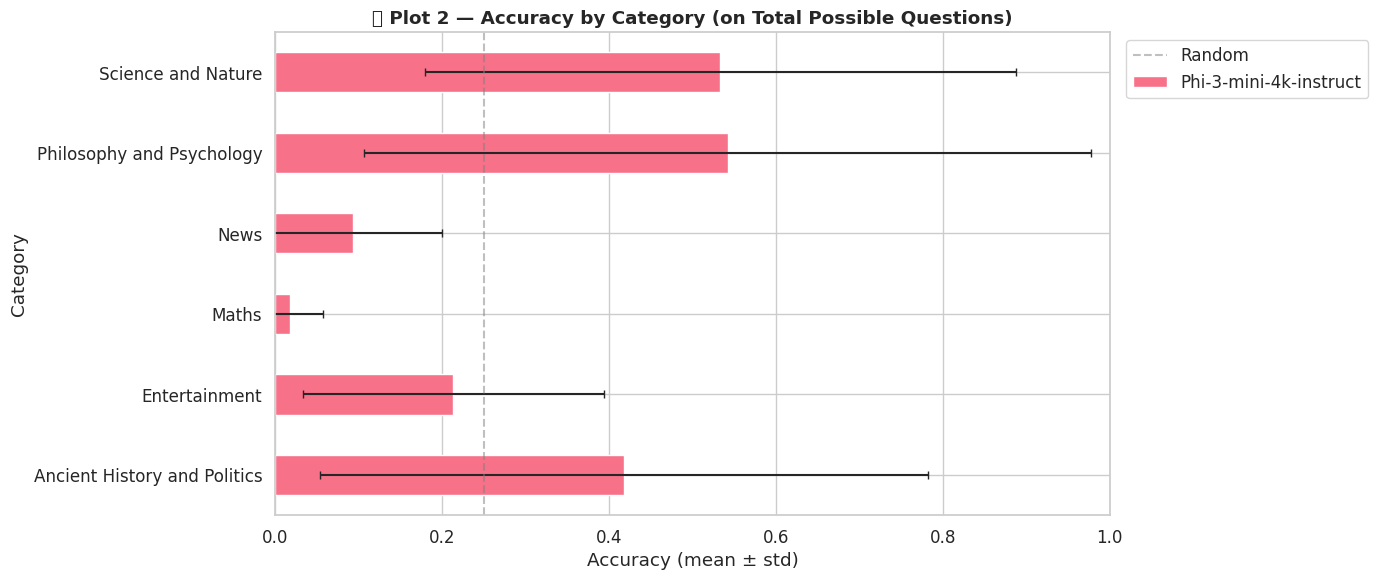

📊 Saved → /content/drive/MyDrive/NLP/plots/01b_accuracy_by_model_total.png


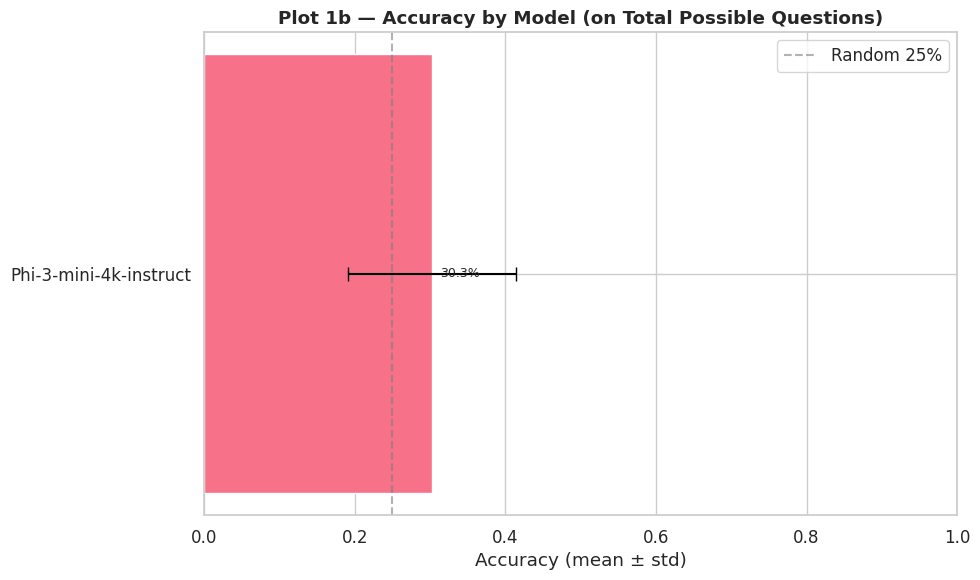

/tmp/ipykernel_19475/2520525152.py:446: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.tight_layout(); _save(fig, "14_response_time")
/tmp/ipykernel_19475/2520525152.py:8: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.savefig(path, dpi=150, bbox_inches='tight')


📊 Saved → /content/drive/MyDrive/NLP/plots/14_response_time.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


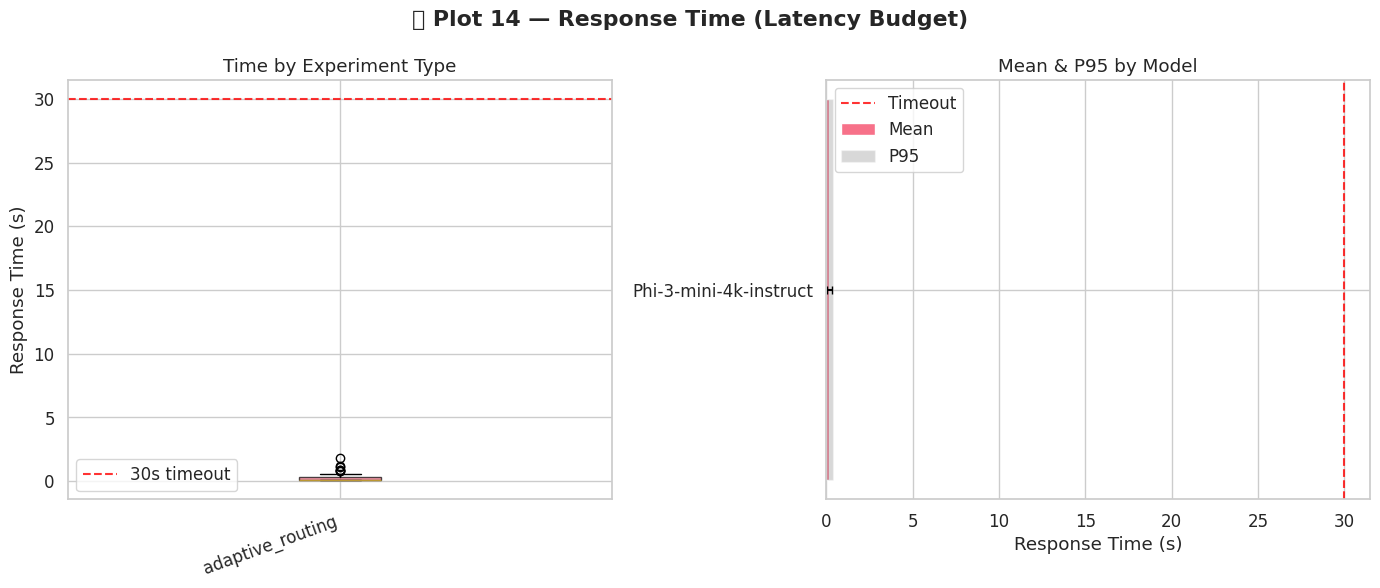

In [ ]:
df_adaptive= load_runs(*[p for p in RUNS_DIR.glob("run_*_adaptive_routing_*.json")])

plot_accuracy_by_category(df_adaptive)
plot_accuracy_by_model_total(df_adaptive)
plot_response_time(df_adaptive)

### Audio implementation with ACSR

In [ ]:
# Same model & prompt as experiment 6
AUDIO_N_RUNS = 5

for i in range(AUDIO_N_RUNS):
    print(f"\n{'='*60}")
    print(f"  Audio Run {i+1}/{AUDIO_N_RUNS}")
    print(f"{'='*60}")
    meta_audio = {
        "experiment_type": "audio_mode",
        "model_name":      BEST_MODEL_NAME,
        "model_size":      MODEL_SIZES[BEST_MODEL_KEY],
        "quantization":    "none",
        "prompt_type":     BEST_PROMPT,
        "enable_thinking": False,
        "rag_used":        True,
        "tool_used":       True,
        "fine_tuned":      False,
        "notes":           "Audio mode: Whisper transcription + ASR clearing via qwen3.5:0.8b",
    }
    play_game_audio(
        client=client,
        llm_pipeline=pipeline_best,
        run_metadata=meta_audio,
        output_dir=OUTPUT_DIR,
        enable_rag=True,
        enable_tools=True,
        use_category_routing=True,
    )


  Audio Run 1/5
───────────────────────────────────────────────────────
  Entertainment  [AUDIO MODE]
───────────────────────────────────────────────────────
  Fetching question audio...
  Fetching option A audio...
  Fetching option B audio...
  Fetching option C audio...
  Fetching option D audio...
  Q (raw+regex): What is the primary principle behind Denzel Washington's acting style?
  A (raw+regex): Option A: natural charm and emotional intensity
  B (raw+regex): Option B: If this is on physical stunts!
  C (raw+regex): Option C: focusing on comedy
  D (raw+regex): Option D: use of Special Effects
  [role_playing] A=0.99 B=0.01 C=0.00 D=0.00 choosen:[A] conf=98.8%  (0.1s)
Q 1 |[A] conf=98.8% |0.1s
correct answer
  Fetching question audio...
  Fetching option A audio...
  Fetching option B audio...
  Fetching option C audio...
  Fetching option D audio...
  Q (raw+regex): Which of the following best describes the relationship between Brian Jones and the other band members in the e

/usr/local/lib/python3.12/dist-packages/wikipedia/wikipedia.py:389: GuessedAtParserWarning: No parser was explicitly specified, so I'm using the best available HTML parser for this system ("lxml"). This usually isn't a problem, but if you run this code on another system, or in a different virtual environment, it may use a different parser and behave differently.

The code that caused this warning is on line 389 of the file /usr/local/lib/python3.12/dist-packages/wikipedia/wikipedia.py. To get rid of this warning, pass the additional argument 'features="lxml"' to the BeautifulSoup constructor.

  lis = BeautifulSoup(html).find_all('li')


  [role_playing] A=0.98 B=0.00 C=0.01 D=0.00 choosen:[A] conf=98.5%  (0.1s)
Q 5 |[A] conf=98.5% |0.1s
correct answer
  Fetching question audio...
  Fetching option A audio...
  Fetching option B audio...
  Fetching option C audio...
  Fetching option D audio...
  Q (raw+regex): Which of the following best describes the relationship between Mick Jagger and Keith Richard?
  A (raw+regex): Option A: they were brothers
  B (raw+regex): Option B: They were close friends and primary songwriting partners
  C (raw+regex): Option C: they had a long standing professional rivalry
  D (raw+regex): Option D: e! They were distant and rarely collaborated
  [role_playing] A=0.00 B=1.00 C=0.00 D=0.00 choosen:[B] conf=99.7%  (0.1s)
Q 6 |[B] conf=99.7% |0.1s
correct answer
  Fetching question audio...
  Fetching option A audio...
  Fetching option B audio...
  Fetching option C audio...
  Fetching option D audio...
  Q (raw+regex): What is the primary reason for the film Titanic success? According to Jam

✅ DataFrame: 168 rows from 10 run(s)
✅ DataFrame: 678 rows from 20 run(s)

📊 Audio runs: 168 questions, Text runs: 678 questions


/tmp/ipykernel_25198/2520525152.py:485: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  run_acc = df.groupby(['model_name','run_id']).apply(
/tmp/ipykernel_25198/2520525152.py:485: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  run_acc = df.groupby(['model_name','run_id']).apply(


📊 Saved → /content/drive/MyDrive/NLP/plots/16a_audio_vs_text_accuracy.png


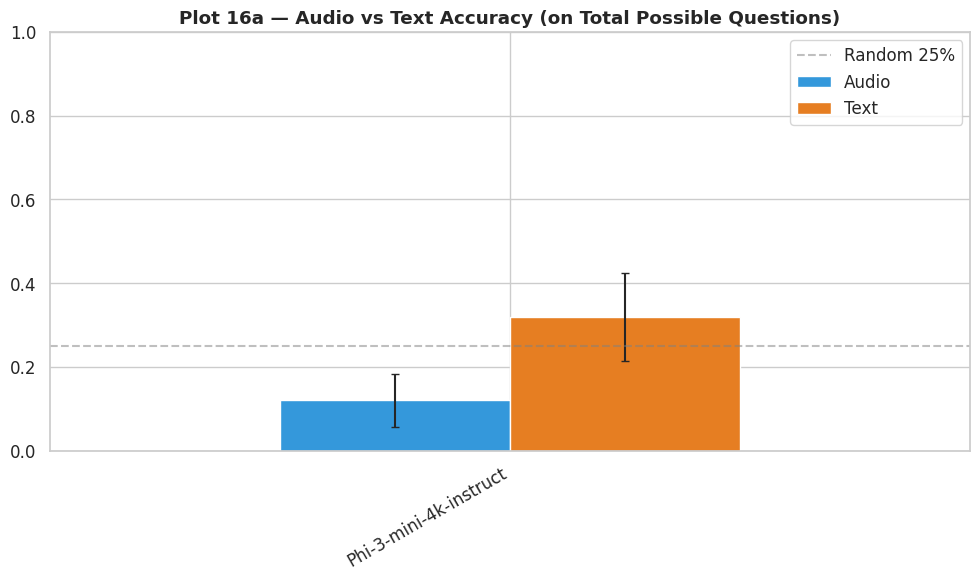

📊 Saved → /content/drive/MyDrive/NLP/plots/16b_audio_vs_text_by_category.png


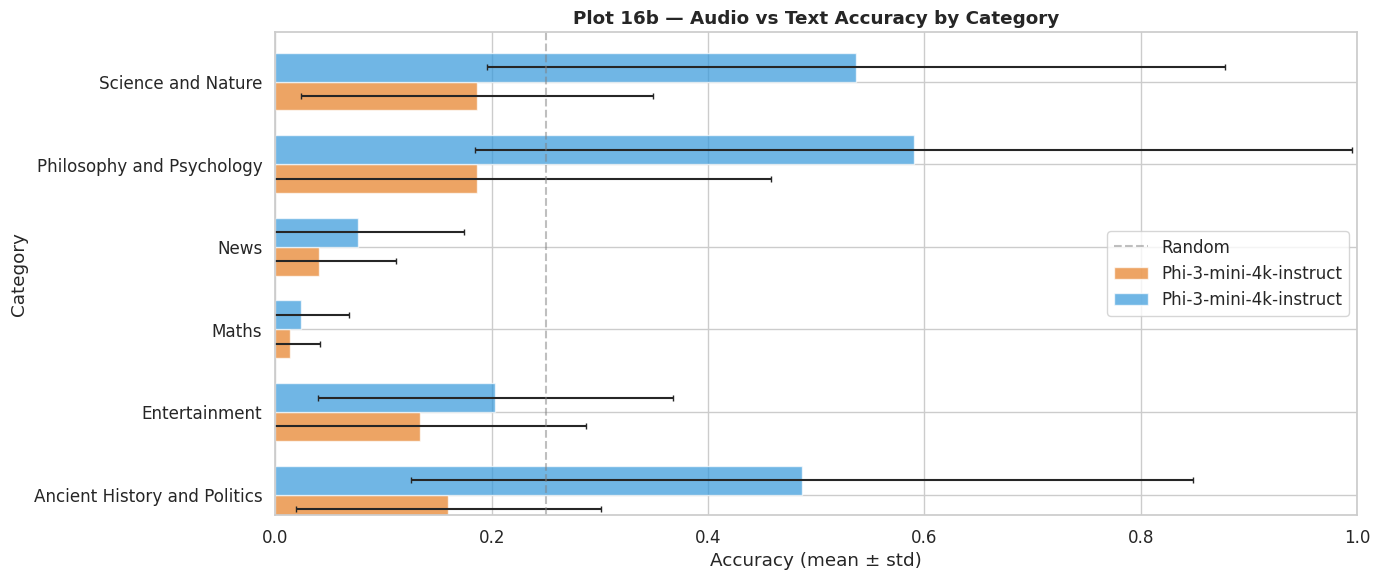

In [ ]:
df_audio_runs = load_runs(*[p for p in RUNS_DIR.glob("run_*_audio_mode_*.json")])
df_text_runs  = load_runs(*[p for p in RUNS_DIR.glob("run_*_adaptive_routing_*.json")])

if not df_audio_runs.empty and not df_text_runs.empty:
    print(f"\n📊 Audio runs: {len(df_audio_runs)} questions, Text runs: {len(df_text_runs)} questions")
    plot_audio_vs_text_accuracy(df_text_runs, df_audio_runs)
else:
    print("⚠️  Missing audio or text run data for comparison plots.")

## Conclusion
The audio comes with a lot of random words that destroy the total performance, using a model to clean it up proved to be a losing strategy, using a regex worked much better since most of the distorsions were repetitive and easy to find